<a href="https://colab.research.google.com/github/hagopjay/x3d.lab/blob/main/notebooks/unreal/07_Unreal_Fidelity.003_completesA100.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/hagopjay/x3d.lab/blob/main/notebooks/unreal/07_Unreal_Fidelity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# x3d.lab · 07 Unreal Fidelity: X3D scenes as Unreal Engine stills, on a Colab GPU, with no screen

**Goal:** bring impressive X3D scenes into **Unreal Engine 5** conclusively and robustly, render the highest-fidelity stills this GPU allows, and *measure* what arrived and how it looks next to X_ITE and Blender Cycles. Streaming is not part of this notebook.

1. **knows its GPU**: model, VRAM, driver, CUDA, vCPUs, RAM, disk; looks up what the GPU can do (RT cores, video encoder) and then asks the **Vulkan device itself** whether it can ray trace;
2. **gives Unreal real Vulkan**: Colab ships NVIDIA's compute driver only; we unpack the graphics half at exactly the driver's version (the route confirmed on a Colab A100, 10 Nov 2026);
3. **gets the engine from *you***: Epic's licence means you download Unreal with your own Epic account (one time, see below); the notebook copies it from your Drive, trims it, and can cache it there for next time;
4. **proves from Unreal's own log** that it rendered with Vulkan on the NVIDIA GPU, not on NullRHI or a software rasterizer;
5. **imports** each scene: X3D → glTF by the lab's Blender leg (`x3dlab.formats`, owned by notebook 06 Foundry), glTF → Unreal by Interchange in a one-shot editor task, then **accounts** for it: meshes, triangles, materials, textures, lights, cameras, instancing, axes, units, light units, field of view;
6. **renders** every X3D viewpoint through a ladder (*preview / high / ultra*) with Movie Render Queue: Lumen everywhere, hardware ray tracing and the **path tracer** where the GPU has RT cores, big resolutions and resident texture pools where it has VRAM;
7. **compares** Unreal with X_ITE (and Cycles) on the same views with the lab's own referee (`formats.match`, `compare_pngs`), plus SSIM, in a contact sheet;
8. ends with a **scorecard** (PASS / WARN / FAIL / SKIP, a reason on every row), a JSON **run card**, and everything saved to your Drive.

| Colab GPU | What Unreal gets | Use it for |
|---|---|---|
| **G4** (RTX PRO 6000 Blackwell, 96 GB) | RT cores **and** the most VRAM: hardware ray tracing, the path tracer, 8K stills | **the best Colab GPU for Unreal fidelity** |
| **A100** (40 / 80 GB) | **no RT cores, no NVENC**: software Lumen only, no path tracer; but huge VRAM: 8K stills without tiling, resident texture pools | big stills, big scenes |
| **L4** (24 GB) | RT cores (Ada), path tracer, 4K | good value |
| **T4** (16 GB) | RT cores (Turing), but small RAM and few vCPUs on the standard runtime: the first shader compile can take hours | a smoke test; use *High-RAM* |

**Runtime:** *Runtime › Change runtime type* › **G4** (best), A100 or L4. **Time:** the first run pays a large one-time cost (copying ~40 GB, compiling Unreal's shaders); later runs reuse what this notebook caches in your Drive. Everything was tested in a sandbox *without* a GPU or Unreal: this notebook's first Colab run is the live test, so it explains every failure in detail.

<details><summary><b>📖 Words used here</b> (click)</summary>

| Word | Meaning |
|---|---|
| **RHI** | Unreal's *Rendering Hardware Interface*: the layer that talks to Vulkan, DirectX or Metal. **NullRHI** draws nothing |
| **Vulkan ICD** | the small JSON file that tells Vulkan which GPU driver library to load |
| **Lumen** | Unreal's dynamic global illumination and reflections; *software* Lumen runs on any GPU, *hardware* Lumen uses RT cores |
| **path tracer** | Unreal's offline-quality renderer: needs hardware ray tracing |
| **Movie Render Queue (MRQ)** | Unreal's tool for final-quality frames: many samples per pixel, EXR/PNG output |
| **Interchange** | Unreal's import framework (glTF, FBX, USD) |
| **DDC** | *Derived Data Cache*: compiled shaders and cooked data, cached so the second run is fast |
| **EV100**, **lux**, **candela** | exposure, illuminance (directional lights) and luminous intensity (point and spot lights): Unreal's physical units |
| **NVENC** | NVIDIA's video encoder (Pixel Streaming needs it; the A100 has none) |
</details>

Status words: **PASS** worked as expected · **WARN** worked, worth a look · **FAIL** did not work · **SKIP** not run (the reason is shown).

In [3]:
#@title 1. What machine did we get? { display-mode: "form" }
import os, subprocess, multiprocessing
GPU = subprocess.run("nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader", shell=True, capture_output=True, text=True).stdout.strip()
print(GPU or "❌ no NVIDIA GPU: Runtime ▸ Change runtime type ▸ G4 or A100")
print("CPUs:", multiprocessing.cpu_count())
if GPU:
    print("✅ good for the bakes." + ("" if "RTX" in GPU else " This card has no ray-tracing cores, so OptiX may be missing; cell 5 AUTO then uses CUDA."))


NVIDIA A100-SXM4-80GB, 81920 MiB, 580.82.07
CPUs: 12
✅ good for the bakes. This card has no ray-tracing cores, so OptiX may be missing; cell 5 AUTO then uses CUDA.


In [4]:
#@title 2. Mount Drive { display-mode: "form" }
from google.colab import drive
drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive/x3d.io/blenderizer-bakes"
os.makedirs(DRIVE, exist_ok=True)
print("✅ results go to", DRIVE)

Mounted at /content/drive
✅ results go to /content/drive/MyDrive/x3d.io/blenderizer-bakes


In [5]:
#@title 3. Blender and x3d-blender-io { display-mode: "form" }
BLENDER_VERSION = "5.3.0"  #@param ["5.3.0", "5.1.2"]
ADDON_COMMIT = "8e56437"  #@param {type:"string"}
import pathlib, shlex
def sh(cmd, check=True):
    r = subprocess.run(cmd, shell=isinstance(cmd, str), text=True, executable="/bin/bash" if isinstance(cmd, str) else None)
    if check and r.returncode:
        raise SystemExit("❌ failed: %s" % cmd)
ROOT = pathlib.Path("/content/bk")
BLDIR = ROOT / ("blender-" + BLENDER_VERSION)
BL = BLDIR / "blender"
if not BL.exists():
    sh("apt-get -qq update && apt-get -qq install -y libxi6 libxxf86vm1 libxfixes3 libxrender1 libgl1 libegl1 libxkbcommon0 libsm6 xz-utils", check=False)
    BLDIR.mkdir(parents=True, exist_ok=True)
    sh("set -o pipefail; curl -fsSL https://download.blender.org/release/Blender%s/blender-%s-linux-x64.tar.xz | tar -xJ -C %s --strip-components=1" % (BLENDER_VERSION.rsplit(".", 1)[0], BLENDER_VERSION, BLDIR))
sh([str(BL), "--version"])
ADDON = ROOT / "x3d-blender-io"
if not ADDON.exists():
    sh(["git", "clone", "-q", "https://github.com/hagopjay/x3d-blender-io", str(ADDON)])
sh(["git", "-C", str(ADDON), "fetch", "-q", "origin"], check=False)
sh(["git", "-C", str(ADDON), "checkout", "-q", ADDON_COMMIT])
print("✅ Blender", BLENDER_VERSION, "and the add-on at", ADDON_COMMIT, "are ready")

✅ Blender 5.3.0 and the add-on at 8e56437 are ready


In [6]:
#@title 4. Write the build sources (embedded; hashes below) { display-mode: "form" }
import base64, gzip, hashlib, json
_FILES = {"crawl/build_crawl_v2.py": "H4sIAAAAAAAC/71ca3PaSNb+rl/Rq6m3VpoRCmB8Y4et8i2ON07sjZ2ZZFwuSkADGguJSMI2mc1/f59zulsXIHYyuzWuBKS+nj597n2aH8TV5fGHxnk4lHEmG2cjGefhOJRpV5xenje2/GYjSRtRkMvUsm37NPwciKM0eIjEfVs4x3KWiJ0ttyvyqRT3LZEmi1x6IpWDRRjl4iHMp8I+jGQ8kmn4Waa2yOVwGoefFjLzxWWaDOVokQaROFoOI5mJGU0UBlEmgnhkZQBKiiicTHMUpFIMgjs5EmGcJyKcBROJ0R7zRYqODlWlS3++dD0GJqZeIrtbiuRepoIBD2PR3t5pisMjMUxm6DVOkxm3vkK7N8FwGsby75mV5UEqRkEeCAcD9IeLgVQDAyjxuDVqDNSKGmEi5OM8SQFeAkg/bB2Ljt8UCm5ePA3+qnEQhzNqGSWpTBV8w2mQ4TOYyTTwLCop1kKzMD5D+TBPsNrMt6zfMEFRFaYiy5eR7Io5bU2wEM4sSeIozNW6aQeAVFpHBrDnQZYBW6o7Jp4NZAqUPQTpDJNkYZ6kIgpm80ykwV0YT2gKIAEzovNpSr1OgygCfoUzTNKBxP7QXAX6UuqMtq/R+e+ZOFJTCGeeRGE2xZZNMEhIlBEA89FIDGQwE6PkIebuGahmKtPYyqbBOMc4F1mYhpm4olfhBGIkCaW52nnqMQrSO7R7BahEMhbvJMAaYUkHGAg4HoEgk3Q4bRCU0+U8YWx5YgKiJHRgHACVDdNwnrtA7ntCT1doQhWNgWg05ksMFQsi5FF/SCTfv2+DDFAlLt5f94/P3omD4+OLt/2ri/fvjk644KbR+LQIh3e3lhD6sStaLzoEpN5jqYhbZMAZkbwTJcldYyTv3X8oZEzD+RzQ8cRikaEJr1iOg0UEQgP2kwff+jUFPjMDyQsG0AdtCgdPmiqBIVXO9OrR7C9+9H+fT1AOYpd4iedLT3Gt/3uWxB6zGD/6xO9WOKOBhPqKwoEpoBbmGUw7Nc9JZp6yZfGYhzNpWSjw52jqh5A0ae40PbRWJaMwjcEJjnkPBhl9O/3+OIxkv++6rhlrgB0QP4g4+RR0xUmn2basIJ3cix5N6NPjjXnARCP56NiNhu2Kn0Sre2sBXZ7aNXRYnY07N29db3NN69a1/v3+7Og1utp6c22SKVRr/UAkkyYEb4+rxH9ElAzBhf8Rk46vn3viYRoAIVNQ95st7ELMCOdRBtgF0doWszD+B7qgLe376eX7xlQG90sxDmOM8GkRgKiXmM85PHgNqjv55ezopHdxeX32AUKI+0QSsgU82+mKGbhBU50nOo+G6jwlVQVgmQbRGOIiS6JFHhIFTKIky4SE1Fw+gCslGOTy3cXLs/MTgBRDSDlO4GdzQOHYPdsTLReoEWPIkMBgQ4RjgTYQP3lGYpD2wCDHdoFg22BvLBRKAZ8UNiPJLtFczNszPayLt+cfn4DDFHjY8mdB+kwyVQH0loSdhX2fkYoJ08xhUpGPYZb3k7vedbpAPYjPT+aZ/zDzIWBH/XEwhJxZ9jOZ5xB9mQN27cvZPF/qDtf9q+uDd9e0l+ABnz4c1ypomXXWCjnruolMNldMSeZtrAEfZptrEiVPN9ct8lECTG2snC8h2sORCDJx+XFzkzScUPW7lVrWDSQZQFWQeLrxmyBPw0dP/HtBij5mevtFEhJXmVrp0B7xuz9MYlKOPpdZLy+vUL6nWmAfSGT7YyivnkCVxZwIGc2by49/zZ91+dFnmY0Nvrhi8UJIL8penaOMNq9s9QGa7qMnPh/g/yH+H5W9qM48fiweqaV5PCwfj6xrCNPrlpmA3tRDy3p1cX5C0Nw4Fx9EQ7T8Jk1aPH0gwajL+Am84Fw3/UdusY1Rm/6y8vzIrUw5P7sQq8cEuSIkvTye17V+uTijOiJN/9Sx3ywgou6TcAQmn5PQpnp/kI3GjtP0tzzR9Pc8DUaTppGzMO+hqk3vO/Sx76rSfpZj7yf5tIeGNBrE/XyRZzf2QTSfBvatr1Vm/z6IFkRKGKXNAPkznxh1EAzvwMESBl4UkdkDAoLpKS3wHlRmMrxz7ENQ9y+AFwYWQM9cyBns82uFyi31Qths43l7z1T+VK38Sex6Ygewq6k9mAbm7w8bhtFI2l1hHyfDxUyyXTJYCpqMTVyA5cEkCOaSjQZYMiFJadguUwmkhkMAZJNOoTEMsB7JdVICudhqihl0TzyhdrCz0iHNBsCU0XJ1Y9NU9u0Xt2AcNujIIujCooc1F8lJVphk2hLLRAYrBLASUBDrMzwyx0OL3cvv5TrrxBP/egvFDIl7iv+vX+L/EX/0PxJVA94TRie1whc1xNep+qLm9HVkvtHJugQD/Yr6X0/xH7xyeIGXV5ctT1wdqRGpBb5+VYNQO/o65C9ujW/uQNg6sl6h+Suw4qvfDJtRiXr4aB5+s6A7DtT49GSdn5wy991algV6JGTCVB/BFs3mUpJNlpAxNvcEU0KvQgfYMaLOHqkmajPjJ7fL9EPj+gEMxXjkjMJhzoP2KiP3ivF7SsA6eeLyVL3KdPyp56EPNQ/+w+CyLKO7TkDDehCy2nZIXjTRghZjPwTRHWlfYlFskn0N8gH8MPhpuNaOv78LElzMlVcGJTAVaqZdv72PGiZTbR4HULe+uIDpAZNnpBwlduHGxnGz9azwTpK5reUFUQUQp70JRaIjYmjt+HQJOmKEKYweT7R3/G20mqRSZuvj7W4rQrTfK5CD1dE8sbXvb4mZvYqAFlEvZAGTwI9KfjE6ai5UV2SwrWKhHKkIjDMEW2Zkk+35OwASi00TfLDfukSdIGSY2YZROBvYWjoS5esZJFj+Kpfzoh0Z/qrdtlfsHtH86TVL9D2/w1zG5tj1FBw/Ue4qGLvuMTIWYnLc2a1bW3ezOj5G3qUSxboNsaVezDRyxUfE1jT9zq54FNt+e0ut/iB7gF2sXUYzG3lJmK3znbOxMWbGAqbHYxgLgmpKPxRiLWB/OiSrOU6w4qTmlwr2SyFVQ5JzsQxScRBhwOAOC+l0/F1DTZUIg+Fep9GqMMtwkdOekGiq85RSfgz2SzBEA7Yr3PMCknGSFExSd8jNBj2AlhScdiFLjjDbGtnsKJlY8kvZk9xzRQdw0O7DoVTF2jUBa2B/MjggcCkc8otKLeTaGwQYedrVRgVKsN5Gy12DbI8kdQUtDaXxDV6uYEhGFe4m2aZwhEUMkjxPZgZF6yLgz8NXkzSsF5iwIhJbrX3xxJweaOlB+esKRjlKYVSIbJHSPJs5lTWOfRFDocQjxX93MUhLhdimSRrCsM3hCOpJmHr1/uxrEfcsh7IEx0wsCDokua+Obtq3BddcLQYwz0FnEoyoORVyc5fIkS2KBcdJCKJ5cC8JnVgsuYzkpXLI51m+fQqGd0SEDTCLwZla/TgiR+UB3oaaK8InSdBneM1Mq43dbW0As6xo+oq43iZAM3PEIo5lJH5PwpgDL3BL5xEGh14COxECXoMnUgnOHwawIh+CJVa3T0gJ8LyR+TbtAwPTrFvjBhjaghnJHkNb1XiYp5G/BsY6q2+1q/PpmZipPh8olmL2hlOx7++0hYrIfYVToiD+Kqcoq8Hm3s8teadYchWQc9pJgd0zocODbwLjmRVvmO6wsm6Yeq0tv7391yx8fyMkauHtcuGHzPIhWdjhSBbR2v8ROlaBONJOX4mUI0+Lk10YSTNPB2mVFnogp/1/iiYWql+BcGsNQoWsrS7UFIPSgOdBBhQ5gsMpqS6gjlTY8I6FB5Q/sS7B+D342ySynoWNeHYQZEGUiyxIhwlc0MkCNl27vQfjptXcE8PZd6GuRRGtVVFGnj1k1YMO802gcHxxMprAIjkKlkMSBysxca8iq6/m0zB+RJuUg3/z4AGdKc6XT0ltBWRnkj4J43vjgTwhzLYo5ABwDoynSjvB0rMLxQcthy2pKCkWr+WIJlJvb3AjDNJfscBus6Jgz4sxXZ2PvC4Y1OFn8lySaDGLsWAV11dB9mka8rlJKvWq4DxnX4eCVG20uvebwXhNTRltNFUJEjZ/Gt5LX5wp84oChRQbpDMZdUqBzQlgZcN+GIb3IazOgKDaAFSFFEirFQ46zFDMDLeGDp1URFfMSfemwQym2X0LuBhJ938b/LLK86v5AE7hOxXo6Y/DySKVDkfjgJYT3QoYzfpZOImxbv7mLtqs5QKnOqBrDYM0DbEIFfKj0zc/GfyOLcj8WD44xcBstNkmYquCgNj6CC2BxaIPEHTn6DHdAnZ/DkqIc0yiq6zD85O3x/1rDg/tWuZQhj12OipKsG9TtYN44zO7nlLb7Bxj5vnSATlQpNOfh6zDrXkq7/vki9NJARO2BTk+z+nUjUceEQSQHOKFCllyaEBP00/Gzj3tfBRRgEr7++G4IMd7/9ET9/7Sdf2IA2DiZ9GSjU63CCylMl/AazFDWJUyhhO4jdsYZ0njPIJODPiAp81+/7uzY4r2/6GgJ/+5Q/EjNoW7ZGniTdmtXW23aq3TVYpFydCuUoOaq/jti0VReeDpnHwlGS/o/DOXDsUz9FINqkx44w+bglss3B1sSZuYb4gmxDNdcX5DL/YtCk0sDUXqkQppG1QZP1GgS+OzKOLjBRKxJQax71g+WuSJfas3uajURFILv+Q9RS09/C+IYtorSIfDMwVdaFLq8adHgrwHlAAEdWxQTkWR7zBeyHWYgb1CU2kEuyX8o0Wq4OcokH1bVORBOpF5f6pisoYU0JA9ktubFnBWvjVvV4hDw6Cq1aGNXmIxQ8xDP5LQCuPcUftG8PxItO5WFjdtUiRtpfvDNIQ0K8BsUKt/GhC6lYoeoPnRVDzZ/WfRWO//0+b+RJ13hFw4PxPpxBWc0t+CFhfGDtO1c0d6wQVenJjjPZ3K4niBam20yiaaOjWwXHRZ1Jr/aboqqGIzXRGV9HihGUDPGdR9V0WoViDOCS+jvOSDiiQrZtlMnYEnSC1U4dT8w9WjMCOh5wyw+MBILuvrBEPNX1QouE4+FTJ2/gwdu18nZJK/DGQh+NWUa9T6X1Dqf0OlT1AoUWdJlHG5iygPiAAV8muE9yyNbiB3vVt0EEdEtFMhIqUiAbbZwZg6KIVyU1DQ7TfK0m8ldfF/StNogr/r3Xki7sUVuKqErYT7oCrWN9P59cX1AZ3a5dbLPqwEPIFsHQ2ysT3Y6OrzwbInqkVYD2l54Ik6WzQmq/+skOG0lRwz1EPeWjGxEHGBMUsU1bPSHHuqcak0DSSKAuZsYb25OD65Kue4NZpjDNpsdmtyjmyDkpAAKGanHa6LPO7bUI1/rg5h/gawcO9Wu/Bqb0zHW/G3nihgWh9Cgc5ZKo5ZwsoItOGegoLkrYLUfQIYZQz3ADxaKsNCmXw+ZRnwIRrDBGrQIsrUp0nO9X25iNgg5QCtR42n9q1ba3snl2q3dVKLbQYn450qevz5TKf6jJu6vvMBp3TmA4BRM6sZLbQM4gNii8wH/xamAYeU9AiYtl+MoscunAqVifZXHpizU8FnYgC1/2kR5M74Af7wYt6HO5prMrRt+4hBo8wXnTPAPdj1opNNgV4q2W4xp0yEIVwrSSELPRCVYdlZCPoSzkOS3mUiy9OAfWCKSbg+ZToxzRC9PIz8OElnQQSvcqTlA1HB2B+mGMYx8BnOSmtm+E7FDK90qoT6lTenxy2n0jORDE91p7G7DskM9SqLwnHgOS080RjDE6Dztow2t4BY2/t+nvRLzFHyiTXUbsxmP+uICckrazVlVGsBPQ+iGmD5JNhaO895Y9TF9CxI3vhJ/35/cH3y7u3ZxVvbIhevz8IS9HurpF9NUrFI1RTy+2JG8kMLw5vxrWIAMuhdgZ5OWaO5HTKlKKPYqykvHKp/im0lUhkOo5wAC+03z8cWg6q+abRuSXN+9zTQIHKiNAcvlW0c1hVPL7johalYwAEoDcqYnRkClAGstGQA2DP9hD7kPMPjnvWVLuTXlUlrM9bwqw6gSVPCaSNVA7VrNA0ZEuOKjTMBLmvwchZDAWzDPE9uwT5bfkW9TMhwUoKbmDWqgDC5rYrtKanZ4syosHO1tNau+TDJyhIjEoE3Jys3i6epONWwbEpwChjK9pj4R9gde9xGLiWbo39U/GI6Sq46zVU3ueW3vzChZqVFAy97W0H2EHCQQk1aPyj01FR6CUbG9VbatMolnmt+CGbgB3J1OQ5bruyH6hGDye/o0vnTRLT5RFoldXDWMkEv079nQsUKYw5Sq7RVPpsgyVyXrhQDpIxHOeP03ZVpKZFX5VWzuKKskmgpHAps5dMwHalgGddRhEslCIvMxKOjKAOhwflV8YGaJawVIWvBitWqi2PbqxkQeTLvf16lac21HAT4LDb+/aBPpfRJzdCkPqNowjC5JXpEMidRSYkypcOqdrogq8pm+1vbHMTfpnhkuwIr9fE/a1dUvXh6AT9hy+DdfA1WsOGyCAgHuQGXTpFkGFX9cOUHfAUyJrHGTmFbsP/HTkTbb5F7gcYFDtndLHdmjWAL/sQIhl2JgdWrmUJGIOWsHrJRrFT6EiFrkrVx65KgJhuaK1itr5cH/BFr2jPcTmesq3ggZ9qtaaJVBcS2NxN5Vdw8q4JWOyvSXOmlZG+VxWFqV1nemJ5G1vMySfKZInA9yX+ajBbgKtWhawFOOmcao4Ua8bQqVf62LlWep5+qpOzUI4h7G0Qj2UwYg7fBqOJN9KDAJ6+UYSFtVxqYGqqGWV5pbZp1KQ0JnMRJrvDCGotK/VGSO5/cuhf0CXbRhJyx0pGkKT+ZUCZMnYq/oaetVBZ2UMW8rXf/BheDnaGnumyYZbW3CkKPw0c56gNMhxLySZ4PlVAn5zrOeu2OidJ+zYBU/TZaj1Rl6LFmOtKXMjSeNiBN3wpG8agL1902TW8EPsV/itchGcxJH1pqqOnCbvxGcdSPNlfwAHU7egj8vP7gidcfVXLf6w86vdMqMWZf6mxpcL7OBXBUMuhuk3viaRtPu5xkyzW7uryD4m2XUtPc6oBaKWcKGTQen0N2zDFke4/EsGvKd1Q+caO1S0N1akOdVY/MaKRXlITR3qEzLRIlW5zZ+JOg9Fp94lWcd5FWcSmXrzZiLQ8JI+YLCCbnoJbY5Le3lTlCsdFaapxrOpxer0mGLYpL0oRYwt0jCu6W9PHYoiedD8oZX0r+4l8VrnqCGS2V80326VzC5Ik11ctLPsAlbKk27WouWadsQ9Jkbf11i6nYnCYdlXA2NT+ROuYqk+tNp8c0WLs22FtzXa0gmh1DM+0dRokhGkCpauiBULtDNa292nB8CDwKwsw2u6nSbT6adG/e1BYvS9W3O3SgW+y3mq/dLE7YlA/eUwKmiBrw5ZXGX/xn6bt+GVhz3h/yzUGn1QYG4NxHo6pg4gLtujKKbd2IE8BjHZKjQxddTEUQDFLyE/TLIWSEMuRgA+oM8+Z6bjlppJZK4Wl1+GuLrfDvGba1KWV9a1vvgFkbf1vHJ2+vzq4/ssOh7wBCc3JKk22SN1HQ4aNKe6KZtAuq4oIiraQrtnfUGR2dUZNf0lItskoKmGlVjbbZ6vIBDcmH5TbLFdXwi3V18OZS3Tuogre/U7ZrkewqBwEVf7HeHHwAG9b7dJr7O1+so4s3h2dvTygE69jqUJ/kdTKAWZjxEZhK7eQsd5N+gb0+Pzt9RRfkfvHE6fnF1VX/4PzcE1dv3pP7in3ifH/sk2UuIinlVsHuXVfcw3noqLi7hxd4yLreD3M5yxz3i8XWafW20qRjbx6KPMbtpwdj9/opwNsekyzcAmsRqzuxPXGT8KgJx5OZYrTuJKsm8fPlXDJkb06uXtls1CQ+KWQ2dNCHLj38dvEWm0Z1MOwySvYxtaqtCsXwFHpitcjEn8JU7qu7OIahzJl7fyazqQp9/wkQzYF9r7g/WwFiZYongGFBxWfv1FnZKHRDqLZyswXFkTtfNiM4uKlGBRV2N5+BJYMNVtGNwhybN+wfaOZgE/czJ/eT8BIvXgins3IjrkUnMLTr2hZhq0tJP/rqqymcZOAJvq+maemGhqVY8GzuqWwFOL/9+WOPOawyMXGX61niqb9hMhuQ5dAL4qXDBwa0IJ/uf8BIKs+jDI8+Nx7fL+wVVE1+B6OXdl5JIaG3iItYlbGPbetbi/1ReN8rGMSYacMbm4YhX4DH42K+zarDd2jirtEvVN03EZG6GLRm8KZyltxLZ23LL45vDAfd3lZm/VYO4NWZk5KvzZq44lv+VKBF3ffk5C5Ru20eJw+WamIQITLOtI6lHGW6n0MJiZXL+SkNmLsqEy+dCTgczCd0vTuJ6EZQRIltC8qsp0gR3S7na1X0UMnlQT8S2Vfv33LuFySycarJMNFJsXt872tnz6WbynlPOfZpMAqDOHO2+aqY9u1NYWNrm+zHbBrAK+3x3rmbpic4y/nZKKzOrzJbULxtLp6tz7+zaX6Y+evz08ZHf54KooSJ4MZ+3Br10SedLPtzUC3dZY+zMF8y5QNl661XmpD1ls3V/XFnDJTIzOVr52Igi3ieoY/iOjdf5Fy95Em5PLMJraMgUv5hhqwQoaj26d4vp9qzSNd3qwewI/nSd7WFClAyTP48nlTiCSNOHzCdKT1b3dC1AShtYdmnkqjDMPM5L03AbFq7112b2qM5ys41wHtUV1i96nb9X2/31g6cIcNhXj5xqb6Co34wGsF/dOs3nJ9ouHbzmfzvzfjXXfAUJn2GsA+awy5g80ljmi48YObQQFrBoiZbztiz5yv5JN5jWEU6BSHMIOhTdgzNdeo8XWrCMr9H4KsnOkWC0+6swABJOQlJCjuUAjiU81yc8BfFDoJMyG5J0IfnJ81mSwdx6AjeNp27WFz98ncW3Mt+kPVnQRgzZRlC6W1AUOUnGGgH1OBmMEVKCmb6+YZvGIlX5tHvkPTvYcJjKT37w9ZxpwkwyavJpA6eKMHzjDYW3CeIwxkHT3rKsORTGU64sN+dnB9cn/1yQrDP2I0J+Vz9D5XKV81fUHtTNKpkIVCs2hSvhvaaFNYb5Rb/6MRoAQH9h51J2FWjrMj740wMnfs3nlP5y8sreiZe4Fc6rVKODScPosg8FhdfqZATTMrrr3Rv8wHuUk9fpb56d1TD15CSqnt2JcNaqJuNlbTe1v5WU13Uae138OQEOjOb06D5uj58ZshWGUPs04mAXTeRGBP9csnkKKhl35MLWXMWSiwad2FlKAkvM+tT2qYcFejLFjPnTxyDfu0Y0vomu0Mdr333pD9zIKxVXxgdnGySV+UvlxBL2A/0Sb/6Eec9CMeSonjb9a/29Ij3YBP6mnvoIjknGPEvTPTY+gYH6J+r0E4dlIOkG3G9td8j8FUAwlf1a9ymivmuOWYnrpbxfZgCMI6fV37Dg0TomxPQOS1ig6FLILAW76vf82DtP+tpk98zaO1p92INEpWurcmsp/Npy1+lwGboX6sg7EONKJOkR2YyvX5lB4rfi9m0AVqQQrafCEPfXp2lW27Jxt46G3PY2TGv1FYvoxjnq0twrf8Hx7NmRN1KAAA=", "crawl/bakery.py": "H4sIAAAAAAAC/81be3PbOJL/358Cx6mpIxOKI8lONnZWWxs7npR386rYzsyWy8WFKEhiTJEcgtQjU/Pd79cN8CFZdrI3dVXnmrEloNFo9LsbyA/i8uPrX3tv40ilWvUuJiot42msihPx5uPb3mHQ72VFL5GlKg4cx3kTf5XirJCrRCyHJ2Is75Q420SJ0iKJZ/NSxGmZiXghZ0qUal1WBWZkOhFz+lXOlVDrPCuATVRpEpc10EQsaItYJjo4OPg5K4SS0ZzxT0Q2/qKi8uRAiEEgpJgC51xcf8aSXDinAHEwli3E5UIWJU18LDJa4YtcRoRgFZdzLMT0LE5fMhmGRB1/VWKaJUm20jysq2IqIyVkoST2w48LClWiRQ6SF6osFH/6mqXK80WRVekEG+DMUuTZCjPZVJSrTIxVuVIqFcNnz/n8R/3j5y+BcUgnOBz2xjj7NMlkaSh5WXORTqzF2Yd3pxfvz18LdxJPp5VWjGOWZFpvfDGJC5yOh+LUfPGFWsRax1nqGV7gMIb+vMgiNakKmbQsFrUwNKSujOS0LzROkYzVJPPFuFrkGJjLSbbyRZQlWVWIcaLUJE5nvPzVB5EYCgR4YU+BLQ8DxmzOlsfMu1mGMfBqNmfYkn5FVbFseSlc0gtwX/m0PCUxx8kijkBDViUTVXi8K+QiVkVclgSixT8+nr+xYtKf3pz64rdKQqs24sULj4g5MsQYBfpv3eUAEBUqTyDsiRhvmK5zy8IGDBCSD1zOcRjarDmH0bvgYH046YEv0IKiF2eGdiIQQnyV50oWMoU6/S4uiD9XRtl9cU26/67e5Q9zNGGnz7KswK6YZfZczmWuAjK+g3hBtiO+6CytP4PUef050/WnMl6og/rLON/UH1OIdUOMS/MDVhNaXpUxGGIhPoNRWXFwcDBRU9LooZt6J8ziQoG4lAzcHYonT4zuu4QgSLLZEJ/WLrTdF4s4dUndfZF69GORkUm52dhiW4gRxBJgeRGvw1VWJJPuLrpauO4iKLPwcH3oeuLvIg/SrFjIxAvA7Rns+Ynoi6cYJryw4ULkrIvjYCJLGeRZspllqfYAR5TJsXaXHsMtCY5x60gmym0onMZlWC1bGsHyS4JgHbKu5PqzJmuHcibipu+LwS1UR4wzcjBr6+vsGdjNaDaS8Thbg+05ma27Ej+JuQcPAWLIBKGx6cznHckCRZJB41YSG8xUqesB47Cghmy3csH+VSUCDluTxsepLqGt5H/mMgG7U7iEHBMaNlGogPSHtqiWhvPMpWoZJnKjCn1j9PmWhxkuygCX5gEjccFzt1oSM4fwP+UmVyPMsZEfDj2LOKADwW2HoNt1qqVDnsNrsUVZQK4b6uz2Br6w6xK4m3lspkl1+p7PHyG0voHQOQ7DxGAwXkA1AN/jhQPVe97ZwcVvmvDAYlrVzvSDfv8I+oIvUJzg+Hi4S7TuEB0UcqkS0oyOTvJpXUJ707+1G9wMbmvtqdJVIXNoj28DzYj3rPVdtWzngdU8hmYtVCsDA2iA21GwbJEtldsdw/7ewT3AVK3cFIoxMrI0EPGU7D+IspQibWA8IWvp/eFgkU2U+K+RcD6c/uP87MppKSLgLNddQGYYfRjV4GZHHHIeY3oZqxW7lJH4GR5XbU3SWh41a3bQa5XgTwgTcGVUwiOPnNfnl+dvtzaxQITpqqg6iOpDEQGGNxavDgjb0kji4NvHOn99cfUoG2M40gx+dyzgVsib1fzjlS33ChkjhH+qUvLL50WRFa4TUVjj5ci44OYRWeHNCQH8yY+FI34kjCTPbRYtYEH7GLTFnrwgN+1cv//l06uP0GiLyRdkx/dcpF/Tzh/IuP2t05qpmgCYjKZEK8xNlkV4GlN5CMiV6SxRYRIv4nLEMaNAZJWpdp+TvRs3GVq7MX98jhjhSlF2MhoEfTLMouBzsycdkdj9hsl7f9jDh3D1Y4pWevSwzj2k0l3jDnWSwXmRiUdr/I9cjEfCiZq1MYNCBMUZKeCRkQNMRL4p5CKenAi1VMVGcIYJ3bG8oQyXsmaOMuCDIh8ew/NnKwRCWAtyUPL59CmPOQrVKR6jMk4OWlRQSqoNogIaV9hEj7IYTUgpyWE0C8rbOQvDznFaZZWuQxXnymkmZjLXLxnaJEs2/tEiykoilSQB77ybdYsVa3azRTlHuLXIaSVT5jNlizhHDq9N1rSI1xSYuUbgwGUT7zqTxsSiiWISNrylRq0c/g/dbbVMaN9vOl3DtZH4/Q/+2iQnWFkbXbt7BMA8iNgLNIMTqNdkQ0ExWCOisbYFG/q0aWDgkyirqROj4Ksn/sahjXnbDou/iv7JlpmwDsBNnTrNMDit9gK5zrlDW03WhJ3hhPOL49XbT9bYdmQ+bjwz7zrvzZpNZ82lZU7DIHixErYlqwRRNSYXc3PrBRIWg7wyD1DaqLVZ8gPqEuRAPSYJKYAWFZ+xynssdzO2ZPUyBrMUs4JrumwlC1PrIO2w6OSaZAMaT4TLmQhcC3khF397rFVRpl3p+UbFNJISiTzWpzPQku0Vjyzo8BNcpKWUMdql2zv172/2S72iVy95fEV3t9M9hDIWz6gkKgzwaiRujKvSpJ0kNZ8I5YMyAT5hYlEzBIvt1iZVCWn4gOY4qBRco41oiOVt8isWApSoA/LUrO2JAbK0n/iLAZWrbZPhLXlRq5iVhCUsWYCuKVW2snq5vtG3rZrlJW1+c9sMsCXGzVEAvK3zNJ/EO6Z6k8e3KHGyPKRqO1L65F7M4RQTS+DeS4K4wWdaoW8SrKVRtQ5ZoW8hv3vLc0pNjN67ScwJ6CQrXRzWa77g0J7ndVKKFagn11HqbpJMaXP9f8XnCX1R+SKkQwHWA+Mpy9475/PyZT2F/5Y7y/bOGQEQszEAwoKlTCql65wgR1XCCfigEe2db6SrUJCqApWuVY6THdGZU7bShxYv+3TKR07wEJWtw8WCiKog9w5JFukflQv016chq5M0Rtrb+ixy1C7yEEwQm8wCAiHmoCSmg24VHq1GMZE1Jdvqg5jCUYo1hYszN6qosAXXngqcsodjU+GlIya7mVliZmln6jSFOituDhNpuyl1/wTVyDG+SU6l2mTlbZwqWXQbQaL3NzGJNTIR1I6f3pwG4twiY7spodW2R0Ne9b0s7rJVHH0Vr87OL+umDSppSkQSucibZpMp9niHFZIHcA6/sum0W7lGSZznVA23GxAJSGEQ46dI5Ov4X8zGpPvrmyAIfHFyeAs2uEPI5smT5uxN5o5DU1aOc7esTyrqQLiE5+9UWcqikBv3ph8MB8PncJTBXwbPhvS3/5fh8NbzzEbvwd9WHQ0RhOmpwdSjLywRWTLUertsBQz5YK5AnzNAaQDo3K67Nod4NsDfNXBi80OPNKqeOTpsZp4de/x3cGRCwcBmHoYmoFzNVaHcUvzV1L6Hg8P+C4ANg2NS1dIndjx7ho+A5c6lS2PYDNuQQvdp2hZbVcnMhuvKN24z1vJ+xPtuj/Mw9uhW0Ji0ihpSn5MT6XgBad/BN1K3VmtFfUioTaK0VdI0M8mUdeMcGZKstM2eulVHqXnXtFIimcYaiIAQhUiGVQtErCp5wmRyzuVcwlbeY+BKrbln18la0sA0YUZEdGcni6ApLlvrtxPWtaclt8SMoNjgRlt1Fo+1s0HELeHAsoPOYz51QAruPAbEzaBE2aTo2M7Fu1dvzsOr81+vrj+dXzr/n0psljv3j1qZh/AakNGolr8tA194jcCZcyRxZujJfd7brD01S1a+mBspBdThN1Fo3e1nraD41EI8eqibRWtN93qrq5Wvt1pCsIm6ozX3aduj2hOHVW6k5Uqod+tvT+PEeNx6nprPktuqaoaUDAUdkhokTOY2RQu9yLJybus6fEf6V3LbYU6N6WWs43GivMYxwt3dcRbW6T4YWk0dxJ1YZMtNW7d2Uy47QZTp4CIYc2fcyzNyP3fsDp61hUe/47UM45CHrZG7a+Kli7MYp5RylrdLSEwzdnVMPdxBB7idorqng7zr5QhDjFVT0MGHkQELoSnUqDyUN3Gfw8IAiKbezYlx39aJY1sADAhgujPFGL5giy/YYra7xeB2SwMkLf7SbjTzbgyqk+5GBMN7zXZmG3eYVAVpSjEaWLkYpyu7PpebClwkczrfEaCMIiOSr6rIdJjE5Fyr0ttKQyYmPSMJ91CAF8R5bzsZITxPGRFFZ0IB+/CZASO5btFZ4gCN4ETxxCDb7+vJ5ENj/uzxMRNOYlBgCvwQVVu4aLz+Vu4ibeMHATTM1yNzq1CohNaPHKxHhcKWgoHl6Mjfk5gvxrC3iWn8+OYKrf4SVUlimkjIwkYkj07jP6fbSSL9xF6KCff1xc8/X1+e2+swGHsTqagvPwU2vlC0JLXw9r7uaXNbJ/Kk0uLN2w+Xl/+yCluKwU/NScy9JHdi/m23+PfLJikbmTTPUrW2uz2114Ne0B6azrZ7o2gptX2Kr6pJv1y94DsH+GJ7YQZZcBZh8rA5NWEQTOGpdetvSvIF1NYM6Jfb5FzVslO08Z3Kwf02Q9Myt0wwFySjzkVMY810IfTNu56DOqibwvi3okRlTNlOR9HwdRAMjDPTVHHyJRdVDUbJyBE96SJgourSS8/3r/jp4RWmjUIVg15ROm6plNyicpzgSwZM0ZyYFs2DWMsERZFrOylOz+Hz0nxat3FRWlK+5nmBLgt4SgB5nSaX08MiipUA7YRKsyGvtxefLkH6ollOFFjVadchENo0hXnNGZBNlqLQgdqZxrI5G1xFks9lbWAcUcNxNUXqPmozCFMIkKB30kCn1lJQ9bvz+uITZSMYvnjffrZGRR+NAXHP4t3FlfNHmzk2qenWBUb3ADZhwLZdmsj+rMDozx6V3YIhoQ6GSKv5OwrHxoJbpHc1nClNGwjz1aoErX1+1CnvE4wnpGtQUcxRvTznD98jF/kn5AKvskcuLdN/h4zefvhEzD76X7L5EcqTDuWGBf+JRpEbfJz2PSr1p7UGVsOedzuSPnLI2Z84JP3Mkj2nbGzhIbtpxMbK+Lw5NWnV0Ntz9u89//3OMRNI4fRhqzHn3iO8Jm02KRGP+5wX3u06D1LVJ030c3eXzpJ6nam3jaDqOzsiz7hYFLq24NEBXVogRGsXn3Ny6Oycm4TFiVAHoCKkHCXWZZjddcSDpElLMOfRpb7xw0+FE6T5hjDhLHXeXNcgg+fe91Jkc6H9FBE8FWKPrewQ9CWf1XGEHrCEX3I1gwD4GRVVIFt5mQ1upeQ+3SRGbpc/64/MHTm1FFRBVxqIR4QiWCiZuj0Sx7M+Nbfz4+PvgD0+rqPoD1tvx3qokqj6qUv7k+bpjtt9Z+PRVer1Z/tWx8ZvulS7b5ggZeLSMb0WLKA8r9A5IiWVwCV21EEdt6kt5TQvWRp07Ss2NvVTfr9G5r51l7sIKq3CurFBAjtoehaLnT5FU+JGCcpGt9uReah18aEq86p5XmRlihzo+7sdAG56HcwLEwkXj2CoJWAxAAyF7p0BI3QZE0V3afRWLYhT+20POKa70Pi8C24YOJbRHV2AhpTIkz6MOKWvuxc7Atni371Z26NZ1DVMVGu1SYVHzQ06s2W0ZVMPmBK0fD26MQH4tq5TMNQ6Q1+Yy+Y663K6KZhNADUVIo69DF8MR+bZlWTftlvudPNcC2gyk052yo+h7MMZz3hIGwlG9yqwUWPyuzuZJkZIJm/3IU9w42DAuaXUwG9AYOnbIMfHNYhWUUa38ma+U0WgkC77e49ITikcb0qQW8uAXkmhkDHmu/X+4fTVPzmXpAdzwaRa5BqyirZf9WDA1qnf4fU6vXPq91D3Fw7LNAZOhrdbjSYcLYJ60Ts+94YRYhBRR7u2V2SbHXXb6ZYu+gxpVOnVZd5ONx80NN4XhvFImkFXToBweK/tFKO7/Du9nAXeaYlRZ5CI3Y1gOM72E6rvaXfaXiafoSVlirAQTukqm1ub9AjT+eai+hnoSLx40SWfAnRolrhGvIxlxL/b9uaelMcgaHqDe5hO7cFaJcdSK+JhVydh2li4VVgBOQeeumkI+qs8NG1ft7ZKFBhW5f4DJqp0FjOsc/avs7d1D/g72so/CDKa8PX554uz8xPx4ePVxa/0uuns+vUrCqcyFe8/X7y+eCXoSSM/THlzJIoqhTK/O7969ZaAuFH5TkbCRSzX/Lw7zcQUSqIKekubirOP11TX2i1NiyIzFz7vDoGK5mW64fZDQO/H6CEI3D29vaQ5MJNfuajfKqXpBQ1NKn5nTvmdmKhlHCnzQGUlObBCNipdxgVcAb9P7JyT8mMm3vGCCoGgDhNlsencSBZqqne4T2OgMI2oyz+Z0GWxY9jr3HYnu8WCIYck8/Ha2U6c970To9M2x+xcRjA5IGSBwEgPX+i8IRkhSKQtdgDxizrVFlC7fKkPZsmyhCkQCHiwA+TYJoTBAKa1q9uHKmrJlzOTtsVowC0oPwMJDF2GsNsuMygVJxTf5gOE+qO2cqXHcYRqT39za/NtrBNKGiisb5HTud/tGIdBQPbzBlLq8LKJK6JRHcLigwPGazaU0LFsuqLWkcpLcc5/6IE5lFSdkOan2W/yRJy+Pe/b2/FHKDl7nBK2Cxf0IEw4nuPdt3hqV9E7uIit/vl9APuPDTpAR/eBTJuxAzN8yLeEEV0Ah03XE97Y3gcaYL49anw2fzMXvfD2dODLUqYTWSAtErYGoIDoiUmmzL/WqDuizaqXouPhxaLSJWnYg1smWUbtGYeKQefgfwBBB8OICzMAAA==", "crawl/mats.py": "H4sIAAAAAAAC/81c63PbtrL/7r8Cw3yo2COpell23Ks748RumhknzthO23M6GRUSIYnHFMlDUpLlTv73sw+ABCVKlt30zvUkepDAYrHYx28XoF6J208XvzWu/LEKU9V476kw8ye+Ss7Eu09XjW6z1YiSRiAzlRw5jvPOf5TibSJXgVh2zkScRGPlLRIZiLfrcaBSMceWvgzSpvgYhUpEE5HNVKpEouR4hp/Fb90LMfEDJWQq0pn0VJKeCbqbLpKJHCvhp2Ik75V3VJPBSHmReBCBP51ldTFazOO6OL8WMvSoc7QSfjgOFp7yXJFFcF34czlVdWqBw9FXJLmayYyuqIc4SoBNsUr8TKXNo6O3UZR4fgi8IytLlayzmR9OsZeX+EsVitFarKIk8EQcpX7mR6FII/HvyA+zlEYaR4skhfkHPkx6EQs5TqIU5qdimQBZEY3+rcYZjPXHSgbBcLH8Q0yBMHQWnQsB84zCaQOYa+DtupgpnK8LZA1jYhIlQj74aUOCLELlCWyZ/ij+SIMoVkRxEgVBtEKaeA0mcBTLNIXp42J4SgRRdN9YxKlYwIKEeCVbx8BDFAZrUQtx4tBmDAM8Av1QzlXqNnHZj/w5ikxE6ZH5OIrXR0d3768ub8UArjdjmc2aKJCa+eL5CZLIv8tRiu+14RBXfzh03bpwMviYOu7R0dE4AF7Fu7MjAX8w5rnI/HBNbDamiYxnIJQgJsWsgZa5zbD23S2pD87tA1D+ri5AEiBuWJ7Bd+cXF3DBD+NFlg7+bJ2Jh7pon4lOs/XVbeKcaCBPTcRw6Id+NhzWUhVM6jRvl9nAP7zYnMMkYcZNT2ayWeh4qFY1ar7RugkCHiLnKfS7SxaqfD+Dq7ohNhpmidpsQTfSJtiUTGob5KNFTsC0Q0acQhrXiwym/UHzieI1cw31JO/90Mulg5YKsltkg1ZdfP89WHWcWhIgTakYEGkUrKF+3tfFEogKotAE45qnNYsQzyCTWZbUkEydOlSTqDFvAi79CQtWTSsa3wNjSKrJzX+//1Jq4U/Ahv0wzWQ4VrVlnRaRlL6JcroFAirboGotAljzPc8VuuJobqmlCrbo17JFHMDEAj/NXJdcQ6DC2tIVg4Ho0veZTEkCSA8sAFZFLoJsuJTBQjlFF7zdLN0kGr0KZrdaglBq3wM37WZrk+NUHUhgmTdLVLZIQhZzRJqV/g7vX1C6qIvgJcMoY3+PA1BLVrlXGBBm6OfBZ8xgammuiXhDK2MEPl3C2gxaTVDAsX4L5Dwe/ARmZluj5oXWJ7RVHh2AUxdo6JIMfVQXEKHGX22ngAOhaTJterVsY1nFUg1YwX/uIUz8Aj4+SrZZ2WDCGnPuP+gRIfLxkAdYnj1v/8FxSx3ISQ1RyaGrc/PuzblTsjDfWBhODUYFN1zrw9D4foLjb1rZhon5f6OJVdkXan2rov8ejd2j6gcYSpW+d76U1mzy9y7aT1fX53dPr1pHr1r3/9mqHSb4/Q6mZQn8Yf1I8rb4marIyLhkgR/V6p2K5ipL1g6HNHRLdgCNK/vdaqD22z//pU0XRsiZcT5p1Od8+VpFNXwh2Y9RMof4XE009zKx6VCngYpvQMvyXmqslRKAzrouHtGNHuK03kbzEaDWgkUGSmvyn49fbfAQ+anSg8BwsPKAFSHYeRDT/WDQR7edRIvpDIY+PtaI4hAW7tTDR6StGSDaMLgm3z3TI9Qh+vEAWmDwv85cDT1/DhkMLFE6cLoXNuRZRkkEbSr41ohnoiTwpQbOT23nQG5/YZpV/NqsGcr63WIqgdBj+5A0Owxz2cFGBncRuHfLk6jAWP04CqJkiKM0VaBANFmat1rNMPtCjKECV/wvcL5hv81EzaOlgtu/N9pf3E0/VIMcCOJzBJ3BIalwMcfQBoqxMQciBgwBGZ/Agi/+R3QYIsAgOB2gtOE8mnmCNcBca+MmTYucNnxit42EcS7ED4EsGgC+Hu10WiRy2zu2vrgHeyNKKG1tmmAKgGAa4HY8cK7AmGTikIQgK9yCMJgEbeZMlEhpSgUn/nxq5x00cNqcqqzGDREcb94NIunVkHCJDAsO8q+xGgICh8xqCpIAGhhtUlQiFCMzzPID3xQ23mIv5zlKCbbxHhnZDG+chQ+Ql40bJLUokHrN+Xu5jXrI2LYJ0Fx+urSD43ZEUn9hcUepZ2I7S6PwaKdIFf21zpcgyEAG7mu4quZ+pm/gx2EKSV04zWZ8N40VtuvaavCEJN8AJ58SPxz7kFB4zo4sqea8kbBavFCGZ8QEzg2yHao0dfQU6OoHzbRT8E/Xb4HBRSAT8f76RlyppQoc5roKV8T/F9mW+9fQ3DYzlJm5rN0F9vAnelXtNGYzZd1gjzvUCznkgdy16aIe7KFqC9K5nPspaTiv5D65ItmXi5Z7v1i63H0rr6yYyK02AOfLFpmSgew25Niy0Hpe+thj1bFlx4s8vnItDUNsbpE9wCw+ixPts1OybEuKugYxEH86+XTOckKQvF9oKnDVEISrP9OIcI2H/vocZdvUKAro+PFpXPIG5uyYog6W1FAQutxYm7p5Za22wKrLdkFRl1/TM7EQySJMBVUlqWSKVETtQcC6UtkRQQsWSP/RAJi4rrj84NZpuCXOlMXwo5gEEQQhrpcqP8AgJLQxQZdHFwBtBqMARa7QkWbB2iTzuhiCIKZNzAR42SU0kzC4fES9nDYpd3fO39xeX32+u3SoF8AOnqaPvjKRIcTtrsv9/XQ4gaBDVLnvuxuIK5c3w7ufzz86SBiy/uYJt14MSQJF4/OLC2hjvn34fHX3/tPVP+FSTMq6iyYy/OBq2Wz+VVJr76FGInD1hBbMHeamem51zTYz5er12G4VQ3bLQ3EbrWCoJXW0qaNXovF3/5GW5YVV0twAED1AylANRwG4t7TGMIsr7WC2J2C2dGfQbnYg28Cmgxpc7+HC9bv42juB6EZl+uEKLb0NfVZREmKCUhdcOffU1EqVQO/uFon8YRwlqmBBBNL3UIl0nf9MjBJ/fC8ygCYA7NEAcjMpavZ1s0OAUTxVnuY3FUuZrJEakmZdmETgNQOKuPe4NYLbG9EkEyvIHGYglHDaLNgVmR8AVRzR7DugluN3XfgXuvCf5naky/aoSLjxMpzTVcSX76wStl5zuFr4jSPtufLhC4eF5jOcN8Hv1eAtkZ4vw7SWN3QLD720bOf285u7m/O3dw4NVqH1wEWm+wKYo56Y3ZqWF+9/eX9xye1IoG5BJb+3NJrioh7ocDVKiNhmNvcG1xJzOYcLeI5O6ZxbTOjgWxsxnPMBBAgI6dZ/xGtaq8QPehyrwTyKKFAA4Ku29M0/540vU+qA4xA74lffIyI89k20EnlYgUtWxWBjiGgyAYTPCs6fh5NE/WehwvF6AOqf/mch09mAyPJn+z7Lac4TgdwjKYoVP8mxxiUk9AR1tNxCY5fd83zF8Kb9A7110CV70VzEKmF7ouqsh/opyTYgyCmPFbWEDDaWEPMXU22oI0cmiPJoAMtQfykPY/iHYtMKsdV2G/TQqhQvbbeya6eqK0nZeuGuOKttRTS1IoPlsbKQS/qrmR8RWEFmvE1gu/ZV1K243wR3J6kfVXJWlMi/Rs5OeXp9rQAjf7rVjjKgLrc71hNBd7U7hJb7tzskvo6hQOOdMiFy8wGW9Ail18biexyvRX5tbFyl1Xbm523nkD+3wdqhCwj51K3qA3mRCXy1J0M4Lg/H/srbIBu828X9S8133TC1ezSLQIUfxIWheMViOYW5YJhyKaOrowr2jmnQPr52+u5BA9HyUIdji9JrovSaVuG0VUGJrb/o0KWmHQqr7VPXLVs0eytwDoj02iR2DOVEg0gz+jsEO5mBG5hfVLYwcoIJMd+A8ogy4X2D9Ln6CNrWdbXzoLSe5gNzPiZwWMI6MJTGy1OwNj9TGmzEUeCnmDF0j3PkwUm+QR6vC9xwnq4kwEywbU3kTEAsvhcTFXhpjBObJmotwOcm2SNSkCC4kR9lPm7vB7BW6Y8iitFeARCDY8Z8XCOImgkyNC5KeV5g5M0o/lL3MFaI4Snc6popW26XvAP2aLv7nLuuH6E7HydrSIeCZ7o7YqDs6oxi6oIpWubv7JHxlcyhxYt9jAZZQxXlN/bXp/yq73U6bEwdMjZq0T3dhcfxT1tezaiUtgUzFg910rLIkV9gx4+3Tgt17MFIX0yAzbItB0uesVdysE8YOJLZsm9msU2iaZt0Z2bZX8kV7VrplstOzqA/1r8C+jFSHG4jxefhrG+A7DZw2kGAiyy2jOeAVKu/H811DgZn20zkaK0AaN2TCoTWtqV4CDjh7ekcWxwOTaAL/7M6PgOZbOO+suEeoL4jE2m7Jf1lzSXDaffcampbwLTo36LMr9XhV6v/rDoHmdW3Ye523OBIUM9DTZ31gbTGzQu8xzuiykh5CaizjiomU+2zqbPfQLQxnoE3CBCbF1HlBvo1xotMfIjuZZbJeZGVnukOIkskppU1rEHh0TY8HLZUKVCcwB3MUMG2vUWamfA845Ni3zyCrGQSVwDH17lf65s4oofhaGPjAu6TX7x9e36FVo+U2d43sHze0lIsblzjsF28mlIJCafSQ/0Kd8oOahVb/oV2OKnoB1LGWZ8xIHYuaH+Sv2ozaG87ARyX9vgHzpvzjxe3aAJ4Jmbo+QmMh4dDwM2dv7v+eH5lQjKvbKG4n65/vbyp8NxtI1p7Q/Pi/e3d+ce3l8O76+HlxbtLx9WC2J0NtHt2OrAvGzi2sPxWsCKQbGP5k84GLq8/Ac/3A2ZyvCwc12B14wA6dgDsHAaVDbAseaJTMnBdT2pVRNKdSJY0jOnB7NlKrVi2sx/PiEW/FwD3jC6XsS1ie9tDMfox6cKWW0pB+2rWecdv5QYSPz7QvPYbf0kHytrXstTP+BRYNJgw/nP3YboyCjC2TV6qbNsdy5gPMt7fnH0GgyGpu99iMCgwNiWX1TnRMLNllTRbT608SJ9BoYHF1YsfS9xr9ahErAPTYys/elxUQyFc/AxNvku5xn+GGU4jGs8SJTzpQe4rQSshxcGz3rrQCe9LhcTFNFjHM5znYh6mkA6N7+EiHRoMxeV0DckOpEwjhCRRSCNicFtJjLRS5xPQYZL46pGrolJM/SAj0TeBX0w6MaDR1oIIcOPSTKGoyPL3ncFuZ9EzUcHOsuVjyz0QZ74y/MhRtFQFt3/JwqaJP69w3mgL/ZLvngTyXh1aoulbGcgJF2g0mTiQKR6Z3+elkSXTs6oOXzNYhzOlzqnWzFdaS1iLRipbKRXiXMScD8yS+BqdZkfMAV/3C3UChk7wKhaXRIJH3/HScbMvdHl7Yc3cTi6OmxqBTJdVLSqWPFF03gTDQy/vPJcpl7/4TIhOZoD+dIlpCU0rbcbhVK+aHw55kjuSscolMiMfWxHh6vL2tnRfq1gDfFZeG8HaQ/VAyHc950b7LM4Lnl7eY17K1gktIi9ox7Vy7jYtfOfAyAtc7o7wVREQFZoVHDNtrZh14t/oE/ol8lOC/dRIAdoFij3QqJWPOyCm+gL6xXvG0MMS1pZ8oS8TZ4L5fFgoeUmh3dEB18rEW69LftgWB/tP8uBE91loqFpNevu0hLTIAji6ctLjYtlxbo/a3xpTzA2wbdsjrAB7GPDCA1sB27muJ89XdKB2kJ7T+vP4zOyWGVaYfb9UV3zS3JkXNHq0Zh6HrDk/24XPdmxxsV1k5mC8z6h6LiVrSIPViZPCzk5LIvHqleR+2idBdByOeG9mn5xLgtxWO0PFAsN9hsFs9c8Bw2ThjZ2QNpdBtwLY6L1qix8u4LIbsqEuq3J7J9TNZDLUpw5syAugwOCQBrlA3QYPc2bgWDCXRo8xjcBtT/ylasQR4SaiCDk37lTNRw3TbR5lPh7qTJQK1sBGw0vkKnSfDz5eigzS6qB0uDUs+Q6qPE3Ril9pFGUVwLaPAbWUMD4RS5AOraRruSEOHt2WvsaelGs5JxUGkHIQw6GsbQ0uxeIGyU40RitJ4BcPn2R8Du5M+PAJKyT45CHtQNKjhzs1Ug9PWUNJGfMbujrU26WRqNMbBSHelDnm0lffLVT0Zzmfky4S84GSExHh03pTlaYQ6XCvCJ9+xBajCM8P6CcdvSk+3kfPYAp8tPPbV3yIasWeAdcR7D1LJZMt3aF0qAxYXxb9kDqvf14OoMMVFIY7Vhju7XYyhgYnTj1rTWmSpJ3ayZROfx7vqvoxTh2Sru3JsD7JeJ0s0sZoEXqBMuj2LE+F8EHXSabTTVzNhI+SLDgjmiYYo6Gv4iMgYxn7GR5PZFQdyxDSGFAItVacIO3UAXPWih+usE9b7cyE+OzQ48a+dPWjE3sTl9NNPaBJHwRItRc56RQBqtfja72+tWta4BuS5Bm5c4qvAAvTDNJmMBZ0eXg8Gul+zyvFLg26PD4nV9ABlmpfPVfHcZ4ZDWXR+unq+vpG1xMe80xh9CzwRH3NhkgVfNINjpsmdmMybg9xffH56tqpa/bINt186lVWucFB7PNms84PepZTb5mc4bQo7ed1jGeR5wxMd+Gco1Psy7VPq5HSqG7bED4pUEo8yUTOhEyihX5onJWvJsNpoAgC9tG99pqnOrGEG9vO0nruDw8f4sm9Nn9sfSk9Aeic37y9O//YMbl8ZZYKQ6BJdE67HfEDzftFCSuCrm6zYxLWZ2ar8Usy1f4+AA8yPCwvnM4pQ43tMxCV+ZSMD4O6dKLksCADNBlo2sXgUz4gU0LkFVHE9N2ABU+iZJxvJXgexoSeKQkhn+cWexq78S6VmPCA59QcnAyxgDmTwWTQQWyCR3+H6/LJR6zzcc8zMYvwTLAnk3tznEEQNZ1AhwCQ5IiLQvQzEHTqWwbsPoQXrXinCYd5QcA5IJLsPRrIx3DLumjdJNtsGuF9y2OB+pBp5e7xgWcBn3n874kTf+7Ri/eSX7SP/A23kJ84hrhUfnjwLh6iDKvW39+s9b8u7+P1i9K/xrloCHnuQfvWVgHFvOkyWNvyU6fGUZUoHO5Uy0DpxJyhc4saLY6KxO0dz3KFFU1139AoSbPplLs6vemgr51YqUmvk1cYh+hVdhTOKg7lVyJINEb2RujicjdVGcnxrpktzurp02vmIEDpOECF386JmwSgW+G9dx9Wo4dKdG7w1GEAyJMe1d+x7xbL7fScMvPjJ1OsTbQl+Rydxtb68FNHn8lgLbex9WnlplSvlCed7gxV+DMxHKTyh3S6/CMQXGbj41QFpnR3yE3Nt6VmHkjSToeeHKXn+njd2sXzPF/diqPGisJyxXNHW9NY4dML+1aVcQrJB/WybRU4OEHAL1p3+rt0R6ZSlw2+se6E2+fRjvcfSAv1cRt91vI4n0mtOHdXdoFl7ejm5kXOh+XR6rpPCiGNk+KI5mRDcXo2oPkcBn4m8DcwdCdRI21L3TN8Co2fVJsk0bz4qagfwa/EMynGi6yhNyr5t60QFiaJjyWWNTU3D39Ai9+6F7srfMuKKPX5lw8ydkrR7rDngr/BM8HANzF02CO80Hrr6d2yicAE69ysbCEHWCP2sh/y27bGrAKb4aOxd4BJ8VCtCjPNKKhkRU7mP/CXigF1gpYl9PC+mlfaP1Dd4QCm+neeRnJ8j8/NDceLgErAAz6elDcaBSr0hmB7swiRkfPm6vLjBT1wbX4KCFoB+LDbOe7GkwqWEfwXfDz7LrRNAAA=", "crawl/geo.py": "H4sIAAAAAAAC/61Y647buBX+76cgtAhG2sjqeGY2KaZ1gc3udtsi2QSYbNCuYRiURduMZVElJd+KvHu/w4tlZZxpU9SAbfHw3Hlu1Dfs4d2Pfx++lnNRGTH8ayGqRi6k0Pfs53evh7fZ9VDpYckboQdRFP0sj5z9oPmuZNube7YRZsVWoqyFNsysuBYFyw+sWQl2VJUwGXtViqoQmi0034h7tmeCmyZlB1Yp3axSdmRtnYJPo4VJ2UO9ktWeKS2XssogbyA3NRDZhjerQVjkJPa0qA+DhVYbi9I2sjTM77zhjZb7lH0Q80bpweDtq7/99MP7BzZmk+ngt7e//ESP//rETp9vmMo/AplV0JUN/2RtYHHO14IttWrrZDAYFGLBeFHEhJNClZQECy15ac3g419AlFpS/2g2SjWr8Z95aURyPyBJYD8mzbOCNzwjc+CrSuws18Si5JusUTPais9ACy1E7FZy4Tk7lvRZKM1qJivwz2pVHpaqMt0ufeqsNWLm6KDCe90Kr1AWzDAZr2scWhwATpzKz1V2jup0Jtu9kkCZq6oR+yYzCCqBVVkCWarqRFbKah2r/GQIOa5TVOWTaH9bzAhK0qIpHVRUqUJE9yx648EPoolSFpF4AlNo0nrLy5YAk57hF8gRHdXyjMP6jPgqemaiK/aMbT9Zr2Jv6xwL42UjNiZOpp+sBB9WwWsqz7pDhGkUCJ1pNuwmHofMom27q0XT6gq2+xj7Z8uLmMKLI8pSNk9Z4YNnayiEEQxbof0R1El39vEZwfScNYUPn/tA25oQzLnaz/KNFbW/Rmbie8R3P8Izvkd8ZbXjunARjHhey3ocJ14bJOmD3DPLmSnkBjEERaNIoEW+Z7w60N5Vo+qr9CpXTaM2eKjwNfgKfHdXNt+tgU/bF3dqJimLraL91ei0uu5WvXD4wqdjPeqxHvVYj3qsR4l3s3MBRaozEGEUA+k2ZTcpI5oI5hPwLmXfpexFyl4S0Hi8kYXeEYgiMB5ZOmB997nuUUX7N5b1S6AQyY5AWIPRHTF2sanaxpW7UB0Qx7Kg43HahlDuAhQRu6Zte249sZTUsvL1wvKjgnAeU5PtRE6tGEksIGianDN2YdTnusjQCDa8nC1KWccdOjQPGbVIegnSNiFwSzVf++rzpch9ujZ7u/ONtQSl1prh69h/SoueVk91BCcwpFvTVpUoPbJL1V3KVpeJQgcRSzMedQn3F1RUtYPsecOrZVtypAY3hi9FyNWQj1V5yKyUe7YoFTo5KjJaLasVMtT8ga2YQaEBAOlKXdsiZVYOCWWmzQu5lQV48VJVS4uElr5E+4g3igjFXqDnYgJgtlFKU/KqYKbhB887OSU2KQJXu4Yc8yT05th3ggKbcc6GjCc+LORRFP5ADLTAfpHNtTIm9pSUOZQ8SdJ1RSBmXsc/spEYvuhCzjMJxCNLfJ10Ejq5XmxbA9/uOLnFBdUgtK2zI6Rdd6JorvHihvQ8pIXdXe0A27HfsRu7nGNV8k1ecEYkKWvvUemeO+JvmcEjlPiWtV8OVpvalHMa8SBiOrqznK45SDjYeN+CV7yGeIvWYeWPsYD2HL59hPs9VZV5XONAh6sdeRANxy4fr1an1dAtpyc2rzybvM8m77HJe2zyC2xOFcdZf5f0S8xHiirpDHnG7np7py77PUoX/X7E7yv/K6dh7iJvq9pkWmzUVswK1ealMJbQNqlx6FZoutI0YwTd3WPaOS/nM0rMmYsgx8Bm6jgU0sdU4IuRzW5+Ef+rq5BWavNVpTN1pWFME+P/q4KeBgvH1M8VlE1WFkNdwfgdumma/I+24vKyElaNWquFLEFSje9+j3Daj68zaDQ/uP9S5fCsf5jxTe23eW01PBt4Wk3Op5EG56PK1g63gT1Gz/iYMu35GBy7SKbMmWELraoz9pqEsaXcCiRdzeuDbs0wb6uiFEg2Ny6HukmDquk3ci/AUNgHuafIJvwO/UKKVJ+lCBWIGyQ83aGyWuJJIuerHo7WQNJUFUbIpeAirKEEgDw3sSWfKxNbTwLKqcglCerJdfbiLrFn6/bs2eq+AGgden5v+ovne0jUOihIEqh5zA89sJGVBR9DLzi5LnClxcWCiW5hNw2pOkru/1u/9UtL31+90chxn6yntsycFh+7BTG5AEANOvUYBGInvse+RNGJfakovKzr6bkfeugOYTia9jLKQn3OYNhzKZNzGvm1nVCq8QhDZyPrmabM8L4Iwdml2SQmqsnN1BLaQdwDYJOddPax5ZJSd75NCAe4lZMGxf3DE/qhX9Y+/deyKlKGi6ZeHijlcPHBjVO1ekztfeRGb80L2SK3M6y1asJcVatmVojl+CXSPKc3FcDAEG1WvFA7X5ZqjDBVc17tyuL8KlzK5ap3EyaFEo+YnfQq6B6sKIcCyGkZEO293MqlecM+hHNfccObRsdlQdcFuzUzatHMDGaQ6CwkwebzbcpZa3tgRtqx8ZhFD+/evo/6tOQOT2Qziih5ZeLgp+QRtnUaeYP+nSnq6fcEZfCNynBWnOocBY+aBwVxPGdaqQxrizUTbSlsDVJNwHVn00N3IKC5h698J1GqXsiVKrzxkRvc7BH8XC9F412Oa/wj5cJc6hFRToAVDE3olU6j+Xw9w+DRxNHwN3r/8I/IblgWcehapta4nM3c0Nll4s5n4m3XjSo7g0i0GTvOGGZpRAFHoZ2gBp+2+V5iQvn1A6pxNmKCzzHEczRbet3l5KH1CNwN6X0a3dlpBO3G93brbnxozphMSn5AucnabQZD4+jXD294HSUMIX4Bhc4/oFwqwOeFlYfws41o3WtExR4T1iEguEYAJDtMp+dtIABPlCA80OvGsXVk7xJ7GgLjPc6LRBzon9DtTR9VywGfPwGk0pZcYmE3kl5HIe8glsj8I269C+cuENvbDHEZdf/2bYO/4vS7D1FN2u00swfTDP4NXMMk18wVAAA=", "crawl/hall.py": "H4sIAAAAAAAC/51a+4/bNhL+3X8F4aA4qZZVya94t+cD0jToFkiTIHGvSYOFIVu0ra4s6SR5/Tjc/37fDKmXH5ukC0SmRHJenPlmSOaZ+PDu54/d18FCRpns/urLKA+WgUxvxS/vXnf7ttON027o5TJttdvtX4KjJ16m3i4Ujz1LHONIisGtyNdSBBtvFUTSF3deGIp4Kd7LRZz6mTBe/D69e/v+1c+34qV3WMh/ZCKUKxn5lohikW0Xa7GmKUEmHqJ4F5l2q/XB20ixjOM8SYMoF17kiyTOgjyII+Fl4tEVxnAk9qLv4OG6YmOJZRjHqeiNxEb4oGIJ6WU5yUHCfUjWQbQ3RRbzaxpvc8lU6W0ul3Eqf/CWpOQyBWtICFXENrHFq0eZHnLMXokgygIfiuYkahA9wlTSvxWeWB8gXH4IpVIEPN2RSLzkkG6z7nwb+ehZxOF2E2UWvgc0T+wwNBMLL00PIN7yopKkyBZpkOQWKGe5l4qFDCDOyhKrIIQt0sU6eJQiW8M0MqNRvgeBwEameAmD1ToXOxmGlpincXSEgql3xJJmdusDSYn1ikGkGwbgsfNSGM+XMgFFD5b7Ubw8LEI2ARGaew+QCCLHvMJS5HKfb1MJYvCHVrBJ4jQXGy9ft4qXOQy4hiHjDX/f5gEU1X3/lgswL4euZFwjkbVadx8tcfcJ//4UE+H2hrZjia475p/eyHZary3xB7rROxzR175DT9dFF/kZvv+3vUo9X7ZvRfvFNl9jaf22Jdq7tZfTt1+1n1beeOKwtngTq4Vcw9XmUkbwRFj3R5EFR2mRmRLlPD5N8JRTprJcv7bVEvqvncXbdMGyvPJXWEvmKfLUi/CTSs/HwmIN3Zu+kzFN92aAluHpGDHb/2v9+fbNK+jVJpnarZdvX88+fsD757uPoit6A9ERgfhejOwx5EzRDiIB+itpjM17Hv5JDf+E4c/JWmh1qHXfevH+5d2MjEb2o6HUvsM41dFqtaYOvqhVM4w+m7yrnj3bMc3W1K31K4nGigctIga0Wr5civk2CH3DvGXL7NG/dy1xwO8Bv0f8HokOz38tfhDAFrQ7ZZtE/6Nsd8r2n+wpHXHHdH8DCT9Y5AbF1oQcytbRNqMvRptXWgWeoXus07Az25quWS0j/1EYKqIUlTMdlZpoPVDbpzMZmtRUbs6WobfK9EyFWwZ8NgpyuJcXenMgF2I58h4lSdOzB6T2mTyxFkdBy4wV0kQ12pCWjEJCoVChG6/0KT1CF0WQWgawPszPVCH0UYPCAGGeIwHM5mG8eCjUYXiCfz/KDMwWcP9MTlzyCB42gZtagqZNDMd+jrZjj0b0HIzNU2YKvhQ71TbaP/HvuYmDVA/MkDJyHsigB/sC0AkAuGEnWB8LwUK+SxOf6QWg2NPrRxkmk4mH0JYinv8F54YlpYdEFaCF5MKoqPDQ/JFzyA62YM9i0KAv+TaKZCg2SDVr5jTfwD0ZG+1I7gzFHgBo/2fr+cYcKGxQYFBQHB2T3tyzN7d8K0PHrAh5vl93KuhJVH/73Fav95YgiLQEAUqhfaHzLsjXyB7wNSTQDCIB0KpUImKkQVaLck2hchgCPQGHy1ykQYaUgeTLZHck3o4k3pECu4MO7o7o9W1XxzbAfahD27WLwEbrurEI3gwPBD3QmJNLuSahnWEofk4BKWQhZl+hjPpUiKWkcpofdwc2salR6nx5iPWcscos3tzyzT17UyMvLU8BFOUC0YdL63PVZ+bxfjbfsFhKAXYUt64JELUjGKqDCFnen0zTLaWvhyCZGO08Tigo5nGex5v2RSmr5a8EpfD+JkFPnNu94s7Fm9twblivWIlnKBZTuCjFGIo9bwF36x4usWlGjXPxzW3EV4NNRgHbYNM5lN63JHcLgywHL5t7a86ytCHixgtn28QHdBgXbRpTrFEGqmxKr3/XpudWPIcP98TCNWW5RmbY0hbdM5N8B4xeg3uPArNnj8Tf/ntWg0bGmIvYeD2yD47GiHyncv6xVIkBo/hc1RG6q5rRGHd06GWtDHEt0MlPVLAXXqPkaryVrqqA4GIIoYL7mtUusFhl7VuklwxIG2QLCw4zR2lysplgzIV70j4gD1DgI3uhilyEcSZ9DEIq85Ig9+DCKCYW2+y6P71Xxd+wXIbFngyvqsyab1PPoej5VOuhvyRF+YwS06AVeI9i1LX7wHa2Fxvc4fcrPaOix8H6uGUPJwXdMeaO1iUHU4NV7fo9yJV8nDqxqv95Xw1w7JvelRGDcgTXJ/2v5Dwens07HzP6Evcbt1DA/Qatb4YV8+EVwiXrUY9W4L5BmPwW2/y15AigBbXEAAIs9vh3UH6YTcaqMfM2yQQbrxvzjEYtMcGTumTOIVEomxekwsBONbBzNrBMWjpbWZeTqoqeWlKNTwINdDZxnK85ExYFUK1gRe1N8Awua5HGu+zpSuRyOJzYgPBBKz/mlFxsrVRtotUdq9xdT80XVWwW10+kZK3bpQODupJVNhJG5MUZ6bUB/MT+gYp02jgAo0OfTx9QP2MrDWR5lFgFmDuNgoU0nzaSOjEBkHdd8somoNS2qm7PbELKvtgO9np6gzto9B92NICQnVl8LwzeE7KlnWHTLw9z5AcCqAPyGiZ2izlwv+ZAD/1HDNwEkaFmIZA23r54ecrdlbcTCBAZQkLl1vzlqP2Z93KXvflJsjdMFk3smpyxCJZKhX8JR8gQyYIAtWKgGPOcI5rNOf+8MGc4/KIMlCQqGdynZSA02jOGOzUh3KeFGF91+cp7K7cn377i9sU+RXg5t7nKQSqmg8pUglYuEz44W6USQxRpOPwuxnZPorx7wBanfpKGLIoNEHZ/Tzv7Q+XPffMqJPDmx73B40G5oC5wRuWXkXYfV3uzLmFGeK0NUMmTPP+BCJpfh5Jkly+X8z4FgWZx89U7kWKH55TbOgjqH6v93qjc5XEHWn1K8tflPiPeI6zUxMd1GgWLccmi6h4Mn6Q40hR7JHg5pegflSdm9f5xterxQQHcgMTAo7byc9jMAa3WWaFEVpnrOohJDmn2XNUfJ+n5kWZgv4EteJ6x9ROTOSeqRFZyDuALXaLJssYH9eIfuRwuR3S+bUSnGNH62nr/mjQFpZpeOVvneQ9Kz8uP229QNq+rkuu1gSFPFbo+7u+o1aDXuc63e31czQheIvccWTWNKyIlgXLyTS1bnOTQwUkK/Qt0jYCxQXx3kj6L7avi9/g5AAg8fv4Lz61+Bvcneak5ZctT1GDS4SLY1PGVT9gKeP0qGC+uLW7Le4x4Fwo6bCcE35DiBNlhraohtKdjU0sd+2V0lCc3QZZRClnEGKjBbDYnCWbLJqhZZwj30/sXdBPx+b51weDPawanRTTUrgmW0ZUrtcn+9ybVJo11u1oYcR1yUtsM7MHVYp00URsvh1GrvrVyL34keFHP2l6LsgxV9M2vTKCnCDwdK8UM3t0RpNbJDJil3nZY8GwkN5QF5zWHOrydLdI4y0i3JW2xMVLnO2wJKcj0Hod59ZtEaL1sL0mQ7Y3mzOfDiy5aOBl7JNkSPqnc7Yt7h4uEtOMpckt1+hqkNWJvYqo16sTK8y1923ZbuiyiPvV2kdhGIWqPWnVTXrbqkxS+bKsuOlHs0FnANpV8F4pSnjvpAulWZHRYQCfw+jyG7gJFhuBY6OiY/v6GSuAnDvk115JSddLvcOmnjvq5tCmP+tlBh+wI/QEVK2GcyJkvV3Rsv7bRQGmWGfzi5V7UM6aOfQSKTl0bydKYUjU0dUx7f7BDGa3ytVlbUCWRUd7uFSJqzUlqCDmFEFPXKo+1LNK1ucquo4hGM0pPN5dqO3TV4jXBsCm5WCkhlWRck0FfCnwaXw73g5QIV+qoM8PgKH2jGsVxP+HBtgqG4oqNzEiAYV6ZqaBhkxjtaWEBWt/v/DZywIMl2u/e/vpmClsM+OI0qW2gKKyoQH/AyJ6qzrv0zcSYE/aUhrAmfMjCRy4AlBG+pJ4fbDM6GhiXMM5l9G0ZaMJQV85ZvMxNSx0MksB01Zrv6La1vNmmlbt2B0Hl+5JuvGjf74tlEIYVRFeowaeIMtpuJN3mGAQPJ5W5MlZxW6TYKWsFNWv1Rmyukmyl/IBvr9x+Xfv+0HyCxyqMd2Kb1Lh8ePeWl6TXYKI9qGZnNnSvwQntOJ+osEkCXh1C3iyJcw4u1+GrN+AhRo+/fWM+OklNlTp/FCsnvsuUKkY7ap9vC9sEhoFZNybdELeu1lmoxB295y+q+dM9vsuHa4zsfXtUN9FYZay6jXpKa/ahSU2B1/X7jWINbhxHLUKjBqtuU4gXDMnMxnRAx59KXqOa6XujyvJubQviBRtD/f+MMyb127xGFJPPtGsmdAt/1Nm7mK+2KV/wGcUjlfk2jdSFeRGcEwoQi20yaQpn6v9hM6FKg6/Cj67Z+j/PDf9BPyQAAA==", "crawl/pyramid.py": "H4sIAAAAAAAC/7Va63PaSLb/zl/RpdTUionQIjAYO5cPjpN4Z5NNnHF2M1suFyVQAwpCInoYk625f/v9ndOtJ7KT3FvXlQipH+fVp8+r+5m4uX71R++dv5BhInu/eTJM/aUv43Nxdf2uN7T7vSjuBW4q445hGFf+N1dcxu4+EPcDS3yLQpkIY+cmibuSiSHc0BPGYu1u5zJOjHORrqW4iqWbiutD7G597y+J8EMA86PYErso8VM/ChMhH9xFGhyEm4h7R5jXMo19KZzJZNi1O533co9ZwJgDJDRXbhDI+CDWmOOniQCWQCyieC7R7olELgi0MBN5L0N0ZHEiE0tId7EWSSp3Oz9cAWoX//HpeiJaClfMoweLkSS+JzsgeZcIN8ZnFPie6nmLiWDjUnEp/EQEru8RgSsQ5qcyRyb2frpm2tJ9JFw/7iVrd5mKbZSl60QB+5hJGVaggZsOzVi5c+IijqKlxVKlwTfZHKIDEumG+QzMXQZRxHTEUbZa82hmEPNZNmKPn0AuU1u881frlBhP0kMgIc7Icw9/STr3PlYCQALdb2FOvAVjxH/sbmhKtmMi9pB78gKiWkSBJ+bS3Qov2odtokmIURmHQvENCl1G7CfS64QRmIqUrFM3lw1W0QOQRJgXmBvF4IFpsoBkkW2hnbS2NBSKAYXs+NtdFEOmbrru5B/zrUzWnWUcbbk9S/0AclB9/4JeRHExdCWjCoik07n58M/fL1/fiKn4T0fgz9ixLkKXjYpWWuIT6NY6nbDIP8ntLsCiQ42wS+TaEve+q/SVNk2SZt4BKoyF8FaQjVolPN2YlTWit4NIsu3WBZbEsBT6bRaFhPxm4YY5Pku8d9MMWjnoO6fCfOmvxL8i3+sy0EF/MBTme3C0Fm/chRSXURz7XhR3AfLPDsQI3rCwc88V+7ULySbxYlqy+R8Dauwxw68KkRuWMGgwWtUcA2sbL2iUFtgtoNz92Xn7hyXe/hsYesPBmd23xMlwZPc713+g6e0f4rk4tQdnnZt3s1eWwPMCzbRENlD6bpiYg7E9GnSto8b+sNt5jcFq+UzzWuF5LhxnZEMIPeEM7aFjCWdsn512ux3Pj19VxoOSHsNcRIlJ6Lt5Q+KHqgGT/v4eU14DKs/+VQwm9qDz8sOneqvTH6EZHxdPILjImdDwLwj+BUECEgZ1AVDDM3vYuaJWdBWtJ2P7tPP2DVqvqLWCgv7ZZ4D09pK6T2Cfh3if/dvhwfYBgpjYJ52Pbxik/a3zuQCeg+k5NoMZ0KMPWJ+vaoIlWdpji6YfMG1gjyw8eODLuiAmWJfO3677aIWQ8OaotzrNvYk9ASrMv7lEP2HAstl9wnNi9wEdEzXlQ+wsALC/4atvn1giH6wHARqUYdLt/P7h8u2MxckLLv4q6osp2v6e8Xb0ZAJnR1ZGaMclSMfjhHvn0oujxUa4cxgvAeslO52OJ5ewyOxvzNDdSphkS8x5geHK3ABvMnWVP+yeq41rGJ+avuoc9m8XBYcV/FLun5K93KWCbZVL9nAOjxVEO+ztMShddW3xhs07nGoYyoBkMRJbkJnu4TnYs7CXYqR9e+Sgcw/fxbYA30N8r2FBX4h7Gaf+Ak6SLTjhGmAvohus3ktmniGxYyICld8kh1p4tKb31Fj7p2OCw07TIsgTmxq0HycX5a9grwAaLir0pEdswTYlEAfCAQCCu/FssucEcL0nlYLOjbGuA24C2qniPW8hWmfUSkxyC/E1S6Md2nTnc2aRO4loS4Q8HuRa4lTBZcZILYnkXgGjCzyKu2fFUjGt8ExgI+ueC5j9RRwlaNjLJBWhXLmpfy+x7zP4yhdqTbmLqBFEGHNP8pFupVnRJ8ku35q9xVrtS0uod8UKf0Iux98FxXcKDqCgnd8zvOfd3LCEIm0oUoFWrqQZal1V83pTFlLZIhe2iygi9GAzmOdu0ZeJ51Mtu++OVysCp58iFluotph8uuJ3d9u/Qyh469x1mb4d0wflA2zPrDDGAiJgz9X0drHdoRuNt845vd2aRTsPp21bGjsXUtSvc0WXR5owhx64XTuM4q0bwJV7puok7Ua/Z/Oym3Wz7MC+H0/JiHWap+d4LWP8JYbB4v2X6JfLkUFZNb4evfc4HqWe+RZtHOHYodxrGOS3HL0vOHyCTO7alpx8j1NZdqLPRZtmGkbd3ED135dL/aw0HEa2MxhgEQeqgFybRuzz3E5QyBxgDYMe7Cn2u8VhsDI8uyDbzl+IDNtuH8WIIb8xzKzAyBzkqnQ739pEQMLc0uKzWH4VyezINWYzLAIDS2b0RWxDF+4UMyS3QIalEjZFUxELdfll15Z8VaVbrYO9JBPGdJlM8+3m7taHMpcfJO2ygb8eabyr7K5HQDMVVfD9JpSjBjWl282Xcln1JVqdSJOiXWLHEmu8mBHmmVLSxJxvLcGkTHOaukezeKfytMfHxxLxakjRtu16nvahNLjVg1q0atrtck4zY7r1tAes9AH/HxDtHfD/WzsUAiK96WndHz+SQmXh0g/9ZI3kglGRp0aERJ52heC5yKfgAJCyEIBFnt+5cNMSdjyW4WJduDCdU5D3j7ZKBKHHjoka7N/5xyQKlYBCpJ3hAQOAwTQfHKzbQ5+cUN8ejiAQbj5Q86Fsftwe3DcswJeK0T80TEAc7cvBLcofPjQm8BjQu2R6yVHi4wv9HmpjlHPu19pg7JYPZOrs0ehcfPfvmXKgazdYcgbLoYzFtHGumy9FpzlRhQtjsmckNOD8K+OEhfsVL+PWCRxCKlVb8/gTMoj4gQDAyAQfRZQJ5pEfDNED2L+K026TTSABn5rZ8eT8aTZdrUCtdPUQ8zckC/cLhbKz0MdqbU2MoECannVCsLi5Ja0ZUvOhn5NeaBttK2okzgpdw2ZC27pbMU/3hXEG9G67jj1uS8OHJw3pfXL7RVlR/aatJX3V7WelJTeeP2dmtIWZZ34AX6yIevfbP14rTUjswMeuSjFyNg+QEiSmoRNwUfToYN3LHR9ybP06xaIjw+KZU8eGneKRM8T0U6Qww26BbvbuJxBW4Z9W4A8p7A7l1OzbE87uTvk5OtGSubp4Aku9oNaKa1LBNa7g4iTylJ+jMZQFHj2clsbp6veL9zleXR0zjYtk7xbFMkMNpHwuH6hTMNN4qV6MEtbLp4EJcxEtl5JKHZRowaBPyYqr+deWoPyzrFZalVIljyC9STNyjabx6jhLNElTUoL92qqmwToXtTg/oecAsqeV5aJVGyg1VDzwWAH9VMmeGCJ780NLJ58OZXoGhArKJ90fopDE1VtkisgWCpFb18mknifIzOHlOZCmxhkck3PRnA0S/v6eygiPCubiR+UyUGKhakkhkbEmgTa1ygLyDL2uz4Yi4Yr+X7zTmGsjLC64wNWrxBsx4iqFk1E5rHI4nIvmiXXKQS/7Cas1TSYKDU2N0SKpMJVa8Sqyqla2dCWH6x5vL990u63dEyqQ6O5cwg5m0Eaxmo6E2X4HV5+rPxcI3JKUQutsR7NNbFyW5McRIpYq8QaXZ6hQMy5oGtlnTJOu3FS7BroLzUOqCDGZWhGqZAyonkMq4NAPhqolJ5M91eRsKAbcUAC4oUhwc6DCk0Y4GpHk4LRPrbKJEFORjAgcDPXXD1qo3Ap6pT0k2kp7eNaUUb0Mblia3kNfi0ZT7uTiGNmTUU0edQCWYgfCIOL5ZzKi3VGYUC0dg+r0SUXjmELTuGSjaFg1EZ0p5VJSGdI6VZctH6JKKJPaSB5wNsmpV6rH1rmpdcVeU6ciRIXF8MAEgeBlzq1cjfpnLeclMOWkmsnXDOllrq4Agzbk2WZ5mpQs1hIL6i+658Jz4w3iAsQXlJf66pwi5Oo4l+AJtkpMVY5PGGcP0IgNh0UDe1QEOAdYitSlspcwTV4+gwER8SavrsHgjG61rrKimpNDESHNnU7zSUIGyIB7TjGyaiIaBym/JKIiCkP8QrBKm6CJRvxG+4wwUtTaL/SLS8btw5/r4QNtatRoXvU+5nRaglVaBks/lc62HhmUx3vlelSOEVpYxIorNsu1rSx4znVH/Njf8QlFfsZx92dD2aqSbx7ItRtoqo1b4uORZb5Qpm44oYDsY90yn1o63NOb/G9R7GPbpm5Quj+aSDubjV9phUt395UsyVeyH19J4b7mlk+bV969AzYnFVIKs1dpa80df0yyz5qnludlSfkEqQ4xwCVkVRuaB5J6xmS7tqVpih5m8y0XDBRPxM7HNwVzDn2BGQJo6QLx9FOcUV6/8XdT00ijnWHlgb/vrahWVq8WmQzZ/MppDUBS4jzQcIkcWp7mBOfpCSpLlu69TI7Q7SoFTI1bc6X5IDtRrl1bs3PU3D9q1jTU0yamSNd/IIrKG6VKqtfJ06S2qYPahBKI6h0+NdVpwTV4asKwBUM/n5Anb82daKhMrraFGkMsqPnpKPeT5CDLU3Stf3n0xugbAU5uAj7LIND2NkOeS5g/I3r8fFXmVadF6PyY7XPhVlrtHkM3Exnf+wvZbRq804qDY+QIR1fGDxu9/5UthHU5eVIKQbRXUoAEPr+sHiVyfNfn073/g3Ca3NVlpSXERJA08lsDx+d4hvV9TsfHnL5jyOsjc2zQoaM6eSS2JlxgOasnTcdGPCevrdKYr/PEZiOpYpci1EZopA8aaNcnZCOSb/Qg25CQEUi+kbm/uWzEm22oDKsOJk8nasBqrLQTzEe02FJ0Nks0815SXNBJLB9FYmmY5R12Mq2x0QwcOFeavnER8eShalLBpt1wtdTbSo2CU+eswk59Zf7ZKOlaqoBYlA6ppKsytQYpOv7s4U/dPTlXl2GKOzJ8Kab3//GnjzFjyFkxPBWmPq1XNZYTuhuRN435Oey3nmacdc9/xkI8a9lOVAQnZgWV+A/ivx2k4SJSbn0h/QBDa+dIlYKDSUnChu5KUBx5dFDj8HWCauBLeGolCEb8i0dR3wZrdP3ht/efsPKctewsLSS6IJIl07Ls2RDCSeOkq3r1wjzJSez/DIkX36Nw8lMUOs5PrdOz5oWCbMcqmtC6zCOY1fIyQM509WaJOeCUjtg+yWuQOVXJAwcuPbpE0yjRluznRUKNF/z/kpAETBLB3qA0J+GSt0pvDPaxxs31BxLNaMSyqcg6eeBU5XSkr7aMB+RItOkpZXfyiAOMo3Rqckl+52s/BEOwi1IuszpUDEEAEHpUjG0V/7ChIC2xPN0KyDVZh2GP6UYejuSe4BENGT+tIcfwcvNHrUYVUJ8gcahJ8epDHq+2B7B0nHEs20ETabU61USoZFCtQZ3oGhSnHVwA/h5TOu9TJ5FNBKeKow0z5NAVpQ0fREBFyvR0MGrhw9GI6C4h1QILfDf1S4jUz6prlHp51ldoi8R4w/IjoJUiB1leVdQHNSeWbqpwWlG9s1LxqhJw/a1JBBzj4ltWhIrc9KCbF0HUjSSX7jF6kj3QPGC7vHTp3kwWBn4qFnQQ4QYRbBLfpgQRwgzxmLsb6b0QXuzS/UxofLJDYBmmCvrL1xf/yCtfV5BTLhhGqF3yjm5L0EB7nnhL2EaupakQT/HPvkhu/XTa0knts4ROtlbpekptGqrth7ssTW6Ni2C3do0725NLNwvS2b0bZJLPDZ1+QaW9tbNEzubuYsOn04ssIOeDYRxStNzsaFnKQXUp26oh+UKc6aLq46erXNEZF7ct+keZoFt1J7bj5AeHdDdwkH/sfLzx8WlXW79yIJ0wtg3M7zdUz9N0PkiUOEeUzGuUjEY/QEll1GNksNEe6/uDj1J01Fza2i8U2fBBXhfGMXzi5kO/uFHRv/2i35zKm3+UNzY2PGuzyh2VLtXSkvyWcTVDuyguKTeuN9fvM5/nN5Npq3lu6tbSDyNd+wmCqm1k/Nk0gdXUqmEA2UN+vmq59cnViu9aV5XLVB3QEXSTbmw+p6yGvUMLqvEPoapF6E1MZ9qiPqiaMb/z/koKp0RJSe6V8pBWGRA28E0Ppc92PX+Rmly8m5plWT2vqJP7V/t5qn+7nf8Be2eAteMwAAA=", "crawl/osiris.py": "H4sIAAAAAAAC/5UYa2/jxvE7f8WAh6BkTbIUKcmyExWQfO3VyCE+2NfmckFwWJJriTAfKpeyTiry3zuzu3xJsnMRIIm7OzvvJ9/Aw4e3n9z3acwLwd3bhBd1+pjy6hrefXjvhp7vlpWbsZpXhmma79IDg5uK7TJ4Dhw4lAUHsxRplQrzGuo1hzu5gIc1e6xhWyS8gh/xueJ/ERCzreA7tgfrX2zHhIDA9y9tBzYZK0DEa56zOo2BCUgLeB55hvFQ7zN+DQwSLpDDGg/qUtJJWPXkwX0ZP7nxtgZB9ATs0noN8ToVPIO6YvGTAFYkkFZlARlLkBvhILZdWT3hOt8Af+bVHh75DnJeV1wYBB5leBMiXu84L4ha7sB7hMwgQClEmnAoUmRX00OAtALBqrjcrNkqbYBDyNIaHqsy14ogvnekymuIyywxomzL3VVFREpJByqUxwHS6o5VuWKxfNZXIyZYVneEtsKDj7hPUEpOLSKwioOo2QrVhDKJtFiBRRikloykRM7X7JlDXiJ4QaBpNcDgQIRKLcqaCAtufy8Z2BBGwfaog9IjdzDSfFNWNaDd1kaziHIu1oYUm/a3dZqhQdXZf3hcl1ULuuJlD4UwjLtPDtz9AnNwgwB9z4Fg5vnGYUE7V940MA5LfMS1C6PQCybG4YbWS1xfehPj4Z6WZs+7HLhZPCz+AeHUkbp6m4q4lDYvH0/9ldVAHm4a6xLxoF6jBJ1lzepr+J+5qljC0cvNt2W8zdEZeXLsuqYDJoEjFP3hSpTbKqZbyNrvhrLJvI9ssa3XZcWT3lXzYWi6x1LZX8fAdWdmaTBpfDQ4WUtsq2e+x+ComdmnbtYYE4ggL83fjc+kIx20hmEk/FFjtCJ09K8O7DGyUfeHkQOPLOZfcL2b+97EvjYAP2j4RdGPKWArlhaipshiWYaJYFdCxcjuxCKDaotiqFDzvRBy8kYM8aj8yoXtkSMRXpJTfKXYt9wd/A0wwcg/TZY+6DAe3voS5YpXuKAbLmL1g0nDrVyPlAwa4uIMhD8hEW2J+0Be5EswdCra2a3TjOP+DwijEL7ChQua3yMGFJ3RRPFxCkP+eVDMjSZ2ix+35qQobZxom2aJpbVwf3fzIzJL4eJFPKGEYZnaifUaLV9jCplbaDIk7XvjS/oNp5hqVW6cj7yx3aIL/gCfg47DNz2s47HE6kus4z5WX2G9vb/7qUWKfnLglnnb+YupoJaLhxZIpjbLXMp/ff7z4mNzLrOmZf5Mf/r03f2ipYHRVKQ1EnmnHvo5EvnelFkq1ujBWmiyX70tCp61oqr4XyCwSlGWpVIRiejb9un2YUG7gcxR9EOKdGBdWqZG5QAlLMhNBPvsQI90VZZ5S1iVihHcrDHbYCgRC3efKL8RVsyF9HRF9OT+Bea5qdy/oH1y4QU+Bt5lnwWN1OmwOjDzpj66YejNJoopKt7zz3+gkeVAI0hpqthqFPDC2fJ15Swdlb5b7Uxf1U7QyrE0tRbCnnZmRFDvX9FKa2dG2llK7UwVD0FfPUGnHrw99WZKPVPkylGFXVb6WMGIY5W9aZnrNwSWSDGBYgdTcSprPLGBs3it8LG+X36PbinSOi0L0RUQiTnKvxQO/Qr0b1lNvYLvLNvpL9qMie2GVSBN4sKm5MkLrE4VRoqlzTImXbkjvN+YaTxYz0hnvbWEPwI/gh7Zdi8r779Q2kdmpeIt0jykj0ovfwcfeCY4EvBmXYrbMywzEV4RUkuWpXA4Da4LdfuvaLuxbZ/PvKSlQmV/DBDCSG5QqGxPO5G2vwygtMCWKpl/rLYclfWUbuaWWZiO3XL6Q8OpZWLS6BFFgFRWpRGFcSf2KUOiZYgS757pgjJgTJ5EEihoHBTZnXQRgDnyJACUe5mOdo5TZx46K1hnnMuWwfY6na6LVbRQIkq0itRHLOur4wwrVXOWiSNyZ/PLzXF+uRrmkBfObuhshLHqKOP29KHxYhBGJfaw2BZ+Yw4O23Rw22SZaZtlxh7Z6kbvjyb64KI5aJ5ODBN2Wea24ekKE82VzDJUz9zHNMt4gvMKL+L1ucwcZf2qzHNsOmNOHah5VBNcDJerPp8hxa7kUx/IaPAHfLYzVA+xAxMvwHpPGsB2jUnDHtlzyNWw4mpzhQ1b6PbjPnnFHRqwYa8HICsG9gaKu+XJ0IM1JZihBkf+DOK8x1SUD/NlmyI3uqkMvJAKUtiLYXm8f/H4TLenWEd+8W+jgv1yoqXY7Nv1sazthYujCxf9CwH5kE5OUVnXZd5mouOI3aDXMGyY6y0OADJYB1b9J7b+Q5hmxuz7T6e8N81kSrYuVtj70mjDaSTyvSn6QKpuKy8Fa1tE7Ikn1zimsB2OQDxPXZy4C7HBWQQHdVnwUhzJSzpd44z7ipF2sv++kbqYyh0ME4yYeVuC/EkbiONJo9OxbIB0GI51Bk0xy3Q3jyLjTFR0bmIxtFaEX4aJPhrJYmpZkpNf/d8cxdOvo/Yp+M1R1HCPymMHqXbDAaR6ChFy4F0nnxM0o/apj5oIqudgAHnMGkIezU//3bJEenIr7+5A2KTUw9WoXfntSlsMNXzskdKBtCdi7678ULbsQ+cx7cblhu8ousE2IaeRfZN6Y/Gi4/Tm1q4xl8NJ2wX6ZyCHvapurl8F75WeJq5lz/nLq9Vby6N1QlORo2SWYaeV4OIHsnS1xsmeokfolz/tSyrMeKg8pUF6b6QUDaus3MnLf/6jTEhE5tSuyUFuGshxLhh0loejhtKVCcrFonrsVcRoO/uoF1ffJSZ8R1jMD3e3P31ELYxka2nJ+cankUUXBxqDbUdy5EDFknQrcFrze/VaoW+GJVqZPbxB0OClySBsjTlux6PwDPrJq6LKl0ySX/W6Sc6BL8u8fFFmv+Nt+s0yv8TUUmYy6X34NHndDjcv8TTrWLryuho9/VNmCE7MMJr2RR23iXfa9uETSiba4eSriSCwz5jklJTsf08InqGnR0PdVn8jvWaOSnCOSvYnU5Qbkgj0S+gGC3XUP9HPvoS51I/0dN5S/6Y3w24vok+tNZ50Yuo+ghiVwiZ7pymcgRRWTRWqpfBxEOuLqw0pdO7WrtJ1Vq1+Hz7cybCa+kPKvRQ4liHVJo9p+4apUy7uiU1Zf0n4ah6idaKMFwkehL1kmeaWeIECeYuCrHi9rQpI0ri2pKbmO69gOWbRjNxDzC1K4DKR42Bg/B9SPqFl1BgAAA==", "crawl/outdoor.py": "H4sIAAAAAAAC/61YbXPbNhL+zl+BYSdzYE9iSeoltht9SJs0zSR1POfcTRKPxgORkISaLypBSqJz+e/3LEDKlJxc725OY4kEsMDuPthXf8eur158GL5Vscy1HL5OZF6ppZLlBXt19XY48oNhUQ5TUcnScV33lboX7OdS7FK2jQbsvsglcze0LGr3glVryXRdLkUsmahYrlbritV5IkuzFE2mAfvpZ6bvGsYNLV5UpWW6ZEobkp9EfLcqC+xhcb2QzrIsMiK7pZG/aTyfvVnXy5rpSjSaCbYUKq9AW4mdaJheyzQdMKGZytk2HDBdEAO2EVqLldSslCJh5tCirrRK5I9M5KzYiD9qyeJi0zix0NhAm7KiyHGiSIodHUfiLcQdNINwEDeRqaxkwhZyWZSSyf2mKCsSTyxLS/SbzO9ETQN8c7m7YJtCq0oVuTbrWt1DJJLGuZJVqSQLz85GJH2t6eCGvZBZwaYTth0zvqhVmty2YBMUAwhclxpHqDStdVWKSm2lz95DUCO7IoAA1Eqy1FyFUVzcq6yu1s4oCKDDasBGET1ZvWHcAtdyvWDxutASmhftfoKALlcPWF5UhJzcrGUmS3DqVPN8MhRHZQQHywQ4dYNFJvXaXinN15VKwc+u/UPGVVEeSFey6B2hHef1JZuxwA+iydh582HA3nzEeDiKzv1gwMajiR84Vy/fY87tQ6n9KByew1K3SvTBPMXSda4+/u0au28chk+i4ornIpMzt73OTVOKTCUuMJ/xNx/YkIWjcDrxz9j37PWlEYemzkehPzVTuJ2F0HJ2Nn469s9bKp0WGzkj3f1SJErkmk9G7K8sDNgPbBpgz/0shJLe4FSMgyk9FiSKpuHUD/qCROdhELVTnSDjcDJqZTsSRFQijzhcc2yQtFQ/sKgvzNz59d3blwafOfvW5zvylSXuC561hoUsYZWwYtgTDJksJxaYKDt/MVfAPeflh/cvL+ni+DAMJgEJMYrMYzixz6cBSeF8osvtYo3jOIlcdmjcLjK+yADJHt/GKjxga0lGCzWCGR1wYTBdRDiG1klHMyM2ck9zmb+VZaV9OCrn3Un3Aa7HHuR5hjzWBMMpNaj0HuAuItpHo6Yd3Qeex6Ax1gc0Czw4VIV6ISDm/RfzHJoXb26Y0T5FW0qRryQft0oYRTLfuGIrgb5Rc7DWN1yRQXnsCRtjgpSD4BYtC/m6SKVuD7p+fvkC6pCL+RohibtXFmBGI9dqfP3+3eXLjipVcOIKcf92kRbxncYOewcIRqXsIpLbxaZZ6AMDQzqL6JW2znjgP8V74E/O6HdMlr8ryhz3dGZ5/vz8+sDyFXdfIW5X7MCpH+1bITegpk3+QidLDgZnUzr6qfmdTD16nLekvso3iP437vN0sxbu3Ac4ok6r261IkQYozoTTgxh+5iMc3y6QmQhwZKI0VfkKZL+IVEvH2n5rmBeIuKsSMu5UtWb6j5pCv0GcEqLJeT0nYRz5KYaDlwi8McIp5SmIukIWThtkTrmVuWGwhx/sYRkNnk0I3tZt7BpZpEaolAn/3BF+f7O+CebGgNZkQEaGuZ2PHs1/Yf9k2ArLUTBbvg8RRPaBRz4yPjXCaOJ9sUA2fcZWMssg/Abj0dcZNwfGDTFu/pTxIjMOi2xirN9OboH6jH3+4tjYCXvfcrhc0/OZOwozprqglRGQtoOGBt6BTC1BSQmOigiVPOynTy5FSZapcn5jAui62RQV30NwQhwMzVs49051hZI3oTyfe0fn3du8RkzN0c/YOGAShoVZCteGhwY3Ci8gDOHb7WxcaN60s6PjUyH2zd38UVgjPBCSerqWsqrLvKX/WsxJJVhrj9JbD0ki+v2YqHlEZMKlCaSE+55CFDCgJ4WoubllRLxG3/xOC/R8WDg6BeCIvOHGpJ/hTPwYM6YqypjbM2JCk49M7EQeI1OBIjev5dHCcTzdWnEHRqg5DMVOGPH+zaQVv1s4mmwxR2HjiwSB1pTSXTpDiET6omg8YJ/dFYoDiXLafd2r60Dj7taiovlXxmxP4gQRaATd2Gyt1qZEzQr3y4B98g43e0XAULHzAMsat3N141JSdOcEfWdfqAw4Fkyx4PbM9qvuZyLrcTrG3tidG6doX0P7alkhQ1NUDh72d+CAhMoeIjG4UAI6AuZFEdcZlJdJH5Yn2qZ+9sQPlyxryxyMoqWtdG0ib5cZj4tsQzX8AAjukGDWskTBYlKmi/zJj+zjIJOvN6mquNfp1SljIAObUkrdhw1svf7VoEx9uJKvQnkCoy13BywaBf5ohOpgPPWnp9Z0lCBtYrTg2RT2H6B3dETHDTDZYsowxago1UrlIm2xdAcO+y8/PSPtlerul/8LINS9SYrPB2TadtG2ce0yN31ckaeN5/ZMzGtzua35/0IpGZmfKo1i27aw77SiZufaJHGuY3Q/8M7Yo7w/9icAaIemkh2qJMTHbMPKOs+pZJBgT93UDovf1pbcVECstlRE02yqYdT5/sRUiFF47k+obqRy2QPvoyp8URZ3aNoOIvcKDtsOm0pjgQXZFhedJS2KfQcx+APcifFPiILRhF5MNafv1GbG3UVRVUXmDk4DW9sxHbDroeT+uT/j+I68b5yPrmTAklLscmqWqccthfFsQvvHxxcFR0TLbf8Rof4Xm/2K7f6KElRrFgXB016INX23tb4UsnD3N5rgvSacQHCv/37pmsIUCHPgSn90tShYA1O2nhHWNEV9Yq1RGE8sA3E/QHVgS+OHLhK9vDc4mYrsBiqKbHPN+aGWEPdHRYRMu900+uYi7cQI/UxraokqcTKafhj1TpSJQZ4gOGDhl0UliOJW1qlxTD5MPL8qbnFl8d0tCuSKu8NPBMpH1ywYQv4Ap5+gRfVRZqTyVO2gc/u2ijENs/XxmX34FLM9519a3DMG5xIAAA==", "crawl/rig.py": "H4sIAAAAAAAC/8VabXPbNhL+rl+BUT8cmUisJMsvVaubc5pck0zSZhzfXVOPRwOJsISaInkkZdnt5L/fswuABGXJbad3c5mMReFl8exisfssqC/Exw8vf+y/0wuVlqr/JlZppW+0Kibiuw/v+kfRoJ8V/URWquh0u92PK1moWLzun6d6LUbRQNzo5aZQ4iYrRLVS4jv9ixSxWmflREgxPOn/nOm0ErJYy4rGbXW1EmUl01gWsTCdqVyrsieyVInyVqcpFkDDisd2Cr3UsdgqvVxVGISJkJtnJZbcpItKZynWlZUoVVUKdaeKByv1psjWGHqjtmIpdSVyWWAd6FFGnc6LjU7skEug/pdMsPBSXG51+pdSYE0RvIQS4mQY9gxmQnej76HoBhC2K50oUahNSdN0NWHlc5Xc6YWYZ3ORZluxzu5UKWSSYQi6O0WWVehMFZZIsoVMxCch73Upgm1WJLHY5GEk3qTCrgyxLCK2IsyUn2ADGP5YLNZkdNWHRfryBgbYyoce1oWxCUFE29XR6zwrIEbCku7LnIxbf8kfOmwGGrKpdFIK2/NeVoW+74l/qkWVFZ3OWzEVvwrxhTUv/KUqaNtgU/50jiAXZJLnn9CiVAW7iV+mg47Av+5qs5ZppuMZWaI7EcGgJ+h/9NUxzNwt5aLIdKLl4nHfXXLcNA6jwYgn3G6SZC5L5XcdY7xZLpmtdM5d0bCWxhOT2W2qlNcVDYb093hgemV6m6idmYMzJ7dwcvuPBBe14P4+yUUjub9XdDIrV9kmiVVhVh85rcZHBplK5tnW9o16om/kD6Ph2PRvC11WTb9b/uyrBry/Qv/REkWzRH/vGkWzRn/PIp87l+dv3pGvHNpu7N4Tuz3Ys9vj44O7fTawilnz7e5cNDxhgKMD5m/17zPfEf09Pay56//c+XB+8er7S9a8pduOHWr1Hrf7GvKgRjXPnX3pvi/bAS0Hdr29xmt3ptceawe0zOR6d3B4HmRg+p7p97dsWo/p7Xihk9G4nt/fMnw95nPn29dv3r1ka9eGaZT1jWKU8S1QeEZptLfjOoc09eC3tDXYHilV+Np6ipnhnzuvz79/835kFfD2q0K0XxSbQiaP9qLd1bJsIWON/FDkbppnMb/vc6fTidWNyAudLnSeqDig9NsTiyzJNkVPFNlmuZoOohOO7DLBI86JTPKVnA7pUa11Nf0eWcw8zkqE/3RZ0ZxBOGHrraEVEksUy0pGa+IOWiZllKotLxaaQdGmVLM0i5Ejp+Ky2ChunuPLOqLmGQQrfiqvuh9qvOLFx5d/716bwZFO802F/hc4NeJb6FB0ryMoKDdJNbuTyUZBXvDMaTcMd+ZdkLqpKss909gUO+Pfk00SvdgznM3Fw/WNMZj4RgwntT81Qs6pc48EnuQkkHH3TX611mVJtOewtjS11vXA7I922/YIaG0ryygUyFsq1tZ55mBP8cwk/KAEE4Av0MZOu6/uc4DiU/uzXNyqahpQBqcYOTbxchxaJwE9OXes8HmL+EXigtcDMSImls1/BgXpGdJH9KkMI+I2JAS8ckZe5juc45qNw0F+l0hd11iEhHrjjfxmdK+WaoazghE8KFHMN+sJiU5vCWEt9ap7fxTPVhLceMaktnuNhbqO7hrItO4iSyt1X0V3Wm1niXxQRS1UYo079j69rMdneWkHRGs6GSC7AT3A4C/fXFq1iIKnQqfibeM2io6TUydSMTaWLWiUDb1x0UrJGIPfXqXXfnMldcLNHG/ReU3OyeuYCKwSbAvl/J2JBQyGidjyBh02kSaaTBnpSq3LIGzQ7gEKoRGYO8jmfkWu8uvfYaUfXrx99a1vpznBqMWxJO+s+fvIbJf30QTsaAmp88g4ivkMOyagyarkcP6WPR+xdyfIshuaY1GfD+aGx6GfYHE0LhF6SlQqB2RUrrtHROWIecyIecyI6BOY2K7A1ypZH4S0Mp0szJxV+3fEwo4ewfuIw3pAFp1jI+mUYR2PzNlnSSe7gl6A+BxScs59LGpoQsdX/PeURZ2CcJGIrEC6hdUTZLuAdsCeWcCgM87hhHzdNMOTeI+urs2WUTCrNnMVSOwlch9obIG15pzdIK2HsnJZTocD30l7nKNMWRTI0FVIwbw5TnSQ5qIvZN1ScJYzeMhPF4VCXpwhECCCAiwSsMxnKo3LKaVCXngNry+nhACwkMM35XDKEPl5NCWoscqReuMo4WDdICgyOjBxVGVIo/C02b83sgq6PxE5+NQNqX3NBV7Az+P7ceClixom5qYlDszagjRzpqY2jC6pN5EUFINAYtfmofhSjELxN1q/J1CNQ4GC8jc/dq+bNXgrIpnn0DkI/DHO/ry1SFyxuqedDcOw2bQ5knCwgCnam4UCWU0DKlYo/XmbdsD8m7syX6nCbcFmVlt9OAb85uuZs/q0+HNmWpBxbPtLLZdZKpMgeMbIGfP/ymoU9eBH9xT4gqBLLJFKIKwXdCldc0Hkm4zPxdurkg4jE2cs4b4yab42x5FDxQDRpxnZ8yJYuF+gk+C+G5ZrRB6fGaZw7GQ6tn5IaHBvqlQDhYpFaoFCp3UDfdhuJ7WuC0wUOgC0pvQeWMPmr32p41Mn1i9cbCY4ILoW4xoMZ7+utafy8szJrauJR0L5MNggtCMqxBfbY0vmPofQcMfCdQ3Dod2SZBLbFOZHoTPpTgV56WUjrhAQnW1aM4LMHvnFf1PZn4bNRo16dSn41mVJE3/H+wTx3Oba5yR0jmg22aumD+ll7zVOzNThcO8kkxYZOV+ChI+lUPuptc/RrpDXdXZ1EkwqfCSGpg7NVQNt/PEBQWGTP78QRNoSuc4FnI6uIg0RUa36C0FqlwuXjTXokbMBhgWuNsvmTxFkP9G7GU+T5GzeUK81RSDK1BHXGy0CuFZeuWij3NpMXcLLcuZX6QT4Igp76n5mmmto0zT0eLChCBwLZ9kNzf3c6Mxx0wTK2SaHoipoQHJnnVs0SePQ20DVMROJOyPBTKJhPLMhwgbfFQm6jmQcB5hnfal78erDu/NvX3knmaTwYhg1aVElp8SVJiq61jXSPEse2KIqokckFG8mtdQWnRmk01oWU1keQqD1AtlkQMHHc4wblOCB84mGiLvaBG0g2Py+wOxBXdKRw55fvD+//McFFLTe4M3M5+ZLRFWdIeAHi5h8TlUAGAWn0BlReiqrfvz0U9evTiEN9cXc1qgQtEXNNSv1Mg1sV1N5Ph+K7Uql5lWC5oqLr9f7Pwq3joDHSBFn25TkgGCu56Lc4oyVQoNE3shCwD1FlXH3808Cp0eWUD22t/BluVmruKlVoYa9qvKUUZuE+StizNhE2vCpKrHlqOSA8CSqx0jDyLCOmXmZ8LfWelTFhdGD+Ctyjbscu74aXpvqrT+0RdpvQPQB0tD2BeZ/Savit7XaXbfRbtAoZCPk8+Gk2eMfRaURROhdDVJimTkv+SMa/WF9jHcSh4drfiG+a72MMu+tglgtcdJKsUkTVZbkP+Q5QJvQqyWGmutqsVKxg/y1edtUTuwnUgG9IoMXhl9jFezhl7TLXzo68iXzh4mgbCJkusQ6IrCyxE2i7snlnaF6guY+ag6/Fsg1s2cTcxDoS6KrTaxKXhK5aMJ/DVYstbgFeHGrVM42Vw9YNFF3KvlaILpg9HalMZDOVgmb6EJs8qjz/oeXrz5StDandSuTW9SIItaLKiCLTOFTRumpKVWh7HRgME+JiFqVqY21ng7Bogg5DRyNzTOPHtsOWax5EKGf9jGC4E27c52ruOtenZRVltH9cQOE2FmN5GxgkBw5KLRSjWVUg6F+B4bePtRgXAeDGTgwRwfQLAq5TVpoTn00xxYNNbL0r0YemrORQ3PigRl5YIY+mJEDczJyYFBPelhoB1tYTvZs0chBGQ88KMPj2jJjzzKjlmXGHpgTB2ZYWyZBZgXjrt+iZdmOx4ye8Bh/l8a1x4wbKAMPiWeVeofOHAwdo6BwIGh4e3/IpM3+WBRnDsZw6FvlqDbK8eB3IyEJbSTuun+eEJUytxyVTYM2MP16OxGBvLq9Bq0L5vTZF/Q1FM9ERVFYg1jSFeZC8TAQWZ2i2L5JMiovTcA1AjC4Et8Q9TetJC00hOyWL9zqtw9I+kEOLCWX8Dn+rxCXeoJ2bvYgt97LBPrVgarar/YhcOedvsgF/QgAqQLkgIVR8gFbr9PvBfEmWa0iKuRRkHPjFo0jKModucYTzzXVBv1EYCryqy492TcOvy9J9AtIuuBdD22+4GTkGMJEPC9YPuI5BUb77pwCZp2O5kzC6dWkw7fIyoC+bEOyNHDRXtPVJMiQiQ3G7AMvm+9iJZbD7MakMggxHtmlbaezQbc42dwiJszulwpEh1LEZ04YRNjgGML9cKG5YoD9sa3L1LtnGDaXDK1LmXwFFFvShcbXyXsLCHY/Gra9X982R8YJMfvFBIZeKkDsM2qw5weN1pRw6WAbtmZzxuPphh1hvp1pv9PU+4DLvXo78hX8+9kzqj9bwnAqjazm+gD2beHBkCfx8PUEcaGBPyj37vhU8sgsHJUnTX0Y2ysmTq7gCom64R/jmN+0FMwYSL2n7XjIgj6YP2XC37Td84NWgxPV7rLfgP3R4CmT2dwxcSbLcqY7Sqz4t0YpMS7Q+SpDtbRSiFbUXooM8YiC7v/JclbIn7Pcfnsde9Yq1aMjZtIVvyTr1XOcyr1GhV4bCCJKp/HLhoFzlNXEfGOKKQji1Lcimk62dwJKgbGJWppWrF0aWonNWBIVxXSE3mUh73T14FeOFJCaK8w9sbrkUI3e0Gf2u7ONTvtCvZlP/U8KsBecBwFw/5MSGlseFlKsnxRhbxwPzseO2SHhbq1HF3OH66GLYBy2Y9lvpKhGcHPH9UQmJf/CYXO4HE0ILZ+4VQ+zmlPcECewaebwdQKm8MAZyI0qKuSn1tpdK2dqpB3Mp4/EuAS7K+A/xX5F2mkpAAA=", "crawl/tiles/glyphs.png": "...", "crawl/tiles/stars.png": "...", "crawl/tiles/frieze.png": "H4sIAAAAAAAC/+1ae1gT17YfSAFBkbbUAlqg1WtpRcWigChk0PqoxZI+RcsjWAW0IHBE5M1ErfV61KK1GBUkVmu5ChIEETHAhFoFQQhCJSKPRAsEREjIgzDJzOw7BGuxSoTT7/5xzjXfl73X+s2eNXutvWfvNWvtvR/7rDQ3m2oGQZD5qg+WfQpBEyjSEJpgSFXHCqe9C0GzHqxatuTzuIze1h+/2yhsMqrbWv0O3yzP8Dyr/NAUzGC/oaG5AlpzMnh5/ATH/J3Tqy2CNlnPq3xzXv4psfEnsjd3ie33L8gnM3PPPsg9l1xLNp4auKlsTb4Y2dOXe05N9hcxJkNDPy82T2mloyD/TINhwsxmuD558AWgA0rVt7gpx8ipOo41UWE2jL+zcbhmLTX+9wWk9gP9D7LACRJGBsudcrHC1f+FYIxOvBpxljDJw+5AzrmJscHGWhR3iCY74Kbs6xKBNFmZzbSb9ap0MGX2cvIvLY4pnMCNjEdC8n1pmbCTG+Q/T9lbZuN48FltHj/o4e08iSB7EuRWmdwvXXYEH62d7nEbBEgK9N/L0LtFb31AyuFJVAsw7yjV/moQ1ROLXVTDJ0BuCIz4TIb6u/YIIDkbTKtFqAcgGzSwNylH3gehN5ik28+goN0JuCmHL3E9EB9ziPEd6YSSsh9ALwPEqy6iyAfmnu7Ago7JKSgLSSEuokyyIlmJSRl7+1ERGUAKFwLqjpp3QbO0DC/CuYdQEp1AoJtJDZyOkoJOLijAtNifdA8I/+MSyO/DBOdNWAWn4At9TnTT1+Bv6Y7Asoe8f5iFC85p9zEM5XB2n1OK90EQpgH3lWDFyNulkj/pEZJBtYEAiXCDMuwIo0Tg7u3VtOFygwINksKhptbpQIfx7+BOd7SCYsv9NUwQqhCCJlyFuCIERw8L2IczQcsmaOFMInuAbDjCOh4aldWO3G5D7r46bxYYxj7BmIVqznYH67Rn6DsK67SSDoqvQbJaZaQ/EVoDGQnEbcfAgWyQYxO0lHTLJQtCWKaY6LJGcMV8deU4+ruLA/xjobXFGoebkKMv+MYmqOMBZx4tx5/wbjXOXQacMkd2I0VPDytgUHwfivIglp8DSpsgXmhUhYL5k4bBMaiS/7UeU+eGWWYstPB7cudt5P6kvFvzL8/AnNYSDrWQ7VP18434mEX6+qKMtJdAP1emtPi+9m4RkYrsNsKc2sgK9JeduFUk+J25fslYpQ2x2RaQXxFSbpwXo7UKH0lqkCdUUyv0aO2LTDxZUS86o2EkLT4ZLNr3+wU89ixpKZq8ifcMYoz2G2KL4oy81mntsSoh7tmSPwDL06Rp4OdepN1R5Ag+agaVvmW+49HWbxKU3IsKjeuEZOKWkaQGqRmztkXW0JfNCNv8ZCER2zSSVILjY3iFh9nI96BtRUAzzStWy0UNRpBdwGXkI0UCPSYSfQUdrSMdIyHLu0iHedBSLbfEYPUmkOYGEWjIGNaoYZa/B7IqAoHC25QlAnyZWmlMwJBlYnrrD58XFnozLgUK53o2JQTwlBt7xgq2mwljYvuxYPaRpONFgQEP2F4ijbSv/nuGojHbbxYI+FK+uS0hxrtDdJdcmRtxdjxzwm0qZHwJfDqNzx9gfk2zvkN6b4FozchZcy/gdHSM77wGrKDxzezpxcf9QqYjGPf6qLueswSpwJ0wG8iyU5TG3fYLzpOn+RxFfMvqTRXSKt8rIY61xfUufv+oTctt+md07raaNRnRZ8Iu3c9wDCiYIvHvPn5+oeRDYfg192c19cc/5DhD+5P7hdMjX1owcI25r+SVujtWyBz5Cq8NTLywcppBN0LYZ4ECah8jBXLFUFkP1lE7HQjtBrMJ0S3AjjfiX8wC2QGqp8tFHy1UnBNu/uWYb6mPZW3Jg5jjUZ1fcBu+mc9NOPF2RvztngX3bmYHZpmGBj6rKS+bngjJ+hRNSdROmvaU+zDCTNRLGdDwckKio7920ftdN8OYoRNOxPfOl4hicpN3T85I6nXcJm4PY/5Ic2BqzWwXYnd9u/g3hGVLTX7OiRr1mk/ZwJRFUaIwOBKS9UiafqA6odLXicgfQED5S8fTPgrabbrAMZ1vZrlpjeuOGwqpmWkXNXvOPDLiSPPpQNBIINchsVBQsI5yHHhR5Oi+imgmCC015HORkGhZD2h6A9cgriYoyalZAkKj6yhASfGEfhbgb/jYQrgGK56bfhTvQK2e6ZsN9wDMkSMaR+gm2rRg5J+SY05wPqI8nQZKrF7WatXvxfaGk3Qe4uyunwz4WoFHzZmth1E8tn1Ux/CYAk0hGUlGLCESPL9fww1/OxCk1fzag+Yf6wLhb1Pv0l5SEHIKFOhlndL2FkGGT/iq1u6QR9KMt7gg4ebVjZnAda0FMB5mcg+hQsSzc72zsFLUg9op5h0La+cC+9OjDRoFinJBqeFzHP+gNkiGCw62u9tUAaydM1OPP+xbC/ow+221cxTxg0skLc6cPSMYe2oUV1Krzy3QlETZVx8LghX9r3vpnv5x5XAvoN3DA/D/Degirn5L15LcVCJLCmvvX2JWLwOagSKKTYVB/xAL4/0WFMtAsb4h1olOKDaAbnIPN0JbuPonPYMvSPhEiUuI79qQQbDWMKJJawHsvflzEsE9sMH0crAUxpFLPMscxl/uekKU6lQ/JtC63AaN8FfGl9epUFXqUYOINUQkMSOElf4F8AOVc4t2XBtdAAUGKin3Njsc7MPXZbaQVliBRzHhJA+N36pltgvkx0fpvA7sWa5ScG6bsCRweZGBR4WCI26GMn/HGLItkKAfN2YCuzxnPcsW0rhvQAJ7W0DshO2RtEo6r8hgI6e1GcpvLR30DBrtoTowx4qWCXIWQ/4DZ0vN39T+1mZ8MPlrSsalgSo1y0W/vjfjyIIuKOqAROXKeqhImOY1EE/JaBZWt9Fe1z9g73Vign/S+KrM36hOMh5sgZocKBnhn3HjLdYe0Guoaz9J4GpzSJiyYkjR00OK3qJk2JaKPYPe1a/o1Uww2+3RvNxC429J8RTtg/LRTOlyqIkpUE9nPfTg3Z1QMlm/oeMFSOPUR5/Z++YNE14/7jZm+ZXNT401qHqidA4767tjzlK9M++rdgVn96NFUfzp33jFNv1oINYKyv4HL9re3y+B15B+vEFlunQWOB/QAmRfdKCFE/WqRlRK4Inmw8L4Z6wfLaN1rXzfHfGA8zCbXwIYA18EtQEHbVVOTCAonKpfXIkEDnskzksCRfW+cocLQlcGUXuk7Q5Cg2zPDPiaDDiod7RT7ig4vE/UEAMU/FnYln6p5a7SZ9MYuBsTtGYksrJA05/Fz4F5BPuMvnl5xV6BSyIqPfkN4OHjIpzJbSIdG4Ce16hVEEdGu92zE3cjA4+LS4XsLUD/itFn4kGtGKhJnIZT+rjo7UtrRpL1TmUt9bbHtj5pFo7U3bwsThu5RK9hmAS1Ul6lq1mCMtBTjHwzsY1GqnojBcQMf5md7Ko9iOqzvzc9UD24jwGShsjRjUWB6lIBMmANkaL5xAxvloQUKjqPkYdm8qNBT7xiNah8VVwMVCXdyhmxOwMSkJX6dbougRebQ5FxVZyOd5EjWfi65sIkG70zLPmWgmNOpw1PsYXsF2HNF8AL4AXwAngB/J/mjZADqLJAChLeURGhzDeOqLmRSOI7KsrlsjuiHtpC31F1u4lsj6jvN8D2H7YC2e318fq2vtkEsoj7H5Bz+huAknQh64e+C6cicxw0gwr74ClKyoY34C7q+6/dXu/HRD3I+o9K3f0NYNsAJMsCJVdqfT+9fxfDlQIuV6OW9lGkuhllqqSi1kIF1soGZQ9EKC9MchoUYF0gnK6B01NJQac+Fg2nS60hOi62CiVi/F3fx2AOPpRUGyWLVwuqsMSJbz6n34do/KuCl2VLZKnxR28q4GvqeyLxLrG9LuAjfYr4F0JAdZYmkNTwUM2vPCh4fv9cr6bVJRM/drUkODXLQOj8W6BptRLRy4Izzu6boThy2irBtrMtlL62+qKOXA76OMrFsIdKzGanf+u7I7hBNisvfGqg0ZExRekescihBT62UMnEmjGGBhv9IJsdBe7WI/7U4E2mBm8XNZYngX6Ww7lqQ2MxlwpCZiKY9Bd9EXA2ztG+xV8hDjcc+dcw9SxvaAzguEGDM5XhH8rZQJOhJ/LmVgUi1KYLwnaHcfDprCm5yfJ90JrLAzecDNfe+0s0WF7IrdtxmKs/qDyiqTZQ26TTsXMGgnFv6tORi0u//rau2U9yztd6qQNTZfZ+V3t2prshN/o5YfLnRdR7czV9n864umhL3LTI0rZmPIH0A2kxd2WubQml5bhw89XmuB6VsYKz3UJXC4EGHPnDnClPzfvFGuDMhY4OTNpU43iiwCAn/ky0K8uFu63WOK/zX0lBjGhqhdY7TIba9tLT91KTb6q+yWerGIpLXy97ZZnsGlOKWwkzVoQF4qpa5B81my926iCH/fxyK1CmYP429pSpSDmHZdxGe53aOgfs8iobwAU1a3kmmVpqMluuBJVo9phSzjo2NdnYi/AMYvd8XWrycGvAeTUrIDdbZZdX/XfTWqoWA/EFJr31jCNDfWdKsOg7cAFJZud6tG7wvRhC8rZ1dNvxTrkopDwTj+3Lw8aYJdexaKsj9HYLrTFJA0vs8jobgLua5cIhBcUmOZgSDApPjkeUHxQjoq1J0cD37PLkDcBUzUrjkIzLJjm4EriMJzvYTBmyxzOIyAKtapaKQ8aKaI2IRpRssRZ0g7Bx5U21L4vLEvlzGcBPasDzICKpkZEr0aFBaQDC8SRPU+Okp5mEPOoTbopGtAF0D53qyNs7w+28C6fsxPfAhJMUf+fXQ+mNZRiixKQW6Qu3Ntx1A2wm6NS1SlaMJ42vngJJk+iF1a+VSBvA78x7cz+TlTFAKrKbt7pcSydgckqfs5FUq2SCim4Q/PhmWJ85RF9Bdwi7PFUD2JnIb2SAiX0GfjDhdNkknNANT/iYhycbNap7l3ttraIjqCLSh+eRvPg9YMScvB3v/PwI2OlksjglelY1Us7eZYu6p3WMZzZqIFmttHxR0Y7YvvpmzyG5yyNo0pYzfgpmu6usNuCKy2NgzOYEHYMSWGgLNaLmF+kaUYdrnaYLYTd79ZwGARG086kk4jOOgxsm8NDRkqgqtXigaMdnbQdyxd3N3Zho0DWqinfrQBW4rkMjPifdyswz5BHbTsvH0dFKCew2FfLB7VrEPlGarLrfKNO6gew2Ux/w2vELGFOlQ/fXgHOxOxvg3SHhYz+HgGYoccl2Gr9Y9G11m2mtRonlr4xk1IKdsTsL6MmBpBVqmaHqVsjRwRPiHAaHPe7zQZ6Qx71m2Td+v6xL1e7xSOB9QDq0vVqb0AKi5WjlnHs5FQQlm6qvsEG3EizvAh+N4cgBYMcIEGcafz5qLpzXfkshuMEkIxeCddT2foDanLBqQDk0lCshOkoKvkdxUd3wpVI57r4Ymi3fYr3WE3ZAMHtjah9BrId2lfXzqD1mT3nGk2CebwEHlpiwxEXrB08DzuHnnDP7TXfOrAj3yTmozdfjnVJiEl0eYoqtNH5amY337rKJ2Oj5T0pMoHkcWaKEZBnSivy9Uu/nHI07IODE/pEhsGw9oYGH3VLtH8mCtx5FLF9zHg34UXeUs545jEetDzT4d8v77aEDk5DBl8I28E6+MsSvWu6zLHdp0M7/BYG9a0QjKwAA", "crawl/tiles/flame.png": "...", "masonic/build_lodge.py": "H4sIAAAAAAAC/9VceXPbRrL/H59iHlypB8QgAp6SmeWrkiXaUSxLWktOnKhUDEhAIiySYACQErXr776/7pnBwUORs5uteiqbBOfo6enp6elr8EJcnB99qp1Eo3CWhrXjIJxl0U0UJl3x9vyk1nS9WpzUJn4WJoZpmu/9NJ5FI3ESB7eh+PRBLJtdkY1D8TZ69MU0DsIJfvqZSDN/FqQiXoaJCP3RWEyohyOScLiIJpmIZuL1JJwFqPZT4Ys0HGVRPBNB4t9Hs1uqT7N4FrqG8W68uFmIKBWy5yheJGkohiv9ZKVZOJ+HAX4nGIGwGfkpAbkFABTEczHHDG7iZCqAWr2577bFFOWBv7IF8BSjRUYAffE6jiehPxPABHAMdJuFIr4RUZaKuZ+m/m2YOmLPbbwCgNBPM6qkEf2HCBVpzD+CMAU5A0KBoPv5rwIE0yyh2rf+ZBImK1n090UYzv43pW7GO/TA4+HYnw7DRPW5iZYhiDiJwiUBHKlK4Q9BaqDp8IjU8mIxxKJhCJqPAkJkpbphGCTx6E7E83BG9E9CfyKWcYQVUy1AEePGH4F8cvWiTNwk8RTVaRSErjiYifBh5C99XrU5qsvUIHqm4/g+rYw295PMFe/G/k0SirswnKdMV7VYwDPh5liv74334ezOX6Dd2JetbjGTKAvBR/eYh1z6FHiIW2YKf87sIsbEcSktM7MN6Bcn0W00w/z8efggxmF0O86EVW913I6Y2l1xsMjGYJzAIS5cTYfxBLMwCBHFsrM4k+wd+JkvrFlcjAamvJvF9zPbFW/jCfYOtkAyo9mki5kkGAEi0tTSGAPV6NERh6vRJExBVcJl6N+BeaNZBuYJHzJMOgXXv0n8adjNN8mDkD1XQCfJxo54FIu5I6ZhlhA7yUnStJn82MQJ860mwtCnjfKpedQtQSIAj4LxwgQuoscw7ard1mh6brMJHqeOjlDUKmipyXiO8aPQ/p7QD5MoTsQ8TiPiiZT4Cigx5Q6xqye6tajv7zfRRTFCo952G7QfvzPqrSbtTEfkq1/3Gm6D6kSnzZtWcXe0OdCy/t2yIRkQyxKE01hYP0d3ESRD5GPf3BJhMaxiHRFNJos0S8DAS5IyH2ljFvSuDUWtNl+BNWYsd4IBc4M7X6FcnH28HBwdfxAHR0dnp4OLs48fDvtccIVOSXwTTcLe74todPfPSTzyJ/+8bV0bPydg31R3/e4WdKlJmA/NQFigEHbUHItrO6JUOSSEHOKM7xww3mgc4ptYxv0MUeySUDaiKfUT8msSDXUBtdDPUz8b6+c41U/pKn/MomloGChw52jqYqOHSWZ54C1VEkTJDDxp6d/+MKVvazCg+Q4Gtm1rWMNpmI6FeAFm/d3vin7La+RVoGC1grcJobfIokmqZiHe++CVB0f8hIMBbFXtYvjJ7VL0CH2XHq/0A9AOwgfLrNVMW7wU9e61AYI7cqHQYR137uxd2872mvq1bZx/OHtzfNJH5xl2p2X5bjqHOLTMnomNYaONwMkC4UH7j9CKbgTaZBB26X0ESGbBE6aNkUzmCdM2MOSU9n6UpBZjGeIQyQbxXe8yWYS2AVK58Tx176cuBHQwgDwGKVaDNMwyyJjUWqThIJzOs5XqcOkBS1pHlz6sYjkwSrLavh63Yby9AiuSrpOdDrIQYxBmo3hG4srlMuO8f4lys7TDhSVFCe1YEuBaQjgbgsE2jZ+P3x1T/3zDdsX5ChIwCqQUI0nhlItyCWFJaFXFhGUBwAbxCFAnOPsCX9xDL8ERnYx6QLYr/mHiSAlCsyvMo3i0mEJmhgGW1KR2KJXNTYjHZESt0PGL4UNWViFWAOmz5AkwZi6ezC+G8QLSBPIkl55WSVze0AmAYzS6AWI4FXNhLsW7zV3/jT/j/BOmQrqMcXEyOHIEPg9QQlvRxYwif5ZajY7bboBp1wu9pm3QnpDb07LOP2EzQJLX90QNGpbbrON3x321B6EQHJUaQqDUGNgoTi0a19YF0AJkAbr8SJu1jx2Mvt+Kxr7bMF6fXZbL6h6ODSM4eAL0gcZbQT4gyAcEBeAB5gBgmq/cpvGWylChynDY7RnvDt+gEAeS18Tz4Jc6fr29dCH+xb7bMv7+hru4j8YP51RF2L2sYLLv7jvCw4iGEYQ3Yp5E6dQa4nDzIb8dce+Isd01BP4gwg8ncYpFHsYPUmu4mcRQu9U57tPiU5coAPdRR3n6jkX6+8JPSGOSuiF1wobItVioYeAr26UzggaikQt6+baWrtbQ5voAlRYOPuHbLtSMqT+BThBYsjJFZeCOkjhNrdI8PRKCdtFEV9W5CvMneZi6OMVugfzfRD2sdUQ4gTqSbo6xIJmuxgi24ABQC/cRUDxJOe7j8Lg1fNdSLqU9f+VjOVIs5gO+F/h+ZCn9QBoPxIVl1e6hVDQIQ0dYW57H9FzLf9jXDJqE39XwLwG9xOoshwx/6kKJzUCf8N6a2wx9TqBH184TtaGEQ78j+g2F+Ta0WnZBqs+0vhGdi7b4RrTycoAkXV+CtJb+VYSB8PWZvob6K7pWy1xpPsGRZSUhad1YpqVvb2u0HOptkMaTKBiAz3krPIBFVvj/iP8P4JgV/j/WFcY4mVw0HAynT7VVcCWrW6SgOFJh470PqepPFLzhlE4u0kwYJ4UmNQV8jTTV0pmbhDijR3TkhgPJhiljwXPq6cnJXlN9JJKB4BIINW3CJqdGFg+oyioV4VALLQ3D1ehCk4E5OwusHH9uEQ/Lo8TDz9hoxTBkCqhNSOcxRCCsSjap86aTaHZnxUMNzR3DkBskUt3tCdIgKjXLKLxnRaBUl4QwT2AdD/VqSsubKTPCBhitHGUxwIgb3MuvR0fr3LR4Pc/FAo69Xt1ttfFQR0G7XUjCAzGSslBb9XN56HfFbwrKb1rsUYtUysvfaNTfSEKGZAQ9eiQTf2MkfmOriPDQur+Wn7CDQikxGMbY0/bTMM4yMt1ioKfLyItglW2G7/PzmK1nbVYsfWhaUZKEt4uJn0xWhfQdk5i6wigvhQW4NQxoQ3pYdxAElu5eI2nKe/iu2MOqUgmKO9rFPCG0fgSM72BtTq2x4kY1DCDfMZwxwRmnsm9CeiMJKjS5puUoRIYjW4YzqEKYYUgAC9FxT8xHRiSEFoa1Ss9MZXrm2UR40vjmvXlY8RKDWmCKR5aFhMVLiL/rvNUjtRhLYciTKAQatWbpypAKtJb5ZqnKRWtEwjl9AEb3xJb0YyV/PD4qAqdgWBRKkQ1hUqsTXuUH/q7xg31t58jwMYpuj9HcWoKay/QKhkaJWE+I4KfE8KYolpJYCuKh+nyWGE7JqNkqidOrGlk1cv8OpaIAqeCQBIUVNO+ZR8dv3vQ/9E8P+6ZCnAQnxMI0Dtg1KCGZ5OQxMQt8u1IEma/Pzk76B6emkmmQpMRK5CECgLkuZHmEEvIxySKcCkuWQmb/08HhpamKyb5Jw8mNEkFi/e8F70zyWyn5Tw6ZqT9bsd9xAs5gpxtpXmwkkMuGZHAJ/BgEGGT4wFJVRB1UjbGf+lmWWBBuppbFA/JxmqUFnbqVKprD5YeD0wuQUE6jbCuRTB1M/FWY5FIZNh259IjA3HxGNhy0JayJlPTzeLK6jWdqN2mbUHbPl2SAuU5Wlv7Zm7rF2YP5z2Cu0trALgFYuVjFss0gkM3a/6Fy67ioVNSlolQ1o+7VdsRUyp7Jj7J/10b5Cmvm8OxDX1ovdNRhmclDNxjC2L5LLVPaouQh1tLJ1McSDqBX2FjUEIdShw6tWdizPHevBb3N7ZAa67bICLqPkxm1to2L/uHlMXsUdox3ofzZtPOExf5QqreLUetuU4/acFvFqPtkNrh7/NmhUT/HWL/BPR2c7RyHtm38dHZ8tBuBc+Vqlv5t5SYuz7lTzLleGr3Bo/Oc26U5t2zjLdhaj6e8saBrxUmtvbTlWdb3ioFAuQ9nh+80FOUYtky2etUvs0Cm05Bo0GdzHwx2eHBxfPr2qVVml6L0KJeRyCfbJO1Dw3/F05RT7nSqpPZa+dwbIPaH/tHbjcnnTohi2tgNUTqW5M1HbxcL3QHvHJzm65ZidbBWFF/xF4J+QXa+PT65zMeKJti7h9rhTD9LBHrVlqjTZ4NszbcnZz/nsOcJY5l3lub7iNA09bM7Z0KBLHa+e3mvdEU1rEIsLKMiOoohZHTkP7J5N3TzsmYprUzpksZZzAokB3Hw1QbeZCj4QaA2OWZDnUgcOCKIR+AuKGhZ7jyS06k4uL9/KmA0jBdrMaM1PbLqSjZJXt4xIrbB31vU9iuF6jVIrqMjC1bEmb4KU0sFxdj7E9vd3WGdSRTyARdlWyhZsbhqoFj+2ZIUVB9lSr7O9yJ1oj2raPl6N7a7g04pcw/jZ1foo+e+jUIahWtj7LMKoEw8s0+BJi6DwjPFSR+QVFUuuWG3bGI6gvxStYZHsyVBzk/6A5goOW4bMvhVDHKsPXJcUYF/pU9V8uc4hUeqBjny+uwS1GRBXacd6Yjn/L0oRwz17rKSxSwVxHwqqMZHiU+huGxSHO0SiR9PHXHwZ4YuI7ERp6yOQfDf4n/D9SBw9t3OVw+BMSoxT5gR8YMO/dKuSoYhdAay7aoOYmnYVtcVlgdL2cIp54h3h2+46mWlqk4Cg/x50LjdOmP9guKIeThWRmmx4uqcfMZwbdIZtg/XUFUobrr7tlOlYtlheoAOjvj7G9veLAcgyJymrtYLW98j/F/kgeLySm1izKgoaBRbY3AK5Ya7394YCuUdt9GsjnFYoko+D+b0H87rfILyMfTqa/nhhQrmjuMkeoSGDCv6qenQ6nm0nC2mBcZWC0+nAtBxH3mNWkVj1YgkQIdWgobcJqEMGFakTUFgs6FaiIE19YaEwRZZsIkp+TQIVaCzR8xA/mNimkazyjXttqrVHNMGMRXLfHv11XAVAJ59C5935Dwn9e6p4ZgXmkXrDfdD2752iESkANoGVWZ+chuyRLdYlDv6FNOuNmVXynYOS2t7aw2L1+1VvBY2TkiOtxV5BazL6CwHnbQgXeBRIuJ78k/xGULpGJy9AHAyiYAqVYwdIneWRtnqefOpWl2wSfE1gBCzfJZdMJr7F/0THCbK9JUAdcM0zCwZofsag1DC2GH1hQyUHnpm/+hYj6sb8vm/Bc0KkmuN5z67fbLVHDDfH1z2PxwfnJj2MxA4e/2jhEq0jNk3wv4I6YpUE1OkhF0NC5MGET3Yyu/7Fz+YvJqUZrHmlaTirSYpdS2FADa8olIvIGfndrmjJ1sbrmraVoUOCLRDH7QnxspTHZS7guOs+Yi0ftGscBXoKf1PPiWmRGU2KFFzlH5ibSN3t0NdkBO0Bx5OMujB/5gXfgaOcRd+/3XqfMljJUQ7AsP0qjM56eeVd02Iet0NupA/QKn4SSb8m0zpeDmNaBOxM0mAoxbgrBVBzCewMTcaqrelWKFxXXGZbZ1N1XW2QQVMo+zkOD/4cFl2cuxwaGzDs+QxmTIderubyT1BLlCst1TlFRdQbSX4L2ttGfLKldpdrXW9an8KUacXk4eDKk1lO1iGV60n/rHN29EVJnTJInWKjMCK2Y0GSuXf7bxAm7RUZzqVxdnhc0Cn+Q5nxC73QXejhjpupr2ZX9xbkkIqAlKsoKItLc83qfgmNcU30mftMJHsPMD069lp/+JKNSdeVbaJkZ+BV3fFechSLe/Goc073tSoWxdC13KRKCOyGOjuumRls6+CJpb7Ef56L9kLIVM0KDHu5ialg5GDH9XcAs6qYHvubiXe4wiNcOQuyKXf3Yo31kUHoS/OPl7+ULsP08zFYEspddYTs2Bdj0I+wKcyn407cIIaxyZqrYYnvhO1vX3P/l4sm8TKCR/plFzqGu9+OHDE+z65o6xavVnvQI+B8uK5XqPdIvO2+apZdzt5EfvxG41OvQMNstSu8YoSzIoi+2lHxLc8rkxYc0S7wY4Ir81f9aojQvqhsAE33RFbElvyHDidbsd5cOvpdgBFeTJkQM+oYEg72dzE+ZnKdylR9i6cZ5UETE6GnMZxNqZkR2PIITvpGenxxFlpLE2/2XFbBmdYEirlSAxoBrEJhRPf9WuGYdvGKN2IdKuWOm4z9GSAXPbTARxdOvb+XBTH2BGbqcZdRikHXvBVitNQJAYTtIngOyMvo5TCLhuMIMkMUmp2YEemYgjZCJsvXSTLSAq4tZxYpqwFjRHbs+Jusp/LFFVGxt5xZHKlA4MPC9jh1dwrM3G+u/+QjXVLJ8/XlHyscjb/JBtvxbhFaO4zz70iB+C+iiU3OJSM720T0LnDuV+YnVr9I70AuiGWoJJeTB04NRdHT5BD+apl0NL+NokXEIR0ykMi/lHu9H9I2J972BzndfrwVvREH7+CyuRkYJNwj52p5A50pRvQlX5B19tcDsoWu6pB0FX6FGPUO57kIXxdG79w6z1PNdLD15uyem0bkp72yebodzePs36u1v9SrmfdhzMO6Az4hO2K2eCLduu1LWWE9cvVZyrGV1Gc98bZDdzF3wAGH5gBn1TAlIpWXLSqKp8VXUuBIDLkMLznw3iugNbeVZ1FqT2mHE+QtyywrZICJ+L+3xe+3DVMGIcIcK1SkDSJdheqJ12xVkjbdLzGGKUhxyxqCxczHasEiLlkS1GlpFbyRVNRaStXIiRy/1IYxSknXx6XvfBFAmbRd5FIpXVHNibK5S41dwws5B4uogzjvxiLjS1YXVy59Xhr/coUrW/7XS9+e6XfdpnTSAZx9uD6CPVdI3jVAbyN8ew1ZmYRdw+LUdmPpPDtnI9nP3t6svn6aHypoTwca5lbx9tGn6+eHYMvj8cIsJS7YeNAaQxKuKnMxsFiHpDLpcRv/crBUIm/UO6xRflRi8y/91e8aOrCkZYK2jgjV8YwxM9w9j3bJ75MUiqOHQ7D5IymTympEqpwoaWzme2/3C7Z5PQRZY1RVgoJm3qrLg98fLSh1j8hM9X9H9CFpGUWzUVKDyqJq3IXKL/Wsl1vlVHHESUpjcY7NFZWVEdDedywfqp/jB7/X+ineWzYklefopGteI6C0AXPVS9Z/cHtqpywMmLJ91hIu+UR1u5TEXtu3qdi7tSlf9bCoYgWpBqQpS1P+5JUan3B5+WjxI5MztdQ5Yaxn8AiXSSzFHXamiX/bJgYi+VE8gdk5Dx12WGbuoulTIT6+NN7KPa2QUHKqoTBicbHnuKjhtvmNd9VuF5W2yiULlbCAoaUzkG7kWihAzOtYiuvzF4qS1vyErW+wpSuMQPyM29hh1KqADPDydnPmhk+qCp1GhKVNO+IYskKmcKX3Lri9mvux937yZSiLHOOahPvrmSa17MFCsGXq0FgoOIX47KH6+OpzHqQtMnJ5sqMEJn+QgFOIsQilQk3PmRSOFm/IVGvb9yPqO/ZRlDKhc8vIfiPlCOZ31EIJ7on/dpZST3xCzQF9m4SZyzBB+FiwjlzVi2wKbsYSsfobgDmyyyz9ivN8heTK7ihJXuzhwqSZRJuzINsJyZ8LyeETMBpepLtpJcNnBdKcaZ9dERhk05ICjm26NqDDkw1KCwqI02wCzGf5j7T2dShxUpXHlRHK+sqHCm3QqPj2VVno/qzTB1LJlBkvplO6SrHfulSBsb4Vng6juvJpBfCqSFxqgAag2srkJqtEqjaNhDb0avEGyvT7RQxzBbZr7XGPs9V43NQBKSrHT2K1apgc0uFvXNKgVCl/HlmfpWceX52fErOcbmGtNIl9m7axkbUbw2M+SH3vzKJvgnIq3pXgtz0NIpNGXLf4II8OslfOuC4gU29rdBRUq5ISrY89r3JUCZ26sZkzaMilWIXmm2ZtWHRpZ2a6NO2y6qr25Qywe3YW5Cz10Y8+MMBPUdeObIOaMAfT79+xPs4mQTlPBkuUJm4uXC7W5mqKSe3zuIgTHVS6/AWT7KOyiEuwpCfKNcGkkMpg9cGoOxqKYe7GMPWSU5RcBk+XPCYWaLsXHR28X8gA3zCfP/x5PL4/KQ/uDg8uKSQ4ulb04AaSg7HS7TpJ0mcdFX0Ik3XAC0g5Sah1FidvEhLQMAPJ2ui9xVnCNQbIO4riC010kGWJdFwkW0Mtz5LuiMhZ0mD4USaL7KU3ZfDWzeaqV9QSPJf9Ws3CG/8xSQbLP3JgiYNOSZvSrp61fg7PxFHPjHzfzE3Vh6JfE3GnypxMIlH9BHfcZBMR2dHT98xyavUFIpbLnJPjGQtAZRZzOkzrqSMdF+6F6vWFY/5JvOjqaVwtcu3UEaGupCqsKG0DUxPR69IXDY58atO6ayv2koPqtXx0WJBCwbhHscqfUDbT9R1j5S01j65+dn6+6R6Nkk4N1qq5/OiVIQJCfhWAY1E91YJuVdG7JK88WMwpvYDSViknzQ6njoWoQA0W+y2a3BeWxmAVuioW0snwVHSZK731FuU7dMqpX/SbWFH3UX/b/KoIa8puymWdz4Y8SsSrHpj3zaO+qcXHNeUsbmuYP9v2dHalSeOtmi7UpcoTIiu2Pdc74vx5vi0X4qQVoKZXc4scvIg7Y5a2XO+I9TZ8iognmyWKwwK5vOYKR9jzVXQlY783R4rbvDFuHh/7oij459Yq7+4cARENAmtBngdLPnGn3AICjKMPKT68jtEOb/QwJRygoHIjk3WERttA6hWO9y2yq03h2zX0RX/6HiiETsyf4SDrrHInytZJBw435Y+EsuArwrG5hFXFYWNt912G0DPKS5zb95b68qjJQhvsQNTqcVDvM0alrrWtvUSlG1cnJyd9wcffyoxWjX03sXmkwo2PggLa0tyM78qoBxIRC8ZgJQ9NqOQ9poOuhbBof4cReH+68EfHm5XxGS9azUKY9tfjCQcqStbhaXwyCb9etTcBdxpamnFbeu1xiuOxstMqjkZJLRvOdQvIZNAuCLw16RJgZvkMTOJWenQ9M87qMvFZOxaarVjqBM97tBVr0dwF7P7xJ8PuNBC/bepurzMYKv5GAlfh+Nu9DWQePM9Kn6TA7B2JNvzgrINPAiiZY93we0kTtOe2gujeDqMZmHQY3IRU+dSa6tJkUcSFpNJT5PYUqJxLfzkYNK9xVIdm1cmNTc5y0G/cYAzUXjnAApLR9pMOsvD1PuJW3ANiZpyqcsRM8tW/cg/X+nEdHvM6QY20Tf2EtvYvseLRLGdeWIbmTOltHAiwkb69tZMTrsUTFqXECwH/32B9B/A8brIQdya5GZ/PZYnx29/uDT/GLB+Swy/mmX9tS3kqJzeVlJfoikddvn6odql957QC1UkTdRLVkhw8rtkyi04S616MaVYniDNSq9voXs68pUpZhY+bNxnKS6eSsyhes5XNIxFmFZe81JBwKFhis4V9HtU99TrcUo4DfwgIBd79RUvTzTcePULKcbb56u64CmKB7zGg4cm+fBpH9PWUF0YYGoRIC1pUzddTVnl5tfhkFiakYXNeaaDKIWAStgg1e+TyY2x/M1Crnyiq44LkHMNB3DOLUZlZ5OyvPr8RToKDB7I2pyHXp/0Pa9ezt3Tnbvko6i8/Sb1l+HATwdTP5rxMupV6W0h0Pq7k2gZ5AgaolRtJeL08qXnguM5OgJfA/Kmc0Ltp+ZRywPC6qqqFJs9pUQRrIFMkf3QPzm4PP6pT9jwi5uCxXRuBREOjaH0SPcIPYhGV8EepBlddgYU9fIgpVqBSaERjsKesn1YT3Zlma4bDGHQAypNKJwtowQD0mFovj541x8c9X86PuwTC73vX1KK78Y5k/rTOaD2+ARbO7zk27BwQMSzIO2xgmmV3jkEXejSk15nJU96JPTp55ySMTcpnL/Mir3+9/RJuZ2zrFfXK2eCXft6ZCC+e1Tb+BfoLq7O0lAAAA==", "masonic/bakery.py": "H4sIAAAAAAAC/81be3PbOJL/358Cx6mpIxOKI8lONnZWWxs7npR386rYzsyWy8WFKEhiTJEcgtQjU/Pd79cN8CFZdrI3dVXnmrEloNFo9LsbyA/i8uPrX3tv40ilWvUuJiot42msihPx5uPb3mHQ72VFL5GlKg4cx3kTf5XirJCrRCyHJ2Is75Q420SJ0iKJZ/NSxGmZiXghZ0qUal1WBWZkOhFz+lXOlVDrPCuATVRpEpc10EQsaItYJjo4OPg5K4SS0ZzxT0Q2/qKi8uRAiEEgpJgC51xcf8aSXDinAHEwli3E5UIWJU18LDJa4YtcRoRgFZdzLMT0LE5fMhmGRB1/VWKaJUm20jysq2IqIyVkoST2w48LClWiRQ6SF6osFH/6mqXK80WRVekEG+DMUuTZCjPZVJSrTIxVuVIqFcNnz/n8R/3j5y+BcUgnOBz2xjj7NMlkaSh5WXORTqzF2Yd3pxfvz18LdxJPp5VWjGOWZFpvfDGJC5yOh+LUfPGFWsRax1nqGV7gMIb+vMgiNakKmbQsFrUwNKSujOS0LzROkYzVJPPFuFrkGJjLSbbyRZQlWVWIcaLUJE5nvPzVB5EYCgR4YU+BLQ8DxmzOlsfMu1mGMfBqNmfYkn5FVbFseSlc0gtwX/m0PCUxx8kijkBDViUTVXi8K+QiVkVclgSixT8+nr+xYtKf3pz64rdKQqs24sULj4g5MsQYBfpv3eUAEBUqTyDsiRhvmK5zy8IGDBCSD1zOcRjarDmH0bvgYH046YEv0IKiF2eGdiIQQnyV50oWMoU6/S4uiD9XRtl9cU26/67e5Q9zNGGnz7KswK6YZfZczmWuAjK+g3hBtiO+6CytP4PUef050/WnMl6og/rLON/UH1OIdUOMS/MDVhNaXpUxGGIhPoNRWXFwcDBRU9LooZt6J8ziQoG4lAzcHYonT4zuu4QgSLLZEJ/WLrTdF4s4dUndfZF69GORkUm52dhiW4gRxBJgeRGvw1VWJJPuLrpauO4iKLPwcH3oeuLvIg/SrFjIxAvA7Rns+Ynoi6cYJryw4ULkrIvjYCJLGeRZspllqfYAR5TJsXaXHsMtCY5x60gmym0onMZlWC1bGsHyS4JgHbKu5PqzJmuHcibipu+LwS1UR4wzcjBr6+vsGdjNaDaS8Thbg+05ma27Ej+JuQcPAWLIBKGx6cznHckCRZJB41YSG8xUqesB47Cghmy3csH+VSUCDluTxsepLqGt5H/mMgG7U7iEHBMaNlGogPSHtqiWhvPMpWoZJnKjCn1j9PmWhxkuygCX5gEjccFzt1oSM4fwP+UmVyPMsZEfDj2LOKADwW2HoNt1qqVDnsNrsUVZQK4b6uz2Br6w6xK4m3lspkl1+p7PHyG0voHQOQ7DxGAwXkA1AN/jhQPVe97ZwcVvmvDAYlrVzvSDfv8I+oIvUJzg+Hi4S7TuEB0UcqkS0oyOTvJpXUJ707+1G9wMbmvtqdJVIXNoj28DzYj3rPVdtWzngdU8hmYtVCsDA2iA21GwbJEtldsdw/7ewT3AVK3cFIoxMrI0EPGU7D+IspQibWA8IWvp/eFgkU2U+K+RcD6c/uP87MppKSLgLNddQGYYfRjV4GZHHHIeY3oZqxW7lJH4GR5XbU3SWh41a3bQa5XgTwgTcGVUwiOPnNfnl+dvtzaxQITpqqg6iOpDEQGGNxavDgjb0kji4NvHOn99cfUoG2M40gx+dyzgVsib1fzjlS33ChkjhH+qUvLL50WRFa4TUVjj5ci44OYRWeHNCQH8yY+FI34kjCTPbRYtYEH7GLTFnrwgN+1cv//l06uP0GiLyRdkx/dcpF/Tzh/IuP2t05qpmgCYjKZEK8xNlkV4GlN5CMiV6SxRYRIv4nLEMaNAZJWpdp+TvRs3GVq7MX98jhjhSlF2MhoEfTLMouBzsycdkdj9hsl7f9jDh3D1Y4pWevSwzj2k0l3jDnWSwXmRiUdr/I9cjEfCiZq1MYNCBMUZKeCRkQNMRL4p5CKenAi1VMVGcIYJ3bG8oQyXsmaOMuCDIh8ew/NnKwRCWAtyUPL59CmPOQrVKR6jMk4OWlRQSqoNogIaV9hEj7IYTUgpyWE0C8rbOQvDznFaZZWuQxXnymkmZjLXLxnaJEs2/tEiykoilSQB77ybdYsVa3azRTlHuLXIaSVT5jNlizhHDq9N1rSI1xSYuUbgwGUT7zqTxsSiiWISNrylRq0c/g/dbbVMaN9vOl3DtZH4/Q/+2iQnWFkbXbt7BMA8iNgLNIMTqNdkQ0ExWCOisbYFG/q0aWDgkyirqROj4Ksn/sahjXnbDou/iv7JlpmwDsBNnTrNMDit9gK5zrlDW03WhJ3hhPOL49XbT9bYdmQ+bjwz7zrvzZpNZ82lZU7DIHixErYlqwRRNSYXc3PrBRIWg7wyD1DaqLVZ8gPqEuRAPSYJKYAWFZ+xynssdzO2ZPUyBrMUs4JrumwlC1PrIO2w6OSaZAMaT4TLmQhcC3khF397rFVRpl3p+UbFNJISiTzWpzPQku0Vjyzo8BNcpKWUMdql2zv172/2S72iVy95fEV3t9M9hDIWz6gkKgzwaiRujKvSpJ0kNZ8I5YMyAT5hYlEzBIvt1iZVCWn4gOY4qBRco41oiOVt8isWApSoA/LUrO2JAbK0n/iLAZWrbZPhLXlRq5iVhCUsWYCuKVW2snq5vtG3rZrlJW1+c9sMsCXGzVEAvK3zNJ/EO6Z6k8e3KHGyPKRqO1L65F7M4RQTS+DeS4K4wWdaoW8SrKVRtQ5ZoW8hv3vLc0pNjN67ScwJ6CQrXRzWa77g0J7ndVKKFagn11HqbpJMaXP9f8XnCX1R+SKkQwHWA+Mpy9475/PyZT2F/5Y7y/bOGQEQszEAwoKlTCql65wgR1XCCfigEe2db6SrUJCqApWuVY6THdGZU7bShxYv+3TKR07wEJWtw8WCiKog9w5JFukflQv016chq5M0Rtrb+ixy1C7yEEwQm8wCAiHmoCSmg24VHq1GMZE1Jdvqg5jCUYo1hYszN6qosAXXngqcsodjU+GlIya7mVliZmln6jSFOituDhNpuyl1/wTVyDG+SU6l2mTlbZwqWXQbQaL3NzGJNTIR1I6f3pwG4twiY7spodW2R0Ne9b0s7rJVHH0Vr87OL+umDSppSkQSucibZpMp9niHFZIHcA6/sum0W7lGSZznVA23GxAJSGEQ46dI5Ov4X8zGpPvrmyAIfHFyeAs2uEPI5smT5uxN5o5DU1aOc7esTyrqQLiE5+9UWcqikBv3ph8MB8PncJTBXwbPhvS3/5fh8NbzzEbvwd9WHQ0RhOmpwdSjLywRWTLUertsBQz5YK5AnzNAaQDo3K67Nod4NsDfNXBi80OPNKqeOTpsZp4de/x3cGRCwcBmHoYmoFzNVaHcUvzV1L6Hg8P+C4ANg2NS1dIndjx7ho+A5c6lS2PYDNuQQvdp2hZbVcnMhuvKN24z1vJ+xPtuj/Mw9uhW0Ji0ihpSn5MT6XgBad/BN1K3VmtFfUioTaK0VdI0M8mUdeMcGZKstM2eulVHqXnXtFIimcYaiIAQhUiGVQtErCp5wmRyzuVcwlbeY+BKrbln18la0sA0YUZEdGcni6ApLlvrtxPWtaclt8SMoNjgRlt1Fo+1s0HELeHAsoPOYz51QAruPAbEzaBE2aTo2M7Fu1dvzsOr81+vrj+dXzr/n0psljv3j1qZh/AakNGolr8tA194jcCZcyRxZujJfd7brD01S1a+mBspBdThN1Fo3e1nraD41EI8eqibRWtN93qrq5Wvt1pCsIm6ozX3aduj2hOHVW6k5Uqod+tvT+PEeNx6nprPktuqaoaUDAUdkhokTOY2RQu9yLJybus6fEf6V3LbYU6N6WWs43GivMYxwt3dcRbW6T4YWk0dxJ1YZMtNW7d2Uy47QZTp4CIYc2fcyzNyP3fsDp61hUe/47UM45CHrZG7a+Kli7MYp5RylrdLSEwzdnVMPdxBB7idorqng7zr5QhDjFVT0MGHkQELoSnUqDyUN3Gfw8IAiKbezYlx39aJY1sADAhgujPFGL5giy/YYra7xeB2SwMkLf7SbjTzbgyqk+5GBMN7zXZmG3eYVAVpSjEaWLkYpyu7PpebClwkczrfEaCMIiOSr6rIdJjE5Fyr0ttKQyYmPSMJ91CAF8R5bzsZITxPGRFFZ0IB+/CZASO5btFZ4gCN4ETxxCDb7+vJ5ENj/uzxMRNOYlBgCvwQVVu4aLz+Vu4ibeMHATTM1yNzq1CohNaPHKxHhcKWgoHl6Mjfk5gvxrC3iWn8+OYKrf4SVUlimkjIwkYkj07jP6fbSSL9xF6KCff1xc8/X1+e2+swGHsTqagvPwU2vlC0JLXw9r7uaXNbJ/Kk0uLN2w+Xl/+yCluKwU/NScy9JHdi/m23+PfLJikbmTTPUrW2uz2114Ne0B6azrZ7o2gptX2Kr6pJv1y94DsH+GJ7YQZZcBZh8rA5NWEQTOGpdetvSvIF1NYM6Jfb5FzVslO08Z3Kwf02Q9Myt0wwFySjzkVMY810IfTNu56DOqibwvi3okRlTNlOR9HwdRAMjDPTVHHyJRdVDUbJyBE96SJgourSS8/3r/jp4RWmjUIVg15ROm6plNyicpzgSwZM0ZyYFs2DWMsERZFrOylOz+Hz0nxat3FRWlK+5nmBLgt4SgB5nSaX08MiipUA7YRKsyGvtxefLkH6ollOFFjVadchENo0hXnNGZBNlqLQgdqZxrI5G1xFks9lbWAcUcNxNUXqPmozCFMIkKB30kCn1lJQ9bvz+uITZSMYvnjffrZGRR+NAXHP4t3FlfNHmzk2qenWBUb3ADZhwLZdmsj+rMDozx6V3YIhoQ6GSKv5OwrHxoJbpHc1nClNGwjz1aoErX1+1CnvE4wnpGtQUcxRvTznD98jF/kn5AKvskcuLdN/h4zefvhEzD76X7L5EcqTDuWGBf+JRpEbfJz2PSr1p7UGVsOedzuSPnLI2Z84JP3Mkj2nbGzhIbtpxMbK+Lw5NWnV0Ntz9u89//3OMRNI4fRhqzHn3iO8Jm02KRGP+5wX3u06D1LVJ030c3eXzpJ6nam3jaDqOzsiz7hYFLq24NEBXVogRGsXn3Ny6Oycm4TFiVAHoCKkHCXWZZjddcSDpElLMOfRpb7xw0+FE6T5hjDhLHXeXNcgg+fe91Jkc6H9FBE8FWKPrewQ9CWf1XGEHrCEX3I1gwD4GRVVIFt5mQ1upeQ+3SRGbpc/64/MHTm1FFRBVxqIR4QiWCiZuj0Sx7M+Nbfz4+PvgD0+rqPoD1tvx3qokqj6qUv7k+bpjtt9Z+PRVer1Z/tWx8ZvulS7b5ggZeLSMb0WLKA8r9A5IiWVwCV21EEdt6kt5TQvWRp07Ss2NvVTfr9G5r51l7sIKq3CurFBAjtoehaLnT5FU+JGCcpGt9uReah18aEq86p5XmRlihzo+7sdAG56HcwLEwkXj2CoJWAxAAyF7p0BI3QZE0V3afRWLYhT+20POKa70Pi8C24YOJbRHV2AhpTIkz6MOKWvuxc7Atni371Z26NZ1DVMVGu1SYVHzQ06s2W0ZVMPmBK0fD26MQH4tq5TMNQ6Q1+Yy+Y663K6KZhNADUVIo69DF8MR+bZlWTftlvudPNcC2gyk052yo+h7MMZz3hIGwlG9yqwUWPyuzuZJkZIJm/3IU9w42DAuaXUwG9AYOnbIMfHNYhWUUa38ma+U0WgkC77e49ITikcb0qQW8uAXkmhkDHmu/X+4fTVPzmXpAdzwaRa5BqyirZf9WDA1qnf4fU6vXPq91D3Fw7LNAZOhrdbjSYcLYJ60Ts+94YRYhBRR7u2V2SbHXXb6ZYu+gxpVOnVZd5ONx80NN4XhvFImkFXToBweK/tFKO7/Du9nAXeaYlRZ5CI3Y1gOM72E6rvaXfaXiafoSVlirAQTukqm1ub9AjT+eai+hnoSLx40SWfAnRolrhGvIxlxL/b9uaelMcgaHqDe5hO7cFaJcdSK+JhVydh2li4VVgBOQeeumkI+qs8NG1ft7ZKFBhW5f4DJqp0FjOsc/avs7d1D/g72so/CDKa8PX554uz8xPx4ePVxa/0uuns+vUrCqcyFe8/X7y+eCXoSSM/THlzJIoqhTK/O7969ZaAuFH5TkbCRSzX/Lw7zcQUSqIKekubirOP11TX2i1NiyIzFz7vDoGK5mW64fZDQO/H6CEI3D29vaQ5MJNfuajfKqXpBQ1NKn5nTvmdmKhlHCnzQGUlObBCNipdxgVcAb9P7JyT8mMm3vGCCoGgDhNlsencSBZqqne4T2OgMI2oyz+Z0GWxY9jr3HYnu8WCIYck8/Ha2U6c970To9M2x+xcRjA5IGSBwEgPX+i8IRkhSKQtdgDxizrVFlC7fKkPZsmyhCkQCHiwA+TYJoTBAKa1q9uHKmrJlzOTtsVowC0oPwMJDF2GsNsuMygVJxTf5gOE+qO2cqXHcYRqT39za/NtrBNKGiisb5HTud/tGIdBQPbzBlLq8LKJK6JRHcLigwPGazaU0LFsuqLWkcpLcc5/6IE5lFSdkOan2W/yRJy+Pe/b2/FHKDl7nBK2Cxf0IEw4nuPdt3hqV9E7uIit/vl9APuPDTpAR/eBTJuxAzN8yLeEEV0Ah03XE97Y3gcaYL49anw2fzMXvfD2dODLUqYTWSAtErYGoIDoiUmmzL/WqDuizaqXouPhxaLSJWnYg1smWUbtGYeKQefgfwBBB8OICzMAAA==", "masonic/mats.py": "H4sIAAAAAAAC/81c63PbtrL/7r8Cw3yo2COpell23Ks748RumhknzthO23M6GRUSIYnHFMlDUpLlTv73sw+ABCVKlt30zvUkepDAYrHYx28XoF6J208XvzWu/LEKU9V476kw8ye+Ss7Eu09XjW6z1YiSRiAzlRw5jvPOf5TibSJXgVh2zkScRGPlLRIZiLfrcaBSMceWvgzSpvgYhUpEE5HNVKpEouR4hp/Fb90LMfEDJWQq0pn0VJKeCbqbLpKJHCvhp2Ik75V3VJPBSHmReBCBP51ldTFazOO6OL8WMvSoc7QSfjgOFp7yXJFFcF34czlVdWqBw9FXJLmayYyuqIc4SoBNsUr8TKXNo6O3UZR4fgi8IytLlayzmR9OsZeX+EsVitFarKIk8EQcpX7mR6FII/HvyA+zlEYaR4skhfkHPkx6EQs5TqIU5qdimQBZEY3+rcYZjPXHSgbBcLH8Q0yBMHQWnQsB84zCaQOYa+DtupgpnK8LZA1jYhIlQj74aUOCLELlCWyZ/ij+SIMoVkRxEgVBtEKaeA0mcBTLNIXp42J4SgRRdN9YxKlYwIKEeCVbx8BDFAZrUQtx4tBmDAM8Av1QzlXqNnHZj/w5ikxE6ZH5OIrXR0d3768ub8UArjdjmc2aKJCa+eL5CZLIv8tRiu+14RBXfzh03bpwMviYOu7R0dE4AF7Fu7MjAX8w5rnI/HBNbDamiYxnIJQgJsWsgZa5zbD23S2pD87tA1D+ri5AEiBuWJ7Bd+cXF3DBD+NFlg7+bJ2Jh7pon4lOs/XVbeKcaCBPTcRw6Id+NhzWUhVM6jRvl9nAP7zYnMMkYcZNT2ayWeh4qFY1ar7RugkCHiLnKfS7SxaqfD+Dq7ohNhpmidpsQTfSJtiUTGob5KNFTsC0Q0acQhrXiwym/UHzieI1cw31JO/90Mulg5YKsltkg1ZdfP89WHWcWhIgTakYEGkUrKF+3tfFEogKotAE45qnNYsQzyCTWZbUkEydOlSTqDFvAi79CQtWTSsa3wNjSKrJzX+//1Jq4U/Ahv0wzWQ4VrVlnRaRlL6JcroFAirboGotAljzPc8VuuJobqmlCrbo17JFHMDEAj/NXJdcQ6DC2tIVg4Ho0veZTEkCSA8sAFZFLoJsuJTBQjlFF7zdLN0kGr0KZrdaglBq3wM37WZrk+NUHUhgmTdLVLZIQhZzRJqV/g7vX1C6qIvgJcMoY3+PA1BLVrlXGBBm6OfBZ8xgammuiXhDK2MEPl3C2gxaTVDAsX4L5Dwe/ARmZluj5oXWJ7RVHh2AUxdo6JIMfVQXEKHGX22ngAOhaTJterVsY1nFUg1YwX/uIUz8Aj4+SrZZ2WDCGnPuP+gRIfLxkAdYnj1v/8FxSx3ISQ1RyaGrc/PuzblTsjDfWBhODUYFN1zrw9D4foLjb1rZhon5f6OJVdkXan2rov8ejd2j6gcYSpW+d76U1mzy9y7aT1fX53dPr1pHr1r3/9mqHSb4/Q6mZQn8Yf1I8rb4marIyLhkgR/V6p2K5ipL1g6HNHRLdgCNK/vdaqD22z//pU0XRsiZcT5p1Od8+VpFNXwh2Y9RMof4XE009zKx6VCngYpvQMvyXmqslRKAzrouHtGNHuK03kbzEaDWgkUGSmvyn49fbfAQ+anSg8BwsPKAFSHYeRDT/WDQR7edRIvpDIY+PtaI4hAW7tTDR6StGSDaMLgm3z3TI9Qh+vEAWmDwv85cDT1/DhkMLFE6cLoXNuRZRkkEbSr41ohnoiTwpQbOT23nQG5/YZpV/NqsGcr63WIqgdBj+5A0Owxz2cFGBncRuHfLk6jAWP04CqJkiKM0VaBANFmat1rNMPtCjKECV/wvcL5hv81EzaOlgtu/N9pf3E0/VIMcCOJzBJ3BIalwMcfQBoqxMQciBgwBGZ/Agi/+R3QYIsAgOB2gtOE8mnmCNcBca+MmTYucNnxit42EcS7ED4EsGgC+Hu10WiRy2zu2vrgHeyNKKG1tmmAKgGAa4HY8cK7AmGTikIQgK9yCMJgEbeZMlEhpSgUn/nxq5x00cNqcqqzGDREcb94NIunVkHCJDAsO8q+xGgICh8xqCpIAGhhtUlQiFCMzzPID3xQ23mIv5zlKCbbxHhnZDG+chQ+Ql40bJLUokHrN+Xu5jXrI2LYJ0Fx+urSD43ZEUn9hcUepZ2I7S6PwaKdIFf21zpcgyEAG7mu4quZ+pm/gx2EKSV04zWZ8N40VtuvaavCEJN8AJ58SPxz7kFB4zo4sqea8kbBavFCGZ8QEzg2yHao0dfQU6OoHzbRT8E/Xb4HBRSAT8f76RlyppQoc5roKV8T/F9mW+9fQ3DYzlJm5rN0F9vAnelXtNGYzZd1gjzvUCznkgdy16aIe7KFqC9K5nPspaTiv5D65ItmXi5Z7v1i63H0rr6yYyK02AOfLFpmSgew25Niy0Hpe+thj1bFlx4s8vnItDUNsbpE9wCw+ixPts1OybEuKugYxEH86+XTOckKQvF9oKnDVEISrP9OIcI2H/vocZdvUKAro+PFpXPIG5uyYog6W1FAQutxYm7p5Za22wKrLdkFRl1/TM7EQySJMBVUlqWSKVETtQcC6UtkRQQsWSP/RAJi4rrj84NZpuCXOlMXwo5gEEQQhrpcqP8AgJLQxQZdHFwBtBqMARa7QkWbB2iTzuhiCIKZNzAR42SU0kzC4fES9nDYpd3fO39xeX32+u3SoF8AOnqaPvjKRIcTtrsv9/XQ4gaBDVLnvuxuIK5c3w7ufzz86SBiy/uYJt14MSQJF4/OLC2hjvn34fHX3/tPVP+FSTMq6iyYy/OBq2Wz+VVJr76FGInD1hBbMHeamem51zTYz5er12G4VQ3bLQ3EbrWCoJXW0qaNXovF3/5GW5YVV0twAED1AylANRwG4t7TGMIsr7WC2J2C2dGfQbnYg28Cmgxpc7+HC9bv42juB6EZl+uEKLb0NfVZREmKCUhdcOffU1EqVQO/uFon8YRwlqmBBBNL3UIl0nf9MjBJ/fC8ygCYA7NEAcjMpavZ1s0OAUTxVnuY3FUuZrJEakmZdmETgNQOKuPe4NYLbG9EkEyvIHGYglHDaLNgVmR8AVRzR7DugluN3XfgXuvCf5naky/aoSLjxMpzTVcSX76wStl5zuFr4jSPtufLhC4eF5jOcN8Hv1eAtkZ4vw7SWN3QLD720bOf285u7m/O3dw4NVqH1wEWm+wKYo56Y3ZqWF+9/eX9xye1IoG5BJb+3NJrioh7ocDVKiNhmNvcG1xJzOYcLeI5O6ZxbTOjgWxsxnPMBBAgI6dZ/xGtaq8QPehyrwTyKKFAA4Ku29M0/540vU+qA4xA74lffIyI89k20EnlYgUtWxWBjiGgyAYTPCs6fh5NE/WehwvF6AOqf/mch09mAyPJn+z7Lac4TgdwjKYoVP8mxxiUk9AR1tNxCY5fd83zF8Kb9A7110CV70VzEKmF7ouqsh/opyTYgyCmPFbWEDDaWEPMXU22oI0cmiPJoAMtQfykPY/iHYtMKsdV2G/TQqhQvbbeya6eqK0nZeuGuOKttRTS1IoPlsbKQS/qrmR8RWEFmvE1gu/ZV1K243wR3J6kfVXJWlMi/Rs5OeXp9rQAjf7rVjjKgLrc71hNBd7U7hJb7tzskvo6hQOOdMiFy8wGW9Ail18biexyvRX5tbFyl1Xbm523nkD+3wdqhCwj51K3qA3mRCXy1J0M4Lg/H/srbIBu828X9S8133TC1ezSLQIUfxIWheMViOYW5YJhyKaOrowr2jmnQPr52+u5BA9HyUIdji9JrovSaVuG0VUGJrb/o0KWmHQqr7VPXLVs0eytwDoj02iR2DOVEg0gz+jsEO5mBG5hfVLYwcoIJMd+A8ogy4X2D9Ln6CNrWdbXzoLSe5gNzPiZwWMI6MJTGy1OwNj9TGmzEUeCnmDF0j3PkwUm+QR6vC9xwnq4kwEywbU3kTEAsvhcTFXhpjBObJmotwOcm2SNSkCC4kR9lPm7vB7BW6Y8iitFeARCDY8Z8XCOImgkyNC5KeV5g5M0o/lL3MFaI4Snc6popW26XvAP2aLv7nLuuH6E7HydrSIeCZ7o7YqDs6oxi6oIpWubv7JHxlcyhxYt9jAZZQxXlN/bXp/yq73U6bEwdMjZq0T3dhcfxT1tezaiUtgUzFg910rLIkV9gx4+3Tgt17MFIX0yAzbItB0uesVdysE8YOJLZsm9msU2iaZt0Z2bZX8kV7VrplstOzqA/1r8C+jFSHG4jxefhrG+A7DZw2kGAiyy2jOeAVKu/H811DgZn20zkaK0AaN2TCoTWtqV4CDjh7ekcWxwOTaAL/7M6PgOZbOO+suEeoL4jE2m7Jf1lzSXDaffcampbwLTo36LMr9XhV6v/rDoHmdW3Ye523OBIUM9DTZ31gbTGzQu8xzuiykh5CaizjiomU+2zqbPfQLQxnoE3CBCbF1HlBvo1xotMfIjuZZbJeZGVnukOIkskppU1rEHh0TY8HLZUKVCcwB3MUMG2vUWamfA845Ni3zyCrGQSVwDH17lf65s4oofhaGPjAu6TX7x9e36FVo+U2d43sHze0lIsblzjsF28mlIJCafSQ/0Kd8oOahVb/oV2OKnoB1LGWZ8xIHYuaH+Sv2ozaG87ARyX9vgHzpvzjxe3aAJ4Jmbo+QmMh4dDwM2dv7v+eH5lQjKvbKG4n65/vbyp8NxtI1p7Q/Pi/e3d+ce3l8O76+HlxbtLx9WC2J0NtHt2OrAvGzi2sPxWsCKQbGP5k84GLq8/Ac/3A2ZyvCwc12B14wA6dgDsHAaVDbAseaJTMnBdT2pVRNKdSJY0jOnB7NlKrVi2sx/PiEW/FwD3jC6XsS1ie9tDMfox6cKWW0pB+2rWecdv5QYSPz7QvPYbf0kHytrXstTP+BRYNJgw/nP3YboyCjC2TV6qbNsdy5gPMt7fnH0GgyGpu99iMCgwNiWX1TnRMLNllTRbT608SJ9BoYHF1YsfS9xr9ahErAPTYys/elxUQyFc/AxNvku5xn+GGU4jGs8SJTzpQe4rQSshxcGz3rrQCe9LhcTFNFjHM5znYh6mkA6N7+EiHRoMxeV0DckOpEwjhCRRSCNicFtJjLRS5xPQYZL46pGrolJM/SAj0TeBX0w6MaDR1oIIcOPSTKGoyPL3ncFuZ9EzUcHOsuVjyz0QZ74y/MhRtFQFt3/JwqaJP69w3mgL/ZLvngTyXh1aoulbGcgJF2g0mTiQKR6Z3+elkSXTs6oOXzNYhzOlzqnWzFdaS1iLRipbKRXiXMScD8yS+BqdZkfMAV/3C3UChk7wKhaXRIJH3/HScbMvdHl7Yc3cTi6OmxqBTJdVLSqWPFF03gTDQy/vPJcpl7/4TIhOZoD+dIlpCU0rbcbhVK+aHw55kjuSscolMiMfWxHh6vL2tnRfq1gDfFZeG8HaQ/VAyHc950b7LM4Lnl7eY17K1gktIi9ox7Vy7jYtfOfAyAtc7o7wVREQFZoVHDNtrZh14t/oE/ol8lOC/dRIAdoFij3QqJWPOyCm+gL6xXvG0MMS1pZ8oS8TZ4L5fFgoeUmh3dEB18rEW69LftgWB/tP8uBE91loqFpNevu0hLTIAji6ctLjYtlxbo/a3xpTzA2wbdsjrAB7GPDCA1sB27muJ89XdKB2kJ7T+vP4zOyWGVaYfb9UV3zS3JkXNHq0Zh6HrDk/24XPdmxxsV1k5mC8z6h6LiVrSIPViZPCzk5LIvHqleR+2idBdByOeG9mn5xLgtxWO0PFAsN9hsFs9c8Bw2ThjZ2QNpdBtwLY6L1qix8u4LIbsqEuq3J7J9TNZDLUpw5syAugwOCQBrlA3QYPc2bgWDCXRo8xjcBtT/ylasQR4SaiCDk37lTNRw3TbR5lPh7qTJQK1sBGw0vkKnSfDz5eigzS6qB0uDUs+Q6qPE3Ril9pFGUVwLaPAbWUMD4RS5AOraRruSEOHt2WvsaelGs5JxUGkHIQw6GsbQ0uxeIGyU40RitJ4BcPn2R8Du5M+PAJKyT45CHtQNKjhzs1Ug9PWUNJGfMbujrU26WRqNMbBSHelDnm0lffLVT0Zzmfky4S84GSExHh03pTlaYQ6XCvCJ9+xBajCM8P6CcdvSk+3kfPYAp8tPPbV3yIasWeAdcR7D1LJZMt3aF0qAxYXxb9kDqvf14OoMMVFIY7Vhju7XYyhgYnTj1rTWmSpJ3ayZROfx7vqvoxTh2Sru3JsD7JeJ0s0sZoEXqBMuj2LE+F8EHXSabTTVzNhI+SLDgjmiYYo6Gv4iMgYxn7GR5PZFQdyxDSGFAItVacIO3UAXPWih+usE9b7cyE+OzQ48a+dPWjE3sTl9NNPaBJHwRItRc56RQBqtfja72+tWta4BuS5Bm5c4qvAAvTDNJmMBZ0eXg8Gul+zyvFLg26PD4nV9ABlmpfPVfHcZ4ZDWXR+unq+vpG1xMe80xh9CzwRH3NhkgVfNINjpsmdmMybg9xffH56tqpa/bINt186lVWucFB7PNms84PepZTb5mc4bQo7ed1jGeR5wxMd+Gco1Psy7VPq5HSqG7bED4pUEo8yUTOhEyihX5onJWvJsNpoAgC9tG99pqnOrGEG9vO0nruDw8f4sm9Nn9sfSk9Aeic37y9O//YMbl8ZZYKQ6BJdE67HfEDzftFCSuCrm6zYxLWZ2ar8Usy1f4+AA8yPCwvnM4pQ43tMxCV+ZSMD4O6dKLksCADNBlo2sXgUz4gU0LkFVHE9N2ABU+iZJxvJXgexoSeKQkhn+cWexq78S6VmPCA59QcnAyxgDmTwWTQQWyCR3+H6/LJR6zzcc8zMYvwTLAnk3tznEEQNZ1AhwCQ5IiLQvQzEHTqWwbsPoQXrXinCYd5QcA5IJLsPRrIx3DLumjdJNtsGuF9y2OB+pBp5e7xgWcBn3n874kTf+7Ri/eSX7SP/A23kJ84hrhUfnjwLh6iDKvW39+s9b8u7+P1i9K/xrloCHnuQfvWVgHFvOkyWNvyU6fGUZUoHO5Uy0DpxJyhc4saLY6KxO0dz3KFFU1139AoSbPplLs6vemgr51YqUmvk1cYh+hVdhTOKg7lVyJINEb2RujicjdVGcnxrpktzurp02vmIEDpOECF386JmwSgW+G9dx9Wo4dKdG7w1GEAyJMe1d+x7xbL7fScMvPjJ1OsTbQl+Rydxtb68FNHn8lgLbex9WnlplSvlCed7gxV+DMxHKTyh3S6/CMQXGbj41QFpnR3yE3Nt6VmHkjSToeeHKXn+njd2sXzPF/diqPGisJyxXNHW9NY4dML+1aVcQrJB/WybRU4OEHAL1p3+rt0R6ZSlw2+se6E2+fRjvcfSAv1cRt91vI4n0mtOHdXdoFl7ejm5kXOh+XR6rpPCiGNk+KI5mRDcXo2oPkcBn4m8DcwdCdRI21L3TN8Co2fVJsk0bz4qagfwa/EMynGi6yhNyr5t60QFiaJjyWWNTU3D39Ai9+6F7srfMuKKPX5lw8ydkrR7rDngr/BM8HANzF02CO80Hrr6d2yicAE69ysbCEHWCP2sh/y27bGrAKb4aOxd4BJ8VCtCjPNKKhkRU7mP/CXigF1gpYl9PC+mlfaP1Dd4QCm+neeRnJ8j8/NDceLgErAAz6elDcaBSr0hmB7swiRkfPm6vLjBT1wbX4KCFoB+LDbOe7GkwqWEfwXfDz7LrRNAAA=", "masonic/geo.py": "H4sIAAAAAAAC/61Y647buBX+76cgtAhG2sjqeGY2KaZ1gc3udtsi2QSYbNCuYRiURduMZVElJd+KvHu/w4tlZZxpU9SAbfHw3Hlu1Dfs4d2Pfx++lnNRGTH8ayGqRi6k0Pfs53evh7fZ9VDpYckboQdRFP0sj5z9oPmuZNube7YRZsVWoqyFNsysuBYFyw+sWQl2VJUwGXtViqoQmi0034h7tmeCmyZlB1Yp3axSdmRtnYJPo4VJ2UO9ktWeKS2XssogbyA3NRDZhjerQVjkJPa0qA+DhVYbi9I2sjTM77zhjZb7lH0Q80bpweDtq7/99MP7BzZmk+ngt7e//ESP//rETp9vmMo/AplV0JUN/2RtYHHO14IttWrrZDAYFGLBeFHEhJNClZQECy15ac3g419AlFpS/2g2SjWr8Z95aURyPyBJYD8mzbOCNzwjc+CrSuws18Si5JusUTPais9ACy1E7FZy4Tk7lvRZKM1qJivwz2pVHpaqMt0ufeqsNWLm6KDCe90Kr1AWzDAZr2scWhwATpzKz1V2jup0Jtu9kkCZq6oR+yYzCCqBVVkCWarqRFbKah2r/GQIOa5TVOWTaH9bzAhK0qIpHVRUqUJE9yx648EPoolSFpF4AlNo0nrLy5YAk57hF8gRHdXyjMP6jPgqemaiK/aMbT9Zr2Jv6xwL42UjNiZOpp+sBB9WwWsqz7pDhGkUCJ1pNuwmHofMom27q0XT6gq2+xj7Z8uLmMKLI8pSNk9Z4YNnayiEEQxbof0R1El39vEZwfScNYUPn/tA25oQzLnaz/KNFbW/Rmbie8R3P8Izvkd8ZbXjunARjHhey3ocJ14bJOmD3DPLmSnkBjEERaNIoEW+Z7w60N5Vo+qr9CpXTaM2eKjwNfgKfHdXNt+tgU/bF3dqJimLraL91ei0uu5WvXD4wqdjPeqxHvVYj3qsR4l3s3MBRaozEGEUA+k2ZTcpI5oI5hPwLmXfpexFyl4S0Hi8kYXeEYgiMB5ZOmB997nuUUX7N5b1S6AQyY5AWIPRHTF2sanaxpW7UB0Qx7Kg43HahlDuAhQRu6Zte249sZTUsvL1wvKjgnAeU5PtRE6tGEksIGianDN2YdTnusjQCDa8nC1KWccdOjQPGbVIegnSNiFwSzVf++rzpch9ujZ7u/ONtQSl1prh69h/SoueVk91BCcwpFvTVpUoPbJL1V3KVpeJQgcRSzMedQn3F1RUtYPsecOrZVtypAY3hi9FyNWQj1V5yKyUe7YoFTo5KjJaLasVMtT8ga2YQaEBAOlKXdsiZVYOCWWmzQu5lQV48VJVS4uElr5E+4g3igjFXqDnYgJgtlFKU/KqYKbhB887OSU2KQJXu4Yc8yT05th3ggKbcc6GjCc+LORRFP5ADLTAfpHNtTIm9pSUOZQ8SdJ1RSBmXsc/spEYvuhCzjMJxCNLfJ10Ejq5XmxbA9/uOLnFBdUgtK2zI6Rdd6JorvHihvQ8pIXdXe0A27HfsRu7nGNV8k1ecEYkKWvvUemeO+JvmcEjlPiWtV8OVpvalHMa8SBiOrqznK45SDjYeN+CV7yGeIvWYeWPsYD2HL59hPs9VZV5XONAh6sdeRANxy4fr1an1dAtpyc2rzybvM8m77HJe2zyC2xOFcdZf5f0S8xHiirpDHnG7np7py77PUoX/X7E7yv/K6dh7iJvq9pkWmzUVswK1ealMJbQNqlx6FZoutI0YwTd3WPaOS/nM0rMmYsgx8Bm6jgU0sdU4IuRzW5+Ef+rq5BWavNVpTN1pWFME+P/q4KeBgvH1M8VlE1WFkNdwfgdumma/I+24vKyElaNWquFLEFSje9+j3Daj68zaDQ/uP9S5fCsf5jxTe23eW01PBt4Wk3Op5EG56PK1g63gT1Gz/iYMu35GBy7SKbMmWELraoz9pqEsaXcCiRdzeuDbs0wb6uiFEg2Ny6HukmDquk3ci/AUNgHuafIJvwO/UKKVJ+lCBWIGyQ83aGyWuJJIuerHo7WQNJUFUbIpeAirKEEgDw3sSWfKxNbTwLKqcglCerJdfbiLrFn6/bs2eq+AGgden5v+ovne0jUOihIEqh5zA89sJGVBR9DLzi5LnClxcWCiW5hNw2pOkru/1u/9UtL31+90chxn6yntsycFh+7BTG5AEANOvUYBGInvse+RNGJfakovKzr6bkfeugOYTia9jLKQn3OYNhzKZNzGvm1nVCq8QhDZyPrmabM8L4Iwdml2SQmqsnN1BLaQdwDYJOddPax5ZJSd75NCAe4lZMGxf3DE/qhX9Y+/deyKlKGi6ZeHijlcPHBjVO1ekztfeRGb80L2SK3M6y1asJcVatmVojl+CXSPKc3FcDAEG1WvFA7X5ZqjDBVc17tyuL8KlzK5ap3EyaFEo+YnfQq6B6sKIcCyGkZEO293MqlecM+hHNfccObRsdlQdcFuzUzatHMDGaQ6CwkwebzbcpZa3tgRtqx8ZhFD+/evo/6tOQOT2Qziih5ZeLgp+QRtnUaeYP+nSnq6fcEZfCNynBWnOocBY+aBwVxPGdaqQxrizUTbSlsDVJNwHVn00N3IKC5h698J1GqXsiVKrzxkRvc7BH8XC9F412Oa/wj5cJc6hFRToAVDE3olU6j+Xw9w+DRxNHwN3r/8I/IblgWcehapta4nM3c0Nll4s5n4m3XjSo7g0i0GTvOGGZpRAFHoZ2gBp+2+V5iQvn1A6pxNmKCzzHEczRbet3l5KH1CNwN6X0a3dlpBO3G93brbnxozphMSn5AucnabQZD4+jXD294HSUMIX4Bhc4/oFwqwOeFlYfws41o3WtExR4T1iEguEYAJDtMp+dtIABPlCA80OvGsXVk7xJ7GgLjPc6LRBzon9DtTR9VywGfPwGk0pZcYmE3kl5HIe8glsj8I269C+cuENvbDHEZdf/2bYO/4vS7D1FN2u00swfTDP4NXMMk18wVAAA=", "masonic/tiles/radiance.png": "...", "fall/build_fall_v2.py": "H4sIAAAAAAAC/9Vce3PbRpL/H59iCqlUgIRESIqSZW3oOjmSHSe2rJPkjbM8HgokhyKWIIAAICUqp+9+/euZwYOiZHt3s1enKkl4zPT0zPS7e/CVuDw/+dh+G05knMv2m6mMi3AWyuxIvD5/297zOu0ka0dBITPLtu0TuUzEQV+se8J5Gcl4KrPwTk7/Itbdb3KRh8sVNQ2TuCVm4fUqk7kI4qmYBEuZBblYxZN5EF/LaUvkUopxCcCfBVHkpRvXs/QIR6KYS5HPg0xOxU/t4zhcCnmbRkkmMxHSUPNkTW+S2Uw1XC2XYUG3fPc6k0EhzjdZsAynjEGxWtJouZgmN7HqUMg0lVMrTrJiLmbBRHpCT4gmkoXX4bQ9TqYbkSfRmoZ0Xq6iSBaumGbhGtMS3Y5qkAXX0ySK/sJglwlmDwTHwQL4xUXCL/QU/p6EcZG3rEAUWTBZhPG1Xhx0WcgNdZE03EbMCHfZYtzVgwmBCiYFAaOpqWUEFkCBEF7LKJmExQZgbrKwKCRNMxHhMqU+uff3PImtXGGSBteSBo1FGgUbglDMV4RnRlf5klASgR4jjPMiiAvPsl4BlyOzPOJWyCAvWmIjePFa4k6s0pZYyoL2u0WgaPFiBYYGInrKJDbml/lqtvoGC5NLz/qQExoVzPZYtNvpppjT4o1XYTRlivDXPSIKeiPef7jyT95ciOOTk/dn/uX7Dxc/nvKDYbtNVNdO4mgzwk2aJbMwkoPfV+Fk8T+0KEH0P9f9EWjXotUghMU43ZSXS5nPzY36F4Vj84BXTV8vg6JsmOTmKqP9SZbmLt/klkV/vJQae7R+MiucDq2IfjINs5hW0jH3wTjHf8f3gbLvu65bAg6vBTHMhRBf0Sr/HhyJ036nZ82yZMmorIowyjXG4l1QZOFtS/xVTgrayGYX6/ji9V/FAMh5QXa9HpoLQnAqbx273bZd8Z3oHo1EOBO4pa0vmwsZ5bLqTK0s2ouW2ggC+2AygStmTE0EBEMPj3oj17p8885/f/b2N+phVztmm0bW+cX7V2/entLrWN4WjhN4eRqFhWMP7JbousPuqAkVqFKbIsiK/CakYe1q623XbQmbt952rVcXb368esO4zqIkKICwjNdhlsTetaQRXh2/feubVjSa3fH6+wTDujw9PaFexLC7++A92j9DY2qxBMeHWe7wAsnbMC/8ZDG4ylbStYjovCTNvZulR8IJ5I292vi5LAqSArmzyqUvl2mx0R1y4hxJw6MjeJ+WxeNn1qvzS3re66smBA4c5M3SnJ7SO+vkii66Xkd8z7ev6e65d9i1LMU26PyHJejHXoAl7SNhNwTmEbMoCfOpFL29jre3J5aGrYNIzGV4PS9Et3/gHeBFSlxPTG5EcDBOVvR279Dbx1tIVpFHSSrFftc77IupvM4kiS7nnORFKEX38HCPxRykzTTIpgwooFe5a7cUnpNkleUyB6bHDL7X2RP6ocjkMgjjv+h7jR4URBbGC8Eco3ECRkYu8RRJQqpXHW8f72IZZPy2SFKDIEksDTlfZWu5aRn8cjl1PXFFrYmRwnU4XZWLk9N/Enqku8Q1bVFG2nMqWBFgdGxYi1iUxHiShvRGwx9v9JVn5q2WlKetRyfmzwtxQ6KBCIfELimYuv4jkV4QnyzBJt3DZ30MSrguuE25g0EqbzWmZiR0lAHTwi/zYAbkaUveyXgRkBYXaZKHUGy5Ws90NY7CfA7UlXifJEk2JdgFFAAhFyqsXod3pFWKFWnJdY+Guresr0iakzxfwqAIA5Jh7X/DjzWVMwzpxKxUJ0lE69wSWbK6ng863uE+PSP1rjjviFdkSVxy4aVEQ5MwjeR0V1dXtfTAumNSnaB1H4Cg1gcMkltkslhlsVhaxIJX789O/WN6C3TsH8mcEVFIWqhIYknCxOl4zw5bRI8HB/jbP4Qc4j4vd/dpCeKZBWlQRToaRAed9xlQvwcQx2cnpv+52mqR0w6r5oed2oj7Lv49N0vyivaIpNGr4wvT/xXxSKokRa7799DlWZcH7an+rvXu+PLK9LmsiFd16e2jlf77jLtsjWipTZNFABnpJGO2MAK9Pcl4aN/uTX08mgZFYI8g1ew4mUrQ8Dv9+FJiPBt7x2KO6BH36yBa4cGQYeFnR1di/vi61ntR6/iN/XVufyO+Fut71kv0bg2iBzpeWMhl7rijez0HIoeFD0ND09CYxCKtSq4mNDijXTREZwQ+EPDQReZeLG+4o6K28dIrEgWt9ogYVjrqDugw/2OIo3KCS+mVPOcFZPrGU2fp6rWsj5qM/y5hMpphgaVqp9QNcUBEDUgYlE0xQdog1SpUm1YfeXsL60yRjK1SKNTsckNhf6J4sH46fvvKf3l8eUrWzPnpx5a4/PDu3RvQrNZ63wsibNZzLaXQrIwZW1l93gX/c2AGuNaZ/yNp10vWrqSdrCy4oashdE6b+Ul8K5wFgXSqlm2ybGB6EVRvFYcQ3E6743WZnbo9ZUgtsJcZzP2qpzsi3R9EoBaN8/fQAA4N6lpGBdHocxpUNQSkuYJ0M7JIvfH7kXVH/zpexyrf695q++7EdwMx50t0MXRzZ7hzHkQz/yackv11d6dpWO9rubiYd5emendHSGKdTWe9077eaUf3H0Pysl3OJKiIZZJkpEaBcxQsx9NA3JDXcUcM7NAFX5MIcdrbN+3yrroZwT4+oz0/+5V2HL+naq4dvRSGiYin77pYEhmvlqzDHSyCW1E2dri+BF23fBUlLTEPoQQU5kDgruO2Gve19ku0XZBA6ZWPgENYbX7fPRLlz1cC9kcGb2tV3JDRZInaz4xX0IM6Unw8pDtyIjVXp4qwUsB2omQYjlqE79AJ4QW4hEN/BOQfPghH7mh4dNTujtzmeKVo8dmngNQPq1XqNZcJizhcAPTIhbTgS/GDIE9QLbByOSAWSxjUjMCQb4unR6Lx89W28fOPrsU8/KJ5AcujRvswpq2t73mvuclP7epXsAuDqYDSYasZNsQqtcTWz5fsLW/Zjq1kPHc+e2yHP70azD53Xc3C4F4IDLLNk7X0p8kK0RcHmo9xHRikyXwhN2nQle1+qcxi2kMaZJVOwXPq8VcC3pWJjcCnSBFJEcFNsFE2KZQHQIYTWLjkfCGmoRcQSzLDkpiVq/ZtAr/Qoz4TH7aszEi3TsMgdqoFgIMw0M6140w88rQnHvkBHdfVuCIE5jAxkxfszPRT784lsibDRhG0AQBjCz6tW6fuss80IUW5Krjn0RY16oWZRWHqNJRoZWE0PblWqU6JJGEbYgOG2gYlyacMy1HrwV5rm+g6C5RRdJJMSAbGcGNymqzy1+DUPXC7tvwdWfMV2PGBQZVTlwngaod0qB3R0T10w/lvMDUfaAfrxodX1hAlSvm5Fsx0sjK3nSD2YL/2ejM4osZd/HoKKySIDeJfe3v03iY2cHqkq3gUUg5G1bYqDVupX6PCaKQwLlHUHgLIA14iDd7Sy/KUaptjskD0ey372TMl5dzga2dyS9zKoOm/Ij4m61vE4cDszpxGY8VXv2jzlbogq0FrciVDGtAV0hrdypJsiqqSThoSyAHGLGn4oilXaDSXOYPNesUJzd683jt6aqhuXR49Ih3+Of7eZr8ap5PdMlHsjiu17P8oa1bG/5C8KZrgbv4yrrbiMWI2IqVlkuggdb6bf4z7rjioSZbaoaeO7b1ez+vgf7+D/73uPrtg3f6et+9udzPOPzruH+xxx2d9BtDt7Hn9ljjYRzfrAVnDRu72Ox1rnT8g5IaCctqk6/iX8IHj6Oy4r9+26/dEzw1KWueu9fri/Qd2dWsiUTu8pfgjX7i5+serYk7ykWXTzTzggMuMOrGLXA8Y2fe7possx6Cm9CYQwdKfkKnCGm8SpD5JvpzDC8h8XGOr8wG554RBuMq7A5rPgbnr4Y5WdyrTYj547pEBUcEuiBdzzEfr0slA6xMtpb4TfW8fLrxSs4Ta0OZLmziotiZNh5zXBf76o1TJkatARZ84UJc3I0/IfkDlxpKTM5O5JGMhnOymVh3WYmLVrp/JFrX/TT/W5dXxxVVNre95ZKwpFQN/ba9nlpSEIVIRMiOrLB1zVEgnKBhlh71imuapTk7ZLs2J1MspYrm09xkimbxSCsw3OVI/axmpDFcwnbZpJfNgmSI/pVxq6h8uOY/GzKJia2T4aIdbpYVojICEDkkZSSOqVwQcCa6F3ORkWE05yEjUOJnzWB/3TlRkDukpzEE4eMyYttMgQxQ3DQoSkrGyqVQursvDHeyJaSKJxdSUssdiBvYrniYAzWn7ObphPR060BBL0B5i9zx78m+xT3oHPI3jQC9rZqUrsixoZ9KnduacGxEufw8mC1kQx3hdjnjtcfjpkGS6BvRgYOKn0mxjAdjxnu2zFrDqcfl1KG/8KNgQhFIv5X4eXsfE1PyfsaO9hK/GD5wa6i673zH25sL7WakWorVhPPKypGCE/GUyhVVg/+eH46vTizOkKkrm0RlI5ALDP5+HrJ8RaouPtldIS3aacqpnYiJh99bL9ydvVOLhvvTaxhAW7ReachEuVA1MeEBe+0huOmOOcgYkpWgxETnLiQHyeZDKgf3j8fnlh7entjZN0Kji6cA1KTFnbMyH2x0W2BRprDGxfeBuuS9NSX77WaI8q+R4ZoT41CPn9rowAePHonx2NhY2LeiYeUYjvCPcd1uP9z0evauD+9IoXjKu84ITAIxbmqj0tiRMuYpYGEyBKCe1/d9XiPn+DcL/N9vFc26kEVa0MARWCNomY36K7S+fYY/LMK/Pe80BXr56ED0EtYyT2zq1qLRES9tPAFea4Lso4OGOr8Z6xwFh0PU62w05rKaaQAurgYxve6sMnv+v261W75/dLPvl+4/2g80qN8qer5ZBnIRTPyPr1m49FLhs13S853vI5zpKJ3e8nv7rIiaLfakgrqP9R+F0vV7fwDmscg/9A3rWO2jCyRerKGJ7bzc0r9MFwINDDbDXZ4CcP+kd0rN9wIMw5EyYY0dghcxIqVKy5QTX9udhSq9/HlZ3o+p2EUuJexoTiuc5DO4dMLjZw17mPogXETZle1FgRx+4nH2B/dl/BHo+T1bRlFWogVg+qo0io3Fyo5HdJ2R73t5OcKrdjn7mwU0Wklm6E92uxrYPt8V7Vrr+RgWCGMml787E4ho+PaLioFaPMzeki+C7m1w8V/kAMe8mychuIFsM5vwYcV2dWzctfG6Bd16+GiM4kfspOZNcpsMhf/WOi4V80ntZoPKlA7HXMbmsYCH9bMx5kEWIHDAzi5JPkDFkYWbhZGBqEUiRyLwgb6C7b6SXRlzxsJdLMLVPtpETMHMP7JPTy9O3pz9e2W7ZYYeRYmQAeq1lxdckBjRM5GtUHUJ93GrBFAResWJDmhjz0X7vmOGptrzt+jELoTCHzuB5N+X52MPcVekY3WDmYbHSAgmv1GqYFBPGEwMSMse0VH89tSt/nDozEdQEk35MEk8GmT8lU5uDrPQoiK9XUfVMZQAUN+/Xu1aoL4MM1U3csFtvgiRw+RJLZz0MEj8K6WlAlmVI5/y3Cxi0RNCYNF2+O738yX6CbsqeyjFudoaA1n3JDC67dfaV8FKKhBQOYaL0gDHodLayRs9mH1oNLdCqaQriO52CnnswkMiPtd6+IQeLrT62CB1t36uBuVROGLVEgvaWsyq3Yh5C7G74bqPv7vjuDncu8NVVJqq4AXrhSDzUOD8P+dUIgYU94j7OfTttaIZe49I19RilYgA4pW4ISPWYQfUJ1H6H++9Xlxhgr1OCiljSP4JVZNSA0+52VT/GBjEbddndZ3QNtOwpaNknobE03a/hxgoE4KJSPZmngAN92ueuEMzl/wqbsn9W9c8+u39UqZfGOkcNtUOzQZ3DwYOVxsS6+3V0doPLPg9cd18tVIWdUlhqeRq6sXyn4PUbs3u4ShWcbAtO9nlw7q1fzk5P/cs3rz9R3lY2A9t3Ua8GBp/MyVtuGbZDEpCkbEQWbbSh3ztmJMWiTcaXj5qgimdhhWrYZ6VtK+sWJl1+hnW6pX3+5VpPi+jP1XkEMicHh2ZY6T379enZKcldPTKizbKm+vyqj3qvkei2yktkR7WVrfaB9lzf8xqOdMdpmAfjCM6oViB5Xc9wceQtNsy+3dzV1CFNKiiKzKGdtaFZonAZFvQ39rFLAW12NeXt9lXbr3M/Sm6IOsmkQp+OcYie7LJK0x1dFKotpJ6Rm2QquwtThxHH44oAaxkH5NZuWePf2qqmHIvjwRnn+k/H1jawrTiH1ABaVfzxIGhfpujb85Bsyyj5xJqRrfDZa4a222t2QhN2P6NTY9VOHGi0ZoUMKt+PTLAnQ+oo0KXjqvq8hWY6OKuK1wvS1LlIcPkl9THv35LBcP7h8if/lGPq3UMoj3rmnc3f3HqH5O8f4yPYfUsuRlb2MrFMunFUXGi825S4t9JwnRS7Am5MM4cq2qZjQpi6r0ZwZpo6kL4RPwwE0K2ZWsrnVKXRnjrWUGwcnWVecfI6dtjodmaizb0R4HDK+epnWnqppNxKfCtWKtTE1mL7xCGHjx7y+9rCxPI6YCmj6ks/iiJMVRR4jix/kSAQKL77jfdKIIldbq24TrThks/DWT31zCFIcoj1eIqnGtkmPd0rnSUgYnDU8n6ngLniP0ybCx3AcQLYwmTz2h/t2us6iDbDwCaUiTaVEuzWyOM70dMbcsWWfW2nsNKzqqnrVvtGDF2D0D2qVhDRwSVKHeFsmYMdObwtc9ZB03lG0ptWo9x5DL9jEg2yer5rp2lZe2VuCUvRmESJfSnExk8Zx9qdqnMD5DUWuDMcj+ptiHeZj3x9YsA2ipKNc3oxmLlPtm/G4h7pVSklj5wnlZ6B0QDWMXN7epQdAOpjWe+OP/qvniqY5wYXx+SzQE73+p0OLBH4zVzM4U+CyVx6alQu7YfMeeS9hP8nGKLOLtT6tUT9kWrabenWFgcptcAaqnMFtW28t6i9P6uAF2EUwUvbQfxqxshZH9XMGY0ITXv2BcTCWBFlmCK73aJUAUQCX7XfsvdHw3Z3VCYJiSQqTnsh+jUFuEZUF6mux8D0GmBcHcAmtjm5qlSYXhr1H1VcNJKz5qIX8ppUsr9TV+Gq5QucSyBu63r7TZVsVn7WeDrOZLCoJvK1IMqB4KhNR0eBVDTm6yk9kNE6zIWDUFBLVH9dLvSgmxRlPCnKeFLvDgmgz19SuMm+rh4x51UWpmSw2FExCLwLmjWNpJKLbq3ApAxhQRKVE2DERU4N9UyCYsdkTMGGiniVRS4EgKfJy9nSq/ot7dzWtPWf2nxoIXDoyZuulqnzh809M1X+rIHZCh8wFT0kS7RwUhy3MdEbeljFIexcSjRDiex9vcooIRIvTw7BaVBnZuw8XPrqeMWGz6zZAA1jzqIlNGeINK9tSMTchoXTqcwjfdztiLTzpjoSpw7LibHcJCQJrrNgrQ/KBeWhun84F/bLG7aM/tgimiNh41gd15pz8KG8rYcQyGRNJgv73rpey0ldz6to52veM0jI4MaXa1Wwq2UJirs5lwuSbQqTKKDthOhsd5vFMUpskYpDpSUA1O3rdRcSAU+HMIeaJC/4wIZ6syUYmhJh3augPAqh+xSEKUsmgtMGSm2BpTHSp2z0s8/iGaGlES0S9fn0z1fiTFThQKwP2X1cbvRtfXwWMRBlLxqGCTsTNOwLMoK9jjpSStjptX4BS+x5U5apTTPS/A8bRJElK7pGx5MrGpbPPEAY2NCq9B6BNKLhVcTkoVr/7KNYkF4g5ElPQXGsU9GYT2za7iMFfOrHvith7dgYCICee98s9yxJqNC05+UJmQBkEgx0/TU5IHJIcxq5llwjBVpRp9Rl5tTtSHzBjzL5ciBKQi8jdSWWeYs8GzL/2HAmi5kkFflsZRRYD82HZBkbWln1DEJbPfmBQ7oNR5LamlUe0d7Ve5TPtxRT2aQMG6iydPIqYhPq5TZmw6VbLYZ6o2MnQ32ajXNkRnmAwj5DgVDnO54kahd2KhEjAW3F5WpkUM8S0QE1OdIWnRm4AUqCnjuN9djCuuZ84kTzIwea/4yaA0s5nUp7kXdBDAOzYYtm5kk0ZXxAsyieU2cdipuEPGzan2lO6OOQnilbUXU5yiPm+lTWZ2VVjjrGDSGuA9CgPxQ2RcpF42OlOHZO9p0nPvpvrk752BK0Sb5AFfWUBvyJ1wZ5XJzq4/Ix0HUOPyYscla5zUNzeUIAasPqo4JAKRfdZ8QLtKHBWiOtIMs5siDO23AhIxyd/xWmk6qU2WE6WjTTzuNWTqcpFnQfRlSVe2jIHPRDhD5HfYoeh1el7u2bYpZ76/3FySkKeocPQtN2HkyyJIzCYGIUZUNBtkQZfjbBZ75S2cyWKIPLJrTMV/ptxb7NIG0ZouVLlWlsiWYAtgy/8qXORm6b/3AFdalOqKMJM8V0uxfY5eM+ljb1aVsf34pZuK07sXXc9dfZbu9WgYTT+qtqB5x+nXlhjEoEVKerMOIjBVbEXwpCo9VnOKasQZVPkrA5/Md9aXQwDfD21wz1IONSqPPji9OzK9ZjcaMSN658pKYIPseEQpqgWrSYl0m500SH1TyxBPQLwqUXT5zWAEAgjbDryPTAdRPYNiDuEkN4n1fl0Co65Hw+OBbpWAz2kbbHIHgh15TiUwmN7ue1E0ZIiSbk6/qqZZh7U5J4SyBRq27myjhVTVZ7VtXvoFhHZrEiBnpab/R4pKHqtYsWyr1EvHbLMm7sQTrelRV4CoPHSJCErjptgKq6I12jqiNEY1RPB9kyVx/vELoOz4KBh8ol8lycC+/d+xMUp0ZJskDexciDAZniLA0GfV3U0YwBaANRy4KVyufqoCTHlYh9D9Q2NyOOjnnpwgTumvMvKjYBtczhvmafWsiq20G3vU4tJMATQZMa9oc4eLgyh/A63gFdYgy3mpV5ucJZxANaszAqBj1Mql/vq3shfjloH9KDvY6BxRhceEx5aUqGabP4kfzMWvz/ApvqV21ntfD21jdR/vQqYBrn0VzWVRMZlEmbdvp7NrvbuahjXaqGpA50CUj5aBKFqQ5J7XU6nU+Wxi4VuCcLQSe0mvSMj8yBfs11msn17+YmT8kZ13a6Pq3jm1DY8F+p3tIv0G3GzmCPPmUZSr0fDUsxW+DbQjzaJ0JUasLGIFceUJ7C3dEnb+qL0GxWsh9ho4M2KDgzPRvpg7Jtg0M5l6BtVkSTdboEH6MQkwi6kkzUNrFpYQ4YoPQcH6QQN0jpzIggkhse7SbgmmcsTJUd6Xng0B7z84q8SJI539Hfvrrt8tuud4hbjTTAeHdatqgbNNRyR5MQj0XCi2/1eUslvPCEljhLua8+oawCDorigB/15LtGTzxRPamJqrtWHUGaDrdvM3h3u4S0bWpIjcOnCJqgo7CdR4Dvx0/56M7vW4dzfvc4EWP0oeGH37WZs/Sq8pIGkzWUIlBr1fp8kVm0s8NnqFGV8JqFt3LqEwx9eoiVflAwI+aDnjmSNXn6AP9OucWfFHBNcrkmrPCv/nhbYH06bz8xYHfo9snDymGTmgkKCBF9Q+3dx+lhu6ZYp78mSFGVS2afld/2Ql75OUpfuMyHayj2Ueuh6z32oNmrfpfqfMrD4s/2HiI27b7H1Y1cObkja9lTaTp+3WtCfmVOqmoH5xFhOlRO74MwXA0TfJKgj7H2SboMj0ZqRqgUeYYZ9XrloQulSnFmYlkq2oijxv+2wzacu13FmhxxQvR6o41X9UEVE7qc1gmZkazTsX354UzLAk79KzDs4EZJxldI1+fzYJrccOhAtTAfbeEjiLq7+nyIasGVnOR0E+GHxYYDM11dk2cabr3Vcu9ptoumRj4+pHljaD/NSFECQYCVI5qEiOjh2J1z4nBpUgflAarQSShV1PGe85dYiPR0r8WGZEiE+mN+R10P9k3X9l5HFzAfcC00PjzT5Yzy5S/4UNc3P7wk4rxmjSjyxeZHrPLAJlXYgRA/BI0f8idf+OsxOErTx5/y6tmhjX7H8TW+ygWd1PX2n9lCgSzBHXZM//6+aN6atiUIdP/+xTclIVffIDwiIaAONd3MlUbdcMhCQLhz6EoRfcgBLHlb8HkzZ8c3CD/BF+W345o98dmjl3/b+vha7atfObnXfpD7+FgVPlPm4A/yH4MdeRD++F0eLj0exNRrqQQi51x0FrGsaibRMEzUYTH+ehuTlaYlKM7EA002Ppima7XcUVVb3CBkdXafqzunib+KQZH622S14zyPFlPr7q71t/dnOEb98viXU58YGOVOf1MHtcwJLcQ4W7Vz3S3Bda6mZHVYnWCtDqWOnox5/58cXVcH18sTqGx0Y9Z6xkSCZsJ6SXiv9ZfvqgWqp+DYo8OLliG3AdabbFWcMFG11IX6ZMRUrsOJHGiBsplEEvEAPDPv+BtVBGSwnZznkU9O//rmR11TfHX81nbdz0nYYVaNTB2+JIFim0H3k2KkCx7v9fkbVXwUgz94xR+ugrTqGfnS7zfFSBdiZO+BGDnocFs+gyGat58UI1hElWVI55s8nOT4fh9z+Z+kEf91guFhpQMKOSpxURcLTo2vOAKV1G3pUVlP1SgXqZ36/7LTBE+eHCjFw3bNBNHNE5/QrC0FijBBd81vLz7R8ME3GSHRgO6jXZCOS3zG0CcrwOY0NJbLdGGAuQNA5sNkuZdvlqy9+ROZLT6JTjIuyIjX/DD3CU024syHHotML3H5/VFPXcHVJ3PB2cKBBPM1jcq2r7ydyLQQp/yPpIEClOLgwz9DYRV1qbSSgaV4QiHjETKfBsQYtwRMKC2wBvbHvZN+h9aWbTWpDR/12Tf1sDz9rI9ZAjLHPQb2xenbYz5o4Lo64qcPUOOjt/xB3Jqw4aQNf8WC1xMaAJjnKsejxT1Oad0EKWfTkcLZ4LRjPiF5wB0KmapvNQakoJBnnIaFa92mu+mmmrOFc4YsNW9TmLyTZEpiemCviln7kDcxQFDefO5VWrc0jD/mz4tJnDGKncyuS87hf78Yffv9C3glv/zW4k+B0HOWs5oo0V0RwC5Yzg+XmPwLlyBk9n91/ytGMesDWEQ6xHK6Oyzdcg428iEPJ8IL79wS16p0mxJA+tuj9WIS/b5MRut7nQGfpXhDfbiWBFWldHvKJ1Z0gZ9fZdCdemre1aUte800uB3RdpHfVfWq18EgmmMrxe8voc75rH+r/qnR6hMwDbBcLaPq0ZY+Ajq+rubQyf0vcej4syK1z9B1t6aQymDhcxjLXwIlRG5UVAvoqxfdzhwJ/qF6PkRYClE63QxDtjRqoc6gfo/YsTva/r4LGN3s4bccXsbiNu0ss2Rm0EYIrRy78fRfjoI+6kfD/2GrImgUItGwyirFyqiktKrb5gIkvFYnGVQuPM/9xXVFiQ8OCeqSi91FTbWzafQCx6wetUXth4cFMeruU4Soj9t16lBF0XCqxVb13DBr1efIy4+wqy+W89fAXfu+uWAqkY8SLr4ordi8MmPvW49aeCzSHrPwzIeX9J5xGZriXhSx6WIEXIKSVUBW16p9z9UHlRBgVm+ULNSInYT9/wLFB3z/qF4AAA==", "fall/blenderize_fall.py": "H4sIAAAAAAAC/7VaW3PbxhV+56/YIpMp4JAoQVKyLYedcWLZ8cSWNaaStFU5HJBYkrBAAMECpMiO/3u/c3Zx4UWyk079IAJ7Ofc7/I0YXb/6R+ddOJOxkp23gYzzcB7K7EK8uX7X6bvdTpJ1Ij+XWcuyrDfhzhev/SgS696FyJdS/BDJOJBZuJOZSH2l2iIrYjHdimkRRsFkjrOTdc9Nt8KfA4i+U0SRzIUKVwUgh0ks/DgQUzlPMskH5H2aZLnbat3gpT7WFvNwUWRS8fmZv5KZj2dcWnt/VcJWWBFKyqAt+HGWFJmSYinDxTJXjitulqESmUwjfwYgm6WfE7qtICqFIYNXQ9UCHCxkSYE1HFpdtIToMHUql2kqA/Emkzh6vc38VRgIhkxM52KeJSt9kqjodfsHlGjyC6CJ80RM/TsAS/0sVxcGfhamIpnzSwxBLIFagMhZJZ0IksqYbCWCZBML+15jHd18fHt92x0LANbP3hjSSKOQsOF6JiVpR1MiVCKkP1sydnEnZapECPpyeS8jAVtQYb512oyeMEP0+R5hTFSb+aG1BH8yg4R21AsWmlzLbFvKAHLaQG44CK6jcAWQSSyFnWbJTAZF5kdiGiWzO1jSpwQCwm8a5nkYL9piE8ZBRxEg3JXBQipHY/h56c9hBkTHexnf+TgAe5olq1pbs4QMxzYnNyGIJ1ZnvgJo/KTt+mq1u8j8OMzBTJLkTtvoFEigoDSSgUbuiyjZCFWsYI8d8BoTQAUvqOxgAyY7LLAOPYoMKlcHUmRdNAUFMSYb2IpQSx86fiF+3M4iXItYc7BQ0oo2HrajcOUvJKkur1wkyHzYRhFD+2T82N0k8BUiTkEwPiw/0S5ZOpaNlzATK3L40I+0d+G645L7t8IVOSZtL1vlyxQqXFYv6bbFbNORIg8Bwez8Kmd5ktW3QHi2Ld8WMmnAVq0W264YCrvTO3e7bdEfuF1HVP++EfcQYgx+jTUuIZSOMVjtzsaL4gMxt25+evvx1YhAdwnwgME/79Ffr/8cWFqtViDnYqLVMGE7tqcraD9JYYxLP5pPNmGQL9uaBKztJlFCf5ehc8Fqgaw+hkpmWg05AkWgSlKbBsmWBr8kAK5LAFwD1FZhIB2xCNfQyq1dgLzCc8bkxP5UJVGRU3xLsiCMoSvgiZJ4YRzVp9gaSAoKe/wTLSopjCRA95b2pQ+L5MgH04SRzyJ/RfTlJjZoOSC+GqZhpzFFjynWydI5cjFmGKoO4LAg9k6EKn+WR1uXbIdOpDkE/x/ryroQwDINfFHAqy+ETT/AbY1O7XR46/JoawOZ0M5vRzsd3vrMOHdd4ISudRCFvd9BVR4JUsYFpZBc2qRaozr6F87pxPdD1ovAFcD4+5AVXB+qYO+8vbVZghQaF7Ja3OBMbTX2znPqrd7+HtFxeye+E97YISr4UXwvkGQ1jUJGCA1XiJgVDGKJ1N0W18RUmruIWCtlO/uk0jFtRXSqaWT75+ifj3O+B9JW/j2bHmtgFcZ24ZGiji6AVJxHKISchCc7/WOY9A9u7v5e+AG7k/3k2iZEBHrXdcyC99CC5xxc8Zy9gJCRv50iDDJGzomTnMV2mrApgE73Ge41Oe45J68dsU22MqWV6eOCeFwY3kO8E3VTLE5JOkxhtUUclCsOyYODTutIDiQD9nZjAdbNh2vrwAT2KYMrbUpEncOXTvVWv9SyaroHpwkXNuxmcpWs5SRIimlkQivyXq6G05XLD20RhCofQnwD5+AuNhD86LZcyFg7LwHgcEMA+OEIABn/nOweJzj21QzPXQTHlR9NijQgaDX1MxA/d2d+NJugOkZCnKxkEPpx4wiCKQ7p1GbbM/ce4dPdtkXXcQxYFMaBzb6MsG2XyNydA6/uumfan0sA0CGloYYEca+6EyS5DYR888C3Sx7mUZjalMHeXr0GYZ48N9mMq3FbgQ95KpElKNVTXcjqlwUXvii4/WwSo4rF+ZXMfWMoo5sPV5fsLblyqxpuous22/qtqu84x1UHrLZJJkOP0i0fx+PgjEiK5RAZ+ek5ROCe9+jvYEBWnmQxHdci+fHDx0fwvvbRg5hynMu9JsJeiZBTfYVvwPi6jK9X4uu6zw2+l6NH8JlaUpeQTVznJa5+E9dzxvKMeTs/d0x9O9kAXbc7qFD3zjTuj5ev3pS4TR1qW1WJalaANU2iUC1x8bxBwVnN7bkGN3p59aoERzWsbV1TW+cXXNFatZ8kU3KU2wdMYoyMdIsqz4Wz+G4y/QTTVbfxmK/GdLMymXFtpIcXTAywkylcNZlQhRrfDW+yQmo6dhCZolLhc0VWWKUtu9+IV9MVjun4EMtNwzWpIluG2NQF322IPqh85ARbnfyaSs+UF5QvL8QtV6djck6us0CYjZoGlQgHU+3Tt8CnaWjEQ2LrlsKrH0ABV40WqlGzfhtY4lthM5WwEiKIHc64oEvCHYMxi49brQfF8McZszsIHO2qi6S4XneR2HJqpocg4MqqeYVx97rdhvpO80ktpPUYU3Ts/8HTPvWsspHFZSVXkM5XcXKJWrltauiyZNbF9Bd4yjRL15c39H6qXU0T9C5hgsbMV0Qe2jSbxy0qL4KtWPecF2WzihYP+QinoqiADfg5mgSrchTCCr3NKBdtyX58hfflhCIiS2uCNI1+l2VQBjGL8nm/x7Gx0x8gIuFmzztDNEJC6p7R+hnvspO2H6xqHv1Xxy/Gd3bO8bHzdNBjfF637yIOnjMe7steowWVzte4+8S0VZNZlCipSxctglIChvNSEJ7XJWsgQbDmn3Yf8lMSKHzR4pxi9EyJqI1OBmE4kGg/rFfJDM0EqoSg0qTut1AAvNjv+fbUBuODOWUzAgLr+HzKah5lXPOwXw9MOeukuMFMg3jd3w767tneQT+V9wxXF14M2i7FhrvOft07o5h8e3ga4NW9eEI1799Ej+7SyraxomWOupR7FYDHLltfB8Vsh8vH5oOuLvnBGR81MY1EMDjRu5QVnqFOceDHj4mniKwDLBDjB8wduPpecicRl5pHSfCQ5rn1NjdUka25eY+lr2cskOcL47t/zgbITvcZ/pLVE8tcjdBzBwbAww6qDp5BK11dFi09+n1UGIdlBw/EjECoTnlIIFQDlleiZCMzU6GoPy+Ik45wz4bZ8QZdHup0vL7+HegZT1dPd/QPn9FmtT19zevxT+/86MKB/VFbfo+mHJJtWCId+rR/aHt06LjPutemulW3n/DTAU6qR3mZ65UvbpnHve1TW1pkC7Be6deUgmUSQ6m4p9GXyHdw4IAURPNxWuM5qB6gs3lZnzXcb+opqdklWzk1Nd5Qj6BPUPEj4wB5fCFzPYOmqTYN9GigrGeaD6t/X5AdozdPZzO8cEB5dPXp2d5q58TyyYJgpL9c0AB4n73/UZQNwydPa6Kut3RFbhmx6wG0aAyg2zyYDuNTM+iLk0NoPcYrYmMbNAlE0dMYads0t3WI+NEvVPEOKLqYvpVHNtzZlX3V4JlDQ9IgLBT6E9PX+Du065FuRZYu7fqxsnvPqSPaW/LMoCxotNh8APHV9tFBP9HnZ4myZVTeprcHN+km3owuwZCbJTl/W5rIIoL0aOIcOG6eTBCTZncTWFVuW51/Ecf/tHiDD9o1BO5r4OmRPOSpW/Ze6Owi4qJqg3hBp6havHdbq3HcLVDlxknAfRAVXY0tWgaBUvKTurV+AK3GGsZuGKcFerLu2EXn7xdRPln7USH1yLuvW+te2WZ7zh+F6x3DBSgtDpovuCW3/MvrmYT/xtqA2yS0csb+tUUb/ezK9laZ1EVzA+QuGNaZCaxLjufLLsKdvaQx3LJLhmDfoQyh2ZlXgeBorOuRuzpUm01TdNyZ+mmH23Aue6m0rGjqTUN/wkXtQmO0HIKi/cnysjlXpkkwp2JURaDAbjzrQg3PTHCIp5KY6jbjFd8BKw3bdmbotgOzS9y5a5RKOzrFi7y0ZrE8WLdtmiUbQdz9uUqN7/B9lihRW2dNHxql5V2Y2mtIbw1DuhgfZM1HSrtPZL51Cdd6uOTzOev5nCqn5m84dspJYuMoaOh44/KDD0W2ckJmLBV9XlukWTIPI9nmAxMYb/2N5wesmI92dONF+RmNoo35qBLpL76H39noQ8kyDJDg6q+EBL/6UvLq8mrE30p0k38hzrgh0u3xhXhmXjI89/Qz5Qm8cOIqU8MFuaaeoYzeX7fFq7e/tsWbdx9Go7Z4/8s7IHiO+D0wjRbUaGwZTYVhm/v834twdmfVCmFY+n6PA31PtxUyOri4GBzeOqag/wwgerqxJArOqw+b2dZViBzpZMZfPm0A0FqkL9UTI1lYdqLnVmQ8OgKZKROxkbj5NtXEvHv75qcbi7WSlJ8ESp3WhspgGghq+hMXGpOTjP/DQzMoG0V+HSU8eXh/OfqJUsrLj+9f3vzy8dJyNFmc25mw0ITLA8I0qq+gKZO6WRsfzAUIaAX8+EsRfA+3zADlOARf6AQXyAWShNLZGPks7tkmQp+MaHUIU1GSyurbK/95CKA3OKfaooeSvN/XYHiMXjJgG88ofcIRhkdX5fRFkr6s7g1syhHPv/dix8HUg/4vw8IuBx964sHjD42c1TOsJzg8EdBgD8YZGlA50eCBRu8IStVWNeDsfdsr1iQso44EjAxZghelexTxJvPTCS/a2H+iNAYt52N4GScgvsqWr83TPp7nUolp4h9FoluS+hjpAS7b1o7MwmIXmQThesh+vUAaV0Pt3V+aEM2KKBqyMv9Sl7LsBdWiaTKL9bBYN9LgrUUnLCqBd3vMweRdH/VEHNiZc8pvkD6+yrM5GrYeG1xXuaBZ3wQhZGnC37BKGwpFNKLXkKV2IDADdUikO63/Am6eeWyNJQAA", "fall/bakery.py": "H4sIAAAAAAAC/81be3PbOJL/358Cx6mpIxOKI8lONnZWWxs7npR386rYzsyWy8WFKEhiTJEcgtQjU/Pd79cN8CFZdrI3dVXnmrEloNFo9LsbyA/i8uPrX3tv40ilWvUuJiot42msihPx5uPb3mHQ72VFL5GlKg4cx3kTf5XirJCrRCyHJ2Is75Q420SJ0iKJZ/NSxGmZiXghZ0qUal1WBWZkOhFz+lXOlVDrPCuATVRpEpc10EQsaItYJjo4OPg5K4SS0ZzxT0Q2/qKi8uRAiEEgpJgC51xcf8aSXDinAHEwli3E5UIWJU18LDJa4YtcRoRgFZdzLMT0LE5fMhmGRB1/VWKaJUm20jysq2IqIyVkoST2w48LClWiRQ6SF6osFH/6mqXK80WRVekEG+DMUuTZCjPZVJSrTIxVuVIqFcNnz/n8R/3j5y+BcUgnOBz2xjj7NMlkaSh5WXORTqzF2Yd3pxfvz18LdxJPp5VWjGOWZFpvfDGJC5yOh+LUfPGFWsRax1nqGV7gMIb+vMgiNakKmbQsFrUwNKSujOS0LzROkYzVJPPFuFrkGJjLSbbyRZQlWVWIcaLUJE5nvPzVB5EYCgR4YU+BLQ8DxmzOlsfMu1mGMfBqNmfYkn5FVbFseSlc0gtwX/m0PCUxx8kijkBDViUTVXi8K+QiVkVclgSixT8+nr+xYtKf3pz64rdKQqs24sULj4g5MsQYBfpv3eUAEBUqTyDsiRhvmK5zy8IGDBCSD1zOcRjarDmH0bvgYH046YEv0IKiF2eGdiIQQnyV50oWMoU6/S4uiD9XRtl9cU26/67e5Q9zNGGnz7KswK6YZfZczmWuAjK+g3hBtiO+6CytP4PUef050/WnMl6og/rLON/UH1OIdUOMS/MDVhNaXpUxGGIhPoNRWXFwcDBRU9LooZt6J8ziQoG4lAzcHYonT4zuu4QgSLLZEJ/WLrTdF4s4dUndfZF69GORkUm52dhiW4gRxBJgeRGvw1VWJJPuLrpauO4iKLPwcH3oeuLvIg/SrFjIxAvA7Rns+Ynoi6cYJryw4ULkrIvjYCJLGeRZspllqfYAR5TJsXaXHsMtCY5x60gmym0onMZlWC1bGsHyS4JgHbKu5PqzJmuHcibipu+LwS1UR4wzcjBr6+vsGdjNaDaS8Thbg+05ma27Ej+JuQcPAWLIBKGx6cznHckCRZJB41YSG8xUqesB47Cghmy3csH+VSUCDluTxsepLqGt5H/mMgG7U7iEHBMaNlGogPSHtqiWhvPMpWoZJnKjCn1j9PmWhxkuygCX5gEjccFzt1oSM4fwP+UmVyPMsZEfDj2LOKADwW2HoNt1qqVDnsNrsUVZQK4b6uz2Br6w6xK4m3lspkl1+p7PHyG0voHQOQ7DxGAwXkA1AN/jhQPVe97ZwcVvmvDAYlrVzvSDfv8I+oIvUJzg+Hi4S7TuEB0UcqkS0oyOTvJpXUJ707+1G9wMbmvtqdJVIXNoj28DzYj3rPVdtWzngdU8hmYtVCsDA2iA21GwbJEtldsdw/7ewT3AVK3cFIoxMrI0EPGU7D+IspQibWA8IWvp/eFgkU2U+K+RcD6c/uP87MppKSLgLNddQGYYfRjV4GZHHHIeY3oZqxW7lJH4GR5XbU3SWh41a3bQa5XgTwgTcGVUwiOPnNfnl+dvtzaxQITpqqg6iOpDEQGGNxavDgjb0kji4NvHOn99cfUoG2M40gx+dyzgVsib1fzjlS33ChkjhH+qUvLL50WRFa4TUVjj5ci44OYRWeHNCQH8yY+FI34kjCTPbRYtYEH7GLTFnrwgN+1cv//l06uP0GiLyRdkx/dcpF/Tzh/IuP2t05qpmgCYjKZEK8xNlkV4GlN5CMiV6SxRYRIv4nLEMaNAZJWpdp+TvRs3GVq7MX98jhjhSlF2MhoEfTLMouBzsycdkdj9hsl7f9jDh3D1Y4pWevSwzj2k0l3jDnWSwXmRiUdr/I9cjEfCiZq1MYNCBMUZKeCRkQNMRL4p5CKenAi1VMVGcIYJ3bG8oQyXsmaOMuCDIh8ew/NnKwRCWAtyUPL59CmPOQrVKR6jMk4OWlRQSqoNogIaV9hEj7IYTUgpyWE0C8rbOQvDznFaZZWuQxXnymkmZjLXLxnaJEs2/tEiykoilSQB77ybdYsVa3azRTlHuLXIaSVT5jNlizhHDq9N1rSI1xSYuUbgwGUT7zqTxsSiiWISNrylRq0c/g/dbbVMaN9vOl3DtZH4/Q/+2iQnWFkbXbt7BMA8iNgLNIMTqNdkQ0ExWCOisbYFG/q0aWDgkyirqROj4Ksn/sahjXnbDou/iv7JlpmwDsBNnTrNMDit9gK5zrlDW03WhJ3hhPOL49XbT9bYdmQ+bjwz7zrvzZpNZ82lZU7DIHixErYlqwRRNSYXc3PrBRIWg7wyD1DaqLVZ8gPqEuRAPSYJKYAWFZ+xynssdzO2ZPUyBrMUs4JrumwlC1PrIO2w6OSaZAMaT4TLmQhcC3khF397rFVRpl3p+UbFNJISiTzWpzPQku0Vjyzo8BNcpKWUMdql2zv172/2S72iVy95fEV3t9M9hDIWz6gkKgzwaiRujKvSpJ0kNZ8I5YMyAT5hYlEzBIvt1iZVCWn4gOY4qBRco41oiOVt8isWApSoA/LUrO2JAbK0n/iLAZWrbZPhLXlRq5iVhCUsWYCuKVW2snq5vtG3rZrlJW1+c9sMsCXGzVEAvK3zNJ/EO6Z6k8e3KHGyPKRqO1L65F7M4RQTS+DeS4K4wWdaoW8SrKVRtQ5ZoW8hv3vLc0pNjN67ScwJ6CQrXRzWa77g0J7ndVKKFagn11HqbpJMaXP9f8XnCX1R+SKkQwHWA+Mpy9475/PyZT2F/5Y7y/bOGQEQszEAwoKlTCql65wgR1XCCfigEe2db6SrUJCqApWuVY6THdGZU7bShxYv+3TKR07wEJWtw8WCiKog9w5JFukflQv016chq5M0Rtrb+ixy1C7yEEwQm8wCAiHmoCSmg24VHq1GMZE1Jdvqg5jCUYo1hYszN6qosAXXngqcsodjU+GlIya7mVliZmln6jSFOituDhNpuyl1/wTVyDG+SU6l2mTlbZwqWXQbQaL3NzGJNTIR1I6f3pwG4twiY7spodW2R0Ne9b0s7rJVHH0Vr87OL+umDSppSkQSucibZpMp9niHFZIHcA6/sum0W7lGSZznVA23GxAJSGEQ46dI5Ov4X8zGpPvrmyAIfHFyeAs2uEPI5smT5uxN5o5DU1aOc7esTyrqQLiE5+9UWcqikBv3ph8MB8PncJTBXwbPhvS3/5fh8NbzzEbvwd9WHQ0RhOmpwdSjLywRWTLUertsBQz5YK5AnzNAaQDo3K67Nod4NsDfNXBi80OPNKqeOTpsZp4de/x3cGRCwcBmHoYmoFzNVaHcUvzV1L6Hg8P+C4ANg2NS1dIndjx7ho+A5c6lS2PYDNuQQvdp2hZbVcnMhuvKN24z1vJ+xPtuj/Mw9uhW0Ji0ihpSn5MT6XgBad/BN1K3VmtFfUioTaK0VdI0M8mUdeMcGZKstM2eulVHqXnXtFIimcYaiIAQhUiGVQtErCp5wmRyzuVcwlbeY+BKrbln18la0sA0YUZEdGcni6ApLlvrtxPWtaclt8SMoNjgRlt1Fo+1s0HELeHAsoPOYz51QAruPAbEzaBE2aTo2M7Fu1dvzsOr81+vrj+dXzr/n0psljv3j1qZh/AakNGolr8tA194jcCZcyRxZujJfd7brD01S1a+mBspBdThN1Fo3e1nraD41EI8eqibRWtN93qrq5Wvt1pCsIm6ozX3aduj2hOHVW6k5Uqod+tvT+PEeNx6nprPktuqaoaUDAUdkhokTOY2RQu9yLJybus6fEf6V3LbYU6N6WWs43GivMYxwt3dcRbW6T4YWk0dxJ1YZMtNW7d2Uy47QZTp4CIYc2fcyzNyP3fsDp61hUe/47UM45CHrZG7a+Kli7MYp5RylrdLSEwzdnVMPdxBB7idorqng7zr5QhDjFVT0MGHkQELoSnUqDyUN3Gfw8IAiKbezYlx39aJY1sADAhgujPFGL5giy/YYra7xeB2SwMkLf7SbjTzbgyqk+5GBMN7zXZmG3eYVAVpSjEaWLkYpyu7PpebClwkczrfEaCMIiOSr6rIdJjE5Fyr0ttKQyYmPSMJ91CAF8R5bzsZITxPGRFFZ0IB+/CZASO5btFZ4gCN4ETxxCDb7+vJ5ENj/uzxMRNOYlBgCvwQVVu4aLz+Vu4ibeMHATTM1yNzq1CohNaPHKxHhcKWgoHl6Mjfk5gvxrC3iWn8+OYKrf4SVUlimkjIwkYkj07jP6fbSSL9xF6KCff1xc8/X1+e2+swGHsTqagvPwU2vlC0JLXw9r7uaXNbJ/Kk0uLN2w+Xl/+yCluKwU/NScy9JHdi/m23+PfLJikbmTTPUrW2uz2114Ne0B6azrZ7o2gptX2Kr6pJv1y94DsH+GJ7YQZZcBZh8rA5NWEQTOGpdetvSvIF1NYM6Jfb5FzVslO08Z3Kwf02Q9Myt0wwFySjzkVMY810IfTNu56DOqibwvi3okRlTNlOR9HwdRAMjDPTVHHyJRdVDUbJyBE96SJgourSS8/3r/jp4RWmjUIVg15ROm6plNyicpzgSwZM0ZyYFs2DWMsERZFrOylOz+Hz0nxat3FRWlK+5nmBLgt4SgB5nSaX08MiipUA7YRKsyGvtxefLkH6ollOFFjVadchENo0hXnNGZBNlqLQgdqZxrI5G1xFks9lbWAcUcNxNUXqPmozCFMIkKB30kCn1lJQ9bvz+uITZSMYvnjffrZGRR+NAXHP4t3FlfNHmzk2qenWBUb3ADZhwLZdmsj+rMDozx6V3YIhoQ6GSKv5OwrHxoJbpHc1nClNGwjz1aoErX1+1CnvE4wnpGtQUcxRvTznD98jF/kn5AKvskcuLdN/h4zefvhEzD76X7L5EcqTDuWGBf+JRpEbfJz2PSr1p7UGVsOedzuSPnLI2Z84JP3Mkj2nbGzhIbtpxMbK+Lw5NWnV0Ntz9u89//3OMRNI4fRhqzHn3iO8Jm02KRGP+5wX3u06D1LVJ030c3eXzpJ6nam3jaDqOzsiz7hYFLq24NEBXVogRGsXn3Ny6Oycm4TFiVAHoCKkHCXWZZjddcSDpElLMOfRpb7xw0+FE6T5hjDhLHXeXNcgg+fe91Jkc6H9FBE8FWKPrewQ9CWf1XGEHrCEX3I1gwD4GRVVIFt5mQ1upeQ+3SRGbpc/64/MHTm1FFRBVxqIR4QiWCiZuj0Sx7M+Nbfz4+PvgD0+rqPoD1tvx3qokqj6qUv7k+bpjtt9Z+PRVer1Z/tWx8ZvulS7b5ggZeLSMb0WLKA8r9A5IiWVwCV21EEdt6kt5TQvWRp07Ss2NvVTfr9G5r51l7sIKq3CurFBAjtoehaLnT5FU+JGCcpGt9uReah18aEq86p5XmRlihzo+7sdAG56HcwLEwkXj2CoJWAxAAyF7p0BI3QZE0V3afRWLYhT+20POKa70Pi8C24YOJbRHV2AhpTIkz6MOKWvuxc7Atni371Z26NZ1DVMVGu1SYVHzQ06s2W0ZVMPmBK0fD26MQH4tq5TMNQ6Q1+Yy+Y663K6KZhNADUVIo69DF8MR+bZlWTftlvudPNcC2gyk052yo+h7MMZz3hIGwlG9yqwUWPyuzuZJkZIJm/3IU9w42DAuaXUwG9AYOnbIMfHNYhWUUa38ma+U0WgkC77e49ITikcb0qQW8uAXkmhkDHmu/X+4fTVPzmXpAdzwaRa5BqyirZf9WDA1qnf4fU6vXPq91D3Fw7LNAZOhrdbjSYcLYJ60Ts+94YRYhBRR7u2V2SbHXXb6ZYu+gxpVOnVZd5ONx80NN4XhvFImkFXToBweK/tFKO7/Du9nAXeaYlRZ5CI3Y1gOM72E6rvaXfaXiafoSVlirAQTukqm1ub9AjT+eai+hnoSLx40SWfAnRolrhGvIxlxL/b9uaelMcgaHqDe5hO7cFaJcdSK+JhVydh2li4VVgBOQeeumkI+qs8NG1ft7ZKFBhW5f4DJqp0FjOsc/avs7d1D/g72so/CDKa8PX554uz8xPx4ePVxa/0uuns+vUrCqcyFe8/X7y+eCXoSSM/THlzJIoqhTK/O7969ZaAuFH5TkbCRSzX/Lw7zcQUSqIKekubirOP11TX2i1NiyIzFz7vDoGK5mW64fZDQO/H6CEI3D29vaQ5MJNfuajfKqXpBQ1NKn5nTvmdmKhlHCnzQGUlObBCNipdxgVcAb9P7JyT8mMm3vGCCoGgDhNlsencSBZqqne4T2OgMI2oyz+Z0GWxY9jr3HYnu8WCIYck8/Ha2U6c970To9M2x+xcRjA5IGSBwEgPX+i8IRkhSKQtdgDxizrVFlC7fKkPZsmyhCkQCHiwA+TYJoTBAKa1q9uHKmrJlzOTtsVowC0oPwMJDF2GsNsuMygVJxTf5gOE+qO2cqXHcYRqT39za/NtrBNKGiisb5HTud/tGIdBQPbzBlLq8LKJK6JRHcLigwPGazaU0LFsuqLWkcpLcc5/6IE5lFSdkOan2W/yRJy+Pe/b2/FHKDl7nBK2Cxf0IEw4nuPdt3hqV9E7uIit/vl9APuPDTpAR/eBTJuxAzN8yLeEEV0Ah03XE97Y3gcaYL49anw2fzMXvfD2dODLUqYTWSAtErYGoIDoiUmmzL/WqDuizaqXouPhxaLSJWnYg1smWUbtGYeKQefgfwBBB8OICzMAAA==", "fall/mats.py": "H4sIAAAAAAAC/81c63PbtrL/7r8Cw3yo2COpell23Ks748RumhknzthO23M6GRUSIYnHFMlDUpLlTv73sw+ABCVKlt30zvUkepDAYrHYx28XoF6J208XvzWu/LEKU9V476kw8ye+Ss7Eu09XjW6z1YiSRiAzlRw5jvPOf5TibSJXgVh2zkScRGPlLRIZiLfrcaBSMceWvgzSpvgYhUpEE5HNVKpEouR4hp/Fb90LMfEDJWQq0pn0VJKeCbqbLpKJHCvhp2Ik75V3VJPBSHmReBCBP51ldTFazOO6OL8WMvSoc7QSfjgOFp7yXJFFcF34czlVdWqBw9FXJLmayYyuqIc4SoBNsUr8TKXNo6O3UZR4fgi8IytLlayzmR9OsZeX+EsVitFarKIk8EQcpX7mR6FII/HvyA+zlEYaR4skhfkHPkx6EQs5TqIU5qdimQBZEY3+rcYZjPXHSgbBcLH8Q0yBMHQWnQsB84zCaQOYa+DtupgpnK8LZA1jYhIlQj74aUOCLELlCWyZ/ij+SIMoVkRxEgVBtEKaeA0mcBTLNIXp42J4SgRRdN9YxKlYwIKEeCVbx8BDFAZrUQtx4tBmDAM8Av1QzlXqNnHZj/w5ikxE6ZH5OIrXR0d3768ub8UArjdjmc2aKJCa+eL5CZLIv8tRiu+14RBXfzh03bpwMviYOu7R0dE4AF7Fu7MjAX8w5rnI/HBNbDamiYxnIJQgJsWsgZa5zbD23S2pD87tA1D+ri5AEiBuWJ7Bd+cXF3DBD+NFlg7+bJ2Jh7pon4lOs/XVbeKcaCBPTcRw6Id+NhzWUhVM6jRvl9nAP7zYnMMkYcZNT2ayWeh4qFY1ar7RugkCHiLnKfS7SxaqfD+Dq7ohNhpmidpsQTfSJtiUTGob5KNFTsC0Q0acQhrXiwym/UHzieI1cw31JO/90Mulg5YKsltkg1ZdfP89WHWcWhIgTakYEGkUrKF+3tfFEogKotAE45qnNYsQzyCTWZbUkEydOlSTqDFvAi79CQtWTSsa3wNjSKrJzX+//1Jq4U/Ahv0wzWQ4VrVlnRaRlL6JcroFAirboGotAljzPc8VuuJobqmlCrbo17JFHMDEAj/NXJdcQ6DC2tIVg4Ho0veZTEkCSA8sAFZFLoJsuJTBQjlFF7zdLN0kGr0KZrdaglBq3wM37WZrk+NUHUhgmTdLVLZIQhZzRJqV/g7vX1C6qIvgJcMoY3+PA1BLVrlXGBBm6OfBZ8xgammuiXhDK2MEPl3C2gxaTVDAsX4L5Dwe/ARmZluj5oXWJ7RVHh2AUxdo6JIMfVQXEKHGX22ngAOhaTJterVsY1nFUg1YwX/uIUz8Aj4+SrZZ2WDCGnPuP+gRIfLxkAdYnj1v/8FxSx3ISQ1RyaGrc/PuzblTsjDfWBhODUYFN1zrw9D4foLjb1rZhon5f6OJVdkXan2rov8ejd2j6gcYSpW+d76U1mzy9y7aT1fX53dPr1pHr1r3/9mqHSb4/Q6mZQn8Yf1I8rb4marIyLhkgR/V6p2K5ipL1g6HNHRLdgCNK/vdaqD22z//pU0XRsiZcT5p1Od8+VpFNXwh2Y9RMof4XE009zKx6VCngYpvQMvyXmqslRKAzrouHtGNHuK03kbzEaDWgkUGSmvyn49fbfAQ+anSg8BwsPKAFSHYeRDT/WDQR7edRIvpDIY+PtaI4hAW7tTDR6StGSDaMLgm3z3TI9Qh+vEAWmDwv85cDT1/DhkMLFE6cLoXNuRZRkkEbSr41ohnoiTwpQbOT23nQG5/YZpV/NqsGcr63WIqgdBj+5A0Owxz2cFGBncRuHfLk6jAWP04CqJkiKM0VaBANFmat1rNMPtCjKECV/wvcL5hv81EzaOlgtu/N9pf3E0/VIMcCOJzBJ3BIalwMcfQBoqxMQciBgwBGZ/Agi/+R3QYIsAgOB2gtOE8mnmCNcBca+MmTYucNnxit42EcS7ED4EsGgC+Hu10WiRy2zu2vrgHeyNKKG1tmmAKgGAa4HY8cK7AmGTikIQgK9yCMJgEbeZMlEhpSgUn/nxq5x00cNqcqqzGDREcb94NIunVkHCJDAsO8q+xGgICh8xqCpIAGhhtUlQiFCMzzPID3xQ23mIv5zlKCbbxHhnZDG+chQ+Ql40bJLUokHrN+Xu5jXrI2LYJ0Fx+urSD43ZEUn9hcUepZ2I7S6PwaKdIFf21zpcgyEAG7mu4quZ+pm/gx2EKSV04zWZ8N40VtuvaavCEJN8AJ58SPxz7kFB4zo4sqea8kbBavFCGZ8QEzg2yHao0dfQU6OoHzbRT8E/Xb4HBRSAT8f76RlyppQoc5roKV8T/F9mW+9fQ3DYzlJm5rN0F9vAnelXtNGYzZd1gjzvUCznkgdy16aIe7KFqC9K5nPspaTiv5D65ItmXi5Z7v1i63H0rr6yYyK02AOfLFpmSgew25Niy0Hpe+thj1bFlx4s8vnItDUNsbpE9wCw+ixPts1OybEuKugYxEH86+XTOckKQvF9oKnDVEISrP9OIcI2H/vocZdvUKAro+PFpXPIG5uyYog6W1FAQutxYm7p5Za22wKrLdkFRl1/TM7EQySJMBVUlqWSKVETtQcC6UtkRQQsWSP/RAJi4rrj84NZpuCXOlMXwo5gEEQQhrpcqP8AgJLQxQZdHFwBtBqMARa7QkWbB2iTzuhiCIKZNzAR42SU0kzC4fES9nDYpd3fO39xeX32+u3SoF8AOnqaPvjKRIcTtrsv9/XQ4gaBDVLnvuxuIK5c3w7ufzz86SBiy/uYJt14MSQJF4/OLC2hjvn34fHX3/tPVP+FSTMq6iyYy/OBq2Wz+VVJr76FGInD1hBbMHeamem51zTYz5er12G4VQ3bLQ3EbrWCoJXW0qaNXovF3/5GW5YVV0twAED1AylANRwG4t7TGMIsr7WC2J2C2dGfQbnYg28Cmgxpc7+HC9bv42juB6EZl+uEKLb0NfVZREmKCUhdcOffU1EqVQO/uFon8YRwlqmBBBNL3UIl0nf9MjBJ/fC8ygCYA7NEAcjMpavZ1s0OAUTxVnuY3FUuZrJEakmZdmETgNQOKuPe4NYLbG9EkEyvIHGYglHDaLNgVmR8AVRzR7DugluN3XfgXuvCf5naky/aoSLjxMpzTVcSX76wStl5zuFr4jSPtufLhC4eF5jOcN8Hv1eAtkZ4vw7SWN3QLD720bOf285u7m/O3dw4NVqH1wEWm+wKYo56Y3ZqWF+9/eX9xye1IoG5BJb+3NJrioh7ocDVKiNhmNvcG1xJzOYcLeI5O6ZxbTOjgWxsxnPMBBAgI6dZ/xGtaq8QPehyrwTyKKFAA4Ku29M0/540vU+qA4xA74lffIyI89k20EnlYgUtWxWBjiGgyAYTPCs6fh5NE/WehwvF6AOqf/mch09mAyPJn+z7Lac4TgdwjKYoVP8mxxiUk9AR1tNxCY5fd83zF8Kb9A7110CV70VzEKmF7ouqsh/opyTYgyCmPFbWEDDaWEPMXU22oI0cmiPJoAMtQfykPY/iHYtMKsdV2G/TQqhQvbbeya6eqK0nZeuGuOKttRTS1IoPlsbKQS/qrmR8RWEFmvE1gu/ZV1K243wR3J6kfVXJWlMi/Rs5OeXp9rQAjf7rVjjKgLrc71hNBd7U7hJb7tzskvo6hQOOdMiFy8wGW9Ail18biexyvRX5tbFyl1Xbm523nkD+3wdqhCwj51K3qA3mRCXy1J0M4Lg/H/srbIBu828X9S8133TC1ezSLQIUfxIWheMViOYW5YJhyKaOrowr2jmnQPr52+u5BA9HyUIdji9JrovSaVuG0VUGJrb/o0KWmHQqr7VPXLVs0eytwDoj02iR2DOVEg0gz+jsEO5mBG5hfVLYwcoIJMd+A8ogy4X2D9Ln6CNrWdbXzoLSe5gNzPiZwWMI6MJTGy1OwNj9TGmzEUeCnmDF0j3PkwUm+QR6vC9xwnq4kwEywbU3kTEAsvhcTFXhpjBObJmotwOcm2SNSkCC4kR9lPm7vB7BW6Y8iitFeARCDY8Z8XCOImgkyNC5KeV5g5M0o/lL3MFaI4Snc6popW26XvAP2aLv7nLuuH6E7HydrSIeCZ7o7YqDs6oxi6oIpWubv7JHxlcyhxYt9jAZZQxXlN/bXp/yq73U6bEwdMjZq0T3dhcfxT1tezaiUtgUzFg910rLIkV9gx4+3Tgt17MFIX0yAzbItB0uesVdysE8YOJLZsm9msU2iaZt0Z2bZX8kV7VrplstOzqA/1r8C+jFSHG4jxefhrG+A7DZw2kGAiyy2jOeAVKu/H811DgZn20zkaK0AaN2TCoTWtqV4CDjh7ekcWxwOTaAL/7M6PgOZbOO+suEeoL4jE2m7Jf1lzSXDaffcampbwLTo36LMr9XhV6v/rDoHmdW3Ye523OBIUM9DTZ31gbTGzQu8xzuiykh5CaizjiomU+2zqbPfQLQxnoE3CBCbF1HlBvo1xotMfIjuZZbJeZGVnukOIkskppU1rEHh0TY8HLZUKVCcwB3MUMG2vUWamfA845Ni3zyCrGQSVwDH17lf65s4oofhaGPjAu6TX7x9e36FVo+U2d43sHze0lIsblzjsF28mlIJCafSQ/0Kd8oOahVb/oV2OKnoB1LGWZ8xIHYuaH+Sv2ozaG87ARyX9vgHzpvzjxe3aAJ4Jmbo+QmMh4dDwM2dv7v+eH5lQjKvbKG4n65/vbyp8NxtI1p7Q/Pi/e3d+ce3l8O76+HlxbtLx9WC2J0NtHt2OrAvGzi2sPxWsCKQbGP5k84GLq8/Ac/3A2ZyvCwc12B14wA6dgDsHAaVDbAseaJTMnBdT2pVRNKdSJY0jOnB7NlKrVi2sx/PiEW/FwD3jC6XsS1ie9tDMfox6cKWW0pB+2rWecdv5QYSPz7QvPYbf0kHytrXstTP+BRYNJgw/nP3YboyCjC2TV6qbNsdy5gPMt7fnH0GgyGpu99iMCgwNiWX1TnRMLNllTRbT608SJ9BoYHF1YsfS9xr9ahErAPTYys/elxUQyFc/AxNvku5xn+GGU4jGs8SJTzpQe4rQSshxcGz3rrQCe9LhcTFNFjHM5znYh6mkA6N7+EiHRoMxeV0DckOpEwjhCRRSCNicFtJjLRS5xPQYZL46pGrolJM/SAj0TeBX0w6MaDR1oIIcOPSTKGoyPL3ncFuZ9EzUcHOsuVjyz0QZ74y/MhRtFQFt3/JwqaJP69w3mgL/ZLvngTyXh1aoulbGcgJF2g0mTiQKR6Z3+elkSXTs6oOXzNYhzOlzqnWzFdaS1iLRipbKRXiXMScD8yS+BqdZkfMAV/3C3UChk7wKhaXRIJH3/HScbMvdHl7Yc3cTi6OmxqBTJdVLSqWPFF03gTDQy/vPJcpl7/4TIhOZoD+dIlpCU0rbcbhVK+aHw55kjuSscolMiMfWxHh6vL2tnRfq1gDfFZeG8HaQ/VAyHc950b7LM4Lnl7eY17K1gktIi9ox7Vy7jYtfOfAyAtc7o7wVREQFZoVHDNtrZh14t/oE/ol8lOC/dRIAdoFij3QqJWPOyCm+gL6xXvG0MMS1pZ8oS8TZ4L5fFgoeUmh3dEB18rEW69LftgWB/tP8uBE91loqFpNevu0hLTIAji6ctLjYtlxbo/a3xpTzA2wbdsjrAB7GPDCA1sB27muJ89XdKB2kJ7T+vP4zOyWGVaYfb9UV3zS3JkXNHq0Zh6HrDk/24XPdmxxsV1k5mC8z6h6LiVrSIPViZPCzk5LIvHqleR+2idBdByOeG9mn5xLgtxWO0PFAsN9hsFs9c8Bw2ThjZ2QNpdBtwLY6L1qix8u4LIbsqEuq3J7J9TNZDLUpw5syAugwOCQBrlA3QYPc2bgWDCXRo8xjcBtT/ylasQR4SaiCDk37lTNRw3TbR5lPh7qTJQK1sBGw0vkKnSfDz5eigzS6qB0uDUs+Q6qPE3Ril9pFGUVwLaPAbWUMD4RS5AOraRruSEOHt2WvsaelGs5JxUGkHIQw6GsbQ0uxeIGyU40RitJ4BcPn2R8Du5M+PAJKyT45CHtQNKjhzs1Ug9PWUNJGfMbujrU26WRqNMbBSHelDnm0lffLVT0Zzmfky4S84GSExHh03pTlaYQ6XCvCJ9+xBajCM8P6CcdvSk+3kfPYAp8tPPbV3yIasWeAdcR7D1LJZMt3aF0qAxYXxb9kDqvf14OoMMVFIY7Vhju7XYyhgYnTj1rTWmSpJ3ayZROfx7vqvoxTh2Sru3JsD7JeJ0s0sZoEXqBMuj2LE+F8EHXSabTTVzNhI+SLDgjmiYYo6Gv4iMgYxn7GR5PZFQdyxDSGFAItVacIO3UAXPWih+usE9b7cyE+OzQ48a+dPWjE3sTl9NNPaBJHwRItRc56RQBqtfja72+tWta4BuS5Bm5c4qvAAvTDNJmMBZ0eXg8Gul+zyvFLg26PD4nV9ABlmpfPVfHcZ4ZDWXR+unq+vpG1xMe80xh9CzwRH3NhkgVfNINjpsmdmMybg9xffH56tqpa/bINt186lVWucFB7PNms84PepZTb5mc4bQo7ed1jGeR5wxMd+Gco1Psy7VPq5HSqG7bED4pUEo8yUTOhEyihX5onJWvJsNpoAgC9tG99pqnOrGEG9vO0nruDw8f4sm9Nn9sfSk9Aeic37y9O//YMbl8ZZYKQ6BJdE67HfEDzftFCSuCrm6zYxLWZ2ar8Usy1f4+AA8yPCwvnM4pQ43tMxCV+ZSMD4O6dKLksCADNBlo2sXgUz4gU0LkFVHE9N2ABU+iZJxvJXgexoSeKQkhn+cWexq78S6VmPCA59QcnAyxgDmTwWTQQWyCR3+H6/LJR6zzcc8zMYvwTLAnk3tznEEQNZ1AhwCQ5IiLQvQzEHTqWwbsPoQXrXinCYd5QcA5IJLsPRrIx3DLumjdJNtsGuF9y2OB+pBp5e7xgWcBn3n874kTf+7Ri/eSX7SP/A23kJ84hrhUfnjwLh6iDKvW39+s9b8u7+P1i9K/xrloCHnuQfvWVgHFvOkyWNvyU6fGUZUoHO5Uy0DpxJyhc4saLY6KxO0dz3KFFU1139AoSbPplLs6vemgr51YqUmvk1cYh+hVdhTOKg7lVyJINEb2RujicjdVGcnxrpktzurp02vmIEDpOECF386JmwSgW+G9dx9Wo4dKdG7w1GEAyJMe1d+x7xbL7fScMvPjJ1OsTbQl+Rydxtb68FNHn8lgLbex9WnlplSvlCed7gxV+DMxHKTyh3S6/CMQXGbj41QFpnR3yE3Nt6VmHkjSToeeHKXn+njd2sXzPF/diqPGisJyxXNHW9NY4dML+1aVcQrJB/WybRU4OEHAL1p3+rt0R6ZSlw2+se6E2+fRjvcfSAv1cRt91vI4n0mtOHdXdoFl7ejm5kXOh+XR6rpPCiGNk+KI5mRDcXo2oPkcBn4m8DcwdCdRI21L3TN8Co2fVJsk0bz4qagfwa/EMynGi6yhNyr5t60QFiaJjyWWNTU3D39Ai9+6F7srfMuKKPX5lw8ydkrR7rDngr/BM8HANzF02CO80Hrr6d2yicAE69ysbCEHWCP2sh/y27bGrAKb4aOxd4BJ8VCtCjPNKKhkRU7mP/CXigF1gpYl9PC+mlfaP1Dd4QCm+neeRnJ8j8/NDceLgErAAz6elDcaBSr0hmB7swiRkfPm6vLjBT1wbX4KCFoB+LDbOe7GkwqWEfwXfDz7LrRNAAA=", "fall/geo.py": "H4sIAAAAAAAC/61Y647buBX+76cgtAhG2sjqeGY2KaZ1gc3udtsi2QSYbNCuYRiURduMZVElJd+KvHu/w4tlZZxpU9SAbfHw3Hlu1Dfs4d2Pfx++lnNRGTH8ayGqRi6k0Pfs53evh7fZ9VDpYckboQdRFP0sj5z9oPmuZNube7YRZsVWoqyFNsysuBYFyw+sWQl2VJUwGXtViqoQmi0034h7tmeCmyZlB1Yp3axSdmRtnYJPo4VJ2UO9ktWeKS2XssogbyA3NRDZhjerQVjkJPa0qA+DhVYbi9I2sjTM77zhjZb7lH0Q80bpweDtq7/99MP7BzZmk+ngt7e//ESP//rETp9vmMo/AplV0JUN/2RtYHHO14IttWrrZDAYFGLBeFHEhJNClZQECy15ac3g419AlFpS/2g2SjWr8Z95aURyPyBJYD8mzbOCNzwjc+CrSuws18Si5JusUTPais9ACy1E7FZy4Tk7lvRZKM1qJivwz2pVHpaqMt0ufeqsNWLm6KDCe90Kr1AWzDAZr2scWhwATpzKz1V2jup0Jtu9kkCZq6oR+yYzCCqBVVkCWarqRFbKah2r/GQIOa5TVOWTaH9bzAhK0qIpHVRUqUJE9yx648EPoolSFpF4AlNo0nrLy5YAk57hF8gRHdXyjMP6jPgqemaiK/aMbT9Zr2Jv6xwL42UjNiZOpp+sBB9WwWsqz7pDhGkUCJ1pNuwmHofMom27q0XT6gq2+xj7Z8uLmMKLI8pSNk9Z4YNnayiEEQxbof0R1El39vEZwfScNYUPn/tA25oQzLnaz/KNFbW/Rmbie8R3P8Izvkd8ZbXjunARjHhey3ocJ14bJOmD3DPLmSnkBjEERaNIoEW+Z7w60N5Vo+qr9CpXTaM2eKjwNfgKfHdXNt+tgU/bF3dqJimLraL91ei0uu5WvXD4wqdjPeqxHvVYj3qsR4l3s3MBRaozEGEUA+k2ZTcpI5oI5hPwLmXfpexFyl4S0Hi8kYXeEYgiMB5ZOmB997nuUUX7N5b1S6AQyY5AWIPRHTF2sanaxpW7UB0Qx7Kg43HahlDuAhQRu6Zte249sZTUsvL1wvKjgnAeU5PtRE6tGEksIGianDN2YdTnusjQCDa8nC1KWccdOjQPGbVIegnSNiFwSzVf++rzpch9ujZ7u/ONtQSl1prh69h/SoueVk91BCcwpFvTVpUoPbJL1V3KVpeJQgcRSzMedQn3F1RUtYPsecOrZVtypAY3hi9FyNWQj1V5yKyUe7YoFTo5KjJaLasVMtT8ga2YQaEBAOlKXdsiZVYOCWWmzQu5lQV48VJVS4uElr5E+4g3igjFXqDnYgJgtlFKU/KqYKbhB887OSU2KQJXu4Yc8yT05th3ggKbcc6GjCc+LORRFP5ADLTAfpHNtTIm9pSUOZQ8SdJ1RSBmXsc/spEYvuhCzjMJxCNLfJ10Ejq5XmxbA9/uOLnFBdUgtK2zI6Rdd6JorvHihvQ8pIXdXe0A27HfsRu7nGNV8k1ecEYkKWvvUemeO+JvmcEjlPiWtV8OVpvalHMa8SBiOrqznK45SDjYeN+CV7yGeIvWYeWPsYD2HL59hPs9VZV5XONAh6sdeRANxy4fr1an1dAtpyc2rzybvM8m77HJe2zyC2xOFcdZf5f0S8xHiirpDHnG7np7py77PUoX/X7E7yv/K6dh7iJvq9pkWmzUVswK1ealMJbQNqlx6FZoutI0YwTd3WPaOS/nM0rMmYsgx8Bm6jgU0sdU4IuRzW5+Ef+rq5BWavNVpTN1pWFME+P/q4KeBgvH1M8VlE1WFkNdwfgdumma/I+24vKyElaNWquFLEFSje9+j3Daj68zaDQ/uP9S5fCsf5jxTe23eW01PBt4Wk3Op5EG56PK1g63gT1Gz/iYMu35GBy7SKbMmWELraoz9pqEsaXcCiRdzeuDbs0wb6uiFEg2Ny6HukmDquk3ci/AUNgHuafIJvwO/UKKVJ+lCBWIGyQ83aGyWuJJIuerHo7WQNJUFUbIpeAirKEEgDw3sSWfKxNbTwLKqcglCerJdfbiLrFn6/bs2eq+AGgden5v+ovne0jUOihIEqh5zA89sJGVBR9DLzi5LnClxcWCiW5hNw2pOkru/1u/9UtL31+90chxn6yntsycFh+7BTG5AEANOvUYBGInvse+RNGJfakovKzr6bkfeugOYTia9jLKQn3OYNhzKZNzGvm1nVCq8QhDZyPrmabM8L4Iwdml2SQmqsnN1BLaQdwDYJOddPax5ZJSd75NCAe4lZMGxf3DE/qhX9Y+/deyKlKGi6ZeHijlcPHBjVO1ekztfeRGb80L2SK3M6y1asJcVatmVojl+CXSPKc3FcDAEG1WvFA7X5ZqjDBVc17tyuL8KlzK5ap3EyaFEo+YnfQq6B6sKIcCyGkZEO293MqlecM+hHNfccObRsdlQdcFuzUzatHMDGaQ6CwkwebzbcpZa3tgRtqx8ZhFD+/evo/6tOQOT2Qziih5ZeLgp+QRtnUaeYP+nSnq6fcEZfCNynBWnOocBY+aBwVxPGdaqQxrizUTbSlsDVJNwHVn00N3IKC5h698J1GqXsiVKrzxkRvc7BH8XC9F412Oa/wj5cJc6hFRToAVDE3olU6j+Xw9w+DRxNHwN3r/8I/IblgWcehapta4nM3c0Nll4s5n4m3XjSo7g0i0GTvOGGZpRAFHoZ2gBp+2+V5iQvn1A6pxNmKCzzHEczRbet3l5KH1CNwN6X0a3dlpBO3G93brbnxozphMSn5AucnabQZD4+jXD294HSUMIX4Bhc4/oFwqwOeFlYfws41o3WtExR4T1iEguEYAJDtMp+dtIABPlCA80OvGsXVk7xJ7GgLjPc6LRBzon9DtTR9VywGfPwGk0pZcYmE3kl5HIe8glsj8I269C+cuENvbDHEZdf/2bYO/4vS7D1FN2u00swfTDP4NXMMk18wVAAA=", "fall/rig.py": "H4sIAAAAAAAC/8VabXPbNhL+rl+BUT8cmUisJMsvVaubc5pck0zSZhzfXVOPRwOJsISaInkkZdnt5L/fswuABGXJbad3c5mMReFl8exisfssqC/Exw8vf+y/0wuVlqr/JlZppW+0Kibiuw/v+kfRoJ8V/URWquh0u92PK1moWLzun6d6LUbRQNzo5aZQ4iYrRLVS4jv9ixSxWmflREgxPOn/nOm0ErJYy4rGbXW1EmUl01gWsTCdqVyrsieyVInyVqcpFkDDisd2Cr3UsdgqvVxVGISJkJtnJZbcpItKZynWlZUoVVUKdaeKByv1psjWGHqjtmIpdSVyWWAd6FFGnc6LjU7skEug/pdMsPBSXG51+pdSYE0RvIQS4mQY9gxmQnej76HoBhC2K50oUahNSdN0NWHlc5Xc6YWYZ3ORZluxzu5UKWSSYQi6O0WWVehMFZZIsoVMxCch73Upgm1WJLHY5GEk3qTCrgyxLCK2IsyUn2ADGP5YLNZkdNWHRfryBgbYyoce1oWxCUFE29XR6zwrIEbCku7LnIxbf8kfOmwGGrKpdFIK2/NeVoW+74l/qkWVFZ3OWzEVvwrxhTUv/KUqaNtgU/50jiAXZJLnn9CiVAW7iV+mg47Av+5qs5ZppuMZWaI7EcGgJ+h/9NUxzNwt5aLIdKLl4nHfXXLcNA6jwYgn3G6SZC5L5XcdY7xZLpmtdM5d0bCWxhOT2W2qlNcVDYb093hgemV6m6idmYMzJ7dwcvuPBBe14P4+yUUjub9XdDIrV9kmiVVhVh85rcZHBplK5tnW9o16om/kD6Ph2PRvC11WTb9b/uyrBry/Qv/REkWzRH/vGkWzRn/PIp87l+dv3pGvHNpu7N4Tuz3Ys9vj44O7fTawilnz7e5cNDxhgKMD5m/17zPfEf09Pay56//c+XB+8er7S9a8pduOHWr1Hrf7GvKgRjXPnX3pvi/bAS0Hdr29xmt3ptceawe0zOR6d3B4HmRg+p7p97dsWo/p7Xihk9G4nt/fMnw95nPn29dv3r1ka9eGaZT1jWKU8S1QeEZptLfjOoc09eC3tDXYHilV+Np6ipnhnzuvz79/835kFfD2q0K0XxSbQiaP9qLd1bJsIWON/FDkbppnMb/vc6fTidWNyAudLnSeqDig9NsTiyzJNkVPFNlmuZoOohOO7DLBI86JTPKVnA7pUa11Nf0eWcw8zkqE/3RZ0ZxBOGHrraEVEksUy0pGa+IOWiZllKotLxaaQdGmVLM0i5Ejp+Ky2ChunuPLOqLmGQQrfiqvuh9qvOLFx5d/716bwZFO802F/hc4NeJb6FB0ryMoKDdJNbuTyUZBXvDMaTcMd+ZdkLqpKss909gUO+Pfk00SvdgznM3Fw/WNMZj4RgwntT81Qs6pc48EnuQkkHH3TX611mVJtOewtjS11vXA7I922/YIaG0ryygUyFsq1tZ55mBP8cwk/KAEE4Av0MZOu6/uc4DiU/uzXNyqahpQBqcYOTbxchxaJwE9OXes8HmL+EXigtcDMSImls1/BgXpGdJH9KkMI+I2JAS8ckZe5juc45qNw0F+l0hd11iEhHrjjfxmdK+WaoazghE8KFHMN+sJiU5vCWEt9ap7fxTPVhLceMaktnuNhbqO7hrItO4iSyt1X0V3Wm1niXxQRS1UYo079j69rMdneWkHRGs6GSC7AT3A4C/fXFq1iIKnQqfibeM2io6TUydSMTaWLWiUDb1x0UrJGIPfXqXXfnMldcLNHG/ReU3OyeuYCKwSbAvl/J2JBQyGidjyBh02kSaaTBnpSq3LIGzQ7gEKoRGYO8jmfkWu8uvfYaUfXrx99a1vpznBqMWxJO+s+fvIbJf30QTsaAmp88g4ivkMOyagyarkcP6WPR+xdyfIshuaY1GfD+aGx6GfYHE0LhF6SlQqB2RUrrtHROWIecyIecyI6BOY2K7A1ypZH4S0Mp0szJxV+3fEwo4ewfuIw3pAFp1jI+mUYR2PzNlnSSe7gl6A+BxScs59LGpoQsdX/PeURZ2CcJGIrEC6hdUTZLuAdsCeWcCgM87hhHzdNMOTeI+urs2WUTCrNnMVSOwlch9obIG15pzdIK2HsnJZTocD30l7nKNMWRTI0FVIwbw5TnSQ5qIvZN1ScJYzeMhPF4VCXpwhECCCAiwSsMxnKo3LKaVCXngNry+nhACwkMM35XDKEPl5NCWoscqReuMo4WDdICgyOjBxVGVIo/C02b83sgq6PxE5+NQNqX3NBV7Az+P7ceClixom5qYlDszagjRzpqY2jC6pN5EUFINAYtfmofhSjELxN1q/J1CNQ4GC8jc/dq+bNXgrIpnn0DkI/DHO/ry1SFyxuqedDcOw2bQ5knCwgCnam4UCWU0DKlYo/XmbdsD8m7syX6nCbcFmVlt9OAb85uuZs/q0+HNmWpBxbPtLLZdZKpMgeMbIGfP/ymoU9eBH9xT4gqBLLJFKIKwXdCldc0Hkm4zPxdurkg4jE2cs4b4yab42x5FDxQDRpxnZ8yJYuF+gk+C+G5ZrRB6fGaZw7GQ6tn5IaHBvqlQDhYpFaoFCp3UDfdhuJ7WuC0wUOgC0pvQeWMPmr32p41Mn1i9cbCY4ILoW4xoMZ7+utafy8szJrauJR0L5MNggtCMqxBfbY0vmPofQcMfCdQ3Dod2SZBLbFOZHoTPpTgV56WUjrhAQnW1aM4LMHvnFf1PZn4bNRo16dSn41mVJE3/H+wTx3Oba5yR0jmg22aumD+ll7zVOzNThcO8kkxYZOV+ChI+lUPuptc/RrpDXdXZ1EkwqfCSGpg7NVQNt/PEBQWGTP78QRNoSuc4FnI6uIg0RUa36C0FqlwuXjTXokbMBhgWuNsvmTxFkP9G7GU+T5GzeUK81RSDK1BHXGy0CuFZeuWij3NpMXcLLcuZX6QT4Igp76n5mmmto0zT0eLChCBwLZ9kNzf3c6Mxx0wTK2SaHoipoQHJnnVs0SePQ20DVMROJOyPBTKJhPLMhwgbfFQm6jmQcB5hnfal78erDu/NvX3knmaTwYhg1aVElp8SVJiq61jXSPEse2KIqokckFG8mtdQWnRmk01oWU1keQqD1AtlkQMHHc4wblOCB84mGiLvaBG0g2Py+wOxBXdKRw55fvD+//McFFLTe4M3M5+ZLRFWdIeAHi5h8TlUAGAWn0BlReiqrfvz0U9evTiEN9cXc1qgQtEXNNSv1Mg1sV1N5Ph+K7Uql5lWC5oqLr9f7Pwq3joDHSBFn25TkgGCu56Lc4oyVQoNE3shCwD1FlXH3808Cp0eWUD22t/BluVmruKlVoYa9qvKUUZuE+StizNhE2vCpKrHlqOSA8CSqx0jDyLCOmXmZ8LfWelTFhdGD+Ctyjbscu74aXpvqrT+0RdpvQPQB0tD2BeZ/Savit7XaXbfRbtAoZCPk8+Gk2eMfRaURROhdDVJimTkv+SMa/WF9jHcSh4drfiG+a72MMu+tglgtcdJKsUkTVZbkP+Q5QJvQqyWGmutqsVKxg/y1edtUTuwnUgG9IoMXhl9jFezhl7TLXzo68iXzh4mgbCJkusQ6IrCyxE2i7snlnaF6guY+ag6/Fsg1s2cTcxDoS6KrTaxKXhK5aMJ/DVYstbgFeHGrVM42Vw9YNFF3KvlaILpg9HalMZDOVgmb6EJs8qjz/oeXrz5StDandSuTW9SIItaLKiCLTOFTRumpKVWh7HRgME+JiFqVqY21ng7Bogg5DRyNzTOPHtsOWax5EKGf9jGC4E27c52ruOtenZRVltH9cQOE2FmN5GxgkBw5KLRSjWVUg6F+B4bePtRgXAeDGTgwRwfQLAq5TVpoTn00xxYNNbL0r0YemrORQ3PigRl5YIY+mJEDczJyYFBPelhoB1tYTvZs0chBGQ88KMPj2jJjzzKjlmXGHpgTB2ZYWyZBZgXjrt+iZdmOx4ye8Bh/l8a1x4wbKAMPiWeVeofOHAwdo6BwIGh4e3/IpM3+WBRnDsZw6FvlqDbK8eB3IyEJbSTuun+eEJUytxyVTYM2MP16OxGBvLq9Bq0L5vTZF/Q1FM9ERVFYg1jSFeZC8TAQWZ2i2L5JMiovTcA1AjC4Et8Q9TetJC00hOyWL9zqtw9I+kEOLCWX8Dn+rxCXeoJ2bvYgt97LBPrVgarar/YhcOedvsgF/QgAqQLkgIVR8gFbr9PvBfEmWa0iKuRRkHPjFo0jKModucYTzzXVBv1EYCryqy492TcOvy9J9AtIuuBdD22+4GTkGMJEPC9YPuI5BUb77pwCZp2O5kzC6dWkw7fIyoC+bEOyNHDRXtPVJMiQiQ3G7AMvm+9iJZbD7MakMggxHtmlbaezQbc42dwiJszulwpEh1LEZ04YRNjgGML9cKG5YoD9sa3L1LtnGDaXDK1LmXwFFFvShcbXyXsLCHY/Gra9X982R8YJMfvFBIZeKkDsM2qw5weN1pRw6WAbtmZzxuPphh1hvp1pv9PU+4DLvXo78hX8+9kzqj9bwnAqjazm+gD2beHBkCfx8PUEcaGBPyj37vhU8sgsHJUnTX0Y2ysmTq7gCom64R/jmN+0FMwYSL2n7XjIgj6YP2XC37Td84NWgxPV7rLfgP3R4CmT2dwxcSbLcqY7Sqz4t0YpMS7Q+SpDtbRSiFbUXooM8YiC7v/JclbIn7Pcfnsde9Yq1aMjZtIVvyTr1XOcyr1GhV4bCCJKp/HLhoFzlNXEfGOKKQji1Lcimk62dwJKgbGJWppWrF0aWonNWBIVxXSE3mUh73T14FeOFJCaK8w9sbrkUI3e0Gf2u7ONTvtCvZlP/U8KsBecBwFw/5MSGlseFlKsnxRhbxwPzseO2SHhbq1HF3OH66GLYBy2Y9lvpKhGcHPH9UQmJf/CYXO4HE0ILZ+4VQ+zmlPcECewaebwdQKm8MAZyI0qKuSn1tpdK2dqpB3Mp4/EuAS7K+A/xX5F2mkpAAA=", "twins/build_context.py": "H4sIAAAAAAAC/71be1PbyJb/X5+iV6mtSBNZ4wcmjGc8WzychBsCFCazZLhelWw1WEGWPJIMmLn57vs7p7tl2UAmmbu1FGVL/Th9+rzP6fYLMTw9uGgcxROZFrJxGMm0jK9imffE29OjRsdvNrK8kYSlzC3btodyFmLARJzfxWkhbjuemMo8LsNrKSZhIXsiFOPwRkZikqWlvC9FEi5lLq6yXJRTKXI5yfJIFFhNCue29WMUluGPBsSP3O7fzxLXt6zzzfFxIdKsFGW2mExl1BNxWYi97F4WnjgYvMFnET/QSwn0CxGmES95dvBGlMBWjBdxUoqrPJtR+0wUZbgU8j6clMlShIXAECB02waczJK3Ml+KPxb49MTw3e7+kcCikxsGO8kWaSmylOHPae9AbZFOpmF6LSNfnE/xTstFQEMUch7mIKDZRVqjxMtCZHepcAoAn4UgrGtd5eFMYkhYrsCHESDdxeUUy4vDNIkBJ7wCT+pETbIwKnqWEA1igozyDOiOE/qcLBhdwmVSxniaJyFAfF4UJTa7ANzsikGdFHEO3IspoIOSvKQixSKNZH6dY+eRWRC0B9PzW3A7owWusLYAV8QY9ERvlsiQ9pbE11OisUyTMAeBXKIwL1fmYVokC9ClZK41JlmSLXIZKb6CoSXRK5dhIqZZkmR3RUU/7Otn3ixTiSQ0XIhikV+FE6kQpw7eiZipPc5l+rOmz3A+jdN7MQuLIk6vMSCSSYJ1eeJMluE4TBJarIgjuc4wNXUvi5ZMAaf7WtyLdhMfrZ/EDJsDhiz1AJfEM1mUWSqZNHfTrABKGXMOHIJ05FLIHItHUJvJjUdySIupNV7yAINyUcr5HAPfTxdXC2ZpOQU/rtVG32MbGL8/DWdjQNcE5rHUVZgOkl9u3Yuvf8viitLT7K7SDZGB5bexvPOt3SQh2SA+FOLw6Ojj8Pxs9/zwt4FR8N46caIYapVOpNpaJdbCUVgDSDgmYek2m2K2WlCxSbM6LpfQ/zekBz1x0TkQzr0noIYPruiLvUSSJHJb48H3feGKxq9V8z2G0BT0mqYlmhrU9rBqe9DDlr71sYCG9aqexlg0GvNlOc2UxYgCvVF/vkSPOPl4Hhwcnondg4OT42B48vFsf8ANjYYiQv9ssH9ydhAM9wfHg+Diw5G4BMA8u4oT2f9jEU9u/gWdDJN/XW+NyKRa8Wye5dg8fyXx2DR8LrLUPIOIU/OcFeYpl+apWFaNJUTOstDgzzHJhwTLvHSaHuaplijOU5DWMe/huKBvJwgIxSBwXdfAGkN6p0K8gN39I+yJwVazXXWBHOsdzExCdFHGpDpq3G+wODD+60Mt2IFbsICwpMdL8wB0I3nv2I2G7YpXotUbWSC4p6iNCY+QDl32LSHJDkPqtUeupViA8ZvDUzDScUK/mEPKHLtve6LlXrZG60BEfCUwpgzzsiCDQPho5touFJwXao9oGKTGoVdX/CrarFzkovSADRDYkkxgAGwAsU7PTt4cHg2A49/HyUgVI2WzVNmuhT3PyAXHeeEw8eQ9lDLIbvrn+UK6FjjnZ/PCv5v50LYogMEEh5ZBIcuSLIWzKGQgZ/NyqSecN4EliZVPH85KOrBKvnxaPK5l9nQHBKTYlAblGPskU77RNm6zYHHQnsB0RSHMZwhz86d9nYeRtHvCPkwSeDD41vhWgmo2DUA7feENji2f8Li/jkV+ZrbBT5fGE6pe+4tlvYBqQ/GJVuu2TllOB7GHJ8iF5VKFIC7xjKzLJMPAOIVrgi8FErCqFL6sbM1f/VlYi6QYjstRMu0yz8CDvZOLwRB9f36xaEMzZTz9KyhQDPfi5PYv5+Rd0Tmj8Kj/0rncbfweNh6ajZ9Gr9yX2vmGFA9Q5/+8pNZffxlOw7lUM/7ZCvjt5a/+D//1Czk72t5q8I+/gupAkT78odtjJ6dtNVCbhXPnClEJmDHzKXSYO21Xizk0gAYXGF1gePHM+M7GeN71peltuSOyCcrEOMojYHXSBtPGCzzQIjBrgv9eVPQ3TDPvtDtrnscp1FBLx5h4bFPAkpcycnh94GJZkbyiTmc8A2vR70F6on7Tb2oyQAF89AfjmRri38OJF/j8EXaiQYOpccmNy/XGB258WG+8hzk001+tpr+qpr9aTX9VTedGgy5CBpIMMv6e8m0a1/GMlI9svZ/KO0eRmgcAd/3GvWQ2QJgwmZDVkEEK4QqTgndIDUV/PPP5Qc2aGa2mMN8nELLgJQgHA9gvs4C6nFrTVS6lxiMb12Fk48/g7AoIREXPUrkDAshExbjVUETLN042NtD8KSK6IFcc7wsycdyTy3KRpxhQMZfjV8z0iHKaVEQpwEC8yFmSQsRGP9mfvZOTo8Husa03D3LJnPWLBFqhQ09Fltzy2vbB4Zs3g7PB8f7A5kUAY3Cxu39uawBkiQuZXHn6GTGwDEp8QHVLjby32gJcxDQswrLMHTDEnlHWFodJQNGtrTegAK91ESaI6o6HwEWtXDfEFAcGbDkrisJhwOIyJarhJBqqvyJOEM7nydIxr/2Zr9huWWcn++9Z4QFMZyqOfapjeN0AnSLTHoIyFED3naa/ve2Jpt/t0udWE1o+QaIlE2jdtmvtfzx/BHJfZSc6dahBer1DMLb5s9teQWr5W6413D0+MKAKuPQVavQG7sIQD8yAKsIPONUqHFvH5xniXySKecH2Qz0B0588lZNhqe0aPluMT5N3RvjcZXlKo4HNYP/8rxbTad1fr7PDFHy9rVZbrdMxNkLRXOmnEhjK+lWyVK3eU8lLRuIGG0lRDyU1nJMJ54OkRAPZArm6w8ND41E/ZDcQzXBGDnim1SLKQ6S/pO3J0v1ZQTGJEa8ehfmNzlpqeZJJAmFkkatRik5vKnkEeJUoUtNUUu7pU5jNRtkQ8m3NAt3NswLt137q2HB3MAvHWOhY3r3V0EFWpCx9+zRDPkpk1gZHzh9PG+pk/+LT75j2Z7PH4L8oCMegnZpL7g7zfbTOF2WBWFEpEvb5BC7n8v6/Qw5x/rSVY7MVXCj5ENaYghx4HrDcPkCoB1dFWPZEy+9SE7LZOMFrx29qRFpgPAAG5XKO6HEP8j4EcF49QNyopKlv/653ehVzeAasMmiJo1YGNE/s+Cyy2201EBzgcUjd5g6D88QlxA6DHFI0Jd702WmSl0Zjp8tfrxlOd0crgOrb5s8dtcRPWlepq6UhbjOsLg/obLvuaB2NWXzvXJOtQ7T84ePR+eHp0Sfsk7bD65DeZwlD2uoqGPTZ3nafh3M0GA6D83ew8h4llKBCDYpWYN5FZ0tDufbHRXTl8BjoJRZCywIEMiCR3BjqK+Rc3jB9NHc0EO2dMAWKOjx9d0ECpHRVq6f3uOgA9lXR66oYVNVGqkC2XttRQW2trNP4N/6shfaylxGH3YhPHAqWOELmWMpHsDorHJd813rk84tostqrjArjzUap8mJ7bpVsRWtZERtE2x2R3Qw+YWkQUXzD34uN2li9tqKqEypaRMBfFRZcVfwgD0nRY8naW9XT4tJ6FFhtRIWNDusGo4q3rTa9tVpd+trqKt1quhYzr88hZRjBHe3Vi3skOgBFLtWjCk3V7T1X9tO1oSfZP66qQTbllAQHUkSA+iZ+tM9UaLzyqjo/G/fEJYfEnvhBBerRyITFna5K1CPiJC84YrA6MtThCEKLOXKdyIEzR6KqI7BqMyp3XYsDcznLbqXDnWAh5QrKFygB5lh0VWYC+0q9/SXIyUPjXJVgIyqA566goGcB77MR1CA6wFcQJokTavN4MBgOjuCdbcUhMwR5tLPKtL8ljKLZ1uMgSjIoeujbg4NDWscMYpF6AqUKoY2Byik5yt5/2D0fnB3uHtWGPb3oyd4/FDTiHOJwsO4yYzZm9Kwibr0bUuCMA7w1dVwXVXfUM4EqFU4QSDMz51myvM5SmIU+9HUVpz7HbRPMKxudlnGqA2DEyBEZRpWs/TlfxblcV2LU54T65spf3DpeBIZxabGRodfL5kj8xxpyBkQluzSk/0Sznj6qZj6LxQo4/T3CHsubHIboTGH7RoDLTHgKr7gQFB+r8tM6T6ps9feTY6isBk5bsb8PLNuKp9JnrYw9WArW/JVXMmX7Z8v1XnWMU1krZV+5LJ9IDKZhVU3HGDrStuc9l6UW6GsXBEPg2OrkY0jr7wLRqqhANhj/9ZpCy0fYoT5c/IEQjw09+efLRnub7bs287wq1wF4snl9pWEps99uYuzI+sTzW9t1/6AmLNfnL8185S94xRErbMwlITqSckioL1yaqIN66v+83v+p3s+ahZBiQsVz5+IyHmEZfNFiI5f8M0j06fIzNeNr1VzNhshcUI30F8DBx8VlZ8S8/KQbl/j4hMZ1mTfaLL7978Wm4NRRAOUNBqCvOryjlZmi/wdLx5S8ZGlVNdTy19PCqz0tuc9JmCKzwQCZVsuS1v2xCCOOBZjKHlFzxG6/5ao2pu1X2/VTre9xuwo9OHrQyayOGyjZ1XHD6fohGgcAKiyoBZKr0ynv756awSh8d1RpgZn1+K8KIBUTKag0+nxZH6es7j0044Gq2GtluM1a29PChdxJICQRzh2CB5fi9EI5m9l4vbild68qQgoFUwkaw3MVWbJg20Qh6U8knOYIAH7F5oMhW1lSZOyraWQwg7XZa9DMQISrMD5ZEjH4dvsbZBemXVTTevqwGY77JXIQSUfXdAqYhHPWmplMqHQNUzmVuV40e64wZwoGFU0ga7Pxt5TpABSixok/leCSbOzcwPl5pqrsiVzV2PsOclj6B0dSed1/A48ka8ZLKkIhQpohbC9qdU3u9SkSwhACXmud0Jac+yY05178QHJiqqxLfl2yGL1C+k5vD3WAeRjFC5LBvG5/CD4FEvbg6OjwdHhyeGCvWx1ES9hNgHX007J64hoBVaRXY6kGiN2GOm7Eo6V4qVeHUlDFQuq7EHSaPM+zuSoIFD0xjq95aCzohIhZvsFrbbFYEBTT4c4zZBESahstVZWC2FLb0Sqrb6r0GWzh6gA8Zae76t3qmhI84/xVeKogpooCgNf1VZmAM+vX5H2bNVgMLpUIop8D13q9Qm9Lly1UFcHA7G7Cm4Z0o+N5BJsVxM6OgchlNwKmMv01kC/oAklRVu6XTSSltQ3SV8asXRPgp9ak6h1N83S1hz2+0/ZVFWSdxC9oEcT9dwWXfKgWR4yVoUbhSfirPRH9twzRu7VN1fcEIskwep5EOxW47dcGW8M+hrazQaEU2low0AhCXNQg7+0eHVU0qOHY9rfdb/LU5NGexbS72nizA/S2NGEV7oxqq70mvOYKCrsDfiNxFgghdb75tTr6Yh5RNuY+VTz/ep6pDe/jVPN7qvYA8NTK+oDSKemSTok0cTB8Z0qd8+nG8eyz8M34KkXRnrBq30j4J0jxc8d9rlvXA6ji5VpryVM1+HH2NFcHJ7Ms4yi/Oh/BlEv7vhMF5Jhork1pzp92mqnz5A+6eSj5OId2QM37as/UdBsmC2q7rNZ6YnaJFOi6DkAdWNemv1w/un75xfsueHzOvQZu/TqTt/K83uNg7J+PojF1+h1S4Hcrl0Bn9GUjKzQM5bSw0Bw1ISGX3DxzP8n7hqtJdHOPokCqMxV/s8Jovacc670u8XF8+Oi202aYeDNZBYmPB48ok6Nh7y88BfhGxYttKsbeqECg1fJf/0UusrHfJJbm1hMAiRnbYE8Bmq1fv1MlxufPZI9V+EnnOfPgTn1RmNDaotQPWWaHrBdbslZnx++q0jHtUZ3IX6p0oFKkWop4XPM9pDTwjltd7Jfq9l1OOeFbEPbECJWdY04V6VVhwE0/sFeugNwR/mQc1TG2U3tm7OnZADyuZjGy4hVQde7oxhfMMH0Dkam7qqA80Ajlm6kwapB44JZbisIuL8czn8yZCv0cCMsrUVBQd8e8xctSvTxQMHfjqvKkuo/AbtlpILxscEZVf+DvBj+46oqOgkGEJNxHFXFDMIuaH+K5cwsG3BaXrd6oRuYNDmy566HhZ+ICp3mu+E+xtdZnjtnV5kLO+ELOEMf6Mx65q9P0amgSF6WT043OQkbAChLvPjUOPY2WPk25mdZrz6q+rnJHOgfVuePbXIalOF3m4SyOKlugTkHpJitMMIekHtV8JuhR5ea1FHFDb2AgOAW9URV9xmUaJle1SrQ+/WQVoq61WnS91g6eX5AiN5vMff3UaDW545V6JQ3nAoy7Wuw5fwR3rMmmi9Q3U48n6Kn6DHIT1fxvlM7rlXN16we27ulDj7XFv1Zaf4S5mrJysVzgdWhDq85vKMyu6gR86benbimnGRLXYpHW7nsSyxqUUdNJZD77mbwPHf4WN8t/48TJokWUsCZ0BGnv1pcnlzn8SAd3Kr4zpb1aKqCO4elgUGVUTH4rRN4pE3V2POVML0wLp92hg/q1ps6Wa1EGbiqF3AmP7IQPZOr4dZIVjkzMTHp7tpNm4g3iCOz9PCv51DyQi4QP1ZxG5NLlGYQRk5vgj0VYOnaDjp3tTzZ38EB96qToMdT10as4SVbk4ByoTg4T7e+0VaoFcmRl31nb62tqbm4QoLXTJHTXT3p64vv/XkAgSDBIQTjck+FkqiVROLXre6rCfK2KGTLXofDKz0eVV19R4Z0Cw6BtaD8Mln16cnh8Dlq0VZoyMal/gxIzrhTV5OS1OT6upKTtWndZzuWXSjm4wVREbpa2HqKyeAR5hYlNVTM1gZdS8lNxae+Brbr+NvLjlC8KNEd+JK/CRVIGHP2RGDRNlt016UrL/R6YrccwIfbqVqZvdsXflXbT1U+6WMpXOhv/f3+WunOK/KdczIPJEtkDhK6941oHg2O+DqmOIXoqIa9OMHpii6MiU8/sqZq5CWV7sPrcrXxNjwzEF2v44dQTB4e/eeLt0clw6IkPH+k2KpaDBfEEl5xYP6xaMa9fFfOUuWQgamJHZfldSyYbE6636qMfL9ltYWrb0/e9qD5IGsYZFp/JqWTrawdzqt6FpTir45LeE6d12o/Uus3he5UKjHobqUGVFija0ZVVDsBGFY6IjzL1wxcOP6qp5uxfO5anL/rR4czqrg4fRNGxE12lEYD/LceI60eEdO/c0W436+lLzP4ivcvDeVAk2RxuzNMpgLZukbyGChXK/mGltO1weG1ibh3Wdqko5fJVBt5wvyKKqusem9+B5Bwa87r0Fai98k1DvrBNsnxJIEbwC5AAT8kFiyj71SCKb/ssJjB8RdHXwjJZJEnf0NrRa6+kHPZqcdtf3OobJZc2DeUU+KHCDMwzgUKuz32/4di3kq6jw7fvzm0tI1+JEr7y84TPGbwek8EOEHHSdav1O+1fGfjorjsVlWs/A3g8BU9xFvCWgvsOHXRgQyTzZgoDLBwCZOS08IvljMvV/LME4kl6g2SM6yZBbK5QZbm5QF/mS33ubX7j4asnun4JH+1s4ABCXWNV9t3yfiLnpRjwF7nusBCyt7pBv3c0aDZbDL06elWT6bx1/bp/QXe+wiKYhXFKPxxw6IN22X+CQOZHeQ1T8hnTtRdihlrHwFVOINA/3etE3weU9+sJKspQUsL1rovOwVaTDovV7Vd9G02bW4IYqOsJZ4Mj/ikS4UQ/lvEjulUVxVClsbqi0yckIc6+hh0UXEvxhPnlhDbCnojkbTyRfX06wX7FV22mL6CLh4BK25LpbZxjQT453tt9PwgOBr8d8i1eGNhzulrhWRsRTYFoA1D7rMobWqximYBjmUCdlvc5dNL3tEEGECwq+uy9nNpvMWB2zpsqK9Va1icdXluefz7wBDPI9vhEOE6z+MIPXTRIy37LMNmGfA8MDnTZ/9n1Xet/ASYQwoRLOgAA", "twins/bakery.py": "H4sIAAAAAAAC/81be3PbOJL/358Cx6mpIxOKI8lONnZWWxs7npR386rYzsyWy8WFKEhiTJEcgtQjU/Pd79cN8CFZdrI3dVXnmrEloNFo9LsbyA/i8uPrX3tv40ilWvUuJiot42msihPx5uPb3mHQ72VFL5GlKg4cx3kTf5XirJCrRCyHJ2Is75Q420SJ0iKJZ/NSxGmZiXghZ0qUal1WBWZkOhFz+lXOlVDrPCuATVRpEpc10EQsaItYJjo4OPg5K4SS0ZzxT0Q2/qKi8uRAiEEgpJgC51xcf8aSXDinAHEwli3E5UIWJU18LDJa4YtcRoRgFZdzLMT0LE5fMhmGRB1/VWKaJUm20jysq2IqIyVkoST2w48LClWiRQ6SF6osFH/6mqXK80WRVekEG+DMUuTZCjPZVJSrTIxVuVIqFcNnz/n8R/3j5y+BcUgnOBz2xjj7NMlkaSh5WXORTqzF2Yd3pxfvz18LdxJPp5VWjGOWZFpvfDGJC5yOh+LUfPGFWsRax1nqGV7gMIb+vMgiNakKmbQsFrUwNKSujOS0LzROkYzVJPPFuFrkGJjLSbbyRZQlWVWIcaLUJE5nvPzVB5EYCgR4YU+BLQ8DxmzOlsfMu1mGMfBqNmfYkn5FVbFseSlc0gtwX/m0PCUxx8kijkBDViUTVXi8K+QiVkVclgSixT8+nr+xYtKf3pz64rdKQqs24sULj4g5MsQYBfpv3eUAEBUqTyDsiRhvmK5zy8IGDBCSD1zOcRjarDmH0bvgYH046YEv0IKiF2eGdiIQQnyV50oWMoU6/S4uiD9XRtl9cU26/67e5Q9zNGGnz7KswK6YZfZczmWuAjK+g3hBtiO+6CytP4PUef050/WnMl6og/rLON/UH1OIdUOMS/MDVhNaXpUxGGIhPoNRWXFwcDBRU9LooZt6J8ziQoG4lAzcHYonT4zuu4QgSLLZEJ/WLrTdF4s4dUndfZF69GORkUm52dhiW4gRxBJgeRGvw1VWJJPuLrpauO4iKLPwcH3oeuLvIg/SrFjIxAvA7Rns+Ynoi6cYJryw4ULkrIvjYCJLGeRZspllqfYAR5TJsXaXHsMtCY5x60gmym0onMZlWC1bGsHyS4JgHbKu5PqzJmuHcibipu+LwS1UR4wzcjBr6+vsGdjNaDaS8Thbg+05ma27Ej+JuQcPAWLIBKGx6cznHckCRZJB41YSG8xUqesB47Cghmy3csH+VSUCDluTxsepLqGt5H/mMgG7U7iEHBMaNlGogPSHtqiWhvPMpWoZJnKjCn1j9PmWhxkuygCX5gEjccFzt1oSM4fwP+UmVyPMsZEfDj2LOKADwW2HoNt1qqVDnsNrsUVZQK4b6uz2Br6w6xK4m3lspkl1+p7PHyG0voHQOQ7DxGAwXkA1AN/jhQPVe97ZwcVvmvDAYlrVzvSDfv8I+oIvUJzg+Hi4S7TuEB0UcqkS0oyOTvJpXUJ707+1G9wMbmvtqdJVIXNoj28DzYj3rPVdtWzngdU8hmYtVCsDA2iA21GwbJEtldsdw/7ewT3AVK3cFIoxMrI0EPGU7D+IspQibWA8IWvp/eFgkU2U+K+RcD6c/uP87MppKSLgLNddQGYYfRjV4GZHHHIeY3oZqxW7lJH4GR5XbU3SWh41a3bQa5XgTwgTcGVUwiOPnNfnl+dvtzaxQITpqqg6iOpDEQGGNxavDgjb0kji4NvHOn99cfUoG2M40gx+dyzgVsib1fzjlS33ChkjhH+qUvLL50WRFa4TUVjj5ci44OYRWeHNCQH8yY+FI34kjCTPbRYtYEH7GLTFnrwgN+1cv//l06uP0GiLyRdkx/dcpF/Tzh/IuP2t05qpmgCYjKZEK8xNlkV4GlN5CMiV6SxRYRIv4nLEMaNAZJWpdp+TvRs3GVq7MX98jhjhSlF2MhoEfTLMouBzsycdkdj9hsl7f9jDh3D1Y4pWevSwzj2k0l3jDnWSwXmRiUdr/I9cjEfCiZq1MYNCBMUZKeCRkQNMRL4p5CKenAi1VMVGcIYJ3bG8oQyXsmaOMuCDIh8ew/NnKwRCWAtyUPL59CmPOQrVKR6jMk4OWlRQSqoNogIaV9hEj7IYTUgpyWE0C8rbOQvDznFaZZWuQxXnymkmZjLXLxnaJEs2/tEiykoilSQB77ybdYsVa3azRTlHuLXIaSVT5jNlizhHDq9N1rSI1xSYuUbgwGUT7zqTxsSiiWISNrylRq0c/g/dbbVMaN9vOl3DtZH4/Q/+2iQnWFkbXbt7BMA8iNgLNIMTqNdkQ0ExWCOisbYFG/q0aWDgkyirqROj4Ksn/sahjXnbDou/iv7JlpmwDsBNnTrNMDit9gK5zrlDW03WhJ3hhPOL49XbT9bYdmQ+bjwz7zrvzZpNZ82lZU7DIHixErYlqwRRNSYXc3PrBRIWg7wyD1DaqLVZ8gPqEuRAPSYJKYAWFZ+xynssdzO2ZPUyBrMUs4JrumwlC1PrIO2w6OSaZAMaT4TLmQhcC3khF397rFVRpl3p+UbFNJISiTzWpzPQku0Vjyzo8BNcpKWUMdql2zv172/2S72iVy95fEV3t9M9hDIWz6gkKgzwaiRujKvSpJ0kNZ8I5YMyAT5hYlEzBIvt1iZVCWn4gOY4qBRco41oiOVt8isWApSoA/LUrO2JAbK0n/iLAZWrbZPhLXlRq5iVhCUsWYCuKVW2snq5vtG3rZrlJW1+c9sMsCXGzVEAvK3zNJ/EO6Z6k8e3KHGyPKRqO1L65F7M4RQTS+DeS4K4wWdaoW8SrKVRtQ5ZoW8hv3vLc0pNjN67ScwJ6CQrXRzWa77g0J7ndVKKFagn11HqbpJMaXP9f8XnCX1R+SKkQwHWA+Mpy9475/PyZT2F/5Y7y/bOGQEQszEAwoKlTCql65wgR1XCCfigEe2db6SrUJCqApWuVY6THdGZU7bShxYv+3TKR07wEJWtw8WCiKog9w5JFukflQv016chq5M0Rtrb+ixy1C7yEEwQm8wCAiHmoCSmg24VHq1GMZE1Jdvqg5jCUYo1hYszN6qosAXXngqcsodjU+GlIya7mVliZmln6jSFOituDhNpuyl1/wTVyDG+SU6l2mTlbZwqWXQbQaL3NzGJNTIR1I6f3pwG4twiY7spodW2R0Ne9b0s7rJVHH0Vr87OL+umDSppSkQSucibZpMp9niHFZIHcA6/sum0W7lGSZznVA23GxAJSGEQ46dI5Ov4X8zGpPvrmyAIfHFyeAs2uEPI5smT5uxN5o5DU1aOc7esTyrqQLiE5+9UWcqikBv3ph8MB8PncJTBXwbPhvS3/5fh8NbzzEbvwd9WHQ0RhOmpwdSjLywRWTLUertsBQz5YK5AnzNAaQDo3K67Nod4NsDfNXBi80OPNKqeOTpsZp4de/x3cGRCwcBmHoYmoFzNVaHcUvzV1L6Hg8P+C4ANg2NS1dIndjx7ho+A5c6lS2PYDNuQQvdp2hZbVcnMhuvKN24z1vJ+xPtuj/Mw9uhW0Ji0ihpSn5MT6XgBad/BN1K3VmtFfUioTaK0VdI0M8mUdeMcGZKstM2eulVHqXnXtFIimcYaiIAQhUiGVQtErCp5wmRyzuVcwlbeY+BKrbln18la0sA0YUZEdGcni6ApLlvrtxPWtaclt8SMoNjgRlt1Fo+1s0HELeHAsoPOYz51QAruPAbEzaBE2aTo2M7Fu1dvzsOr81+vrj+dXzr/n0psljv3j1qZh/AakNGolr8tA194jcCZcyRxZujJfd7brD01S1a+mBspBdThN1Fo3e1nraD41EI8eqibRWtN93qrq5Wvt1pCsIm6ozX3aduj2hOHVW6k5Uqod+tvT+PEeNx6nprPktuqaoaUDAUdkhokTOY2RQu9yLJybus6fEf6V3LbYU6N6WWs43GivMYxwt3dcRbW6T4YWk0dxJ1YZMtNW7d2Uy47QZTp4CIYc2fcyzNyP3fsDp61hUe/47UM45CHrZG7a+Kli7MYp5RylrdLSEwzdnVMPdxBB7idorqng7zr5QhDjFVT0MGHkQELoSnUqDyUN3Gfw8IAiKbezYlx39aJY1sADAhgujPFGL5giy/YYra7xeB2SwMkLf7SbjTzbgyqk+5GBMN7zXZmG3eYVAVpSjEaWLkYpyu7PpebClwkczrfEaCMIiOSr6rIdJjE5Fyr0ttKQyYmPSMJ91CAF8R5bzsZITxPGRFFZ0IB+/CZASO5btFZ4gCN4ETxxCDb7+vJ5ENj/uzxMRNOYlBgCvwQVVu4aLz+Vu4ibeMHATTM1yNzq1CohNaPHKxHhcKWgoHl6Mjfk5gvxrC3iWn8+OYKrf4SVUlimkjIwkYkj07jP6fbSSL9xF6KCff1xc8/X1+e2+swGHsTqagvPwU2vlC0JLXw9r7uaXNbJ/Kk0uLN2w+Xl/+yCluKwU/NScy9JHdi/m23+PfLJikbmTTPUrW2uz2114Ne0B6azrZ7o2gptX2Kr6pJv1y94DsH+GJ7YQZZcBZh8rA5NWEQTOGpdetvSvIF1NYM6Jfb5FzVslO08Z3Kwf02Q9Myt0wwFySjzkVMY810IfTNu56DOqibwvi3okRlTNlOR9HwdRAMjDPTVHHyJRdVDUbJyBE96SJgourSS8/3r/jp4RWmjUIVg15ROm6plNyicpzgSwZM0ZyYFs2DWMsERZFrOylOz+Hz0nxat3FRWlK+5nmBLgt4SgB5nSaX08MiipUA7YRKsyGvtxefLkH6ollOFFjVadchENo0hXnNGZBNlqLQgdqZxrI5G1xFks9lbWAcUcNxNUXqPmozCFMIkKB30kCn1lJQ9bvz+uITZSMYvnjffrZGRR+NAXHP4t3FlfNHmzk2qenWBUb3ADZhwLZdmsj+rMDozx6V3YIhoQ6GSKv5OwrHxoJbpHc1nClNGwjz1aoErX1+1CnvE4wnpGtQUcxRvTznD98jF/kn5AKvskcuLdN/h4zefvhEzD76X7L5EcqTDuWGBf+JRpEbfJz2PSr1p7UGVsOedzuSPnLI2Z84JP3Mkj2nbGzhIbtpxMbK+Lw5NWnV0Ntz9u89//3OMRNI4fRhqzHn3iO8Jm02KRGP+5wX3u06D1LVJ030c3eXzpJ6nam3jaDqOzsiz7hYFLq24NEBXVogRGsXn3Ny6Oycm4TFiVAHoCKkHCXWZZjddcSDpElLMOfRpb7xw0+FE6T5hjDhLHXeXNcgg+fe91Jkc6H9FBE8FWKPrewQ9CWf1XGEHrCEX3I1gwD4GRVVIFt5mQ1upeQ+3SRGbpc/64/MHTm1FFRBVxqIR4QiWCiZuj0Sx7M+Nbfz4+PvgD0+rqPoD1tvx3qokqj6qUv7k+bpjtt9Z+PRVer1Z/tWx8ZvulS7b5ggZeLSMb0WLKA8r9A5IiWVwCV21EEdt6kt5TQvWRp07Ss2NvVTfr9G5r51l7sIKq3CurFBAjtoehaLnT5FU+JGCcpGt9uReah18aEq86p5XmRlihzo+7sdAG56HcwLEwkXj2CoJWAxAAyF7p0BI3QZE0V3afRWLYhT+20POKa70Pi8C24YOJbRHV2AhpTIkz6MOKWvuxc7Atni371Z26NZ1DVMVGu1SYVHzQ06s2W0ZVMPmBK0fD26MQH4tq5TMNQ6Q1+Yy+Y663K6KZhNADUVIo69DF8MR+bZlWTftlvudPNcC2gyk052yo+h7MMZz3hIGwlG9yqwUWPyuzuZJkZIJm/3IU9w42DAuaXUwG9AYOnbIMfHNYhWUUa38ma+U0WgkC77e49ITikcb0qQW8uAXkmhkDHmu/X+4fTVPzmXpAdzwaRa5BqyirZf9WDA1qnf4fU6vXPq91D3Fw7LNAZOhrdbjSYcLYJ60Ts+94YRYhBRR7u2V2SbHXXb6ZYu+gxpVOnVZd5ONx80NN4XhvFImkFXToBweK/tFKO7/Du9nAXeaYlRZ5CI3Y1gOM72E6rvaXfaXiafoSVlirAQTukqm1ub9AjT+eai+hnoSLx40SWfAnRolrhGvIxlxL/b9uaelMcgaHqDe5hO7cFaJcdSK+JhVydh2li4VVgBOQeeumkI+qs8NG1ft7ZKFBhW5f4DJqp0FjOsc/avs7d1D/g72so/CDKa8PX554uz8xPx4ePVxa/0uuns+vUrCqcyFe8/X7y+eCXoSSM/THlzJIoqhTK/O7969ZaAuFH5TkbCRSzX/Lw7zcQUSqIKekubirOP11TX2i1NiyIzFz7vDoGK5mW64fZDQO/H6CEI3D29vaQ5MJNfuajfKqXpBQ1NKn5nTvmdmKhlHCnzQGUlObBCNipdxgVcAb9P7JyT8mMm3vGCCoGgDhNlsencSBZqqne4T2OgMI2oyz+Z0GWxY9jr3HYnu8WCIYck8/Ha2U6c970To9M2x+xcRjA5IGSBwEgPX+i8IRkhSKQtdgDxizrVFlC7fKkPZsmyhCkQCHiwA+TYJoTBAKa1q9uHKmrJlzOTtsVowC0oPwMJDF2GsNsuMygVJxTf5gOE+qO2cqXHcYRqT39za/NtrBNKGiisb5HTud/tGIdBQPbzBlLq8LKJK6JRHcLigwPGazaU0LFsuqLWkcpLcc5/6IE5lFSdkOan2W/yRJy+Pe/b2/FHKDl7nBK2Cxf0IEw4nuPdt3hqV9E7uIit/vl9APuPDTpAR/eBTJuxAzN8yLeEEV0Ah03XE97Y3gcaYL49anw2fzMXvfD2dODLUqYTWSAtErYGoIDoiUmmzL/WqDuizaqXouPhxaLSJWnYg1smWUbtGYeKQefgfwBBB8OICzMAAA==", "twins/mats.py": "H4sIAAAAAAAC/81c63PbtrL/7r8Cw3yo2COpell23Ks748RumhknzthO23M6GRUSIYnHFMlDUpLlTv73sw+ABCVKlt30zvUkepDAYrHYx28XoF6J208XvzWu/LEKU9V476kw8ye+Ss7Eu09XjW6z1YiSRiAzlRw5jvPOf5TibSJXgVh2zkScRGPlLRIZiLfrcaBSMceWvgzSpvgYhUpEE5HNVKpEouR4hp/Fb90LMfEDJWQq0pn0VJKeCbqbLpKJHCvhp2Ik75V3VJPBSHmReBCBP51ldTFazOO6OL8WMvSoc7QSfjgOFp7yXJFFcF34czlVdWqBw9FXJLmayYyuqIc4SoBNsUr8TKXNo6O3UZR4fgi8IytLlayzmR9OsZeX+EsVitFarKIk8EQcpX7mR6FII/HvyA+zlEYaR4skhfkHPkx6EQs5TqIU5qdimQBZEY3+rcYZjPXHSgbBcLH8Q0yBMHQWnQsB84zCaQOYa+DtupgpnK8LZA1jYhIlQj74aUOCLELlCWyZ/ij+SIMoVkRxEgVBtEKaeA0mcBTLNIXp42J4SgRRdN9YxKlYwIKEeCVbx8BDFAZrUQtx4tBmDAM8Av1QzlXqNnHZj/w5ikxE6ZH5OIrXR0d3768ub8UArjdjmc2aKJCa+eL5CZLIv8tRiu+14RBXfzh03bpwMviYOu7R0dE4AF7Fu7MjAX8w5rnI/HBNbDamiYxnIJQgJsWsgZa5zbD23S2pD87tA1D+ri5AEiBuWJ7Bd+cXF3DBD+NFlg7+bJ2Jh7pon4lOs/XVbeKcaCBPTcRw6Id+NhzWUhVM6jRvl9nAP7zYnMMkYcZNT2ayWeh4qFY1ar7RugkCHiLnKfS7SxaqfD+Dq7ohNhpmidpsQTfSJtiUTGob5KNFTsC0Q0acQhrXiwym/UHzieI1cw31JO/90Mulg5YKsltkg1ZdfP89WHWcWhIgTakYEGkUrKF+3tfFEogKotAE45qnNYsQzyCTWZbUkEydOlSTqDFvAi79CQtWTSsa3wNjSKrJzX+//1Jq4U/Ahv0wzWQ4VrVlnRaRlL6JcroFAirboGotAljzPc8VuuJobqmlCrbo17JFHMDEAj/NXJdcQ6DC2tIVg4Ho0veZTEkCSA8sAFZFLoJsuJTBQjlFF7zdLN0kGr0KZrdaglBq3wM37WZrk+NUHUhgmTdLVLZIQhZzRJqV/g7vX1C6qIvgJcMoY3+PA1BLVrlXGBBm6OfBZ8xgammuiXhDK2MEPl3C2gxaTVDAsX4L5Dwe/ARmZluj5oXWJ7RVHh2AUxdo6JIMfVQXEKHGX22ngAOhaTJterVsY1nFUg1YwX/uIUz8Aj4+SrZZ2WDCGnPuP+gRIfLxkAdYnj1v/8FxSx3ISQ1RyaGrc/PuzblTsjDfWBhODUYFN1zrw9D4foLjb1rZhon5f6OJVdkXan2rov8ejd2j6gcYSpW+d76U1mzy9y7aT1fX53dPr1pHr1r3/9mqHSb4/Q6mZQn8Yf1I8rb4marIyLhkgR/V6p2K5ipL1g6HNHRLdgCNK/vdaqD22z//pU0XRsiZcT5p1Od8+VpFNXwh2Y9RMof4XE009zKx6VCngYpvQMvyXmqslRKAzrouHtGNHuK03kbzEaDWgkUGSmvyn49fbfAQ+anSg8BwsPKAFSHYeRDT/WDQR7edRIvpDIY+PtaI4hAW7tTDR6StGSDaMLgm3z3TI9Qh+vEAWmDwv85cDT1/DhkMLFE6cLoXNuRZRkkEbSr41ohnoiTwpQbOT23nQG5/YZpV/NqsGcr63WIqgdBj+5A0Owxz2cFGBncRuHfLk6jAWP04CqJkiKM0VaBANFmat1rNMPtCjKECV/wvcL5hv81EzaOlgtu/N9pf3E0/VIMcCOJzBJ3BIalwMcfQBoqxMQciBgwBGZ/Agi/+R3QYIsAgOB2gtOE8mnmCNcBca+MmTYucNnxit42EcS7ED4EsGgC+Hu10WiRy2zu2vrgHeyNKKG1tmmAKgGAa4HY8cK7AmGTikIQgK9yCMJgEbeZMlEhpSgUn/nxq5x00cNqcqqzGDREcb94NIunVkHCJDAsO8q+xGgICh8xqCpIAGhhtUlQiFCMzzPID3xQ23mIv5zlKCbbxHhnZDG+chQ+Ql40bJLUokHrN+Xu5jXrI2LYJ0Fx+urSD43ZEUn9hcUepZ2I7S6PwaKdIFf21zpcgyEAG7mu4quZ+pm/gx2EKSV04zWZ8N40VtuvaavCEJN8AJ58SPxz7kFB4zo4sqea8kbBavFCGZ8QEzg2yHao0dfQU6OoHzbRT8E/Xb4HBRSAT8f76RlyppQoc5roKV8T/F9mW+9fQ3DYzlJm5rN0F9vAnelXtNGYzZd1gjzvUCznkgdy16aIe7KFqC9K5nPspaTiv5D65ItmXi5Z7v1i63H0rr6yYyK02AOfLFpmSgew25Niy0Hpe+thj1bFlx4s8vnItDUNsbpE9wCw+ixPts1OybEuKugYxEH86+XTOckKQvF9oKnDVEISrP9OIcI2H/vocZdvUKAro+PFpXPIG5uyYog6W1FAQutxYm7p5Za22wKrLdkFRl1/TM7EQySJMBVUlqWSKVETtQcC6UtkRQQsWSP/RAJi4rrj84NZpuCXOlMXwo5gEEQQhrpcqP8AgJLQxQZdHFwBtBqMARa7QkWbB2iTzuhiCIKZNzAR42SU0kzC4fES9nDYpd3fO39xeX32+u3SoF8AOnqaPvjKRIcTtrsv9/XQ4gaBDVLnvuxuIK5c3w7ufzz86SBiy/uYJt14MSQJF4/OLC2hjvn34fHX3/tPVP+FSTMq6iyYy/OBq2Wz+VVJr76FGInD1hBbMHeamem51zTYz5er12G4VQ3bLQ3EbrWCoJXW0qaNXovF3/5GW5YVV0twAED1AylANRwG4t7TGMIsr7WC2J2C2dGfQbnYg28Cmgxpc7+HC9bv42juB6EZl+uEKLb0NfVZREmKCUhdcOffU1EqVQO/uFon8YRwlqmBBBNL3UIl0nf9MjBJ/fC8ygCYA7NEAcjMpavZ1s0OAUTxVnuY3FUuZrJEakmZdmETgNQOKuPe4NYLbG9EkEyvIHGYglHDaLNgVmR8AVRzR7DugluN3XfgXuvCf5naky/aoSLjxMpzTVcSX76wStl5zuFr4jSPtufLhC4eF5jOcN8Hv1eAtkZ4vw7SWN3QLD720bOf285u7m/O3dw4NVqH1wEWm+wKYo56Y3ZqWF+9/eX9xye1IoG5BJb+3NJrioh7ocDVKiNhmNvcG1xJzOYcLeI5O6ZxbTOjgWxsxnPMBBAgI6dZ/xGtaq8QPehyrwTyKKFAA4Ku29M0/540vU+qA4xA74lffIyI89k20EnlYgUtWxWBjiGgyAYTPCs6fh5NE/WehwvF6AOqf/mch09mAyPJn+z7Lac4TgdwjKYoVP8mxxiUk9AR1tNxCY5fd83zF8Kb9A7110CV70VzEKmF7ouqsh/opyTYgyCmPFbWEDDaWEPMXU22oI0cmiPJoAMtQfykPY/iHYtMKsdV2G/TQqhQvbbeya6eqK0nZeuGuOKttRTS1IoPlsbKQS/qrmR8RWEFmvE1gu/ZV1K243wR3J6kfVXJWlMi/Rs5OeXp9rQAjf7rVjjKgLrc71hNBd7U7hJb7tzskvo6hQOOdMiFy8wGW9Ail18biexyvRX5tbFyl1Xbm523nkD+3wdqhCwj51K3qA3mRCXy1J0M4Lg/H/srbIBu828X9S8133TC1ezSLQIUfxIWheMViOYW5YJhyKaOrowr2jmnQPr52+u5BA9HyUIdji9JrovSaVuG0VUGJrb/o0KWmHQqr7VPXLVs0eytwDoj02iR2DOVEg0gz+jsEO5mBG5hfVLYwcoIJMd+A8ogy4X2D9Ln6CNrWdbXzoLSe5gNzPiZwWMI6MJTGy1OwNj9TGmzEUeCnmDF0j3PkwUm+QR6vC9xwnq4kwEywbU3kTEAsvhcTFXhpjBObJmotwOcm2SNSkCC4kR9lPm7vB7BW6Y8iitFeARCDY8Z8XCOImgkyNC5KeV5g5M0o/lL3MFaI4Snc6popW26XvAP2aLv7nLuuH6E7HydrSIeCZ7o7YqDs6oxi6oIpWubv7JHxlcyhxYt9jAZZQxXlN/bXp/yq73U6bEwdMjZq0T3dhcfxT1tezaiUtgUzFg910rLIkV9gx4+3Tgt17MFIX0yAzbItB0uesVdysE8YOJLZsm9msU2iaZt0Z2bZX8kV7VrplstOzqA/1r8C+jFSHG4jxefhrG+A7DZw2kGAiyy2jOeAVKu/H811DgZn20zkaK0AaN2TCoTWtqV4CDjh7ekcWxwOTaAL/7M6PgOZbOO+suEeoL4jE2m7Jf1lzSXDaffcampbwLTo36LMr9XhV6v/rDoHmdW3Ye523OBIUM9DTZ31gbTGzQu8xzuiykh5CaizjiomU+2zqbPfQLQxnoE3CBCbF1HlBvo1xotMfIjuZZbJeZGVnukOIkskppU1rEHh0TY8HLZUKVCcwB3MUMG2vUWamfA845Ni3zyCrGQSVwDH17lf65s4oofhaGPjAu6TX7x9e36FVo+U2d43sHze0lIsblzjsF28mlIJCafSQ/0Kd8oOahVb/oV2OKnoB1LGWZ8xIHYuaH+Sv2ozaG87ARyX9vgHzpvzjxe3aAJ4Jmbo+QmMh4dDwM2dv7v+eH5lQjKvbKG4n65/vbyp8NxtI1p7Q/Pi/e3d+ce3l8O76+HlxbtLx9WC2J0NtHt2OrAvGzi2sPxWsCKQbGP5k84GLq8/Ac/3A2ZyvCwc12B14wA6dgDsHAaVDbAseaJTMnBdT2pVRNKdSJY0jOnB7NlKrVi2sx/PiEW/FwD3jC6XsS1ie9tDMfox6cKWW0pB+2rWecdv5QYSPz7QvPYbf0kHytrXstTP+BRYNJgw/nP3YboyCjC2TV6qbNsdy5gPMt7fnH0GgyGpu99iMCgwNiWX1TnRMLNllTRbT608SJ9BoYHF1YsfS9xr9ahErAPTYys/elxUQyFc/AxNvku5xn+GGU4jGs8SJTzpQe4rQSshxcGz3rrQCe9LhcTFNFjHM5znYh6mkA6N7+EiHRoMxeV0DckOpEwjhCRRSCNicFtJjLRS5xPQYZL46pGrolJM/SAj0TeBX0w6MaDR1oIIcOPSTKGoyPL3ncFuZ9EzUcHOsuVjyz0QZ74y/MhRtFQFt3/JwqaJP69w3mgL/ZLvngTyXh1aoulbGcgJF2g0mTiQKR6Z3+elkSXTs6oOXzNYhzOlzqnWzFdaS1iLRipbKRXiXMScD8yS+BqdZkfMAV/3C3UChk7wKhaXRIJH3/HScbMvdHl7Yc3cTi6OmxqBTJdVLSqWPFF03gTDQy/vPJcpl7/4TIhOZoD+dIlpCU0rbcbhVK+aHw55kjuSscolMiMfWxHh6vL2tnRfq1gDfFZeG8HaQ/VAyHc950b7LM4Lnl7eY17K1gktIi9ox7Vy7jYtfOfAyAtc7o7wVREQFZoVHDNtrZh14t/oE/ol8lOC/dRIAdoFij3QqJWPOyCm+gL6xXvG0MMS1pZ8oS8TZ4L5fFgoeUmh3dEB18rEW69LftgWB/tP8uBE91loqFpNevu0hLTIAji6ctLjYtlxbo/a3xpTzA2wbdsjrAB7GPDCA1sB27muJ89XdKB2kJ7T+vP4zOyWGVaYfb9UV3zS3JkXNHq0Zh6HrDk/24XPdmxxsV1k5mC8z6h6LiVrSIPViZPCzk5LIvHqleR+2idBdByOeG9mn5xLgtxWO0PFAsN9hsFs9c8Bw2ThjZ2QNpdBtwLY6L1qix8u4LIbsqEuq3J7J9TNZDLUpw5syAugwOCQBrlA3QYPc2bgWDCXRo8xjcBtT/ylasQR4SaiCDk37lTNRw3TbR5lPh7qTJQK1sBGw0vkKnSfDz5eigzS6qB0uDUs+Q6qPE3Ril9pFGUVwLaPAbWUMD4RS5AOraRruSEOHt2WvsaelGs5JxUGkHIQw6GsbQ0uxeIGyU40RitJ4BcPn2R8Du5M+PAJKyT45CHtQNKjhzs1Ug9PWUNJGfMbujrU26WRqNMbBSHelDnm0lffLVT0Zzmfky4S84GSExHh03pTlaYQ6XCvCJ9+xBajCM8P6CcdvSk+3kfPYAp8tPPbV3yIasWeAdcR7D1LJZMt3aF0qAxYXxb9kDqvf14OoMMVFIY7Vhju7XYyhgYnTj1rTWmSpJ3ayZROfx7vqvoxTh2Sru3JsD7JeJ0s0sZoEXqBMuj2LE+F8EHXSabTTVzNhI+SLDgjmiYYo6Gv4iMgYxn7GR5PZFQdyxDSGFAItVacIO3UAXPWih+usE9b7cyE+OzQ48a+dPWjE3sTl9NNPaBJHwRItRc56RQBqtfja72+tWta4BuS5Bm5c4qvAAvTDNJmMBZ0eXg8Gul+zyvFLg26PD4nV9ABlmpfPVfHcZ4ZDWXR+unq+vpG1xMe80xh9CzwRH3NhkgVfNINjpsmdmMybg9xffH56tqpa/bINt186lVWucFB7PNms84PepZTb5mc4bQo7ed1jGeR5wxMd+Gco1Psy7VPq5HSqG7bED4pUEo8yUTOhEyihX5onJWvJsNpoAgC9tG99pqnOrGEG9vO0nruDw8f4sm9Nn9sfSk9Aeic37y9O//YMbl8ZZYKQ6BJdE67HfEDzftFCSuCrm6zYxLWZ2ar8Usy1f4+AA8yPCwvnM4pQ43tMxCV+ZSMD4O6dKLksCADNBlo2sXgUz4gU0LkFVHE9N2ABU+iZJxvJXgexoSeKQkhn+cWexq78S6VmPCA59QcnAyxgDmTwWTQQWyCR3+H6/LJR6zzcc8zMYvwTLAnk3tznEEQNZ1AhwCQ5IiLQvQzEHTqWwbsPoQXrXinCYd5QcA5IJLsPRrIx3DLumjdJNtsGuF9y2OB+pBp5e7xgWcBn3n874kTf+7Ri/eSX7SP/A23kJ84hrhUfnjwLh6iDKvW39+s9b8u7+P1i9K/xrloCHnuQfvWVgHFvOkyWNvyU6fGUZUoHO5Uy0DpxJyhc4saLY6KxO0dz3KFFU1139AoSbPplLs6vemgr51YqUmvk1cYh+hVdhTOKg7lVyJINEb2RujicjdVGcnxrpktzurp02vmIEDpOECF386JmwSgW+G9dx9Wo4dKdG7w1GEAyJMe1d+x7xbL7fScMvPjJ1OsTbQl+Rydxtb68FNHn8lgLbex9WnlplSvlCed7gxV+DMxHKTyh3S6/CMQXGbj41QFpnR3yE3Nt6VmHkjSToeeHKXn+njd2sXzPF/diqPGisJyxXNHW9NY4dML+1aVcQrJB/WybRU4OEHAL1p3+rt0R6ZSlw2+se6E2+fRjvcfSAv1cRt91vI4n0mtOHdXdoFl7ejm5kXOh+XR6rpPCiGNk+KI5mRDcXo2oPkcBn4m8DcwdCdRI21L3TN8Co2fVJsk0bz4qagfwa/EMynGi6yhNyr5t60QFiaJjyWWNTU3D39Ai9+6F7srfMuKKPX5lw8ydkrR7rDngr/BM8HANzF02CO80Hrr6d2yicAE69ysbCEHWCP2sh/y27bGrAKb4aOxd4BJ8VCtCjPNKKhkRU7mP/CXigF1gpYl9PC+mlfaP1Dd4QCm+neeRnJ8j8/NDceLgErAAz6elDcaBSr0hmB7swiRkfPm6vLjBT1wbX4KCFoB+LDbOe7GkwqWEfwXfDz7LrRNAAA=", "twins/geo.py": "H4sIAAAAAAAC/61Y647buBX+76cgtAhG2sjqeGY2KaZ1gc3udtsi2QSYbNCuYRiURduMZVElJd+KvHu/w4tlZZxpU9SAbfHw3Hlu1Dfs4d2Pfx++lnNRGTH8ayGqRi6k0Pfs53evh7fZ9VDpYckboQdRFP0sj5z9oPmuZNube7YRZsVWoqyFNsysuBYFyw+sWQl2VJUwGXtViqoQmi0034h7tmeCmyZlB1Yp3axSdmRtnYJPo4VJ2UO9ktWeKS2XssogbyA3NRDZhjerQVjkJPa0qA+DhVYbi9I2sjTM77zhjZb7lH0Q80bpweDtq7/99MP7BzZmk+ngt7e//ESP//rETp9vmMo/AplV0JUN/2RtYHHO14IttWrrZDAYFGLBeFHEhJNClZQECy15ac3g419AlFpS/2g2SjWr8Z95aURyPyBJYD8mzbOCNzwjc+CrSuws18Si5JusUTPais9ACy1E7FZy4Tk7lvRZKM1qJivwz2pVHpaqMt0ufeqsNWLm6KDCe90Kr1AWzDAZr2scWhwATpzKz1V2jup0Jtu9kkCZq6oR+yYzCCqBVVkCWarqRFbKah2r/GQIOa5TVOWTaH9bzAhK0qIpHVRUqUJE9yx648EPoolSFpF4AlNo0nrLy5YAk57hF8gRHdXyjMP6jPgqemaiK/aMbT9Zr2Jv6xwL42UjNiZOpp+sBB9WwWsqz7pDhGkUCJ1pNuwmHofMom27q0XT6gq2+xj7Z8uLmMKLI8pSNk9Z4YNnayiEEQxbof0R1El39vEZwfScNYUPn/tA25oQzLnaz/KNFbW/Rmbie8R3P8Izvkd8ZbXjunARjHhey3ocJ14bJOmD3DPLmSnkBjEERaNIoEW+Z7w60N5Vo+qr9CpXTaM2eKjwNfgKfHdXNt+tgU/bF3dqJimLraL91ei0uu5WvXD4wqdjPeqxHvVYj3qsR4l3s3MBRaozEGEUA+k2ZTcpI5oI5hPwLmXfpexFyl4S0Hi8kYXeEYgiMB5ZOmB997nuUUX7N5b1S6AQyY5AWIPRHTF2sanaxpW7UB0Qx7Kg43HahlDuAhQRu6Zte249sZTUsvL1wvKjgnAeU5PtRE6tGEksIGianDN2YdTnusjQCDa8nC1KWccdOjQPGbVIegnSNiFwSzVf++rzpch9ujZ7u/ONtQSl1prh69h/SoueVk91BCcwpFvTVpUoPbJL1V3KVpeJQgcRSzMedQn3F1RUtYPsecOrZVtypAY3hi9FyNWQj1V5yKyUe7YoFTo5KjJaLasVMtT8ga2YQaEBAOlKXdsiZVYOCWWmzQu5lQV48VJVS4uElr5E+4g3igjFXqDnYgJgtlFKU/KqYKbhB887OSU2KQJXu4Yc8yT05th3ggKbcc6GjCc+LORRFP5ADLTAfpHNtTIm9pSUOZQ8SdJ1RSBmXsc/spEYvuhCzjMJxCNLfJ10Ejq5XmxbA9/uOLnFBdUgtK2zI6Rdd6JorvHihvQ8pIXdXe0A27HfsRu7nGNV8k1ecEYkKWvvUemeO+JvmcEjlPiWtV8OVpvalHMa8SBiOrqznK45SDjYeN+CV7yGeIvWYeWPsYD2HL59hPs9VZV5XONAh6sdeRANxy4fr1an1dAtpyc2rzybvM8m77HJe2zyC2xOFcdZf5f0S8xHiirpDHnG7np7py77PUoX/X7E7yv/K6dh7iJvq9pkWmzUVswK1ealMJbQNqlx6FZoutI0YwTd3WPaOS/nM0rMmYsgx8Bm6jgU0sdU4IuRzW5+Ef+rq5BWavNVpTN1pWFME+P/q4KeBgvH1M8VlE1WFkNdwfgdumma/I+24vKyElaNWquFLEFSje9+j3Daj68zaDQ/uP9S5fCsf5jxTe23eW01PBt4Wk3Op5EG56PK1g63gT1Gz/iYMu35GBy7SKbMmWELraoz9pqEsaXcCiRdzeuDbs0wb6uiFEg2Ny6HukmDquk3ci/AUNgHuafIJvwO/UKKVJ+lCBWIGyQ83aGyWuJJIuerHo7WQNJUFUbIpeAirKEEgDw3sSWfKxNbTwLKqcglCerJdfbiLrFn6/bs2eq+AGgden5v+ovne0jUOihIEqh5zA89sJGVBR9DLzi5LnClxcWCiW5hNw2pOkru/1u/9UtL31+90chxn6yntsycFh+7BTG5AEANOvUYBGInvse+RNGJfakovKzr6bkfeugOYTia9jLKQn3OYNhzKZNzGvm1nVCq8QhDZyPrmabM8L4Iwdml2SQmqsnN1BLaQdwDYJOddPax5ZJSd75NCAe4lZMGxf3DE/qhX9Y+/deyKlKGi6ZeHijlcPHBjVO1ekztfeRGb80L2SK3M6y1asJcVatmVojl+CXSPKc3FcDAEG1WvFA7X5ZqjDBVc17tyuL8KlzK5ap3EyaFEo+YnfQq6B6sKIcCyGkZEO293MqlecM+hHNfccObRsdlQdcFuzUzatHMDGaQ6CwkwebzbcpZa3tgRtqx8ZhFD+/evo/6tOQOT2Qziih5ZeLgp+QRtnUaeYP+nSnq6fcEZfCNynBWnOocBY+aBwVxPGdaqQxrizUTbSlsDVJNwHVn00N3IKC5h698J1GqXsiVKrzxkRvc7BH8XC9F412Oa/wj5cJc6hFRToAVDE3olU6j+Xw9w+DRxNHwN3r/8I/IblgWcehapta4nM3c0Nll4s5n4m3XjSo7g0i0GTvOGGZpRAFHoZ2gBp+2+V5iQvn1A6pxNmKCzzHEczRbet3l5KH1CNwN6X0a3dlpBO3G93brbnxozphMSn5AucnabQZD4+jXD294HSUMIX4Bhc4/oFwqwOeFlYfws41o3WtExR4T1iEguEYAJDtMp+dtIABPlCA80OvGsXVk7xJ7GgLjPc6LRBzon9DtTR9VywGfPwGk0pZcYmE3kl5HIe8glsj8I269C+cuENvbDHEZdf/2bYO/4vS7D1FN2u00swfTDP4NXMMk18wVAAA=", "twins/scene.xml": "H4sIAAAAAAAC/9WYXVPiSBSG7/0Vp7jJzRLyQUJwgSlBZ8cd1Cmdcd2rqTZpSJdJOtUdvvz1e7oDCjFSYu2FliVCd5+T9zz99gf2vizTBOZUSMazvmGblgE0C3nEsmnf+PXzazMwvgyOenfuKeSCT1hC+8Z5mqqAOTWeI9sqEnNl8ngpo74RF0V+3GotFgtz4ZpcTFuOZdmtu4vxTRjTlDRZJguShZgDxx9n/JKkVOYkpGX/mIek0JlVJrlJRe/dSGeTOQ3ZhJWDZGvpRk2UYGIuA+XGlESDXsjTnGc0KyDD5H3jJiY5Pi+hc5r0DcdoDXopLci6t2BFgr0hzwoM6TeuJBNMAgZNCiASCCRsjlhA0JCLqLEbzSIMQkFUbKXYSKdLkuYJLYWHNGvFVLCCTKn+RE1UX0kXURkKlqvitvKVaAoWwl/skYAsZtHqT8ByxApoQlNVKkrGzFMaQcTDmWqi0R9QxJQL9oitXIBiN0swz5wCy4AVEkbnp1ej5uj6Yl2dWdETCkoKvlWb8Y1Mef43WQHJIhglZBbRCtCEYXFyC6kxGlkwpRzHiJUa3NLzdNS7URQGvUsyZ1M9oefZhEOxyjFL4+zu5OL88qwBjZPLfxsGqJiETWPMV4iZfuiQhA9TwWeoRD6sRjzhom9YpmWDevHUq2tAOeK5V7e3y05McsvoIucMEZ6efe03bn9fIdc5NjZgazbQF+vmY/gezyYzzRa2zVK23OQxy5YNyLlkpZGbqKRrgePjSsHJQCJrh6NM/Glapmv7SEtNmbiaXPNNvwpEsfUi9YOrEnfUSPQmSBqqvm09LjTtNrSdihoLtJ46IWVEvZBNvTtCyka1oyRczgTVZlF0crLA9zwlyWpbkm9hoZ0qHyTj4DR1O7CeNbdOHMY2kZMSd8pEWS5JxsopEG0adLI2lqFwewbaH52JT18pRwQq9qcgmZxwkerCjGvOC+NFawlY8z0xoFCdyRM+3IgCRIhResN5GfG73IgGvZM8p0SoXXDQ+xGvJG5nyQXBuhhJ4J5I+mRWR/m0i78BThdNmVTb71OvbQXY1S7Z+F0D0OnTOKNSlmWBWpUJrkf8uJabE4Gzost2NbPWtpghX6JtHqk6ERzomr4D+EYP09rx7xORV+CMYpLeU1GDJzCdDjimXwdoE/XBEHn7EHlYTAfaB9HRRhhW2Chf+rqOV70z/GzesV3T8d5rnhpAjm16nXpAm6DP5B3fDNRSANf0vcMNNKrw8ZGPrxbr6wYafTYDdczD7TNWNzz3H1VMDaGu6b7ioK2492BSGBSFwKvBZDn6uqEvHWrAQZTa+yh10UEB+OZbd6DyUB7yaFVdXnj0W1Uyz6PfgaSjivZLMHVMdL/lr9EcBmXfjoznC9bSPQjID7K45SyqMOl46lbh1zFZBxyMRd1K1VXGCWqQaIO4+s5qO/6hW82+teSAC28l8g2fgXcr/VVAVogESAT12e1dJjsh72Li2q+tHQ3FdruaTeB4/+cOjBdaH23/RjD6yv8dvwVuTpsKnKaNxmvjLuNXltGLwA+2D7f3IcLuDnjqAu6hiENQDdm0ZlFpSrjq6ymtYz4YIH8PINcCPMbfyOVXFlFRfhcds+zh5R7cRDidXS6VmI+1vNw9ZAJLHQCwwVdDZ+d9+Y+Ao17rzj0dHP0HsnDaRZ0SAAA="}
_HASH = {"crawl/build_crawl_v2.py": "300af4e7540e", "crawl/bakery.py": "3308048ffd30", "crawl/mats.py": "84d0c9f87e8c", "crawl/geo.py": "5c0290b1d604", "crawl/hall.py": "9f54aa02d51f", "crawl/pyramid.py": "e05e52941f33", "crawl/osiris.py": "8118a1d6ba24", "crawl/outdoor.py": "f749137e6315", "crawl/rig.py": "d9a7b977f9fc", "crawl/tiles/glyphs.png": "b8520dbe15e7", "crawl/tiles/stars.png": "803cac602971", "crawl/tiles/frieze.png": "bcb04862c287", "crawl/tiles/flame.png": "e01514e191b2", "masonic/build_lodge.py": "05f1d0ea3a71", "masonic/bakery.py": "3308048ffd30", "masonic/mats.py": "84d0c9f87e8c", "masonic/geo.py": "5c0290b1d604", "masonic/tiles/radiance.png": "8764ea9b2f12", "fall/build_fall_v2.py": "53413b3c83ad", "fall/blenderize_fall.py": "5f5a054ffa31", "fall/bakery.py": "3308048ffd30", "fall/mats.py": "84d0c9f87e8c", "fall/geo.py": "5c0290b1d604", "fall/rig.py": "d9a7b977f9fc", "twins/build_context.py": "fd1d13886ffe", "twins/bakery.py": "3308048ffd30", "twins/mats.py": "84d0c9f87e8c", "twins/geo.py": "5c0290b1d604", "twins/scene.xml": "100860fa8962"}
SRC = ROOT / "src"
for k, b in _FILES.items():
    p = SRC / k
    p.parent.mkdir(parents=True, exist_ok=True)
    raw = gzip.decompress(base64.b64decode(b))
    assert hashlib.sha256(raw).hexdigest()[:12] == _HASH[k], k
    p.write_bytes(raw)
print("✅", len(_FILES), "files, build 18751c82")

✅ 29 files, build 18751c82


In [ ]:
#@title 5. Choose the job and the profile { display-mode: "form" }
JOB = "crawl"  #@param ["crawl", "masonic", "fall", "twins"]
PROFILE = "g4"  #@param ["quick", "g4"]
DEVICE = "AUTO"  #@param ["AUTO", "OPTIX", "CUDA", "CPU"]
if DEVICE == "AUTO":
    probe = ("import bpy\np = bpy.context.preferences.addons['cycles'].preferences\nfor t in ('OPTIX', 'CUDA'):\n"
             "    try:\n        p.compute_device_type = t\n        p.refresh_devices() if hasattr(p, 'refresh_devices') else p.get_devices()\n"
             "        print('PROBE', t, [d.name for d in p.devices if d.type == t])\n    except Exception as e:\n        print('PROBE', t, [], e)\n")
    r = subprocess.run([str(BL), "-b", "--python-expr", probe], capture_output=True, text=True).stdout
    found = {l.split()[1]: "[]" not in l for l in r.splitlines() if l.startswith("PROBE")}
    print("\n".join(l for l in r.splitlines() if l.startswith("PROBE")))
    DEVICE = "OPTIX" if found.get("OPTIX") else "CUDA" if found.get("CUDA") else "CPU"
print(("✅" if DEVICE != "CPU" else "❌ no GPU backend found, this would bake on the CPU:"), "device", DEVICE, "| job", JOB, "| profile", PROFILE, "| Blender", BLENDER_VERSION)


In [11]:
#@title 9. Shroud Atlas hero frames on the GPU (PRIVATE; 31 frames) { display-mode: "form" }
# Put shroud_atlas_hero_v1_1_packed.blend and render_gpu.py in My Drive/x3dlab/shroud_atlas/ first.
import hashlib, pathlib, subprocess, time
WIDTH = 3840  #@param [1920, 3840]
SAMPLES = "2048"  #@param [128, 256, 512, 1024, 2048]
ONLY = "A2"  #@param {type:"string"}
AT = pathlib.Path("/content/drive/MyDrive/x3dlab/shroud_atlas")
blend, script = AT / "shroud_atlas_hero_v1_1_packed.blend", AT / "render_gpu.py"
assert blend.exists() and script.exists(), "❌ upload the two files to My Drive/x3dlab/shroud_atlas/ first"
got = hashlib.sha256(blend.read_bytes()).hexdigest()
assert got == "3f510393e8a9b4a37dc4d9e5733c5c452d649e0e593485f8e41ac88514e28185", "❌ the .blend did not upload whole: " + got[:12]
out = AT / time.strftime("renders-%Y%m%d-%H%M%S")
cmd = [str(BL), "-b", str(blend), "--python", str(script), "--", str(out), str(WIDTH), str(SAMPLES)] + ONLY.split()
t0 = time.time()
p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in p.stdout:
    if line.startswith(("RENDER DEVICE", "RENDERED", "Traceback", "Error")):
        print(line.rstrip()[:160])
    if line.startswith("RENDER DEVICE CPU"):
        p.kill(); print("❌ no GPU backend: stopped")
p.wait()
print(("✅" if p.returncode == 0 else "❌"), "exit", p.returncode, "after %.0f s" % (time.time() - t0), "->", out)
print("Tell Claude: 'Shroud renders done'.")


RENDER DEVICE CUDA
RENDERED A2_Cam_ClothEye 3245.8


KeyboardInterrupt: 

In [12]:
#@title 11. A2 radiant tomb: look round (same rays, no white-out) { display-mode: "form" }
import pathlib, subprocess, time
WIDTH = 1920  #@param [1920, 3840]
SAMPLES = 128  #@param [128, 256, 512, 1024, 2048]
LOOKS = ""  #@param {type:"string"}
AT = pathlib.Path("/content/drive/MyDrive/x3dlab/shroud_atlas")
(AT / "render_a2_looks.py").write_text(r'''"""A2 (radiant tomb) look round: the same scene with the rays made translucent and the exposure pulled down.
  blender -b shroud_atlas_hero_v1_1_packed.blend --python render_a2_looks.py -- <out> <width> <samples> [look ...] [cam:<name part>]
Looks change only two materials and the exposure at render time; the .blend is not saved. ART: every value here is a look choice."""
import bpy, sys, os, json, time
argv = sys.argv[sys.argv.index('--') + 1:]
out, W, SPP = argv[0], int(argv[1]), int(argv[2]); rest = argv[3:]
LOOKS = {  # ray alpha, ray strength, ray colour, linen glow, exposure (stops)
    'veiled':  (0.18, 3.0, (0.93, 0.90, 1.00), 1.6, -1.0),
    'whisper': (0.07, 5.0, (0.93, 0.90, 1.00), 1.8, -1.3),
    'gold':    (0.12, 4.0, (1.00, 0.82, 0.50), 1.6, -1.3),
    'luminous': (0.05, 16.0, (0.95, 0.93, 1.00), 1.8, -1.3),
    'glow':    (0.00, 0.0, (1.00, 1.00, 1.00), 2.2, -0.8),
}
want = [a for a in rest if a in LOOKS] or list(LOOKS); camf = [a[4:] for a in rest if a.startswith('cam:')]
DEV = 'CPU'
try:
    p = bpy.context.preferences.addons['cycles'].preferences
    for t in (os.environ.get('A2_DEVICES', 'CUDA,OPTIX').split(',')):
        p.compute_device_type = t; p.refresh_devices() if hasattr(p, 'refresh_devices') else p.get_devices()
        if any(d.type == t for d in p.devices):
            for d in p.devices: d.use = d.type == t
            DEV = t; break
except Exception as e: print('device', e)
sc = bpy.context.scene; sc.cycles.device = 'GPU' if DEV != 'CPU' else 'CPU'
print('RENDER DEVICE', DEV, flush=True)
os.makedirs(out, exist_ok=True)
sc.render.resolution_x, sc.render.resolution_y, sc.render.resolution_percentage = W, W * 9 // 16, 100
sc.cycles.samples = SPP; sc.cycles.use_denoising = True; sc.cycles.use_adaptive_sampling = True; sc.cycles.adaptive_threshold = 0.01
sc.cycles.transparent_max_bounces = 64
sc.render.image_settings.file_format = 'PNG'
try: sc.view_settings.view_transform = 'AgX'; sc.view_settings.look = 'AgX - Medium High Contrast'
except Exception as e: print('look', e)
ray = bpy.data.materials['A2_RayLight'].node_tree.nodes['Principled BSDF']
lin = bpy.data.materials['A2_LinenLit'].node_tree.nodes['Principled BSDF']
st = bpy.data.objects['A2_Rays'].users_collection[0]
for o in bpy.data.objects: o.hide_render = o.users_collection[0] != st
cams = sorted([o for o in bpy.data.objects if o.type == 'CAMERA' and o.name.startswith('A2') and (not camf or any(f in o.name for f in camf))], key=lambda o: o.name)
log = {}
for name in want:
    a, s, col, glow, ev = LOOKS[name]
    ray.inputs['Alpha'].default_value = a; ray.inputs['Emission Strength'].default_value = s; ray.inputs['Emission Color'].default_value = (*col, 1.0)
    bpy.data.objects['A2_Rays'].hide_render = a <= 0.0
    lin.inputs['Emission Strength'].default_value = glow; sc.view_settings.exposure = ev
    for cam in cams:
        key = f'{cam.name}__{name}'; sc.camera = cam; sc.render.filepath = os.path.join(out, key + '.png'); t = time.time()
        bpy.ops.render.render(write_still=True); log[key] = round(time.time() - t, 1); print('RENDERED', key, log[key], flush=True)
        json.dump(dict(width=W, samples=SPP, engine='CYCLES ' + DEV, blender=bpy.app.version_string, looks={k: LOOKS[k] for k in want}, seconds=log), open(os.path.join(out, 'render_log.json'), 'w'), indent=1)
''')
out = AT / time.strftime("a2-looks-%Y%m%d-%H%M%S")
cmd = [str(BL), "-b", str(AT / "shroud_atlas_hero_v1_1_packed.blend"), "--python", str(AT / "render_a2_looks.py"), "--", str(out), str(WIDTH), str(SAMPLES)] + LOOKS.split()
t0 = time.time(); p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in p.stdout:
    if line.startswith(("RENDER DEVICE", "RENDERED", "Traceback", "Error", "KeyError")): print("%5.0fs" % (time.time() - t0), line.rstrip()[:160])
p.wait(); print(("✅" if p.returncode == 0 else "❌"), "exit", p.returncode, "->", out)
print("Tell Claude: 'looks done'.")


    1s RENDER DEVICE CUDA
  270s RENDERED A2_Cam_ClothEye__veiled 269.1
  465s RENDERED A2_Cam_Face__veiled 194.9
  701s RENDERED A2_Cam_Pilgrim__veiled 236.1
  969s RENDERED A2_Cam_ClothEye__whisper 267.8
 1167s RENDERED A2_Cam_Face__whisper 198.0


KeyboardInterrupt: 

In [13]:
#@title 11b. A2 radiant tomb: pale linen + light rays { display-mode: "form" }
import pathlib, subprocess, time
WIDTH = 1920  #@param [1920, 3840]
SAMPLES = 256  #@param [128, 256, 512, 1024, 2048]
LOOKS = "radiant veiled"  #@param {type:"string"}
AT = pathlib.Path("/content/drive/MyDrive/x3dlab/shroud_atlas")
(AT / "render_a2_looks_v2.py").write_text(r'''"""A2 (radiant tomb) look round: the same scene with the rays made translucent and the exposure pulled down.
  blender -b shroud_atlas_hero_v1_1_packed.blend --python render_a2_looks.py -- <out> <width> <samples> [look ...] [cam:<name part>]
Looks change only two materials and the exposure at render time; the .blend is not saved. ART: every value here is a look choice."""
import bpy, sys, os, json, time
argv = sys.argv[sys.argv.index('--') + 1:]
out, W, SPP = argv[0], int(argv[1]), int(argv[2]); rest = argv[3:]
LOOKS = {  # ray alpha, ray strength, ray colour, linen glow, exposure (stops)
    'veiled':  (0.18, 3.0, (0.93, 0.90, 1.00), 1.6, -1.0),
    'whisper': (0.07, 5.0, (0.93, 0.90, 1.00), 1.8, -1.3),
    'gold':    (0.12, 4.0, (1.00, 0.82, 0.50), 1.6, -1.3),
    'luminous': (0.05, 16.0, (0.95, 0.93, 1.00), 1.8, -1.3),
    'radiant': (0.06, 18.0, (0.96, 0.94, 1.00), 6.0, -1.3),   # dome rays as light, linen glowing pale
    'volume':  (0.06, 14.0, (0.95, 0.93, 1.00), 1.8, -1.3),   # rays start at points all through the body, not on its surface
    'glow':    (0.00, 0.0, (1.00, 1.00, 1.00), 2.2, -0.8),
}
want = [a for a in rest if a in LOOKS] or list(LOOKS); camf = [a[4:] for a in rest if a.startswith('cam:')]
DEV = 'CPU'
try:
    p = bpy.context.preferences.addons['cycles'].preferences
    for t in (os.environ.get('A2_DEVICES', 'CUDA,OPTIX').split(',')):
        p.compute_device_type = t; p.refresh_devices() if hasattr(p, 'refresh_devices') else p.get_devices()
        if any(d.type == t for d in p.devices):
            for d in p.devices: d.use = d.type == t
            DEV = t; break
except Exception as e: print('device', e)
sc = bpy.context.scene; sc.cycles.device = 'GPU' if DEV != 'CPU' else 'CPU'
print('RENDER DEVICE', DEV, flush=True)
os.makedirs(out, exist_ok=True)
sc.render.resolution_x, sc.render.resolution_y, sc.render.resolution_percentage = W, W * 9 // 16, 100
sc.cycles.samples = SPP; sc.cycles.use_denoising = True; sc.cycles.use_adaptive_sampling = True; sc.cycles.adaptive_threshold = 0.01
sc.cycles.transparent_max_bounces = 64
sc.render.image_settings.file_format = 'PNG'
try: sc.view_settings.view_transform = 'AgX'; sc.view_settings.look = 'AgX - Medium High Contrast'
except Exception as e: print('look', e)
ray = bpy.data.materials['A2_RayLight'].node_tree.nodes['Principled BSDF']
lin = bpy.data.materials['A2_LinenLit'].node_tree.nodes['Principled BSDF']
# The linen's base colour was wired to the glow map, which is dark away from the image, so the cloth rendered black.
# Give it a pale linen base and keep the glow map as emission only.
for l in list(lin.inputs['Base Color'].links): bpy.data.materials['A2_LinenLit'].node_tree.links.remove(l)
lin.inputs['Base Color'].default_value = (0.80, 0.76, 0.66, 1.0)
print('LINEN base unlinked; emission linked:', bool(lin.inputs['Emission Color'].links), flush=True)
st = bpy.data.objects['A2_Rays'].users_collection[0]
for o in bpy.data.objects: o.hide_render = o.users_collection[0] != st

def volume_rays(n=4800, seed=33):
    # His 23 Nov note: the light leaves every living cell, so the seeds fill the body volume (the same ellipsoid mannequin
    # the cloth tents over; ART, never shown) and each ray leaves in its own direction. Half of them go down into the bench.
    import numpy as np
    rng = np.random.default_rng(seed); XH, ZB, OY = -1.02, 0.625, st_origin_y
    PARTS = [(.11, 0, .125, .09, .23), (.45, 0, .32, .23, .24), (.85, 0, .30, .20, .21), (.98, 0, .15, .17, .26),
             (1.20, .09, .29, .095, .19), (1.20, -.09, .29, .095, .19), (1.37, .085, .11, .075, .20), (1.37, -.085, .11, .075, .20),
             (1.53, .08, .26, .065, .14), (1.53, -.08, .26, .065, .14), (1.76, .07, .065, .055, .27), (1.76, -.07, .065, .055, .27)]
    vol = np.array([au * ay * top for _, _, au, ay, top in PARTS]); pick = rng.choice(len(PARTS), n, p=vol / vol.sum())
    V = []; F = []
    for k in pick:
        uc, yc, au, ay, top = PARTS[k]
        while True:
            q = rng.uniform(-1, 1, 3)
            if q[2] > 0 and q @ q < 1: break
        p = np.array((XH + uc + q[0] * au, OY + yc + q[1] * ay, ZB + 0.004 + q[2] * top))
        d = rng.standard_normal(3); d /= np.linalg.norm(d); L = rng.uniform(0.35, 1.5) ** 1.3; r = 0.00045 * rng.uniform(0.6, 1.4)
        a = np.cross(d, (0.3, 0.5, 0.81)); a /= np.linalg.norm(a); b = np.cross(d, a); m = len(V)
        for end in (p, p + d * L):
            V += [end + r * a, end + r * b, end - r * a, end - r * b]
        F += [(m + i, m + (i + 1) % 4, m + 4 + (i + 1) % 4, m + 4 + i) for i in range(4)]
    me = bpy.data.meshes.new('A2_RaysVolume'); me.from_pydata([tuple(v) for v in V], [], F); me.update()
    ob = bpy.data.objects.new('A2_RaysVolume', me); st.objects.link(ob); me.materials.append(bpy.data.materials['A2_RayLight']); ob.visible_shadow = False
    return ob
st_origin_y = round(bpy.data.objects['A2_Bench'].matrix_world.translation[1] + sum(v.co[1] for v in bpy.data.objects['A2_Bench'].data.vertices) / 24, 3)
vol_ob = volume_rays() if 'volume' in want else None
cams = sorted([o for o in bpy.data.objects if o.type == 'CAMERA' and o.name.startswith('A2') and (not camf or any(f in o.name for f in camf))], key=lambda o: o.name)
log = {}
for name in want:
    a, s, col, glow, ev = LOOKS[name]
    ray.inputs['Alpha'].default_value = a; ray.inputs['Emission Strength'].default_value = s; ray.inputs['Emission Color'].default_value = (*col, 1.0)
    bpy.data.objects['A2_Rays'].hide_render = a <= 0.0 or name == 'volume'
    if vol_ob: vol_ob.hide_render = name != 'volume'
    lin.inputs['Emission Strength'].default_value = glow; sc.view_settings.exposure = ev
    for cam in cams:
        key = f'{cam.name}__{name}'; sc.camera = cam; sc.render.filepath = os.path.join(out, key + '.png'); t = time.time()
        bpy.ops.render.render(write_still=True); log[key] = round(time.time() - t, 1); print('RENDERED', key, log[key], flush=True)
        json.dump(dict(width=W, samples=SPP, engine='CYCLES ' + DEV, blender=bpy.app.version_string, looks={k: LOOKS[k] for k in want}, seconds=log), open(os.path.join(out, 'render_log.json'), 'w'), indent=1)
''')
out = AT / time.strftime("a2-looks-%Y%m%d-%H%M%S")
cmd = [str(BL), "-b", str(AT / "shroud_atlas_hero_v1_1_packed.blend"), "--python", str(AT / "render_a2_looks_v2.py"), "--", str(out), str(WIDTH), str(SAMPLES)] + LOOKS.split()
t0 = time.time(); p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in p.stdout:
    if line.startswith(("RENDER DEVICE", "RENDERED", "LINEN", "Traceback", "Error", "KeyError")): print("%5.0fs" % (time.time() - t0), line.rstrip()[:160])
p.wait(); print(("✅" if p.returncode == 0 else "❌"), "exit", p.returncode, "->", out)
print("Tell Claude: 'looks done'.")


    1s RENDER DEVICE CUDA
    1s LINEN base unlinked; emission linked: True
  658s RENDERED A2_Cam_ClothEye__radiant 656.4
 1192s RENDERED A2_Cam_Face__radiant 534.4
 1453s RENDERED A2_Cam_Pilgrim__radiant 261.1
 1757s RENDERED A2_Cam_ClothEye__veiled 303.7
 2001s RENDERED A2_Cam_Face__veiled 244.3
 2221s RENDERED A2_Cam_Pilgrim__veiled 220.1
✅ exit 0 -> /content/drive/MyDrive/x3dlab/shroud_atlas/a2-looks-20261123-070938
Tell Claude: 'looks done'.


folder: /content/drive/MyDrive/x3dlab/shroud_atlas/renders-20261123-052342
A2_Cam_ClothEye.png


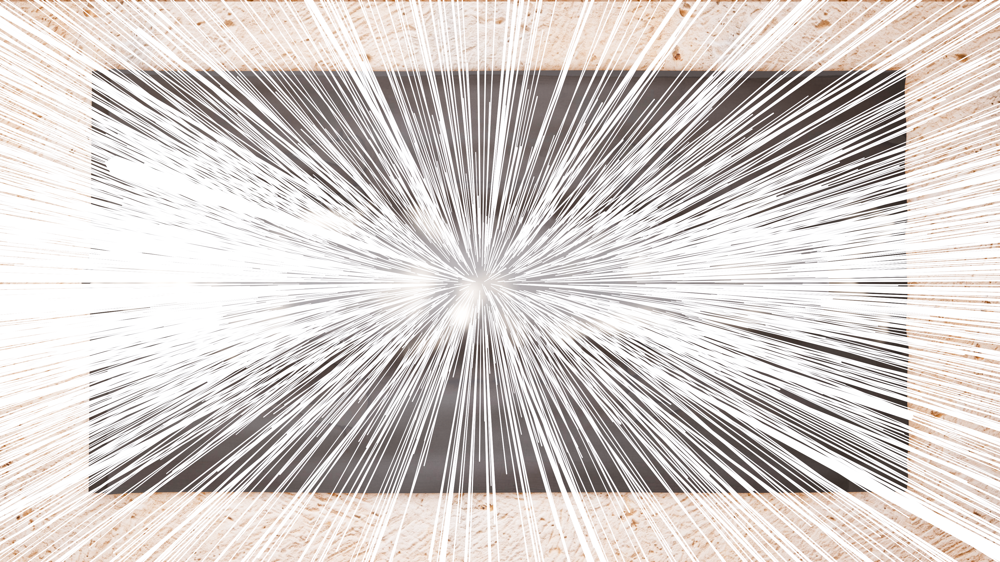

In [14]:
import glob, os
from IPython.display import Image, display
AT = "/content/drive/MyDrive/x3dlab/shroud_atlas"
d = sorted(glob.glob(f"{AT}/renders-*"), key=os.path.getmtime)[-1]
print("folder:", d)
for p in sorted(glob.glob(f"{d}/**/*.png", recursive=True), key=os.path.getmtime, reverse=True):
    print(os.path.basename(p))
    display(Image(filename=p, width=960))

In [15]:
!ls -la


total 28
drwxr-xr-x 1 root root 4096 Nov 23 05:20 .
drwxr-xr-x 1 root root 4096 Nov 23 03:57 ..
drwxr-xr-x 5 root root 4096 Nov 23 04:26 bk
drwxr-xr-x 4 root root 4096 Oct 21 13:28 .config
drwxr-xr-x 2 root root 4096 Nov 23 05:20 diag
drwx------ 5 root root 4096 Nov 23 04:23 drive
drwxr-xr-x 1 root root 4096 Oct 21 13:28 sample_data


In [16]:
#@title 11c. A2 radiant tomb: relic cloth (blood, image, relief) + light rays { display-mode: "form" }
import pathlib, subprocess, time
WIDTH = 1920  #@param [1920, 3840]
SAMPLES = 256  #@param [128, 256, 512, 1024, 2048]
LOOKS = "relic cloth"  #@param {type:"string"}
BLOOD = 0.85  #@param {type:"slider", min:0, max:1, step:0.05}
import os; os.environ["A2_BLOOD"] = str(BLOOD)
AT = pathlib.Path("/content/drive/MyDrive/x3dlab/shroud_atlas")
(AT / "render_a2_looks_v3.py").write_text(r'''"""A2 (radiant tomb) look round: the same scene with the rays made translucent and the exposure pulled down.
  blender -b shroud_atlas_hero_v1_1_packed.blend --python render_a2_looks.py -- <out> <width> <samples> [look ...] [cam:<name part>]
Looks change only two materials and the exposure at render time; the .blend is not saved. ART: every value here is a look choice."""
import bpy, sys, os, json, time
argv = sys.argv[sys.argv.index('--') + 1:]
out, W, SPP = argv[0], int(argv[1]), int(argv[2]); rest = argv[3:]
LOOKS = {  # ray alpha, ray strength, ray colour, linen glow, exposure (stops)
    'veiled':  (0.18, 3.0, (0.93, 0.90, 1.00), 1.6, -1.0),
    'whisper': (0.07, 5.0, (0.93, 0.90, 1.00), 1.8, -1.3),
    'gold':    (0.12, 4.0, (1.00, 0.82, 0.50), 1.6, -1.3),
    'luminous': (0.05, 16.0, (0.95, 0.93, 1.00), 1.8, -1.3),
    'radiant': (0.06, 18.0, (0.96, 0.94, 1.00), 4.0, -1.3),
    'relic':   (0.035, 20.0, (0.96, 0.94, 1.00), 1.3, -0.9),   # fewer photons in the way: the marked cloth is the subject
    'volume':  (0.06, 14.0, (0.95, 0.93, 1.00), 1.8, -1.3),   # rays start at points all through the body, not on its surface
    'cloth':   (0.00, 0.0, (1.00, 1.00, 1.00), 1.3, -0.9),   # no rays: the marked cloth alone
    'glow':    (0.00, 0.0, (1.00, 1.00, 1.00), 2.2, -0.8),
}
want = [a for a in rest if a in LOOKS] or list(LOOKS); camf = [a[4:] for a in rest if a.startswith('cam:')]
DEV = 'CPU'
try:
    p = bpy.context.preferences.addons['cycles'].preferences
    for t in (os.environ.get('A2_DEVICES', 'CUDA,OPTIX').split(',')):
        p.compute_device_type = t; p.refresh_devices() if hasattr(p, 'refresh_devices') else p.get_devices()
        if any(d.type == t for d in p.devices):
            for d in p.devices: d.use = d.type == t
            DEV = t; break
except Exception as e: print('device', e)
sc = bpy.context.scene; sc.cycles.device = 'GPU' if DEV != 'CPU' else 'CPU'
print('RENDER DEVICE', DEV, flush=True)
os.makedirs(out, exist_ok=True)
sc.render.resolution_x, sc.render.resolution_y, sc.render.resolution_percentage = W, W * 9 // 16, 100
sc.cycles.samples = SPP; sc.cycles.use_denoising = True; sc.cycles.use_adaptive_sampling = True; sc.cycles.adaptive_threshold = 0.01
sc.cycles.transparent_max_bounces = 64
sc.render.image_settings.file_format = 'PNG'
try: sc.view_settings.view_transform = 'AgX'; sc.view_settings.look = 'AgX - Medium High Contrast'
except Exception as e: print('look', e)
ray = bpy.data.materials['A2_RayLight'].node_tree.nodes['Principled BSDF']
lin = bpy.data.materials['A2_LinenLit'].node_tree.nodes['Principled BSDF']
# RELIC CLOTH (his 23 Nov ask: "show the blood stains, esp on head, and maybe show imprints, negatives, 3d displacement
# zones"). ART licence: the linen wears the 2002 photograph of the cloth in the body band only, so the image and the blood
# show and the 1532 fire damage along the two burn lines does not (it had not happened yet). Blood is found by its redness
# (R/G of the photograph) and deepened; the relief map presses the body's shape into the linen as a bump and as the glow.
def relic_cloth():
    m = bpy.data.materials['A2_LinenLit']; nt = m.node_tree; N, Lk = nt.nodes, nt.links
    glow = next(n for n in N if n.type == 'TEX_IMAGE')
    for l in list(lin.inputs['Base Color'].links) + list(lin.inputs['Emission Color'].links): Lk.remove(l)
    def node(t, **kw):
        n = N.new(t)
        for k, v in kw.items(): setattr(n, k, v)
        return n
    def math(op, a, b=None, clamp=False):
        n = node('ShaderNodeMath', operation=op, use_clamp=clamp)
        for i, x in enumerate((a, b)):
            if x is None: continue
            if isinstance(x, (int, float)): n.inputs[i].default_value = x
            else: Lk.new(x, n.inputs[i])
        return n.outputs[0]
    def mix(fac, c1, c2, blend='MIX'):
        n = node('ShaderNodeMix', data_type='RGBA', blend_type=blend)
        for sock, x in ((n.inputs[0], fac), (n.inputs[6], c1), (n.inputs[7], c2)):
            if isinstance(x, (int, float)): sock.default_value = x
            elif isinstance(x, tuple): sock.default_value = x
            else: Lk.new(x, sock)
        return n.outputs[2]
    photo = node('ShaderNodeTexImage', image=bpy.data.images['cloth_8k.jpg'])
    uv = node('ShaderNodeTexCoord'); sep = node('ShaderNodeSeparateXYZ'); Lk.new(uv.outputs['UV'], sep.inputs[0]); v = sep.outputs['Y']
    def ramp(x, lo, hi):
        n = node('ShaderNodeMapRange', interpolation_type='SMOOTHSTEP'); Lk.new(x, n.inputs[0]); n.inputs[1].default_value = lo; n.inputs[2].default_value = hi; return n.outputs[0]
    band = math('MULTIPLY', ramp(v, 0.345, 0.405), math('SUBTRACT', 1.0, ramp(v, 0.595, 0.655)))
    u = sep.outputs['X']                                                # the two cloth ends carry the photograph's edge, not cloth: fade them out
    band = math('MULTIPLY', band, math('MULTIPLY', ramp(u, 0.025, 0.07), math('SUBTRACT', 1.0, ramp(u, 0.93, 0.975))))
    rgb = node('ShaderNodeSeparateColor'); Lk.new(photo.outputs['Color'], rgb.inputs[0])
    ratio = math('DIVIDE', rgb.outputs[0], math('MAXIMUM', rgb.outputs[1], 0.001))
    blood = math('MULTIPLY', math('MULTIPLY', math('SUBTRACT', ratio, 1.56), 3.2, clamp=True), band, clamp=True)
    # photograph re-based to pale linen: cloth ground becomes the linen colour, every mark keeps its contrast
    rel = mix(1.0, photo.outputs['Color'], (1 / 0.40, 1 / 0.29, 1 / 0.21, 1), 'MULTIPLY')
    rel = mix(1.0, mix(1.0, rel, rel, 'MULTIPLY'), rel, 'MULTIPLY')          # contrast of the marks cubed, so the faint image reads
    based = mix(1.0, rel, (0.80, 0.76, 0.66, 1), 'MULTIPLY')
    base = mix(band, (0.80, 0.76, 0.66, 1), based)
    base = mix(math('MULTIPLY', blood, BLOOD), base, (0.22, 0.012, 0.012, 1))
    Lk.new(base, lin.inputs['Base Color'])
    emis = mix(math('MULTIPLY', blood, 0.9 * BLOOD), glow.outputs['Color'], (0.10, 0.004, 0.003, 1))
    Lk.new(emis, lin.inputs['Emission Color'])
    bump = node('ShaderNodeBump'); bump.inputs['Strength'].default_value = 0.8; bump.inputs['Distance'].default_value = 0.02
    Lk.new(glow.outputs['Color'], bump.inputs['Height']); Lk.new(bump.outputs['Normal'], lin.inputs['Normal'])
    print('RELIC cloth on, blood', BLOOD, flush=True)
BLOOD = float(os.environ.get('A2_BLOOD', '0.85'))
if 'plain' in rest:
    for l in list(lin.inputs['Base Color'].links): bpy.data.materials['A2_LinenLit'].node_tree.links.remove(l)
    lin.inputs['Base Color'].default_value = (0.80, 0.76, 0.66, 1.0)
else: relic_cloth()
st = bpy.data.objects['A2_Rays'].users_collection[0]
for o in bpy.data.objects: o.hide_render = o.users_collection[0] != st

def volume_rays(n=4800, seed=33):
    # His 23 Nov note: the light leaves every living cell, so the seeds fill the body volume (the same ellipsoid mannequin
    # the cloth tents over; ART, never shown) and each ray leaves in its own direction. Half of them go down into the bench.
    import numpy as np
    rng = np.random.default_rng(seed); XH, ZB, OY = -1.02, 0.625, st_origin_y
    PARTS = [(.11, 0, .125, .09, .23), (.45, 0, .32, .23, .24), (.85, 0, .30, .20, .21), (.98, 0, .15, .17, .26),
             (1.20, .09, .29, .095, .19), (1.20, -.09, .29, .095, .19), (1.37, .085, .11, .075, .20), (1.37, -.085, .11, .075, .20),
             (1.53, .08, .26, .065, .14), (1.53, -.08, .26, .065, .14), (1.76, .07, .065, .055, .27), (1.76, -.07, .065, .055, .27)]
    vol = np.array([au * ay * top for _, _, au, ay, top in PARTS]); pick = rng.choice(len(PARTS), n, p=vol / vol.sum())
    V = []; F = []
    for k in pick:
        uc, yc, au, ay, top = PARTS[k]
        while True:
            q = rng.uniform(-1, 1, 3)
            if q[2] > 0 and q @ q < 1: break
        p = np.array((XH + uc + q[0] * au, OY + yc + q[1] * ay, ZB + 0.004 + q[2] * top))
        d = rng.standard_normal(3); d /= np.linalg.norm(d); L = rng.uniform(0.35, 1.5) ** 1.3; r = 0.00045 * rng.uniform(0.6, 1.4)
        a = np.cross(d, (0.3, 0.5, 0.81)); a /= np.linalg.norm(a); b = np.cross(d, a); m = len(V)
        for end in (p, p + d * L):
            V += [end + r * a, end + r * b, end - r * a, end - r * b]
        F += [(m + i, m + (i + 1) % 4, m + 4 + (i + 1) % 4, m + 4 + i) for i in range(4)]
    me = bpy.data.meshes.new('A2_RaysVolume'); me.from_pydata([tuple(v) for v in V], [], F); me.update()
    ob = bpy.data.objects.new('A2_RaysVolume', me); st.objects.link(ob); me.materials.append(bpy.data.materials['A2_RayLight']); ob.visible_shadow = False
    return ob
st_origin_y = round(bpy.data.objects['A2_Bench'].matrix_world.translation[1] + sum(v.co[1] for v in bpy.data.objects['A2_Bench'].data.vertices) / 24, 3)
vol_ob = volume_rays() if 'volume' in want else None
cams = sorted([o for o in bpy.data.objects if o.type == 'CAMERA' and o.name.startswith('A2') and (not camf or any(f in o.name for f in camf))], key=lambda o: o.name)
log = {}
for name in want:
    a, s, col, glow, ev = LOOKS[name]
    ray.inputs['Alpha'].default_value = a; ray.inputs['Emission Strength'].default_value = s; ray.inputs['Emission Color'].default_value = (*col, 1.0)
    bpy.data.objects['A2_Rays'].hide_render = a <= 0.0 or name == 'volume'
    if vol_ob: vol_ob.hide_render = name != 'volume'
    lin.inputs['Emission Strength'].default_value = glow; sc.view_settings.exposure = ev
    for cam in cams:
        key = f'{cam.name}__{name}'; sc.camera = cam; sc.render.filepath = os.path.join(out, key + '.png'); t = time.time()
        bpy.ops.render.render(write_still=True); log[key] = round(time.time() - t, 1); print('RENDERED', key, log[key], flush=True)
        json.dump(dict(width=W, samples=SPP, engine='CYCLES ' + DEV, blender=bpy.app.version_string, looks={k: LOOKS[k] for k in want}, seconds=log), open(os.path.join(out, 'render_log.json'), 'w'), indent=1)
''')
out = AT / time.strftime("a2-relic-%Y%m%d-%H%M%S")
cmd = [str(BL), "-b", str(AT / "shroud_atlas_hero_v1_1_packed.blend"), "--python", str(AT / "render_a2_looks_v3.py"), "--", str(out), str(WIDTH), str(SAMPLES)] + LOOKS.split()
t0 = time.time(); p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in p.stdout:
    if line.startswith(("RENDER DEVICE", "RENDERED", "RELIC", "Traceback", "Error", "KeyError")): print("%5.0fs" % (time.time() - t0), line.rstrip()[:160])
p.wait(); print(("✅" if p.returncode == 0 else "❌"), "exit", p.returncode, "->", out)
print("Tell Claude: 'looks done'.")


    1s RENDER DEVICE CUDA
    1s RELIC cloth on, blood 0.85
  317s RENDERED A2_Cam_ClothEye__relic 315.9
  569s RENDERED A2_Cam_Face__relic 251.8
  794s RENDERED A2_Cam_Pilgrim__relic 225.0
  827s RENDERED A2_Cam_ClothEye__cloth 32.7
  859s RENDERED A2_Cam_Face__cloth 32.3
  888s RENDERED A2_Cam_Pilgrim__cloth 29.1
✅ exit 0 -> /content/drive/MyDrive/x3dlab/shroud_atlas/a2-relic-20261123-081707
Tell Claude: 'looks done'.


In [10]:
import pathlib, subprocess, time
AT = pathlib.Path("/content/drive/MyDrive/x3dlab/shroud_atlas")
cmd = [str(BL), "-b", str(AT/"shroud_atlas_hero_v1_1_packed.blend"), "--python", str(AT/"render_gpu.py"), "--", "/content/diag", "960", "32", "S1_Cam_VP8"]
t0 = time.time(); p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in p.stdout:
    print("%4.0fs" % (time.time() - t0), line.rstrip()[:200])
    if time.time() - t0 > 420: p.kill(); print("stopped at 7 min"); break

   1s 00:00.852  blend            | Read blend: "/content/drive/MyDrive/x3dlab/shroud_atlas/shroud_atlas_hero_v1_1_packed.blend"
   2s 00:01.997  cycles           | WARNING HIPEW initialization failed: Error opening HIP dynamic library
   2s RENDER DEVICE CUDA
   7s 00:06.460  render           | Saved: '/content/diag/S1_Cam_VP8.png'
   7s RENDERED S1_Cam_VP8 4.5
  10s 00:09.863  render           | Saved: '/content/diag/S1_Cam_VP8_clay.png'
  10s RENDERED S1_Cam_VP8_clay 3.4
  14s 00:13.579  render           | Saved: '/content/diag/S1_Cam_VP8_vp8.png'
  14s RENDERED S1_Cam_VP8_vp8 3.7
  14s Blender 5.3.0 (hash 02f0899d78e3 built 2026-11-10 01:31:18)
  14s 
  14s Blender quit


In [8]:
import pathlib, subprocess
AT = pathlib.Path("/content/drive/MyDrive/x3dlab/shroud_atlas")
s = (AT/"render_gpu.py").read_text()
(AT/"render_gpu_optix_backup.py").write_text(s)
(AT/"render_gpu.py").write_text(s.replace("('OPTIX', 'CUDA')", "('CUDA',)"))
print(subprocess.run("nvidia-smi --query-gpu=name,memory.used,utilization.gpu --format=csv", shell=True, capture_output=True, text=True).stdout)

name, memory.used [MiB], utilization.gpu [%]
NVIDIA A100-SXM4-80GB, 3456 MiB, 100 %



In [ ]:
#@title 10. Make transfer parts under 9 MB (packs and Shroud frames) { display-mode: "form" }
# Claude's Drive link moves files of at most 10 MB. This splits bigger packs and zips the Shroud frames as JPEGs, in parts.
# Nothing is changed or deleted; parts go to .../blenderizer-bakes/_xfer/ and .../shroud_atlas/_xfer/.
import io, os, pathlib, zipfile, hashlib, json
try:
    DRIVE
except NameError:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = "/content/drive/MyDrive/x3d.io/blenderizer-bakes"
PART = 9_000_000
def split(src, dst_dir):
    dst_dir.mkdir(exist_ok=True); data = src.read_bytes(); names = []
    for i in range(0, len(data), PART):
        p = dst_dir / ("%s.part%02d" % (src.name, i // PART)); p.write_bytes(data[i:i + PART]); names.append(p.name)
    json.dump(dict(file=src.name, bytes=len(data), sha256=hashlib.sha256(data).hexdigest(), parts=names), open(dst_dir / (src.name + ".parts.json"), "w"))
    print("✅", src.name, "%.1f MB ->" % (len(data) / 1e6), len(names), "parts")
packs = pathlib.Path(DRIVE) / "_packs"
for z in sorted(packs.glob("*.zip")) if packs.exists() else []:
    if z.stat().st_size > PART:
        split(z, pathlib.Path(DRIVE) / "_xfer")
AT = pathlib.Path("/content/drive/MyDrive/x3dlab/shroud_atlas")
runs = sorted(d for d in AT.glob("renders-*") if d.is_dir()) if AT.exists() else []
if runs:
    from PIL import Image
    run = runs[-1]; tmp = pathlib.Path("/content") / (run.name + "-jpg.zip"); n = 0
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_STORED) as zf:
        for f in sorted(run.iterdir()):
            if f.suffix == ".png":
                b = io.BytesIO(); Image.open(f).convert("RGB").save(b, "JPEG", quality=93, subsampling=0); zf.writestr(f.stem + ".jpg", b.getvalue()); n += 1
            elif f.suffix == ".json":
                zf.write(f, f.name)
    print(run.name, ":", n, "frames")
    split(tmp, AT / "_xfer")
else:
    print("no Shroud render folder yet")
print("Tell Claude: 'parts ready'.")


In [ ]:
#@title 5. Choose the job and the profile { display-mode: "form" }
JOB = "crawl"  #@param ["crawl", "masonic", "fall", "twins"]
PROFILE = "g4"  #@param ["quick", "g4"]
DEVICE = "AUTO"  #@param ["AUTO", "OPTIX", "CUDA", "CPU"]
if DEVICE == "AUTO":
    probe = ("import bpy\np = bpy.context.preferences.addons['cycles'].preferences\nfor t in ('OPTIX', 'CUDA'):\n"
             "    try:\n        p.compute_device_type = t\n        p.refresh_devices() if hasattr(p, 'refresh_devices') else p.get_devices()\n"
             "        print('PROBE', t, [d.name for d in p.devices if d.type == t])\n    except Exception as e:\n        print('PROBE', t, [], e)\n")
    r = subprocess.run([str(BL), "-b", "--python-expr", probe], capture_output=True, text=True).stdout
    found = {l.split()[1]: "[]" not in l for l in r.splitlines() if l.startswith("PROBE")}
    print("\n".join(l for l in r.splitlines() if l.startswith("PROBE")))
    DEVICE = "OPTIX" if found.get("OPTIX") else "CUDA" if found.get("CUDA") else "CPU"
print(("✅" if DEVICE != "CPU" else "❌ no GPU backend found, this would bake on the CPU:"), "device", DEVICE, "| job", JOB, "| profile", PROFILE, "| Blender", BLENDER_VERSION)


## Your one-time step: get Unreal Engine with your Epic account

This notebook cannot download Unreal for you (Epic's EULA: each user downloads it with their own account). Do **one** of these once; the notebook finds it by itself.

**A · The Linux zip in your Google Drive (recommended).**
1. Sign in at [unrealengine.com/linux](https://www.unrealengine.com/linux) with your Epic account and accept the EULA.
2. Download **`Linux_Unreal_Engine_5.8.4.zip`** (the current release in Nov 2026; 5.8.1's zip was 39 GB, ~70 GB unpacked). 5.9 is a *preview*: use it only on purpose.
3. Upload the zip to your Drive folder **`MyDrive/x3dlab/unreal/`** (any name `Linux_Unreal_Engine_*.zip`). Drive needs the room (a Google One plan); the browser upload of 40 GB takes a while: let it finish.

**A2 · Straight from Epic's download link into your Drive (fastest: ~70 MB/s, no upload from your computer).** On unrealengine.com/linux, right-click the download button and copy the link, then run step **5a** below and paste it when asked. The link is typed into a hidden prompt: it is never saved in the notebook, so saving the notebook to GitHub cannot publish it (Epic's links expire after an hour anyway).

**B · Epic's container image, without Docker.**
1. Link your GitHub account to your Epic account ([epicgames.com › Account › Apps and accounts](https://www.epicgames.com/account/connections)) and accept the e-mail invitation to GitHub's **EpicGames** organisation.
2. Create a GitHub *classic* personal access token with only **`read:packages`**.
3. In Colab's 🔑 Secrets add **`GHCR_USER`** (your GitHub user name) and **`GHCR_TOKEN`** (the token), with *Notebook access* on.
4. Set `ENGINE_SOURCE = ghcr` and `GHCR_TAG = dev-slim-5.8.4` below. (The 5.8.1 dev-slim image held a 1 TB build-cache file; this notebook skips it, and Epic fixed it by 5.8.3.)

After the first successful run, `CACHE_ENGINE` writes a trimmed engine archive (no debug symbols, templates or samples: what Epic's own *dev-slim* image also leaves out) to `MyDrive/x3dlab/unreal/cache/`, and later runs start from that. It is your own copy in your own Drive; do not share it.

In [2]:
!nvidia-smi

Mon Nov 23 04:15:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   34C    P0             59W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
#@title 1 · Options { display-mode: "form" }
ENGINE_SOURCE = "auto"  #@param ["auto", "cache", "zip", "ghcr"]
ENGINE_VERSION = "5.8"  #@param ["5.8", "5.4", "5.9", "5.2", "newest"] {allow-input: true}
#@markdown **ENGINE_VERSION** picks among the engines in your Drive (cache archives and `Linux_Unreal_Engine_*.zip`): `5.8` = any 5.8.x, `5.8.4` = exactly that, `newest` = the newest that is not a preview. Changing it switches engines (the one on the local disk is replaced). 5.8 is the default since 12 Nov 2026 (the current release; step 5a fetches it into your Drive once); 5.4 still works; 5.9 is a preview.
SUBSTRATE = "auto"  #@param ["auto", "on", "off"]
MEGALIGHTS = "auto"  #@param ["auto", "on", "off"]
#@markdown **SUBSTRATE** `auto` = Substrate materials from 5.7 (production-ready, Epic's default for new projects). **MEGALIGHTS** `auto` = on from 5.8 where hardware ray tracing is on. Both decide which shaders compile: set them before the first start.
PRIMITIVE_DIVISIONS = 64  #@param {type:"slider", min:16, max:256, step:16}
BLENDER_IO_REF = "main"  #@param {type:"string"}
LINES_FOR_UNREAL = True  #@param {type:"boolean"}
LINE_PX = 1.5  #@param {type:"number"}
X3D_COLOURS = "x_ite"  #@param ["x_ite", "as_is"]
BACKGROUND_GRADIENT = True  #@param {type:"boolean"}
#@markdown **PRIMITIVE_DIVISIONS** segments for X3D Sphere, Cylinder and Cone (X3D leaves them to the browser; 64 holds up at 4K). Read by blender_IO from the *import-fidelity* change on, which also shades them smooth, maps X3D's Blinn-Phong specular and draws lines unlit. **BLENDER_IO_REF** `main` (default) = the add-on's newest main, so those fixes reach Unreal as soon as they merge; the run card records the exact commit. `pin` = the commit in x3d.lab's pins.toml (what the other notebooks use); or any branch or commit of hagopjay/x3d-blender-io. **LINES_FOR_UNREAL** gives Unreal its own copy of each glb with X3D lines and points as tubes and spheres `LINE_PX` pixels wide in a 1080-line frame, sized from the scene's viewpoints (the median one) (Unreal drops line and point primitives; X_ITE and Babylon.js keep drawing the originals).
#@markdown **X3D_COLOURS** `x_ite` (default) reads classic X3D colours (Material, UnlitMaterial, Background) as sRGB values, as X_ITE and Castle do, and lights classic and PhysicalMaterial scenes the way X_ITE does: measured, a Material emissiveColor of 0.5 is 128 in X_ITE, 186 in Babylon.js and Unreal when the glb carries it as is, 127 when converted. Needs the add-on's *x-ite-colour* change (else the run falls back to `as_is` and says so). `as_is` = colours as they are (the behaviour before 12 Nov). **BACKGROUND_GRADIENT** draws an X3D Background's sky and ground gradient as a dome in Unreal (one sky colour stays the flat backdrop). Every emissive X3D colour gets K, as the backdrop does.
DRIVE_DIR = "/content/drive/MyDrive/x3dlab/unreal"  #@param {type:"string"}
GHCR_TAG = "dev-slim-5.8.4"  #@param {type:"string"}
SCENES = "calib, stilllife, toycar-x3d, toycar-gltf, odyssey, gobbler3"  #@param {type:"string"}
#@markdown also available: `gobbler-gyro`, `hall` (14 MB, 23 viewpoints), `pbr-tests`, `lantern-gltf`, `waterbottle-gltf`
RUNG = "auto"  #@param ["auto", "preview", "high", "ultra", "ultra_lumen"]
LOOK = "cinematic"  #@param ["cinematic", "match"]
EXPOSURE = "auto"  #@param ["auto", "fixed"]
MAX_VIEWPOINTS = 4  #@param {type:"slider", min:1, max:30, step:1}
COMPARE = True  #@param {type:"boolean"}
USD = "auto"  #@param ["auto", "off"]
CACHE_ENGINE = True  #@param {type:"boolean"}
CACHE_DDC = True  #@param {type:"boolean"}
FORCE_HWRT = False  #@param {type:"boolean"}
VERBOSE = True  #@param {type:"boolean"}
VISUAL = True  #@param {type:"boolean"}
HEARTBEAT_S = 20  #@param {type:"slider", min:5, max:120, step:5}
DRIVE_HEARTBEAT = True  #@param {type:"boolean"}
GENTLE = True  #@param {type:"boolean"}
#@markdown **DRIVE_HEARTBEAT** writes `DRIVE_DIR/heartbeat/<run>/heartbeat.json` every minute and mirrors logs and stills there every 5 minutes, so the run can be watched from anywhere, also after the browser disconnects (data out only; nothing is read back). **GENTLE** runs Unreal at low CPU and disk priority and leaves 4 cores free: a VM with every core busy can be recycled by Colab.
#@markdown **VERBOSE** streams Unreal's important log lines while it runs, plus a heartbeat every `HEARTBEAT_S` seconds (shader jobs and their rate, workers, Unreal's memory, RAM, VRAM, GPU %, free disk), and warns when Unreal's memory grows with nothing to show for it. **VISUAL** shows every still the moment it is written and a VRAM/GPU chart after each Unreal job.
LAB_REPO = "hagopjay/x3d.lab"
LAB_REF = "main"
#@markdown **EXPOSURE** `auto` (cinematic look): step 9 first brackets each scene at the preview rung (about 2 minutes, one Unreal start per round) and renders at the exposure whose still is neither clipped nor crushed; `fixed` = the calibrated EV for every scene (the 14 Nov G4 run needed -14 EV for odyssey and +2 for the glTF controls). The match look always stays at the calibrated exposure.
#@markdown **auto** rung: *high* on a T4 or L4, *ultra* on A100 / G4. **match** look = X3D-like light (no tone curve, no global illumination): use it to compare engines; **cinematic** = Lumen GI, filmic tone curve.
print("✅ options saved: engine from %s · scenes %s · rung %s · look %s" % (ENGINE_SOURCE, SCENES, RUNG, LOOK))

## 2 · The helpers

Two pieces of code, both from this repository: the Unreal leg (`notebooks/unreal/x3due`, plus the Unreal project and the Python scripts that run *inside* Unreal), and the merged `x3dlab` package for everything that is not Unreal (the X3D → glTF trip and its referee, X_ITE in headless Chrome, Blender).

In [ ]:
#@title 2 · Get the helpers { display-mode: "form" }
import importlib, json, os, subprocess, sys, time
from pathlib import Path
from IPython.display import HTML, Image as IPImage, display

def sh(cmd, timeout=1800):
    r = subprocess.run(cmd, shell=isinstance(cmd, str), capture_output=True, text=True, timeout=timeout)
    return (r.stdout + r.stderr).strip()

def git(args, timeout=1800):
    """git with a read-only token from Colab Secrets (GITHUB_TOKEN) sent as a header for this repo only, the same way as
    notebooks 01-06: works when the repo is private; the token never goes into a URL, a file or the output."""
    env = dict(os.environ)
    try:
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        token = os.environ.get("GITHUB_TOKEN")
    if token:
        import base64
        env.update(GIT_CONFIG_COUNT="1", GIT_CONFIG_KEY_0="http.https://github.com/%s.extraheader" % LAB_REPO,
                   GIT_CONFIG_VALUE_0="AUTHORIZATION: basic " + base64.b64encode(("x-access-token:" + token).encode()).decode())
    r = subprocess.run(["git"] + args, capture_output=True, text=True, timeout=timeout, env=env)
    return r.returncode, (r.stdout + r.stderr).strip()

LAB_DIR = Path("/content/x3d.lab") if Path("/content").is_dir() else Path.home() / "x3d.lab"
if os.environ.get("X3DLAB_DEV") and Path(os.environ["X3DLAB_DEV"]).is_dir():
    LAB_DIR = Path(os.environ["X3DLAB_DEV"])                     # a local checkout
elif not (LAB_DIR / ".git").exists():
    rc, msg = git(["clone", "-q", "--depth", "1", "--branch", LAB_REF, "https://github.com/%s" % LAB_REPO, str(LAB_DIR)])
    if rc:
        raise SystemExit("%s\ncould not clone github.com/%s. If that repo is private, add a read-only GitHub token as the Colab "
                         "secret GITHUB_TOKEN (key icon, left bar) and allow this notebook to read it." % (msg, LAB_REPO))
else:
    rc, msg = git(["-C", str(LAB_DIR), "pull", "-q", "--ff-only"])
    print(msg or "helpers up to date")
UNREAL_DIR = LAB_DIR / "notebooks" / "unreal"
sys.path.insert(0, str(UNREAL_DIR))
if importlib.util.find_spec("x3dlab") is None:
    print("installing the x3dlab package (formats, Blender, X_ITE)…")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "%s[research]" % LAB_DIR], check=True)
# An editable install only becomes importable after a kernel restart (its .pth file is read at start-up), so put the
# package's source folder on the path as well: `import x3dlab` works in this same session.
if str(LAB_DIR / "src") not in sys.path:
    sys.path.insert(1, str(LAB_DIR / "src"))
importlib.invalidate_caches()
from x3due import (compare, convert, engine, engines, gltfstat, lines, live, pipeline, project, report, showcase, tier, staging, ucopy,
                   uerun, vulkan, x3dscene)
SC = report.Scorecard()
CARD = {"notebook": "07_Unreal_Fidelity", "lab_commit": sh("git -C %s rev-parse --short HEAD" % LAB_DIR), "options": {
    k: globals()[k] for k in ("ENGINE_SOURCE", "ENGINE_VERSION", "SUBSTRATE", "MEGALIGHTS", "GHCR_TAG", "SCENES", "RUNG", "LOOK", "EXPOSURE",
                              "MAX_VIEWPOINTS", "COMPARE", "USD", "FORCE_HWRT", "PRIMITIVE_DIVISIONS", "BLENDER_IO_REF",
                              "LINES_FOR_UNREAL", "LINE_PX", "X3D_COLOURS", "BACKGROUND_GRADIENT")}}
WORK = Path("/content/x3due") if Path("/content").is_dir() else Path.home() / "x3due"
print("✅ helpers from %s @ %s · work folder %s" % (LAB_REPO, CARD["lab_commit"], WORK))

## 3 · Which GPU is this, and what can it do for Unreal?

The table is from NVIDIA's own documents (sources in `x3due/tier.py` and `FINDINGS.md`). It is only a *prior*: step 4 asks the Vulkan device for its ray-tracing extensions, and that answer decides.

In [ ]:
#@title 3 · Detect the tier { display-mode: "form" }
HW = tier.detect()
g = HW["gpu"]
print("GPU      :", ("%s · %.0f GB · driver %s · CUDA %s · compute %s" % (g["name"], HW["vram_gb"], HW["driver"], HW["cuda"], g["compute_cap"])) if g else "none")
print("machine  : %d vCPUs · %.0f GB RAM (%.0f free) · %.0f GB free disk in %s" % (HW["cpus"], HW.get("ram_gb", 0), HW.get("ram_available_gb", 0), HW["disk_free_gb"], HW["disk_path"]))
print("container: NVIDIA_DRIVER_CAPABILITIES=%s" % (HW["driver_capabilities"] or "(unset)"))
display(HTML("<div style='font-size:12.5px'>%s</div>" % tier.capability_table_markdown().replace("\n", "<br>")))
CARD["hardware"] = HW
if not g:
    SC.add("3 tier", "NVIDIA GPU present", "FAIL", "no nvidia-smi output: pick a GPU runtime (G4, A100, L4)")
else:
    SC.add("3 tier", "NVIDIA GPU present", "PASS", "%s, %.0f GB, driver %s" % (g["name"], HW["vram_gb"], HW["driver"]))
    SC.add("3 tier", "GPU in the capability table", "PASS" if HW["kind"] in tier.CAPS else "WARN",
           "%s: %s" % (HW["kind"], tier.CAPS.get(HW["kind"], {}).get("rt_note", "unknown GPU, ray tracing decided by Vulkan only")))
need = 90
SC.add("3 tier", "free disk for the engine", "PASS" if HW["disk_free_gb"] >= need else "WARN",
       "%.0f GB free; zip + trimmed engine need about %d GB (less when extracting straight from Drive)" % (HW["disk_free_gb"], need))
SC.add("3 tier", "RAM", "PASS" if HW.get("ram_gb", 0) >= 32 else "WARN",
       "%.0f GB (Unreal recommends 32 GB; shader workers are capped by RAM)" % HW.get("ram_gb", 0))

## 4 · Give Unreal real Vulkan

Colab starts the container with `NVIDIA_DRIVER_CAPABILITIES=compute,utility`: CUDA works, Vulkan does not. `apt-get install libnvidia-gl-<branch>` fails here (*held broken packages*: it would replace Colab's CUDA userspace). What works, and what this cell does: **download** `libnvidia-gl`, `libnvidia-gpucomp` and `libnvidia-common` at *exactly* the driver's version, **unpack** their files (`dpkg -x`, apt's database untouched), `ldconfig`, install `vulkan-tools`. It never installs a different driver version and never hand-writes an ICD file. Then it asks Vulkan, *as the user Unreal will run as*, what the device can do.

In [ ]:
#@title 4 · Vulkan driver, device and ray-tracing extensions { display-mode: "form" }
VK_ENABLE = vulkan.enable()
print("driver %s · %s" % (VK_ENABLE.get("driver"), VK_ENABLE.get("skipped") or "unpacked: " + ", ".join("%s=%s" % kv for kv in VK_ENABLE.get("plan", {}).get("packages", {}).items())))
for d in VK_ENABLE.get("done", []):
    print("  %s → rc %s %s" % (d["cmd"], d["rc"], d["err"][-120:] if d["rc"] else ""))
if HW["gpu"]:
    uerun.ensure_user("ue", [])        # Unreal refuses root; Vulkan is asked as the same user Unreal will run as
VK = vulkan.probe(user="ue" if HW["gpu"] else None)
for d in VK["devices"]:
    print("Vulkan device: %s · %s · API %s%s" % (d.get("deviceName"), d.get("driverName"), d.get("apiVersion"), " (software!)" if d["software"] else ""))
PLAN = tier.plan(HW, VK, force_hwrt=FORCE_HWRT)
rt = PLAN["ray_tracing"]
print("ray tracing:", rt["why"])
print("extensions :", ", ".join("%s %s" % (k, "✓" if v else "✗") for k, v in rt["extensions"].items()))
for n in PLAN["notes"]:
    print("→", n)
st = vulkan.status()
SC.add("4 Vulkan", "NVIDIA Vulkan ICD present", "PASS" if st["nvidia_icd"] else "FAIL",
       st["nvidia_icd"][0] if st["nvidia_icd"] else (VK_ENABLE.get("skipped") or VK_ENABLE.get("error") or "no nvidia_icd.json"))
nv = VK["nvidia_device"]
SC.add("4 Vulkan", "user ue sees the NVIDIA device", "PASS" if nv and not nv["software"] else "FAIL",
       "%s (Vulkan %s)" % (nv.get("deviceName"), nv.get("apiVersion")) if nv else "vulkaninfo as ue lists %s" % ([d.get("deviceName") for d in VK["devices"]] or "nothing"))
SC.add("4 Vulkan", "ray tracing decision", rt["status"], rt["why"])
SC.add("4 Vulkan", "nvoptix.bin (OptiX denoiser)", "PASS" if st["nvoptix_bin"] else "WARN", st["nvoptix_bin"][0] if st["nvoptix_bin"] else "missing: Cycles falls back to OpenImageDenoise")
CARD.update(vulkan={"enable": {k: VK_ENABLE.get(k) for k in ("driver", "skipped", "plan", "error")}, "devices": [
    {k: v for k, v in d.items() if k != "extensions"} for d in VK["devices"]]}, plan={k: v for k, v in PLAN.items() if k != "ladder"},
    ladder=PLAN["ladder"])

### 4b · Only if step 4 says user `ue` does not see the NVIDIA device

Checks first and changes nothing when Vulkan already works. Otherwise it installs the Vulkan/GL userspace of *exactly* the running driver from NVIDIA's own driver package (`--extract-only`, no kernel module).

In [ ]:
#@title 4b · Vulkan for THIS GPU: diagnose, and repair from NVIDIA's own driver package { display-mode: "form" }
import glob, json, os, re, shutil, subprocess, urllib.request
def sh(c, t=900):
    r = subprocess.run(c, shell=True, capture_output=True, text=True, timeout=t)
    return (r.stdout + r.stderr).strip()
def ue_sees_gpu():
    out = sh("runuser -u ue -- env -i HOME=/home/ue PATH=/usr/bin:/bin vulkaninfo --summary 2>&1")
    return ("NVIDIA" in out and "llvmpipe" not in out.split("deviceName")[-1]), out
ver, name = [x.strip() for x in sh("nvidia-smi --query-gpu=driver_version,name --format=csv,noheader").split(",")[:2]]
print("GPU %s · driver %s" % (name, ver))
if "VK_ENABLE" in globals():
    print("step 4 said:", {k: VK_ENABLE.get(k) for k in ("driver", "skipped", "error")})
sh("id ue || useradd -m ue")
if not shutil.which("vulkaninfo"):
    sh("apt-get install -y -qq libvulkan1 vulkan-tools || (apt-get update -qq && apt-get install -y -qq libvulkan1 vulkan-tools)")
print("ICD files:", glob.glob("/usr/share/vulkan/icd.d/*nvidia*") + glob.glob("/etc/vulkan/icd.d/*nvidia*") or "none")
ok, out = ue_sees_gpu()
if ok:
    print("✅ user ue already sees the GPU through Vulkan: nothing to repair")
else:
    print("user ue does not see the GPU (%s): installing the Vulkan/GL userspace of driver %s from NVIDIA" % (
        (re.findall(r"ERROR[^\n]*", out) or ["no NVIDIA device"])[0][:120], ver))
    run = "/content/NVIDIA-Linux-x86_64-%s.run" % ver
    for url in ("https://us.download.nvidia.com/tesla/%s/NVIDIA-Linux-x86_64-%s.run" % (ver, ver),
                "https://download.nvidia.com/XFree86/Linux-x86_64/%s/NVIDIA-Linux-x86_64-%s.run" % (ver, ver)):
        if os.path.exists(run) and os.path.getsize(run) > 50e6:
            break
        try:
            print("  downloading", url.split("/")[2], "…")
            urllib.request.urlretrieve(url, run)
        except Exception as e:
            print("  ", e)
    assert os.path.exists(run) and os.path.getsize(run) > 50e6, "could not download driver %s from NVIDIA" % ver
    d = "/content/nvdrv-%s" % ver
    if not os.path.isdir(d):
        print("  extracting…", sh("sh %s --extract-only --target %s 2>&1 | tail -1" % (run, d)))
    lib = "/usr/lib/x86_64-linux-gnu"
    copied = []
    for f in sorted(glob.glob(d + "/*.so.%s" % ver)):
        b = os.path.basename(f)
        if re.match(r"lib(GLX_nvidia|EGL_nvidia|nvidia-(glcore|glvkspirv|tls|gpucomp|eglcore|glsi|rtcore|vksc-core)|nvoptix)\.so\.", b):
            if not os.path.exists(os.path.join(lib, b)):          # never replace what Colab ships (CUDA libs untouched)
                shutil.copy2(f, lib); copied.append(b)
    for b in ("libGLX_nvidia", "libEGL_nvidia"):
        src = os.path.join(lib, "%s.so.%s" % (b, ver))
        if os.path.exists(src) and not os.path.exists(os.path.join(lib, b + ".so.0")):
            os.symlink(src, os.path.join(lib, b + ".so.0"))
    os.makedirs("/usr/share/nvidia", exist_ok=True)
    if os.path.exists(d + "/nvoptix.bin") and not os.path.exists("/usr/share/nvidia/nvoptix.bin"):
        shutil.copy2(d + "/nvoptix.bin", "/usr/share/nvidia/nvoptix.bin")
    tmpl = (glob.glob(d + "/nvidia_icd.json*") or [None])[0]
    icd = json.loads(open(tmpl).read().replace("__NV_VK_ICD__", "libGLX_nvidia.so.0")) if tmpl else \
        {"file_format_version": "1.0.0", "ICD": {"library_path": "libGLX_nvidia.so.0", "api_version": "1.3.0"}}
    os.makedirs("/usr/share/vulkan/icd.d", exist_ok=True)
    json.dump(icd, open("/usr/share/vulkan/icd.d/nvidia_icd.json", "w"), indent=1)
    sh("ldconfig")
    print("  copied %d libraries: %s" % (len(copied), ", ".join(copied)))
    ok, out = ue_sees_gpu()
    print(("✅ user ue now sees: " if ok else "❌ still no GPU for ue: ") +
          "; ".join(l.strip() for l in out.splitlines() if "deviceName" in l or "ERROR" in l)[:300])
print("\nray-tracing extensions:", {e: e in sh("runuser -u ue -- env -i HOME=/home/ue vulkaninfo 2>/dev/null | grep -o 'VK_KHR_[a-z_]*'")
                                   for e in ("VK_KHR_ray_tracing_pipeline", "VK_KHR_acceleration_structure", "VK_KHR_ray_query")})

## 5a · (optional) Download Unreal from your Epic link into Drive

Skip this when the zip is already in your Drive. The file keeps Epic's own name (for example `Linux_Unreal_Engine_5.4.4.zip`), so the version is known.

In [ ]:
#@title 5a · Paste your Epic download link (hidden; never saved) { display-mode: "form" }
DOWNLOAD = False  #@param {type:"boolean"}
if DOWNLOAD:
    from getpass import getpass
    try:
        from google.colab import drive as _drive
        _drive.mount("/content/drive")
    except Exception:
        pass
    _have = pipeline.drive_engines(DRIVE_DIR, ENGINE_VERSION) if Path(DRIVE_DIR).parent.exists() else []
    if _have:
        print("already in your Drive for %s: %s" % (ENGINE_VERSION, ", ".join(Path(f["path"]).name for f in _have)))
    _url = getpass("Epic download link (Enter to skip): ").strip()
    if _url:
        try:
            _got = engine.download_link(_url, DRIVE_DIR, log=print)          # the link itself is never printed
        finally:
            del _url
        print("✅ %s · %.1f GB in %.0f s (%.0f MB/s)" % (_got["name"], _got["bytes"] / 2**30, _got["seconds"], _got["mb_s"]))
    else:
        del _url
else:
    print("skipped (tick DOWNLOAD to paste an Epic link)")

## 5 · Get the engine

From your Drive (a cache archive from an earlier run, or your `Linux_Unreal_Engine_*.zip`), or from Epic's container image. The zip's index is read first: the notebook knows the exact size before it extracts anything, and decides whether to copy the zip to the local SSD (faster) or extract straight from Drive (when the disk is too small for both).

In [ ]:
#@title 5 · Engine onto the local disk { display-mode: "form" }
try:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    def secret(k):
        try:
            return userdata.get(k)
        except Exception:
            return None
except Exception:
    def secret(k):
        return os.environ.get(k)
if Path("/content").is_dir() and not pipeline.drive_mounted(DRIVE_DIR):
    raise SystemExit("❌ Google Drive is not mounted, so the engine in %s cannot be seen. Run `from google.colab import drive; "
                     "drive.mount('/content/drive', force_remount=True)`, sign in with the account that owns the engine files, "
                     "then run this step again." % DRIVE_DIR)
LAB = pipeline.Lab(work=WORK, hw=HW, plan=PLAN)
LAB.live = live.Live(verbose=VERBOSE, visual=VISUAL, every=HEARTBEAT_S, disk_path=str(WORK)) if (VERBOSE or VISUAL) else None
if GENTLE and HW["gpu"]:
    os.nice(max(0, 10 - os.nice(0)))                  # this kernel and everything it starts yield to Colab's own services
    sh("ionice -c 3 -p %d" % os.getpid())              # lowest disk priority, inherited the same way
    if HW["cpus"] >= 8:
        PLAN["shader_workers"] = min(PLAN.get("shader_workers") or HW["cpus"], HW["cpus"] - 4)
    print("gentle: nice %d · %s shader workers" % (os.nice(0), PLAN.get("shader_workers")))
if DRIVE_HEARTBEAT and Path("/content/drive/MyDrive").exists():
    from x3due import heartbeat
    if not (globals().get("HB_DRIVE") and HB_DRIVE.alive()):
        Path(DRIVE_DIR).mkdir(parents=True, exist_ok=True)
        HB_DRIVE = heartbeat.Heartbeat(DRIVE_DIR, WORK / "out", context=lambda: globals()).start()
    print("💓 Drive heartbeat →", HB_DRIVE.dir)
if not engine.tool("zstd") and HW["gpu"]:
    sh("apt-get install -y -qq zstd")      # multi-threaded compression for the Drive cache
Path(DRIVE_DIR).mkdir(parents=True, exist_ok=True) if Path(DRIVE_DIR).parent.exists() else None
t0 = time.time()
try:
    ENGINE = pipeline.get_engine(LAB, ENGINE_SOURCE, DRIVE_DIR, GHCR_TAG, secret("GHCR_USER"), secret("GHCR_TOKEN"),
                                 want=ENGINE_VERSION)
    print("✅ Unreal %s from %s in %.0f s → %s" % (ENGINE.get("version"), ENGINE["source"], ENGINE["seconds"], LAB.engine_dir))
    SC.add("5 engine", "engine on local disk", "PASS", "Unreal %s (changelist %s) from %s in %.0f s" % (
        ENGINE.get("version"), ENGINE.get("changelist"), ENGINE["source"], ENGINE["seconds"]))
    ver = ENGINE.get("version") or ""
    SC.add("5 engine", "engine version", "PASS" if engine.vkey(ver)[:2] >= (5, 4) else "WARN",
           "%s (asked for %s; 5.8.x is the current release, 5.9 a preview; before 5.4 Unreal on Linux has no Vulkan SM6, so no ray tracing)"
           % (ver, ENGINE_VERSION))
    LAB.settings["sm6"] = engine.default_sm6(ver)
except Exception as exc:
    ENGINE = {"error": str(exc)}
    print("❌", exc)
    SC.add("5 engine", "engine on local disk", "FAIL", str(exc)[:350])
CARD["engine"] = {k: v for k, v in ENGINE.items() if k not in ("extract",)}
if ENGINE.get("version") and Path(LAB.engine_dir).exists():
    _libs = engine.install_system_libs(LAB.engine_dir)          # 5.8 links ATK/GTK; Colab's image lacks them (rc 127 at start)
    CARD["engine"]["system_libs"] = _libs
    SC.add("5 engine", "system libraries the editor links", "PASS" if not _libs["after"] else "WARN",
           ("none missing" if not _libs["before"] else "installed %s" % ", ".join(p for p, ok in _libs["installed"] if ok))
           + ("; still missing %s" % _libs["after"] if _libs["after"] else ""))
if ENGINE.get("version") and not LAB.settings["sm6"]:
    LAB.settings["ray_tracing"] = False
    engine.disable_vulkan_rt(LAB.engine_dir)
    print("Unreal %s: Shader Model 5, no ray tracing (no Vulkan SM6 shader format before 5.4)" % ENGINE["version"])
elif ENGINE.get("version") and PLAN["ray_tracing"]["hw_rt"]:
    LAB.settings["ray_tracing"] = True
    CARD["engine"]["vulkan_rt_config"] = engine.enable_vulkan_rt(LAB.engine_dir, LAB.settings["bindless"])
    print("Vulkan ray tracing switched on in the engine config (Epic's documented edit; originals kept as *.x3due.orig)")
_parts_next = bool(ENGINE.get("version") and CACHE_ENGINE and Path(DRIVE_DIR).exists() and not ENGINE.get("parts"))
if ENGINE.get("version") and CACHE_ENGINE and ENGINE["source"] != "drive cache" and Path(DRIVE_DIR).exists() and not _parts_next:
    CARD["engine_cache"] = pipeline.cache_engine(LAB, DRIVE_DIR, ENGINE["version"])     # only when no parts follow (Drive room)
    print("Drive cache:", CARD["engine_cache"])
if _parts_next:
    print("one-time: splitting the engine cache into %d parts on Drive, so the next runtime restores it in parallel…" % engine.PARTS)
    CARD["engine_parts"] = pipeline.cache_engine_parts(LAB, DRIVE_DIR, ENGINE["version"])
    print("Drive cache (parts):", CARD["engine_parts"])

## 6 · First start: prove the RHI, pay the shader bill

Unreal refuses to run as root (*"Refusing to run with the root privileges"*), so it runs as a normal user `ue`. It starts on Vulkan with **no window** (`-RenderOffscreen`), opens an empty map and quits. The first start compiles Unreal's global shaders (Blender's first OptiX render took 325 s on the A100; Unreal's is usually far longer): it is timed separately, then a second start shows the warm cost. The log decides PASS: Vulkan on the NVIDIA device, not NullRHI, not llvmpipe.

In [ ]:
#@title 6 · Cold and warm start { display-mode: "form" }
if CACHE_DDC and Path(DRIVE_DIR).exists():
    CARD["ddc_restore"] = pipeline.ddc_restore(LAB, DRIVE_DIR, ENGINE.get("version"))
    print("DDC:", CARD["ddc_restore"])
LAB.settings["usd"] = USD == "auto"          # step 8 imports .usdc files: the USD Importer plugin must be on
LAB.settings["engine_version"] = ENGINE.get("version")
LAB.settings["features"] = {"substrate": SUBSTRATE, "megalights": MEGALIGHTS, "async_compute": False}
PROJ = LAB.write_project()
print("project %s · plugins %s · %d shader workers" % (PROJ["project"], ", ".join(p["Name"] for p in PROJ["plugins"] if p["Enabled"]), PROJ["workers"]))
_f = PROJ.get("features") or {}
print("features: Substrate %s (%s) · MegaLights %s (%s) · async compute off (device-lost guard)"
      % ("on" if _f.get("substrate") else "off", _f.get("why", {}).get("substrate"), "on" if _f.get("megalights") else "off",
         _f.get("why", {}).get("megalights")))
CARD["features"] = _f
if PROJ.get("mcp_plugins"):
    print("MCP: this engine ships %s (not used by these batch runs)" % ", ".join(PROJ["mcp_plugins"]))
if PROJ["missing_required"] and ENGINE.get("version"):
    SC.add("6 start", "required plugins in this engine", "FAIL", "missing: %s" % PROJ["missing_required"])
SMOKE = {}
if ENGINE.get("version"):
    for label in ("cold", "warm"):
        SMOKE[label] = pipeline.smoke(LAB, "smoke_" + label)
        p = SMOKE[label]["proof"]
        print("%s start: rc %s in %.0f s · %s · %s" % (label, SMOKE[label]["rc"], SMOKE[label]["seconds"], p.get("verdict"), p.get("why")))
    p = SMOKE["cold"]["proof"]
    SC.add("6 start", "RHI is Vulkan on the NVIDIA GPU", p["verdict"], "%s · device %s · vendor %s · %s · driver %s" % (
        p.get("why"), p.get("device"), p.get("vendor_id"), p.get("shader_platform"), p.get("driver")))
    SC.add("6 start", "one-time shader compile (cold start)", "PASS" if SMOKE["cold"]["rc"] == 0 else "WARN",
           "%.0f s cold, %.0f s warm (difference ≈ global shader compile + DDC fill)" % (SMOKE["cold"]["seconds"], SMOKE["warm"]["seconds"]))
    if p["verdict"] != "PASS":
        print("\n--- the log lines that matter ---\n" + SMOKE["cold"]["excerpt"])
        stack = pipeline.crash_stack(LAB)
        if stack:
            print("\n--- Unreal's crash call stack (newest crash) ---\n" + stack)
            CARD.setdefault("crashes", []).append(stack[:1500])
    for k, v in SMOKE.items():
        for a in v.get("attempts") or []:
            if a.get("change"):
                print("%s start: retried with %s" % (k, a["change"]))
    CARD["smoke"] = {k: {x: v.get(x) for x in ("rc", "seconds", "killed", "proof", "gpu", "attempts", "timing")} for k, v in SMOKE.items()}
    if CACHE_DDC and Path(DRIVE_DIR).exists() and SMOKE["cold"]["rc"] == 0 and SMOKE["cold"]["seconds"] > 120:
        # The global shaders are the expensive part (17 min on an A100, hours on a small runtime): keep them now,
        # not only at step 11, so a run that stops later still leaves a warm cache for the next one.
        CARD["ddc_save_after_start"] = pipeline.ddc_save(LAB, DRIVE_DIR, ENGINE.get("version"))
        print("shader cache saved to Drive:", CARD["ddc_save_after_start"])
else:
    SC.add("6 start", "RHI is Vulkan on the NVIDIA GPU", "SKIP", "no engine (step 5)")

### 6c · Only if step 6 fails: find out why, and find a start that works

Reads Vulkan as user `ue`, the engine's config edits, step 6's log and crash report (with the nearest function names for the crash stack), then tries a few ways of starting Unreal for at most `PROBE_SECONDS` each and keeps the first that works. Its report goes to `DRIVE_DIR/probe/`. (It found the 11 Nov 2026 A100 crash: the Nanite pool above Vulkan's 2 GB allocation, now capped in `tier.py`.)

In [ ]:
#@title 6c · Unreal dies at start on this GPU: find out why, and find a start that works (≈ 3–6 min) { display-mode: "form" }
# Run after step 6 fails. Read-only on your Drive except one report folder (probe/<time>_<gpu>/), which Claude can read.
# It tries a few ways of starting Unreal, each for at most PROBE_SECONDS: a start that is still alive by then got past
# the point where step 6 died (the renderer's start-up, ~10 s in), and is stopped there. With APPLY_WINNER it then keeps
# the first start that worked, so step 6 can simply be run again.
PROBE_SECONDS = 75     #@param {type:"integer"}
APPLY_WINNER = True    #@param {type:"boolean"}

import bisect, glob, json, os, re, shutil, subprocess, time
from pathlib import Path
from x3due import engine as E, pipeline, uerun

assert "LAB" in globals() and (Path(LAB.engine_dir) / "Engine/Binaries/Linux/UnrealEditor").exists(), "run steps 1–5 first (no engine on disk)"
LOGS = Path(LAB.out) / "logs"
GPU = subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip() \
    if shutil.which("nvidia-smi") else "no nvidia-smi"
STAMP = time.strftime("%Y-%m-%dT%H-%MZ", time.gmtime())
SAVED = json.loads(json.dumps(LAB.settings, default=str))
REPORT = {"stamp": STAMP, "gpu": GPU, "settings_before": SAVED, "variants": []}
CRASH_RX = re.compile(r"Caught signal|Segmentation fault|Unhandled Exception|Assertion failed|appError called|Fatal error", re.I)
# UnrealBuildTool's AutoSDK probe (dotnet) segfaults on Colab with rc 139 and the editor carries on; 6c read it as the
# editor crashing and reported "no Vulkan start works" (14 Nov 2026, G4). Lines from UBT are not the editor.
BENIGN_RX = re.compile(r"UnrealBuildTool|AutoSDK|BatchFiles/Linux/Build\.sh", re.I)
def crashed(l):
    return bool(CRASH_RX.search(l)) and not BENIGN_RX.search(l)
BIN = Path(LAB.engine_dir) / "Engine/Binaries/Linux"
CONF = Path(LAB.engine_dir) / "Engine/Config"


def as_ue(cmd, timeout=180):
    """Run a command as the user Unreal runs as, with Unreal's environment (the same Vulkan driver it sees)."""
    full = ["runuser", "-u", LAB.user, "--", "env", "-i"] + ["%s=%s" % kv for kv in LAB.env().items()] + list(cmd)
    try:
        p = subprocess.run(full, capture_output=True, text=True, timeout=timeout)
        return p.returncode, p.stdout + p.stderr
    except Exception as exc:
        return -1, "%s: %s" % (type(exc).__name__, exc)


def kill_leftovers():
    """zenserver and the crash reporter outlive Unreal; a stale zenserver can hang the next start."""
    subprocess.run(["pkill", "-TERM", "-u", LAB.user, "-f", "zenserver"], capture_output=True)   # let Zen close its store
    time.sleep(2)
    for pat in ("UnrealEditor", "ShaderCompileWorker", "CrashReportClient", "zenserver", "UnrealTraceServer"):
        subprocess.run(["pkill", "-9", "-u", LAB.user, "-f", pat], capture_output=True)
    time.sleep(1)


def head(title):
    print("\n" + "━" * 100 + "\n" + title + "\n" + "━" * 100)


# ───────────────────────────────────────────── ① what Vulkan shows Unreal's user on this GPU
head("① Vulkan as user %s · %s" % (LAB.user, GPU))
if not shutil.which("vulkaninfo"):
    subprocess.run("apt-get install -y -qq vulkan-tools", shell=True, capture_output=True)
rc, VI = as_ue(["vulkaninfo"], timeout=120)


def vi_get(rx):
    m = re.search(rx, VI, re.M)
    return m.group(1).strip() if m else None


DEV = {k: vi_get(r"^\s*%s\s*=\s*(.+)$" % k) for k in ("deviceName", "deviceType", "apiVersion", "driverVersion")}
QUEUES = sorted(set(re.findall(r"queueFlags\s*=\s*(.+)", VI)))
EXTS = ["VK_KHR_swapchain", "VK_KHR_dynamic_rendering", "VK_KHR_maintenance4", "VK_EXT_descriptor_buffer", "VK_EXT_mutable_descriptor_type",
        "VK_EXT_mesh_shader", "VK_EXT_shader_image_atomic_int64", "VK_KHR_fragment_shading_rate", "VK_KHR_buffer_device_address",
        "VK_KHR_ray_tracing_pipeline", "VK_KHR_acceleration_structure", "VK_KHR_ray_query"]
FEATS = ["geometryShader", "tessellationShader", "textureCompressionBC", "shaderInt64", "shaderFloat16", "shaderBufferInt64Atomics",
         "shaderImageInt64Atomics", "bufferDeviceAddress", "descriptorBuffer", "meshShader", "taskShader", "descriptorIndexing",
         "runtimeDescriptorArray", "multiDrawIndirect", "fillModeNonSolid", "samplerAnisotropy"]
REPORT["vulkan"] = {"rc": rc, "device": DEV, "queues": QUEUES,
                    "extensions": {x: (x in VI) for x in EXTS},
                    "features": {f: vi_get(r"^\s*%s\s*=\s*(\w+)" % f) for f in FEATS}}
print("device   : %(deviceName)s · %(deviceType)s · API %(apiVersion)s · driver %(driverVersion)s" % {k: v or "?" for k, v in DEV.items()})
print("queues   : " + (" | ".join(QUEUES) if QUEUES else "none listed (vulkaninfo rc %s: %s)" % (rc, VI.strip().splitlines()[-1:] if VI.strip() else "")))
print("graphics : " + ("✅ a queue family has QUEUE_GRAPHICS_BIT" if any("GRAPHICS" in q for q in QUEUES) else "❌ NO graphics queue: this GPU only offers compute through Vulkan"))
print("ext      : " + "  ".join("%s %s" % (x.replace("VK_", ""), "✓" if v else "✗") for x, v in REPORT["vulkan"]["extensions"].items()))
print("features : " + "  ".join("%s=%s" % (f, v) for f, v in REPORT["vulkan"]["features"].items() if v is not None))
lic = subprocess.run("nvidia-smi -q | grep -i -E 'Virtualization Mode|License Status|Product Brand|GPU Operation Mode|MIG Mode' -A1 | head -20",
                     shell=True, capture_output=True, text=True).stdout
REPORT["nvidia_smi_q"] = lic
print(lic.strip())

# ───────────────────────────────────────────── ② the engine's ray-tracing / bindless edits and the project's RHI
head("② Engine config edits (Epic's documented Vulkan ray-tracing edit) and what the project asks for")
ORIGS = sorted(CONF.glob("**/*.x3due.orig"))
CFG_KEYS = re.compile(r"^\s*(bSupportsRayTracingShaders|bSupportsPathTracing|BindlessSupport|BindlessResources|BindlessSamplers)\s*=.*$", re.M)
for f in (CONF / "VulkanPC/DataDrivenPlatformInfo.ini", CONF / "Linux/BaseLinuxEngine.ini"):
    if f.exists():
        print("%-40s %s" % (f.relative_to(CONF), " · ".join(m.group(0).strip() for m in CFG_KEYS.finditer(f.read_text(errors="replace"))) or "(no RT/bindless keys)"))
print("edited by the lab (originals kept): %s" % ([str(o.relative_to(CONF)) for o in ORIGS] or "none"))
de = Path(LAB.project_dir) / "Config/DefaultEngine.ini"
if de.exists():
    print("project: " + " · ".join(l.strip() for l in de.read_text().splitlines() if re.match(r"\s*[+-]?TargetedRHIs|\s*r\.RayTracing=|\s*r\.Lumen\.HardwareRayTracing=", l)))
print("lab settings: sm6 %(sm6)s · ray_tracing %(ray_tracing)s · bindless %(bindless)s · cvars %(cvars)s" % LAB.settings)
SNAP = {p: p.read_text(errors="replace") for p in (CONF / "VulkanPC/DataDrivenPlatformInfo.ini", CONF / "Linux/BaseLinuxEngine.ini") if p.exists()}
REPORT["engine_config"] = {"edited": [str(o) for o in ORIGS], "keys": {str(p): [m.group(0).strip() for m in CFG_KEYS.finditer(t)] for p, t in SNAP.items()}}


def config_as_found():
    for p, t in SNAP.items():
        if p.read_text(errors="replace") != t:
            p.write_text(t)


# ───────────────────────────────────────────── ③ what step 6's log says just before the crash
head("③ Step 6's log: Vulkan start-up and the last lines before the crash")
LOG6 = sorted(LOGS.glob("smoke_*.log"), key=os.path.getmtime)
LOG6 = LOG6[-1] if LOG6 else None
if LOG6:
    log6 = LOG6.read_text(errors="replace").splitlines()     # not `lines`: that name is the x3due.lines module step 8 uses
    vk = [l for l in log6 if re.search(r"LogVulkanRHI|LogRHI|LogInit: .*RHI|Profile|SM6|SM5", l) and not re.search(r"Display:\s+[-+] VK_", l)]
    crash_at = next((i for i, l in enumerate(log6) if crashed(l)), len(log6))
    print("log: %s (%d lines)" % (LOG6, len(log6)))
    for l in vk[-45:]:
        print("  " + l[:240])
    print("  … the 25 lines before the crash:")
    for l in log6[max(0, crash_at - 25): crash_at + 6]:
        print("  " + l[:240])
    REPORT["step6_log"] = {"path": str(LOG6), "vulkan_lines": vk[-80:], "before_crash": log6[max(0, crash_at - 60): crash_at + 40]}
else:
    print("no step 6 log under", LOGS)
CR = sorted(glob.glob(str(Path(LAB.project_dir) / "Saved/Crashes/*")), key=os.path.getmtime)
if CR:
    cl = Path(CR[-1]) / "X3DLab.log"
    if cl.exists():
        tl = cl.read_text(errors="replace").splitlines()
        hit = [l for l in tl if re.search(r"Unhandled Exception|Caught signal|SIGSEGV|invalid attempt|Assertion|Fatal", l)]
        print("\ncrash report %s:\n  " % Path(CR[-1]).name + "\n  ".join(h[:300] for h in hit[:8]))
        REPORT["crash_report_lines"] = hit[:20]

# ───────────────────────────────────────────── ④ name the functions in the crash stack (no debug files needed)
head("④ The crash stack with the nearest exported function names")
STACK = pipeline.crash_stack(LAB, 8000)
_SYMS = {}


def nearest(lib, off):
    so = BIN / lib if (BIN / lib).exists() else None
    if not so:
        return None
    dbg = so.with_suffix(".debug")
    if dbg.exists() and shutil.which("addr2line"):
        out = subprocess.run(["addr2line", "-C", "-f", "-e", str(dbg), hex(off)], capture_output=True, text=True).stdout.split("\n")
        if out and out[0] and out[0] != "??":
            return "%s  [%s]" % (out[0], out[1] if len(out) > 1 else "")
    if lib not in _SYMS:
        nm = subprocess.run(["nm", "-D", "--defined-only", "-C", str(so)], capture_output=True, text=True).stdout
        rows = []
        for l in nm.splitlines():
            parts = l.split(" ", 2)
            if len(parts) == 3 and parts[1] in "TtWw":
                try:
                    rows.append((int(parts[0], 16), parts[2]))
                except ValueError:
                    pass
        rows.sort()
        _SYMS[lib] = ([a for a, _ in rows], [n for _, n in rows])
    addrs, names = _SYMS[lib]
    i = bisect.bisect_right(addrs, off) - 1
    if i < 0:
        return None
    d = off - addrs[i]
    return "%s +0x%x%s" % (names[i][:160], d, "   (far from it: an internal function after it)" if d > 0x4000 else "")


NAMED = []
for l in STACK.splitlines():
    m = re.match(r"\s*(\S+?)!UnknownFunction\(0x([0-9a-fA-F]+)\)", l)
    name = nearest(m.group(1), int(m.group(2), 16)) if m else None
    NAMED.append(l.strip() + ("    ← " + name if name else ""))
print("\n".join(NAMED) or "no crash stack under Saved/Crashes")
REPORT["stack_named"] = NAMED

# ───────────────────────────────────────────── ⑤ try a few starts
head("⑤ Trying starts (each at most %d s; a start still alive then is past the crash point)" % PROBE_SECONDS)
FRESH = Path("/content/x3due_probe") if Path("/content").exists() else Path(LAB.work) / "probe_fresh"
VARIANTS = [("as step 6", {}),
            # the shader cache and home restored from the L4 run (6b) are set aside: an empty HOME and local DDC
            ("as step 6, empty home + shader cache", {"env": {"HOME": str(FRESH / "home"), "XDG_CONFIG_HOME": str(FRESH / "home/.config"),
                                                         "UE-LocalDataCachePath": str(FRESH / "ddc")}})]
if ORIGS:
    VARIANTS.append(("SM6 + Epic's original engine config", {"epic_config": True}))
VARIANTS += [("SM6 + async compute off", {"cvars": {"r.Vulkan.AllowAsyncCompute": 0}}),
             ("SM5", {"sm6": False})]
if ORIGS:
    VARIANTS.append(("SM5 + Epic's original engine config", {"sm6": False, "epic_config": True}))
VARIANTS.append(("no GPU (-nullrhi): control", {"nullrhi": True}))


def setup(ch):
    LAB.settings.clear()
    LAB.settings.update(json.loads(json.dumps(SAVED)))
    config_as_found()
    if ch.get("epic_config"):
        E.disable_vulkan_rt(LAB.engine_dir)
        LAB.settings["ray_tracing"] = False
    if ch.get("sm6") is False:
        LAB.settings["sm6"] = False
        LAB.settings["ray_tracing"] = False
    LAB.settings["cvars"].update(ch.get("cvars", {}))
    for k, v in ch.get("env", {}).items():
        LAB.settings["env"][k] = v
        if v.startswith("/") and not Path(v).exists():
            Path(v).mkdir(parents=True, exist_ok=True)
    if ch.get("env"):
        subprocess.run(["chown", "-R", "%s:%s" % (LAB.user, LAB.user), str(FRESH)], capture_output=True)
    LAB.write_project()


for label, ch in VARIANTS:
    kill_leftovers()
    setup(ch)
    cmd = pipeline.smoke_cmd(LAB)
    if ch.get("nullrhi"):
        cmd = [c for c in cmd if c not in ("-vulkan", "-sm6", "-sm5")] + ["-nullrhi"]
    LAB.own()
    log = LOGS / ("probe_%s.log" % re.sub(r"[^a-z0-9]+", "_", label.lower()).strip("_"))
    res = uerun.run(cmd, log, user=LAB.user, env_vars=LAB.env(), timeout=PROBE_SECONDS)
    text = log.read_text(errors="replace") if log.exists() else ""
    timed_out = str(res.get("killed") or "").startswith("timeout")
    crash = next((l.strip() for l in text.splitlines() if crashed(l)), None) or (
        "exit code %s" % res["rc"] if res["rc"] not in (0, None) and not timed_out else None)
    ok = not crash and (timed_out or res["rc"] == 0)
    platform = (re.findall(r"\b(VULKAN_SM6|VULKAN_SM5)\b", text) or ["?"])[-1]
    compiling = "Using Local Shader Compiler" in text or "shader autogen file written" in text.lower()
    row = {"label": label, "change": ch, "ok": ok, "rc": res["rc"], "seconds": res["seconds"], "stopped_by_probe": timed_out,
           "crash": crash, "platform": platform, "compiling_shaders": compiling,
           "vram_peak_mb": (res.get("gpu") or {}).get("peak_mem_mb"), "log": str(log)}
    REPORT["variants"].append(row)
    print("%s %-38s rc %-5s %5.0f s · %-11s · %s%s" % ("✅" if ok else "❌", label, res["rc"], res["seconds"], platform,
          "alive at %d s, stopped" % PROBE_SECONDS if timed_out and ok else ("quit cleanly" if ok else crash[:110]),
          " · shader compile started" if compiling else ""))
kill_leftovers()

# ───────────────────────────────────────────── ⑥ keep the first start that worked
head("⑥ Verdict")
gpu_wins = [r for r in REPORT["variants"] if r["ok"] and not r["change"].get("nullrhi")]
LAB.settings.clear()
LAB.settings.update(json.loads(json.dumps(SAVED)))
config_as_found()
if not gpu_wins:
    null_ok = any(r["ok"] for r in REPORT["variants"] if r["change"].get("nullrhi"))
    REPORT["verdict"] = "no Vulkan start works on this GPU" + (" (the engine itself starts: -nullrhi is fine)" if null_ok else "")
    print("❌ " + REPORT["verdict"] + ".\n   Settings left as they were. The report below is on your Drive for Claude to read.\n"
          "   If ① shows no graphics queue, this A100 cannot draw with Vulkan at all: an L4 or G4 runtime can.")
    LAB.write_project()
else:
    w = gpu_wins[0]
    REPORT["verdict"] = "works: " + w["label"]
    if w["label"] == "as step 6":
        print("✅ Step 6's own start works now (the crash did not come back: likely a stale zenserver or a half-written cache).\n"
              "   Nothing changed. Run step 6 again.")
        LAB.write_project()
    elif APPLY_WINNER:
        setup(w["change"])
        if w["change"].get("sm6") is False and isinstance(globals().get("PLAN"), dict):
            PLAN.setdefault("notes", []).append("6c: this GPU starts only on Shader Model 5 (VULKAN_SM5)")
        print("✅ Kept: %s. Project and engine config now set that way (lab settings: sm6 %s · ray_tracing %s · cvars %s).\n"
              "   Run step 6 again: the cold start compiles the global shaders for this setting (about 15–20 min on an A100)."
              % (w["label"], LAB.settings["sm6"], LAB.settings["ray_tracing"], LAB.settings["cvars"])
              + ("\n   Unreal now uses an empty home and shader cache under %s (the cache restored from the L4 was the trouble)." % FRESH
                 if w["change"].get("env") else ""))
    else:
        print("✅ %s works. APPLY_WINNER is off, so nothing changed." % w["label"])
        LAB.write_project()
REPORT["settings_after"] = json.loads(json.dumps(LAB.settings, default=str))
globals().setdefault("CARD", {}).setdefault("probe_6c", []).append({k: REPORT[k] for k in ("stamp", "gpu", "verdict")} | {"variants": [
    {k: r[k] for k in ("label", "ok", "rc", "seconds", "platform", "crash")} for r in REPORT["variants"]]})

# ───────────────────────────────────────────── ⑦ the report on Drive (data out only)
try:
    if Path(DRIVE_DIR).exists():
        d = Path(DRIVE_DIR) / "probe" / ("%s_%s" % (STAMP, re.sub(r"[^A-Za-z0-9]+", "-", GPU.split(",")[0]).strip("-")))
        d.mkdir(parents=True, exist_ok=True)
        (d / "report.json").write_text(json.dumps(REPORT, indent=1, default=str))
        (d / "vulkaninfo.txt").write_text(VI[-400000:])
        for p in [LOG6] + [Path(r["log"]) for r in REPORT["variants"]]:
            if p and Path(p).exists():
                (d / Path(p).name).write_text("\n".join(Path(p).read_text(errors="replace").splitlines()[-3000:]))
        print("\nreport on Drive:", d)
except Exception as exc:
    print("(could not write the Drive report: %s)" % exc)

## 7 · Scenes in, X3D → glTF (the Foundry's leg)

Each scene is downloaded from its home (pinned commits; licences in the table). X3D scenes go to glTF through the lab's own Blender leg: `x3d-blender-io` import, Blender's glTF export, the **Khronos glTF validator**, and `x3dlab.formats.losses` (what glTF has no place for). *The `-gltf` scenes are controls*: Khronos samples that go straight into Unreal with no Blender step, so Unreal can be judged on the same file X_ITE draws.

**Expected before Unreal** (found by notebook 06 Foundry with minimal repros; they cap the fidelity of whatever reaches Unreal): x3d-blender-io skips IndexedQuadSet and Arc2D · Sphere and Cylinder import flat-shaded · TwoSidedMaterial is dropped · strips and fans become plain faces, point sets are dropped. GLSL `ComposedShader`s (the Gobbler's whole look) cannot travel in glTF at all; DESIGN.md says what can be done about them.

In [ ]:
#@title 7 · Download, read, convert { display-mode: "form" }
from x3dlab import blender as xblender, formats
names = [s.strip() for s in SCENES.split(",") if s.strip() in showcase.CATALOGUE]
display(HTML("<div style='font-size:12px'>%s</div>" % showcase.licence_table(names).replace("\n", "<br>")))
BL = None
CARD["blender_io"] = engines.use_blender_io(BLENDER_IO_REF, WORK, PRIMITIVE_DIVISIONS, colour_space=X3D_COLOURS)
COLOURS = CARD["blender_io"]["colour_space"]            # what the add-on really does; the Unreal leg follows it
LAB.mapping = convert.LightMapping(ev100=LAB.mapping.ev100, measured_k=LAB.mapping.k, colour_space=COLOURS)   # K kept
try:
    BL = xblender.setup()
    print("Blender %s for the X3D → glTF leg · add-on %s · %d segments per circle · colours %s" % (
        BL.version, CARD["blender_io"].get("why", "pinned in pins.toml"), PRIMITIVE_DIVISIONS, COLOURS))
except Exception as exc:
    print("⚠️ Blender unavailable: %s (X3D scenes are skipped; glTF controls still run)" % exc)
SCN = {}
for n in names:
    e = showcase.CATALOGUE[n]
    rec = {"name": n, "kind": e["kind"]}
    try:
        f = showcase.fetch(n, WORK / "scenes")
        rec.update(fetch=f)
        main = Path(f["main"])
        if e["kind"] == "x3d":
            xml, vp_names = x3dscene.ensure_viewpoint_defs(main.read_text(encoding="utf-8", errors="replace"))
            xml, rec["freeze"] = staging.freeze(xml, e.get("freeze_at", "auto"))       # dark at time 0? freeze it lit
            m0 = x3dscene.manifest(xml)
            rec["framing"] = staging.frame_all(m0)
            if staging.needs_auto(rec["framing"]) and m0.get("bounds"):                 # no authored viewpoint shows it
                xml, _ = staging.add_auto_viewpoint(xml, m0["bounds"])
                rec["framing"] = staging.frame_all(x3dscene.manifest(xml))
            main.write_text(xml, encoding="utf-8")
            rec["manifest"] = x3dscene.manifest(xml)
            if rec["freeze"].get("fraction") is not None:
                print("%s: %s (lights %.3g -> %.3g)" % (n, rec["freeze"]["why"], rec["freeze"]["lights_t0"], rec["freeze"]["lights_frozen"]))
            bad = {k: v["verdict"] for k, v in rec["framing"].items() if v["verdict"] not in ("frames", "inside")}
            if bad:
                print("%s: viewpoints that don't show the model: %s%s" % (n, bad, " · added x3dlab_auto" if "x3dlab_auto" in rec["framing"] else ""))
            if BL is not None:
                conv = engines.to_gltf(BL, main, main.with_suffix(".glb"))
                rec["convert"] = {k: conv.get(k) for k in ("error", "counts", "shared_meshes", "flat_meshes", "losses", "export_s", "bytes")}
                rec["validator"] = {k: (conv.get("validator") or {}).get(k) for k in ("ok", "errors", "warnings")}
                rec["glb"] = conv.get("output") if not conv.get("error") else None
                if USD == "auto" and not conv.get("error"):
                    u = engines.to_gltf(BL, main, main.with_suffix(".usdc"), fmt="usd")
                    rec["usd"] = u.get("output") if not u.get("error") else None
                    rec["usd_error"] = u.get("error")
        else:
            rec["glb"] = str(main)
            gs = gltfstat.stats(main)
            cs = gs["shape_centres"]
            lo = tuple(min(c[i] for c in cs) for i in range(3)) if cs else (-1, -1, -1)
            hi = tuple(max(c[i] for c in cs) for i in range(3)) if cs else (1, 1, 1)
            xml, vp = compare.gltf_control_x3d(main.name, (lo, hi))
            (main.parent / "control.x3d").write_text(xml, encoding="utf-8")
            m = x3dscene.manifest(xml)
            m["bounds"], m["shape_centres"] = (lo, hi), cs
            rec["manifest"], rec["wrapper"] = m, str(main.parent / "control.x3d")
        if rec.get("glb"):
            rec["gltf"] = gltfstat.stats(rec["glb"])
        c = rec["manifest"]["counts"]
        lo_ = (rec.get("convert") or {}).get("losses") or {}
        print("%-14s %5d nodes · %d shapes · %d viewpoints · %d lights · glTF %s%s" % (
            n, c["nodes"], c["shape_instances"], c["viewpoints"], c["lights"], "✓" if rec.get("glb") else "✗",
            ("  · expected losses: %s · unexpected: %s" % (", ".join(lo_.get("expected", [])[:6]) or "none", "; ".join(lo_.get("unexpected", [])) or "none")) if lo_ else ""))
        if rec.get("validator", {}).get("ok") is False:
            SC.add("7 scenes", "%s: glTF valid (Khronos)" % n, "WARN", "%s errors" % rec["validator"].get("errors"))
        SC.add("7 scenes", "%s: in and converted" % n, "PASS" if rec.get("glb") else "FAIL",
               "%d viewpoints, %s missing files%s" % (c["viewpoints"], len(f.get("missing", [])), "; " + (rec.get("convert") or {}).get("error", "") if (rec.get("convert") or {}).get("error") else ""))
    except Exception as exc:
        rec["error"] = str(exc)
        SC.add("7 scenes", "%s: in and converted" % n, "FAIL", str(exc)[:300])
    SCN[n] = rec
CARD["scenes"] = {n: {k: v for k, v in r.items() if k not in ("manifest",)} | {"counts": (r.get("manifest") or {}).get("counts"),
                  "traps": (r.get("manifest") or {}).get("traps")} for n, r in SCN.items()}

## 8 · Into Unreal: import, account, calibrate

One editor task per scene (a fresh process: no state leaks from one scene to the next): Interchange imports the glTF into a new level; the script measures what arrived, works out which axis mapping the importer used (from the shapes' centres, not by assumption), places the X3D viewpoints as cameras and the X3D lights in physical units, adds the backdrop (the X3D Background colour) and makes one sequence per viewpoint. Then the accounting: **glTF in vs Unreal out**, row by row.

**Calibration first.** X3D light intensity has no unit; Unreal's are lux and candela, and the picture depends on exposure. The `calib` scene (one white box, one light of intensity 1, head-on) is rendered with no tone curve; its brightness gives the constant every later scene's lights are converted with. **Field of view:** X3D's applies to the *shorter* image side, Unreal's is horizontal; cameras get a filmback with the image's aspect and the matching focal length.

In [ ]:
#@title 8 · Import every scene, calibrate the lights { display-mode: "form" }
IMP = {}
def do_import(n):
    r = SCN[n]
    src, gstats = r["glb"], r["gltf"]
    if n != "calib":
        dst = Path(src).with_name(Path(src).stem + "_unreal.glb")
        try:                                   # after the calibration, so the emission uses the measured K
            uc = ucopy.unreal_copy(src, dst, r["manifest"], k=LAB.mapping.k, colour_space=LAB.mapping.colour_space,
                                   line_radius=lines.radius_for(r["manifest"], px=LINE_PX), thicken=LINES_FOR_UNREAL,
                                   sky=BACKGROUND_GRADIENT)
            r["unreal_copy"] = uc
            lr = uc["lines"]
            if uc["changed"]:
                src, gstats = str(dst), gltfstat.stats(dst)
            if lr.get("changed"):
                SC.add("8 import", "%s: X3D lines and points as geometry" % n, "PASS",
                       "%d segments and %d points → %d triangles in %d colour%s%s (radius %.3g m, emission × K %.3g)%s" % (
                           lr["segments"], lr["points"], lr["triangles_added"], lr["colours"], "" if lr["colours"] == 1 else "s",
                           ", %d translucent" % lr["translucent"] if lr["translucent"] else "", lr["radius"], LAB.mapping.k,
                           "; skipped: %s" % "; ".join(lr["skipped"][:2]) if lr["skipped"] else ""))
            if uc["emission_scaled"]:
                SC.add("8 import", "%s: X3D emissive colours × K" % n, "PASS",
                       "%d emissive materials × K %.3g, so they land on screen at their X3D value (colours: %s)" % (
                           uc["emission_scaled"], LAB.mapping.k, uc["colour_space"]))
            if "radius_m" in uc["sky"]:
                SC.add("8 import", "%s: X3D Background gradient" % n, "PASS",
                       "a dome of %d triangles at %.0f m: zenith %s · horizon %s · nadir %s" % (
                           uc["sky"]["triangles"], uc["sky"]["radius_m"], uc["sky"]["colours"][0], uc["sky"]["colours"][2],
                           uc["sky"]["colours"][-1]))
        except Exception as exc:
            SC.add("8 import", "%s: the glb for Unreal" % n, "WARN", "the Foundry's glb as it is (lines dropped, emission × 1): %s" % str(exc)[:200])
    res = pipeline.import_scene(LAB, n, src, "gltf", r["manifest"], shape_centres=r["manifest"].get("shape_centres"))
    rep = res["report"]
    IMP[n] = res
    rows = report.account(gstats, rep, r["manifest"], rep)
    st = "PASS" if rep.get("ok") else "FAIL"
    SC.add("8 import", "%s: Interchange import" % n, st, "%s · %d sequences · %.0f s%s" % (
        "ok" if rep.get("ok") else "; ".join(rep.get("errors", [])[:2]) or "failed", len(rep.get("sequences", {})), res["seconds"],
        " · %d API names differ in this engine" % len(rep.get("api_misses", [])) if rep.get("api_misses") else ""))
    for row in rows:
        SC.add("8 import", "%s: %s" % (n, row["what"]), row["status"], row["reason"])
    if not rep.get("ok"):
        print("--- %s: the log lines that matter ---\n%s" % (n, res["excerpt"][-3000:]))
    if r.get("usd"):
        u = pipeline.import_scene(LAB, n, r["usd"], "usd", r["manifest"], shape_centres=r["manifest"].get("shape_centres"))
        IMP[n + "_usd"] = u
        SC.add("8 import", "%s: USD import (second path)" % n, "PASS" if u["report"].get("ok") else "WARN",
               "%s via %s" % ("ok" if u["report"].get("ok") else "; ".join(u["report"].get("errors", [])[:2]) or "failed", u["report"].get("usd_path")))
    return rows

CALIB = None
if ENGINE.get("version") and "calib" in SCN and SCN["calib"].get("glb"):
    do_import("calib")
    cams = sorted((IMP["calib"]["report"].get("sequences") or {}))
    rc = pipeline.render(LAB, "calib", cams, "preview", PLAN["ladder"]["preview"], look="match", res_override=(960, 540))
    png = next((s["png"] for s in rc["stills"] if s["png"]), None)
    if png:
        CALIB = pipeline.calibration(png, LAB.mapping.k, colour_space=LAB.mapping.colour_space)
        if CALIB["use"]:
            LAB.mapping = convert.LightMapping(measured_k=CALIB["k_measured"], colour_space=LAB.mapping.colour_space)
        SC.add("8 import", "light calibration (X3D intensity 1 → Unreal)", "PASS" if CALIB["use"] else "WARN",
               "box centre %.3f linear vs %.3f expected → K %s (assumed %.3f)" % (CALIB["centre_linear"], CALIB["expected_linear"],
                                                                                 CALIB["k_measured"], CALIB["k_assumed"]))
    else:
        SC.add("8 import", "light calibration (X3D intensity 1 → Unreal)", "FAIL", "no calibration still: %s" % rc["proof"].get("why"))
    CARD["calibration"] = {"result": CALIB, "mapping": LAB.mapping.describe()}
for n in SCN:
    if n != "calib" and ENGINE.get("version") and SCN[n].get("glb"):
        rows = do_import(n)
        print("%-14s " % n + " · ".join("%s %s→%s" % (r["what"].split(" ")[0], r["gltf"], r["unreal"]) for r in rows[:6]))
CARD["imports"] = {n: {"report": {k: v for k, v in r["report"].items() if k != "steps"}, "seconds": r["seconds"], "attempts": r["attempts"]}
                   for n, r in IMP.items()}

## 9 · Stills: the ladder

Every viewpoint (up to `MAX_VIEWPOINTS` per scene) through Movie Render Queue at the chosen rung, EXR + PNG. *preview* / *high* use Lumen; *ultra* uses the **path tracer** where the GPU has RT cores (G4, L4, T4) and Lumen at 8K with resident textures where it has the VRAM but no RT cores (A100). VRAM is sampled with `nvidia-smi` during each render; the time per still, the settings, engine version, GPU and driver go into the run card.

In [ ]:
#@title 9 · Render { display-mode: "form" }
rung_name = RUNG if RUNG != "auto" else ("ultra" if HW["vram_gb"] >= 36 else "high")
if rung_name not in PLAN["ladder"]:
    rung_name = "ultra"
RUNG_USED = PLAN["ladder"][rung_name]
print("rung %s: %dx%d · %s · %s spatial x %s temporal samples · textures %s" % (rung_name, *RUNG_USED["resolution"], RUNG_USED["renderer"],
      RUNG_USED["spatial_samples"], RUNG_USED["temporal_samples"], RUNG_USED["texture_streaming"]))
RND, EXPO = {}, {}
for n, res in IMP.items():
    if n == "calib" or n.endswith("_usd") or not res["report"].get("ok"):
        continue
    cams = staging.pick(sorted(res["report"]["sequences"]), SCN.get(n, {}).get("framing", {}), MAX_VIEWPOINTS)
    grade = None
    if EXPOSURE == "auto" and LOOK == "cinematic":
        fit = pipeline.fit_exposure(LAB, n, cams, "preview", PLAN["ladder"]["preview"], look=LOOK, ev0=LAB.mapping.ev100)
        EXPO[n] = fit
        grade = {"post": {"auto_exposure_bias": fit["ev"]}}
        SC.add("9 render", "%s: exposure" % n, "PASS" if fit["scored"] and not fit["edge"] else "WARN",
               "EV %+g from a %d-still bracket in %.0f s%s" % (fit["offset"], len(fit["scored"]), fit["seconds"],
               " (the edge of the bracket: the scene may want more)" if fit["edge"] else "") if fit["scored"] else fit.get("why", "no bracket"))
    out = pipeline.render(LAB, n, cams, rung_name, RUNG_USED, look=LOOK, grade=grade)
    RND[n] = out
    ok = [s for s in out["stills"] if s["png"] or s["exr"]]
    p = out["proof"]
    gpu = out.get("gpu") or {}
    per = [s["seconds"] for s in out["stills"] if s.get("seconds")]
    SC.add("9 render", "%s: stills" % n, "PASS" if len(ok) == len(cams) and cams else "FAIL" if not ok else "WARN",
           "%d/%d viewpoints · %s · %.0f s per still (first %.0f s) · peak VRAM %.1f GB" % (
               len(ok), len(cams), p.get("why"), (sum(per[1:]) / len(per[1:])) if len(per) > 1 else (per[0] if per else 0),
               per[0] if per else 0, (gpu.get("peak_mem_mb") or 0) / 1024))
    if not ok:
        print("--- %s: the log lines that matter ---\n%s" % (n, out["excerpt"][-3000:]))
    for s in ok[:2]:
        if s["png"] and not (LAB.live and s["png"] in LAB.live.shown):      # VISUAL already showed it live
            display(IPImage(filename=s["png"], width=640))
CARD["exposure"] = EXPO
CARD["renders"] = {n: {"rung": rung_name, "settings": RUNG_USED, "seconds": r["seconds"], "gpu": r.get("gpu"), "proof": r["proof"],
                       "stills": [{k: v for k, v in s.items() if k != "files"} for s in r["stills"]], "attempts": r["attempts"]}
                   for n, r in RND.items()}

## 10 · Unreal vs X_ITE vs Cycles

The same viewpoints, the same size, on the lab's flat magenta key background: Unreal (match look, key backdrop), X_ITE in headless Chrome on the GPU (the scene with its ROUTEs removed, so every engine shows the authored, time-0 state), and Cycles for the first viewpoint. Judged with **`x3dlab.formats.compare_pngs`** (`match`: silhouette agreement forgiving 2 pixels; colour delta and its 64/255 threshold, because Phong vs PBR alone moves colours by 30–50) plus SSIM. The contact sheet puts them side by side.

In [ ]:
#@title 10 · Compare and contact sheet { display-mode: "form" }
CMP, SHEET = {}, None
if COMPARE and RND:
    from x3dlab import browser as xbrowser
    HB = xbrowser.start(gpu=True, viewport=(960, 540))
    print("X_ITE renderer:", HB.info.get("webgl") if hasattr(HB, "info") else "?")
    rows = []
    for n, out in RND.items():
        r = SCN[n]
        cams = [s["viewpoint"] for s in out["stills"]]
        key = pipeline.render(LAB, n, cams, "preview", PLAN["ladder"]["preview"], look="match", key=True, res_override=(960, 540))
        scene_dir = Path(r["fetch"]["main"]).parent
        main_name = Path(r["wrapper"]).name if r["kind"] == "gltf" else Path(r["fetch"]["main"]).name
        xi = engines.xite_views(HB, scene_dir, main_name, r["manifest"], size=(960, 540))
        cy = engines.cycles_first_view(BL, r["fetch"]["main"], WORK / "out" / ("cycles_%s.png" % n)) if (BL and r["kind"] == "x3d") else {}
        vps = {project.ue_name(x3dscene.viewpoint_name(v)): x3dscene.viewpoint_name(v) for v in r["manifest"]["viewpoints"]}
        for i, s in enumerate(out["stills"]):
            ks = next((k for k in key["stills"] if k["viewpoint"] == s["viewpoint"]), {})
            ue_key = Path(ks["png"]).read_bytes() if ks.get("png") else None
            x = (xi.get(vps.get(s["viewpoint"], s["viewpoint"])) or {}).get("png")
            j = compare.judge(x, ue_key, formats) if (x and ue_key) else {}
            jc = compare.judge(cy.get("png_key"), ue_key, formats) if (i == 0 and cy.get("png_key") and ue_key) else {}
            CMP["%s/%s" % (n, s["viewpoint"])] = {"xite": j, "cycles": jc}
            SC.add("10 compare", "%s/%s vs X_ITE" % (n, s["viewpoint"]), compare.verdict(j) if j else "SKIP",
                   ("match %.3f · IoU %.3f · SSIM %s · colour Δ %s%s" % (j["match"], j["iou"], j.get("ssim"), j.get("colour_delta"),
                    " (%s)" % j["colour_kind"] if j.get("colour_kind") else "")) if j.get("match") is not None else "a still is missing")
            rows.append({"label": "%s · %s" % (n, s["viewpoint"]), "cells": [
                ("Unreal %s (%s)" % (rung_name, LOOK), Path(s["png"]).read_bytes() if s.get("png") else None),
                ("Unreal key · match %s" % (j.get("match") if j else "–"), ue_key), ("X_ITE", x),
                ("Cycles (first viewpoint)", cy.get("png_key") if i == 0 else None)]})
    SHEET = compare.contact_sheet(rows, WORK / "out" / "contact_sheet.png")
    display(IPImage(filename=str(SHEET), width=1000))
    HB.close()
else:
    SC.add("10 compare", "engines compared", "SKIP", "COMPARE is off" if not COMPARE else "no Unreal stills")
CARD["compare"] = CMP

## 11 · Scorecard, run card, Drive

Everything in one table; the run card (JSON) records the GPU, driver, engine, settings, every attempt and every number above. Stills, the contact sheet, the logs and the run card are copied to `DRIVE_DIR/runs/<time>/`; the shader cache (DDC) goes to `DRIVE_DIR/cache/` so the next run skips most of the compile.

In [ ]:
#@title 11 · Scorecard and save { display-mode: "form" }
RUN_ID = time.strftime("%Y%m%d-%H%M%S")
CARD.update(scorecard=SC.rows, summary=SC.counts(), attempts=LAB.attempts, run_id=RUN_ID, light_mapping=LAB.mapping.describe())
CARD_PATH = report.run_card(WORK / "out" / ("run_card_%s.json" % RUN_ID), CARD)
display(HTML("<div style='font:17px system-ui;margin:6px 0'><b>07 Unreal Fidelity on %s: %s</b></div>" % (HW["kind"], SC.word())))
display(HTML(SC.html()))
if Path(DRIVE_DIR).exists():
    import shutil
    dst = Path(DRIVE_DIR) / "runs" / RUN_ID
    for sub in ("stills", "logs", "scenes"):
        if (WORK / "out" / sub).exists():
            shutil.copytree(WORK / "out" / sub, dst / sub, dirs_exist_ok=True)
    for f in [CARD_PATH, SHEET]:
        if f:
            shutil.copy(f, dst)
    print("saved to", dst)
    if CACHE_DDC and ENGINE.get("version"):
        print("DDC to Drive:", pipeline.ddc_save(LAB, DRIVE_DIR, ENGINE.get("version")))
print("run card:", CARD_PATH)

## 12 · What this run proved

In [ ]:
#@title 12 · What this run proved { display-mode: "form" }
def said(part, check):
    r = next((r for r in SC.rows if r["part"] == part and r["check"] == check), None)
    return (r["status"], r["reason"]) if r else ("SKIP", "not run")
proved = []     # not `lines`: that name is the x3due.lines module step 8 uses
s, why = said("6 start", "RHI is Vulkan on the NVIDIA GPU")
proved.append("**Unreal on Colab's GPU, headless:** %s: %s." % (s, why))
s, why = said("4 Vulkan", "ray tracing decision")
proved.append("**Ray tracing on this %s:** %s: %s." % (HW["kind"], s, why))
s, why = said("6 start", "one-time shader compile (cold start)")
proved.append("**First-run cost:** %s." % why)
ok_imp = [n for n, r in IMP.items() if r["report"].get("ok")]
proved.append("**Scenes imported:** %d of %d (%s)." % (len(ok_imp), len(IMP), ", ".join(ok_imp) or "none"))
ok_r = [n for n, r in RND.items() if any(s["png"] for s in r["stills"])]
proved.append("**Scenes rendered at %s:** %s." % (RUNG if RUNG != "auto" else "the auto rung", ", ".join(ok_r) or "none"))
if CMP:
    ms = [v["xite"]["match"] for v in CMP.values() if v.get("xite", {}).get("match") is not None]
    if ms:
        proved.append("**Silhouettes vs X_ITE:** median match %.3f over %d views (1.0 = same outline within 2 px)." % (sorted(ms)[len(ms) // 2], len(ms)))
if CALIB:
    proved.append("**Light units:** X3D intensity 1 → %s (calibrated K = %s)." % (LAB.mapping.describe()["rule"], CALIB.get("k_measured")))
c = SC.counts()
proved.append("**Scorecard:** %d PASS · %d WARN · %d FAIL · %d SKIP. Every FAIL row says why; the run card has the logs' key lines." % (c["PASS"], c["WARN"], c["FAIL"], c["SKIP"]))
display(HTML("<div style='font:14px system-ui;line-height:1.5'>" + "<br>".join(
    __import__("re").sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", l) for l in proved) + "</div>"))

## Troubleshooting

| You see | Why | Do this |
|---|---|---|
| step 4: *no libnvidia-gl at exactly …* | the apt sources lack the driver's exact version | nothing to do safely; a different version would break CUDA. Try another runtime (the driver differs per GPU type) |
| step 4: user `ue` sees no NVIDIA device | the ICD was not unpacked, or `/dev/nvidia*` is not readable by `ue` | rerun step 4; `ls -l /dev/nvidia*` |
| step 5: *no engine found* | no zip or cache for `ENGINE_VERSION` in `DRIVE_DIR`, no `GHCR_TOKEN` | the message lists the zips it saw; pick one of those versions, or see *Your one-time step* |
| step 6: rc 139, call stack in `ShaderFormatVersion` | the project asked for a shader format this engine lacks (UE 5.2 has no Vulkan SM6 on Linux) | automatic: retried with Shader Model 5 and no ray tracing; or use 5.4+ |
| step 5: ghcr HTTP 401/403 | the token lacks `read:packages`, or the GitHub account is not linked to Epic / the EpicGames invitation is not accepted | fix the token or the link, rerun step 5 |
| step 5: *not enough local disk* | the trimmed engine does not fit | a runtime with a bigger disk (A100/G4), or remove old files in `/content` |
| step 6: `FAIL` *NullRHI* or *software Vulkan* | Unreal did not get the NVIDIA ICD | the run already pins `VK_ICD_FILENAMES` to NVIDIA's; check step 4's rows |
| step 6: `device_lost` | GPU crash; UE 5.8.0 had such reports on Linux | the notebook retries: async compute off → no ray tracing → Shader Model 5. Use 5.8.4 |
| step 6: *bindless* assertion | ray tracing on Vulkan needs bindless | retried automatically with `BindlessSupport=AllShaderTypes` |
| step 6 takes very long | the one-time shader compile; few vCPUs or little RAM make it slower | let it run; `CACHE_DDC` makes the next run fast |
| step 8: `api_misses` in the import report | a Python API name differs in this engine version | the import continues; tell the lab which names (they are in the run card) |
| step 9: no stills, log says *Movie Render* errors | MRQ did not start | the report says which job; `x3dlab_render.py` also has a `highresshot` mode (set `mode="highresshot"` in `pipeline.render`) |
| Colab disconnects | RAM exhausted | the watchdog stops Unreal at 94 % RAM; pick High-RAM, or fewer scenes |
| step 6: rc 127 in 1 s, *libatk-1.0.so.0: cannot open shared object file* | Unreal 5.8 links ATK/GTK, Colab's Ubuntu 24.04 image lacks them | step 5 now installs them (`engine.install_system_libs`); boost/uLang names ldd can't find ship with the engine and are fine |
| 6c: *no Vulkan start works* but step 6 passes | UnrealBuildTool's AutoSDK probe (dotnet) segfaults (rc 139), harmless | fixed: 6c ignores UBT lines |
| a second step 7 uses the pinned add-on, colours `as_is` | git as root refused the add-on folder `ue` owns (*dubious ownership*) | fixed: the checkout passes `safe.directory` for that folder |
| step 8: *'list' object has no attribute 'radius_for'* | an earlier cell assigned `lines`, hiding the `x3due.lines` module | fixed in 6c and 12; in your own cells use another name, or `from x3due import lines` |
| stills white or black (cinematic) | manual exposure fits the calibration box, not the scene | `EXPOSURE = "auto"` (default) brackets each scene first |
| spheres faceted in path-traced or hit-lit stills | ray tracing traced Nanite's reduced fallback mesh | fixed: every ray-traced rung sets `r.RayTracing.Nanite.Mode 1` |
| an animated scene shows another moment than you want | step 7 freezes a scene dark at time 0 at its brightest moment (odyssey: 0.886 of its 138 s film) | `showcase.CATALOGUE[name]["freeze_at"] = 0.5` (any fraction) before step 7 |

**Known gaps in Unreal 5.8.4** (14 Nov 2026, Colab G4): Interchange drops `EXT_mesh_gpu_instancing` (*Extension is not supported*; use the plain DEF/USE glb, which keeps mesh sharing); the USD path imports lights and cameras but no meshes; the Khronos glTF controls have no lights of their own (made for an environment map, which this stage does not add); ToyCar is centimetre-sized and its framing misses it.